# ADAPT-PHISH 2.0 + ECRAC — v15 (full GPU run)

## Runtime settings

In [1]:
import os
os.environ["ADAPT_PHISH_OUTPUT_DIR"] = r"D:\KHAYATI 2026\adapt_phish_v15_gpu_results"
os.environ["ADAPT_PHISH_PROFILE"] = "full"
os.environ["ADAPT_PHISH_V14_REUSE_V13"] = "0"


In [2]:
import os, torch
from pathlib import Path
print("GPU:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU")
RES = Path(os.environ.get("ADAPT_PHISH_OUTPUT_DIR", r"C:\Users\MES\Desktop\KHAYATI 2026\adapt_phish_v15_gpu_results"))
bad = []
for f in list((RES/"checkpoints").rglob("*.pt")) + list((RES/"artifacts").rglob("*.pt")):
    try: torch.load(f, map_location="cpu", weights_only=False)
    except Exception: bad.append(f); print("CORRUPT:", f)
for f in bad: f.unlink()          # half-written file; it will be regenerated
print("checked in", RES, "| corrupt removed:", len(bad))


GPU: True Quadro P6000
checked in D:\KHAYATI 2026\adapt_phish_v15_gpu_results | corrupt removed: 0


## 00 — Environment

In [3]:
# CELL 00 — ENVIRONMENT (G0)  |  RUN_CONTEXT holds every piece of state used by later cells
import os, sys, json, math, random, warnings, re, hashlib, time, copy, itertools, gc, platform, datetime, pickle
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
print("=" * 52 + "\nPHASE: G0\nSTATUS: RUNNING\n" + "=" * 52)

# v14.1: data location. Order: ADAPT_PHISH_ROOT -> a 'Datasets' / 'DataSets' folder from the working directory upwards ->
# kagglehub download of the Kaggle dataset (default) -> Hugging Face dataset repository (fallback). Files are used unchanged
# (SHA-256 recorded in cell 02).
KAGGLE_DATASET = os.environ.get("ADAPT_PHISH_KAGGLE_DATASET", "khayatimohamed/datasets-adaptphish")   # "owner/name" or "owner/name/versions/N" (pinned)
HF_DATA_REPO = os.environ.get("ADAPT_PHISH_HF_REPO", "KhayatiMohamed/DataAdaptPhish")                  # fallback mirror
HF_DATA_REVISION = os.environ.get("ADAPT_PHISH_HF_REVISION")          # optional pinned commit of the Hugging Face repository
DATA_DIR_NAMES = ("Datasets", "DataSets")
def _data_dir(p):
    for n in DATA_DIR_NAMES:
        if (p / n).is_dir() and any((p / n).rglob("*.csv")): return p / n
    return None
def _find_root():
    env = os.environ.get("ADAPT_PHISH_ROOT")
    if env: return Path(env).expanduser().resolve()
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if _data_dir(p) is not None: return p
    return here                                                          # no local copy: the data are fetched from the Hub below
def _fetch_from_hub(target):
    """Downloads the CSV files of the dataset repository unchanged (snapshot_download) into `target` and records the commit."""
    from huggingface_hub import snapshot_download, HfApi
    info = HfApi().dataset_info(HF_DATA_REPO, revision=HF_DATA_REVISION)
    snapshot_download(repo_id=HF_DATA_REPO, repo_type="dataset", revision=info.sha, local_dir=str(target), allow_patterns=["*.csv"])
    return info.sha

def _fetch_from_kaggle():
    """kagglehub download (cached in ~/.cache/kagglehub). Returns the local folder that holds the dataset files."""
    try:
        import kagglehub
    except ImportError:
        import subprocess; subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
        import kagglehub
    path = Path(kagglehub.dataset_download(KAGGLE_DATASET))
    print("Path to dataset files:", path)
    if not any(path.rglob("*.csv")): raise FileNotFoundError(f"no CSV file in the Kaggle dataset folder {path}")
    return path

RUN_CONTEXT = {"started": datetime.datetime.now().isoformat(timespec="seconds"), "external_open_counter": 0}
PROJECT_ROOT = _find_root(); DATA_ROOT = _data_dir(PROJECT_ROOT)
if DATA_ROOT is None:
    try:                                                                  # 1) Kaggle (kagglehub): CSV files are read in place, nothing is copied
        DATA_ROOT = _fetch_from_kaggle()
        RUN_CONTEXT["kaggle_dataset"] = {"handle": KAGGLE_DATASET, "path": str(DATA_ROOT)}
        print(f"data downloaded from https://www.kaggle.com/datasets/{KAGGLE_DATASET.split('/versions')[0]}")
    except Exception as _ex:                                              # 2) Hugging Face fallback (identical files)
        print(f"kagglehub unavailable ({_ex!r}) -> falling back to Hugging Face")
        DATA_ROOT = PROJECT_ROOT / "Datasets"; DATA_ROOT.mkdir(parents=True, exist_ok=True)
        RUN_CONTEXT["hf_dataset"] = {"repo": HF_DATA_REPO, "commit": _fetch_from_hub(DATA_ROOT)}
        print(f"data downloaded from https://huggingface.co/datasets/{HF_DATA_REPO} (commit {RUN_CONTEXT['hf_dataset']['commit']})")
RESULTS = Path(os.environ.get("ADAPT_PHISH_OUTPUT_DIR", PROJECT_ROOT / "adapt_phish_v15_gpu_results"))      # v15: full GPU re-run in a NEW folder (v13/v14 results untouched)
D = {k: RESULTS / k for k in ["reports", "figures", "tables", "paper_results", "configs", "checkpoints", "artifacts/frozen_model",
                              "cache", "predictions"]}
for p in D.values(): p.mkdir(parents=True, exist_ok=True)
RUN_CONTEXT.update(project_root=str(PROJECT_ROOT), data_root=str(DATA_ROOT), results=str(RESULTS))
SEED = 42

# ---------------- run level (fixed BEFORE any data is read; recorded in reproducibility.json) ----------------
# "paper": 5 seeds (v13, reviewers 1, 6, 7, 9), every model + controller ablation, B = 2000 cluster-bootstrap replicates
# "quick": 1 seed, core ablations only (debug / first pass)
RUN_LEVEL = os.environ.get("ADAPT_PHISH_RUN_LEVEL", "paper")
N_SEEDS = int(os.environ.get("ADAPT_PHISH_N_SEEDS", 5 if RUN_LEVEL == "paper" else 1))
BOOTSTRAP_B = int(os.environ.get("ADAPT_PHISH_BOOTSTRAP_B", 2000))
RUN_CONTEXT.update(run_level=RUN_LEVEL, n_seeds=N_SEEDS, bootstrap_B=BOOTSTRAP_B)

# ---------------- v13 REVISION switches (IEEE Access, manuscript Access-2026-52395) ----------------
# Every switch is an environment variable so that the run that produced the revised manuscript is fully described
# by reports/reproducibility.json (env_overrides). Defaults = the configuration used for the revision.
REVISION_TAG = "v15-gpu-full"
_GPU = __import__("torch").cuda.is_available()      # v15: GPU budgets for the pretrained models (CPU budgets unchanged)
def _env_int(k, d): return int(os.environ.get(k, d))
def _env_bool(k, d): return os.environ.get(k, "1" if d else "0") == "1"
REV = dict(
    baseline_seeds=_env_int("ADAPT_PHISH_REV_BASELINE_SEEDS", N_SEEDS),        # seeds of every new trained baseline (same as ADAPT-PHISH)
    neural_baselines=_env_bool("ADAPT_PHISH_REV_NEURAL_BASELINES", True),      # URLNet-style CNN + BiGRU (same budget as ADAPT-PHISH)
    hashed_lgbm=_env_bool("ADAPT_PHISH_REV_HASHED_LGBM", True),                # LightGBM on hashed char n-grams + canonical features
    hashed_dim=_env_int("ADAPT_PHISH_REV_HASHED_DIM", 2 ** 16),
    pretrained=_env_bool("ADAPT_PHISH_REV_PRETRAINED", True),                  # v14: ON by default (reduced CPU budget below, disclosed)
    pretrained_name=os.environ.get("ADAPT_PHISH_REV_PRETRAINED_NAME", "google/canine-s"),
    pretrained_epochs=_env_int("ADAPT_PHISH_REV_PRETRAINED_EPOCHS", 3 if _GPU else 2),
    pretrained_samples=_env_int("ADAPT_PHISH_REV_PRETRAINED_SAMPLES", 200_000 if _GPU else 24_000),      # rows per fine-tuning epoch (v15: GPU budget)
    pretrained_maxlen=_env_int("ADAPT_PHISH_REV_PRETRAINED_MAXLEN", 128),
    abl_seeds=_env_int("ADAPT_PHISH_ABL_SEEDS", 3 if RUN_LEVEL == "paper" else 1),   # model ablations repeated over seeds
    abl_all_variants_all_seeds=_env_bool("ADAPT_PHISH_ABL_ALL_VARIANTS_ALL_SEEDS", True),   # v14: every variant on every ablation seed
    ecrac_seeds=_env_int("ADAPT_PHISH_ECRAC_SEEDS", 5),
    recal_reps=_env_int("ADAPT_PHISH_REV_RECAL_REPS", 50),                     # target-domain recalibration repetitions
    near_dup=_env_bool("ADAPT_PHISH_REV_NEAR_DUP", True),                       # MinHash near-duplicate audit
    loco_all=_env_bool("ADAPT_PHISH_REV_LOCO_ALL", True),                       # leave-one-corpus-out over all labelled corpora (baselines)
    fp_audit_n=_env_int("ADAPT_PHISH_REV_FP_AUDIT_N", 200),                     # Crawling2024 false positives exported for manual audit
)
RUN_CONTEXT["revision"] = {"tag": REVISION_TAG, **REV}

# ---------------- v14 switches (post hoc improvement round, disclosed as such in the manuscript) ----------------
# Rules agreed BEFORE the run: (1) every model family gets the SAME tuning budget (V14["tune_trials"] random-search trials,
# trial 0 = its v13 default configuration); (2) every choice (hyper-parameters, epochs, stack weights, thresholds) uses
# VALIDATION only, with the same pre-specified criterion for every family (worst development-corpus ROC-AUC, tie-break macro
# PR-AUC); (3) the v13 models are kept unchanged as the pre-specified comparison; (4) every outcome is reported.
_V13_DEFAULT = PROJECT_ROOT / "adapt_phish_2_0_ecrac_results"
V14 = dict(
    enabled=_env_bool("ADAPT_PHISH_V14", True),
    tune_trials=_env_int("ADAPT_PHISH_V14_TUNE_TRIALS", 10),                 # equal for every family
    tune_epochs=_env_int("ADAPT_PHISH_V14_TUNE_EPOCHS", 5),                  # short budget of a neural trial (identical for all neural families)
    tune_epoch_samples=_env_int("ADAPT_PHISH_V14_TUNE_EPOCH_SAMPLES", 40_000),
    tune_seed=_env_int("ADAPT_PHISH_V14_TUNE_SEED", 42),
    distill=_env_bool("ADAPT_PHISH_V14_DISTILL", True),                      # single-model student of ADAPT-X2 (+ the same for BiGRU, control)
    kd_weight=float(os.environ.get("ADAPT_PHISH_V14_KD_WEIGHT", 0.5)),
    budget_x2=_env_bool("ADAPT_PHISH_V14_BUDGET_X2", True),                  # budget-sensitivity: 2x rows per epoch (seed 42)
    robustness=_env_bool("ADAPT_PHISH_V14_ROBUSTNESS", True),                # obfuscation / IDN perturbation tests
    loco_neural=_env_bool("ADAPT_PHISH_V14_LOCO_NEURAL", True),              # leave-one-corpus-out with the neural models
    reuse_v13=_env_bool("ADAPT_PHISH_V14_REUSE_V13", False),   # v15: nothing reused, every model trained in this run                  # reuse finished v13 training runs (verified, see cell 12b)
    v13_dir=Path(os.environ.get("ADAPT_PHISH_V13_DIR", _V13_DEFAULT)),
)
RUN_CONTEXT["v14"] = {k: str(v) if isinstance(v, Path) else v for k, v in V14.items()}
# reuse of finished v13 runs: only best weights + info + history of FINISHED runs are copied (never a partial run); cell 12b
# verifies that the reloaded v13 main model reproduces the v13 VALIDATION ROC-AUC exactly, otherwise the run stops.
V14_REUSED = []
if V14["enabled"] and V14["reuse_v13"] and (V14["v13_dir"] / "checkpoints").is_dir() and V14["v13_dir"].resolve() != RESULTS.resolve():
    import shutil as _sh
    for _info in (V14["v13_dir"] / "checkpoints").glob("*/seed_*/info.json"):
        try:
            if not json.loads(_info.read_text()).get("finished"): continue
        except Exception:
            continue
        _dst = D["checkpoints"] / _info.parent.parent.name / _info.parent.name
        if (_dst / "info.json").exists(): continue
        _dst.mkdir(parents=True, exist_ok=True)
        for _f in ["info.json", "best_model.pt", "training_history.csv"]:
            if (_info.parent / _f).exists(): _sh.copy2(_info.parent / _f, _dst / _f)
        V14_REUSED.append(f"{_info.parent.parent.name}/{_info.parent.name}")
    print(f"v14: {len(V14_REUSED)} finished v13 training runs reused from {V14['v13_dir'] / 'checkpoints'}")
else:
    print("v14: no v13 checkpoints reused (every model is trained in this run)")
RUN_CONTEXT["v14"]["reused_runs"] = V14_REUSED

# ---------------- v14.2: session deadline + resume (Kaggle / Colab sessions are limited to ~9-12 h) ----------------
# ADAPT_PHISH_DEADLINE_HOURS=11 stops the run cleanly at the next epoch / trial boundary after 11 h (every finished trial,
# epoch and run is already on disk). Next session: attach the previous output and set ADAPT_PHISH_RESUME_DIR to its results
# folder; checkpoints, tuning trials and caches are copied here and the run continues where it stopped.
class SessionDeadline(Exception): pass
_T_START = time.time(); DEADLINE_H = float(os.environ.get("ADAPT_PHISH_DEADLINE_HOURS", "0") or 0)
def check_deadline(where=""):
    if DEADLINE_H and (time.time() - _T_START) / 3600 > DEADLINE_H:
        print(f"SESSION DEADLINE ({DEADLINE_H} h) reached at {where}: everything finished so far is saved in {RESULTS}. "
              f"Re-run with ADAPT_PHISH_RESUME_DIR=<this results folder> to continue.", flush=True)
        raise SessionDeadline(where)
_RESUME = os.environ.get("ADAPT_PHISH_RESUME_DIR")
if _RESUME and Path(_RESUME).is_dir() and Path(_RESUME).resolve() != RESULTS.resolve():
    import shutil as _sh2
    for _sub in ["checkpoints", "reports/v14_tuning", "cache"]:
        _src = Path(_RESUME) / _sub
        if _src.is_dir(): _sh2.copytree(_src, RESULTS / _sub, dirs_exist_ok=True)
    print(f"resumed from {_RESUME}: checkpoints, tuning trials and caches copied into {RESULTS}")

def require_columns(df, columns, dataset):
    missing = [c for c in columns if c not in df.columns]
    if missing: raise RuntimeError(f"{dataset}: missing required columns: {missing}")
def require_defined(name, value):
    if value is None: raise RuntimeError(f"Required object {name} is undefined.")
def require_context(*keys):
    missing = [k for k in keys if k not in RUN_CONTEXT]
    if missing: raise RuntimeError(f"RUN_CONTEXT is missing {missing}: run the earlier numbered cells first (no hidden state).")

PHASE_FILE = D["reports"] / "phase_statuses.json"
PHASES = []
def phase_status(phase, status, **extra):
    assert status in {"COMPLETED", "PARTIALLY_COMPLETED", "FAILED", "NOT_RUN", "NOT_AVAILABLE"}, status
    row = {"phase": phase, "status": status, **extra}; PHASES.append(row)
    PHASE_FILE.write_text(json.dumps(PHASES, indent=2, default=str)); print(json.dumps(row, default=str))
class GateFailure(RuntimeError): pass

DROPPED_ROWS, DROPPED_COLUMNS, INTEGRITY = [], [], []
def log_rows(dataset, reason, count, phase):
    if count: DROPPED_ROWS.append({"dataset": dataset, "reason": reason, "count": int(count), "phase": phase})
    pd.DataFrame(DROPPED_ROWS, columns=["dataset", "reason", "count", "phase"]).to_csv(D["reports"] / "dropped_rows.csv", index=False)
def log_column(dataset, column, reason, phase):
    DROPPED_COLUMNS.append({"dataset": dataset, "column": column, "reason": reason, "phase": phase})
    pd.DataFrame(DROPPED_COLUMNS, columns=["dataset", "column", "reason", "phase"]).to_csv(D["reports"] / "dropped_columns.csv", index=False)
def integrity(check, passed, detail="", fatal=True):
    """Verified (not assumed) integrity checks -> reports/integrity_checks.csv. fatal=True raises on failure."""
    INTEGRITY.append({"check": check, "passed": bool(passed), "detail": str(detail)})
    pd.DataFrame(INTEGRITY).to_csv(D["reports"] / "integrity_checks.csv", index=False)
    print(f"  [{'PASS' if passed else 'FAIL'}] {check} {detail}")
    if fatal and not passed: raise GateFailure(f"integrity check failed: {check} ({detail})")
def sha256_file(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()

# ---------------- publication figure / table helpers ----------------
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
                     "legend.fontsize": 8, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "font.family": "DejaVu Sans"})
PALETTE = ["#1f4e79", "#c0392b", "#2e8b57", "#d68910", "#7d3c98", "#17a589", "#5d6d7e", "#a04000", "#2874a6", "#922b21"]
def savefig(fig, name):
    """Saves PNG (300 dpi) + vector PDF in figures/ and shows the figure."""
    fig.savefig(D["figures"] / f"{name}.png", bbox_inches="tight"); fig.savefig(D["figures"] / f"{name}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)
def _tex_escape(s):
    s = str(s)
    for a, b in [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("$", r"\$"), ("#", r"\#"), ("_", r"\_"),
                 ("{", r"\{"), ("}", r"\}"), ("~", r"\textasciitilde{}"), ("^", r"\^{}"), ("±", r"$\pm$"), ("≥", r"$\geq$"), ("≤", r"$\leq$"), ("→", r"$\rightarrow$")]:
        s = s.replace(a, b)
    return s
def write_latex(df, name, caption, label, float_fmt="{:.4f}"):
    """booktabs table without a jinja2 dependency -> paper_results/<name>.tex"""
    cols = list(df.columns)
    fmt = lambda v: (float_fmt.format(v) if isinstance(v, (float, np.floating)) and np.isfinite(v) else
                     ("--" if isinstance(v, (float, np.floating)) else _tex_escape(v)))
    lines = [r"\begin{table*}[t]", r"\centering", r"\scriptsize", rf"\caption{{{_tex_escape(caption)}}}", rf"\label{{{label}}}",
             r"\begin{tabular}{" + "l" * min(2, len(cols)) + "r" * max(0, len(cols) - 2) + "}", r"\toprule",
             " & ".join(_tex_escape(c) for c in cols) + r" \\", r"\midrule"]
    lines += [" & ".join(fmt(v) for v in row) + r" \\" for row in df.itertuples(index=False)]
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table*}"]
    (D["paper_results"] / f"{name}.tex").write_text("\n".join(lines), encoding="utf-8")

import torch
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | torch {torch.__version__} | "
      f"device {'cuda: ' + torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu'}\nPROJECT_ROOT {PROJECT_ROOT}"
      f"\nRUN_LEVEL {RUN_LEVEL} | seeds {N_SEEDS} | bootstrap B {BOOTSTRAP_B}")
phase_status("CELL00_ENVIRONMENT", "COMPLETED", run_level=RUN_LEVEL, n_seeds=N_SEEDS)


PHASE: G0
STATUS: RUNNING
v14: no v13 checkpoints reused (every model is trained in this run)
Python 3.10.11 | pandas 2.3.3 | torch 2.6.0+cu124 | device cuda: Quadro P6000
PROJECT_ROOT D:\KHAYATI 2026
RUN_LEVEL paper | seeds 5 | bootstrap B 2000
{"phase": "CELL00_ENVIRONMENT", "status": "COMPLETED", "run_level": "paper", "n_seeds": 5}


## 01 — Data discovery

In [4]:
# CELL 01 — DISCOVERY (G0)  |  creates DATA_ROOT, EXPECTED_DATASETS, DATASET_PATHS, DATASET_AVAILABILITY, DISCOVERED_FILES, D4V_PATH
EXPECTED_DATASETS = {   # logical name -> (file name, required, role)
    "Mendeley": ("MendeleyPhishingWebsites.csv", True, "DEVELOPMENT"),
    "PhreshTrain": ("phreshphish_features.csv", True, "DEVELOPMENT"),
    "PhreshTest": ("phreshphish_test_features.csv", True, "IID_TEST"),
    "Crawling2024": ("Crawling2024.csv", True, "DOMAIN_SHIFT_TEST"),
    "CompPhish": ("CompPhish.csv", True, "EXTERNAL_TEST"),
    "PhishTank": ("PhishTank.csv", True, "TEMPORAL_STREAM"),
    "WebPagePhishing": ("Web_page_phishing_detection.csv", False, "EXCLUDED_DUPLICATE_AUDIT_ONLY"),
}
DISCOVERED_FILES = sorted(p for p in DATA_ROOT.rglob("*.csv") if "aljofey" not in str(p).lower()
                          and "label_audit" not in p.name.lower())      # v13: manual audit sheets live next to the data, never a corpus
DATASET_PATHS, DATASET_AVAILABILITY = {}, {}
for name, (fname, required, role) in EXPECTED_DATASETS.items():
    hits = [p for p in DISCOVERED_FILES if p.name.lower() == fname.lower()]
    if len(hits) > 1: raise RuntimeError(f"AMBIGUOUS_DATASET {fname}: {hits}")
    DATASET_PATHS[name] = hits[0] if hits else None
    DATASET_AVAILABILITY[name] = "AVAILABLE" if hits else ("MISSING_REQUIRED" if required else "NOT_AVAILABLE")
# D4v: identified by its SCHEMA (URL + Results + UCI-style columns), never by a guessed folder name
D4V_SIGNATURE = {"url", "results", "using the ip address", "long url"}
d4v_hits = []
for p in DISCOVERED_FILES:
    if p in DATASET_PATHS.values(): continue
    for sep in [",", ";", "\t"]:
        cols = {str(c).strip().lower() for c in pd.read_csv(p, sep=sep, nrows=0).columns}
        if D4V_SIGNATURE <= cols: d4v_hits.append(p); break
if len(d4v_hits) > 1: raise RuntimeError(f"AMBIGUOUS_D4V_DATASET: {d4v_hits}")
D4V_PATH = d4v_hits[0] if d4v_hits else None
DATASET_PATHS["D4v"] = D4V_PATH; DATASET_AVAILABILITY["D4v"] = "AVAILABLE" if D4V_PATH else "NOT_AVAILABLE"
EXPECTED_DATASETS["D4v"] = (D4V_PATH.name if D4V_PATH else "D4v (schema-detected)", False, "EXTERNAL_TEST")
unexpected = [p.name for p in DISCOVERED_FILES if p not in DATASET_PATHS.values()]
for u in unexpected: log_column(u, "<whole file>", "CSV not in the protocol (ignored)", "G0")
for n in DATASET_PATHS: print(f"  {n:16s} {DATASET_AVAILABILITY[n]:17s} {DATASET_PATHS[n]}")
RUN_CONTEXT["dataset_paths"] = {k: (str(v) if v else None) for k, v in DATASET_PATHS.items()}
missing = [k for k, v in DATASET_AVAILABILITY.items() if v == "MISSING_REQUIRED"]
if missing:
    phase_status("CELL01_DISCOVERY", "FAILED", missing=missing); raise GateFailure(f"Required datasets missing: {missing}")
phase_status("CELL01_DISCOVERY", "COMPLETED" if D4V_PATH else "PARTIALLY_COMPLETED", d4v=DATASET_AVAILABILITY["D4v"])


  Mendeley         AVAILABLE         D:\KHAYATI 2026\Datasets\MendeleyPhishingWebsites.csv
  PhreshTrain      AVAILABLE         D:\KHAYATI 2026\Datasets\phreshphish_features.csv
  PhreshTest       AVAILABLE         D:\KHAYATI 2026\Datasets\phreshphish_test_features.csv
  Crawling2024     AVAILABLE         D:\KHAYATI 2026\Datasets\Crawling2024.csv
  CompPhish        AVAILABLE         D:\KHAYATI 2026\Datasets\CompPhish.csv
  PhishTank        AVAILABLE         D:\KHAYATI 2026\Datasets\PhishTank.csv
  WebPagePhishing  AVAILABLE         D:\KHAYATI 2026\Datasets\Web_page_phishing_detection.csv
  D4v              AVAILABLE         D:\KHAYATI 2026\Datasets\D4v.csv
{"phase": "CELL01_DISCOVERY", "status": "COMPLETED", "d4v": "AVAILABLE"}


## 02 — Dataset manifest

In [5]:
# CELL 02 — DATASET MANIFEST (G0)  |  separator verified on the real header; SHA256, rows, missing, duplicates
RAW_CONTENT = re.compile(r"^(html|dom|page_source|source_code|raw_html|html_content|body)$", re.I)
GROUP_C = {   # third-party / blacklist / network features: excluded from every main model (protocol §5.3)
    "statistical_report", "google_index", "page_rank", "web_traffic", "domain_age", "domain_registration_length",
    "whois_registered_domain", "dns_record"}
D4V_NETWORK = re.compile(r"(age of domain|dns record|website traffic|pagerank|google index|links pointing|"
                         r"statistical|domain registration|https$|favicon|request url|url of anchor|links in meta|"
                         r"server form|submitting|abnormal url|forwarding|status bar|pop-up)", re.I)

CONTRACT = {
    "Mendeley": dict(file="MendeleyPhishingWebsites.csv", role="DEVELOPMENT", sep=",", decimal=".", encoding="utf-8",
                     url_col="url", label_col="status", label_map={"legitimate": 0, "phishing": 1},
                     id_cols_to_drop=[], string_cols_to_drop=[], text_coded_numeric_map={}, meta_cols=[]),
    "PhreshTrain": dict(file="phreshphish_features.csv", role="DEVELOPMENT", sep=",", decimal=".", encoding="utf-8",
                        url_col="url", label_col="label", label_map={0: 0, 1: 1},
                        id_cols_to_drop=[], string_cols_to_drop=[], text_coded_numeric_map={}, meta_cols=[]),
    "PhreshTest": dict(file="phreshphish_test_features.csv", role="IID_TEST", sep=",", decimal=".", encoding="utf-8",
                       url_col="url", label_col="label", label_map={0: 0, 1: 1},
                       id_cols_to_drop=[], string_cols_to_drop=[], text_coded_numeric_map={}, meta_cols=[]),
    "Crawling2024": dict(file="Crawling2024.csv", role="DOMAIN_SHIFT_TEST", sep=",", decimal=".", encoding="utf-8",
                         url_col="url_url", label_col="label", label_map={0: 0, 1: 1},
                         id_cols_to_drop=["index"], string_cols_to_drop=["url_url_pre", "url_url_suf"],
                         text_coded_numeric_map={}, meta_cols=[]),
    "CompPhish": dict(file="CompPhish.csv", role="EXTERNAL_TEST", sep="\t", decimal=",", encoding="utf-8",   # contract per the protocol; separator verified below
                      url_col="url", label_col="label", label_map={0: 0, 1: 1},
                      id_cols_to_drop=["serial_number"], string_cols_to_drop=[], text_coded_numeric_map={},
                      meta_cols=["serial_number", "brand_subdomain", "brand_substring_domain", "brand_typo_dom",
                                 "brand_in_path_query", "fake_tld", "presence_of_free_hosting",
                                 "presence_of_url_shortner", "url_contains_ip"]),
    "D4v": dict(file=None, role="EXTERNAL_TEST", sep=",", decimal=".", encoding="utf-8",
                url_col="URL", label_col="Results", label_map={1: 1, 0: 0, -1: "EXCLUDE"},   # ASSUMPTION: 1 = phishing, 0 = legitimate, -1 = suspicious
                id_cols_to_drop=[], string_cols_to_drop=[], text_coded_numeric_map={}, meta_cols=[]),
    "PhishTank": dict(file="PhishTank.csv", role="TEMPORAL_STREAM", sep=",", decimal=".", encoding="utf-8",
                      url_col="url", label_col=None, label_map="ALL_PHISHING", id_cols_to_drop=["phish_id", "phish_detail_url"],
                      string_cols_to_drop=[], text_coded_numeric_map={},
                      meta_cols=["phish_id", "submission_time", "verified", "verification_time", "online", "target"]),
    "WebPagePhishing": dict(file="Web_page_phishing_detection.csv", role="EXCLUDED_DUPLICATE_AUDIT_ONLY", sep=",", decimal=".",
                            encoding="utf-8", url_col="url", label_col="status", label_map={"legitimate": 0, "phishing": 1},
                            id_cols_to_drop=[], string_cols_to_drop=[], text_coded_numeric_map={"zero": 0, "one": 1}, meta_cols=[]),
}

def verify_separator(path, c):
    """Returns (sep, note). Uses the contract separator if it yields the URL and label columns; otherwise the single
    alternative that does is used and reported as CONTRACT_DEVIATION (never chosen silently)."""
    need = {c["url_col"].lower()} | ({c["label_col"].lower()} if c["label_col"] else set())
    def ok(sep):
        cols = {str(x).strip().lower() for x in pd.read_csv(path, sep=sep, nrows=0, encoding=c["encoding"]).columns}
        return need <= cols, len(cols)
    good, n = ok(c["sep"])
    if good: return c["sep"], f"contract separator {c['sep']!r} verified ({n} columns)"
    alts = [s for s in [",", ";", "\t", "|"] if s != c["sep"] and ok(s)[0]]
    if len(alts) != 1:
        raise RuntimeError(f"{path.name}: contract separator {c['sep']!r} gives {n} column(s) and no unique alternative exposes {need}: {alts}")
    return alts[0], f"CONTRACT_DEVIATION: contract separator {c['sep']!r} gave {n} column(s); file is separated by {alts[0]!r}"

# ---------------- v13: provenance registry (written to reports/dataset_provenance.json and released) ----------------
# Values below were checked against the public dataset pages; anything not stated by the source is recorded as NOT_STATED_BY_SOURCE
# (never guessed). Every field can be overridden with ADAPT_PHISH_PROV_<NAME>_<FIELD>, e.g. ADAPT_PHISH_PROV_CRAWLING2024_ACCESSED.
def _prov(name, **kw):
    for k in ("version", "license", "accessed", "labeling"):
        kw[k] = os.environ.get(f"ADAPT_PHISH_PROV_{name.upper()}_{k.upper()}", kw.get(k, "NOT_STATED_BY_SOURCE"))
    return kw
DATASET_PROVENANCE = {
    "Crawling2024": _prov("Crawling2024", source="Kaggle, 'Crawling2024 (Phishing URL Detection Dataset)', file dataset.csv (13,126,527 bytes = our file)",
                          url="https://www.kaggle.com/datasets/haozhang1579/crawling-2024", uploader="Kaggle user 'haozhang1579' (hao zhang)",
                          title="Crawling2024 (Phishing URL Detection Dataset)",
                          page_description="Phishing website detection dataset containing access information features; 50,000 entries, phishing:legitimate = 1:1",
                          version="1 (2024-07-04)", license="Open Database License (ODbL) / Database Contents License",
                          raw_source="https://www.kaggle.com/datasets/haozhang1579/crawling2024 and .../crawling2024-phishing-dataset-1 (raw crawl, released 2024-06-23)",
                          labeling="per source pages: phishing URLs from PhishTank, legitimate URLs from Alexa, crawled pages; labels 1 = phishing, 0 = legitimate, "
                                   "after manual data cleaning (new_url_info.csv); 50,000 rows at 1:1 drawn from 56,115 crawled pages; column 'index' = row id in the raw crawl. "
                                   "Collection period not stated beyond the release date. Independent check: blind manual audit, cell R1",
                          role_in_revision="external domain-shift corpus with documented sources; every headline result is also reported WITHOUT it (cell R3)"),
    # Verified by scripts/verify_phreshphish_provenance.py (URL join on the official release, data shards unchanged since
    # commit dd3e82ce, 2026-02-09): both files are taken from the PhreshPhish v1.0.1 TRAIN split, read in shard order
    # (train-000 ... train-055); per class, rows 0-149,999 -> PhreshTrain and rows 150,000-199,999 -> PhreshTest; the
    # remaining 76,729 benign and 21,526 phishing train rows are unused. The official PhreshPhish TEST split is NOT used.
    "PhreshTrain": _prov("PhreshTrain", source="PhreshPhish v1.0.1 TRAIN split, per-class rows 0-149,999 in shard order; 53 URL/HTML features",
                         url="https://huggingface.co/datasets/phreshphish/phreshphish", paper="https://arxiv.org/abs/2507.10854",
                         hf_commit="eca603e0ecd4f698f8d4d226c088659e72681239", version="1.0.1", license="CC BY 4.0",
                         labeling="PhreshPhish labels (phish/benign); 100% agreement on the URL join"),
    "PhreshTest": _prov("PhreshTest", source="PhreshPhish v1.0.1 TRAIN split, per-class rows 150,000-199,999 in shard order (held-out part of the same split, NOT the official test split); 53 URL/HTML features",
                        url="https://huggingface.co/datasets/phreshphish/phreshphish", paper="https://arxiv.org/abs/2507.10854",
                        hf_commit="eca603e0ecd4f698f8d4d226c088659e72681239", version="1.0.1", license="CC BY 4.0",
                        labeling="PhreshPhish labels (phish/benign); 100% agreement on the URL join"),
    "Mendeley": _prov("Mendeley", source="Mendeley Data (Hannousse & Yahiouche, Web page phishing detection)",
                      url="https://doi.org/10.17632/c2gw7fy2j4.3", version="3",
                      note="same byte size (3,661,166) as dataset_phishing.csv of the Kaggle copy shashwatwork/web-page-phishing-detection-dataset (CC BY 4.0)"),
    "CompPhish": _prov("CompPhish", source="Mendeley Data (CompPhish)", url="https://doi.org/10.17632/fmbs4kp9wz.4", version="4",
                       license="CC BY 4.0", labeling="PhishTank/OpenPhish phishing vs DataForSEO top-ranked benign domains (source description)"),
    "D4v": _prov("D4v", source="Mendeley Data (PhishBench-External)", url="https://doi.org/10.17632/2ctjcnm9kn.1", version="1",
                 license="CC BY 4.0", labeling="PhishTank phishing vs Tranco benign (source description)",
                 note="record lists no files; consistency checked on content: 1,000 rows = 500 + 500, URL + 27 features + label Results"),
    "WebPagePhishing": _prov("WebPagePhishing", source="Kaggle copy of Hannousse & Yahiouche, Web page phishing detection (Mendeley Data V2, doi:10.17632/c2gw7fy2j4.2)",
                             url="https://www.kaggle.com/datasets/manishkc06/web-page-phishing-detection", uploader="Kaggle user 'manishkc06'",
                             version="1 (2020-10-31); file phishing_data.csv, 3,751,619 bytes", license="Other (specified in description)",
                             role_in_revision="audit only: excluded because all its normalized URLs occur in the Mendeley corpus"),
    "PhishTank": _prov("PhishTank", source="PhishTank verified feed", url="https://phishtank.org/developer_info.php",
                       labeling="community-verified phishing (all rows phishing)"),
}
# Mirror used by this revision (all eight files, byte-identical to the digests in the manifest): Hugging Face dataset repo.
HF_MIRROR = {"repo": HF_DATA_REPO, "commit": RUN_CONTEXT.get("hf_dataset", {}).get("commit")}

DATASET_MANIFEST = []
for name, c in CONTRACT.items():
    path = DATASET_PATHS.get(name)
    rec = {"name": name, "file": path.name if path else None, "path": str(path) if path else None, "role": c["role"],
           "url_column": c["url_col"], "label_column": c["label_col"], "label_definition": str(c["label_map"]),
           "decimal": c["decimal"], "status": DATASET_AVAILABILITY.get(name, "NOT_AVAILABLE")}
    if path is not None:
        sep, note = verify_separator(path, c); c["sep_verified"] = sep
        raw = pd.read_csv(path, sep=sep, encoding=c["encoding"], dtype=str, keep_default_na=False, na_values=[""], low_memory=False)
        rec.update(provenance=DATASET_PROVENANCE.get(name, {}), column_names=[str(x).strip() for x in raw.columns])
        rec.update(separator=sep, separator_check=note, sha256=sha256_file(path), rows=len(raw), columns=raw.shape[1],
                   missing_cells=int(raw.isna().sum().sum()),
                   duplicate_rows=int(raw.duplicated().sum()),
                   duplicate_urls=int(raw[[x for x in raw.columns if x.strip().lower() == c["url_col"].lower()][0]].duplicated().sum()))
    DATASET_MANIFEST.append(rec)
# ---- cross-check against the Hugging Face `datasets` loader (prompt requirement). The repository has no loading script/config,
# so load_dataset(repo) alone exposes only the file whose name matches the default "test" pattern; each file is therefore
# loaded through data_files=<file> and its row count compared with the pandas read used by the pipeline. Mismatches are logged,
# never silently accepted; files whose CSV contract is not the HF default (tab separator, decimal comma) are reported as such.
HF_CROSSCHECK = []
if os.environ.get("ADAPT_PHISH_HF_CROSSCHECK", "1") == "1":
    try:
        from datasets import load_dataset as _hf_load
        for rec in DATASET_MANIFEST:
            if not rec.get("file"): continue
            c = CONTRACT[rec["name"]]
            try:
                kw = {} if c.get("sep_verified", ",") == "," else {"sep": c["sep_verified"]}
                ds_ = _hf_load(HF_DATA_REPO, data_files=rec["file"], revision=HF_MIRROR["commit"] or HF_DATA_REVISION, split="train", **kw)
                HF_CROSSCHECK.append({"name": rec["name"], "hf_rows": ds_.num_rows, "pandas_rows": rec["rows"], "match": ds_.num_rows == rec["rows"]})
            except Exception as e:
                HF_CROSSCHECK.append({"name": rec["name"], "hf_rows": None, "pandas_rows": rec["rows"], "match": None, "error": repr(e)[:200]})
    except Exception as e:
        HF_CROSSCHECK.append({"error": f"datasets/HF unavailable: {e!r}"[:200]})
    display(pd.DataFrame(HF_CROSSCHECK))
RUN_CONTEXT["hf_mirror"] = HF_MIRROR; RUN_CONTEXT["hf_load_dataset_crosscheck"] = HF_CROSSCHECK
mf = pd.DataFrame(DATASET_MANIFEST)
display(mf[["name", "role", "status", "rows", "columns", "separator", "separator_check"]])
RUN_CONTEXT["dataset_manifest"] = DATASET_MANIFEST
(D["reports"] / "dataset_manifest.json").write_text(json.dumps(DATASET_MANIFEST, indent=2, default=str))
(D["reports"] / "dataset_provenance.json").write_text(json.dumps(DATASET_PROVENANCE, indent=2, default=str))
phase_status("CELL02_MANIFEST", "COMPLETED" if D4V_PATH else "PARTIALLY_COMPLETED",
             contract_deviations=[r["name"] for r in DATASET_MANIFEST if "CONTRACT_DEVIATION" in str(r.get("separator_check"))])


MendeleyPhishingWebsites.csv:   0%|          | 0.00/3.66M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

phreshphish_features.csv: reconstructing file:   0%|          |  0.00B / 80.2MB            

phreshphish_features.csv: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

phreshphish_test_features.csv: reconstructing file:   0%|          |  0.00B / 26.7MB            

... (13 outputs left out)

Generating train split: 0 examples [00:00, ? examples/s]

,name,hf_rows,pandas_rows,match
0,Mendeley,11430,11430,True
1,PhreshTrain,300000,300000,True
2,PhreshTest,100000,100000,True
3,Crawling2024,50000,50000,True
4,CompPhish,15358,15358,True
5,D4v,1000,1000,True
6,PhishTank,73184,73184,True
7,WebPagePhishing,11481,11481,True


,name,role,status,rows,columns,separator,separator_check
0,Mendeley,DEVELOPMENT,AVAILABLE,11430,89,",","contract separator ',' verified (89 columns)"
1,PhreshTrain,DEVELOPMENT,AVAILABLE,300000,55,",","contract separator ',' verified (55 columns)"
2,PhreshTest,IID_TEST,AVAILABLE,100000,55,",","contract separator ',' verified (55 columns)"
3,Crawling2024,DOMAIN_SHIFT_TEST,AVAILABLE,50000,58,",","contract separator ',' verified (58 columns)"
4,CompPhish,EXTERNAL_TEST,AVAILABLE,15358,73,;,CONTRACT_DEVIATION: contract separator '\t' ga...
5,D4v,EXTERNAL_TEST,AVAILABLE,1000,29,",","contract separator ',' verified (29 columns)"
6,PhishTank,TEMPORAL_STREAM,AVAILABLE,73184,8,",","contract separator ',' verified (8 columns)"
7,WebPagePhishing,EXCLUDED_DUPLICATE_AUDIT_ONLY,AVAILABLE,11481,89,",","contract separator ',' verified (89 columns)"


{"phase": "CELL02_MANIFEST", "status": "COMPLETED", "contract_deviations": ["CompPhish"]}


## 03 — Loading contracts

In [6]:
# CELL 03 — LOADING CONTRACTS (G0)  |  RUN_CONTEXT["raw"][name] = standardized frame (dataset, original_url, label, feat::*, meta::*)
require_context("dataset_manifest")
def _read_header(path, c):
    return pd.read_csv(path, sep=c["sep"], nrows=0, encoding=c["encoding"]).columns.tolist()

def load_corpus(name):
    """Contract-driven loader. Returns (frame, report). Raises GateFailure on any contract violation."""
    c = CONTRACT[name]; path = DATASET_PATHS.get(name)
    rep = {"name": name, "file": c["file"], "path": str(path) if path else None, "role": c["role"], "sep": c["sep"],
           "decimal": c["decimal"], "status": "NOT_AVAILABLE"}
    if path is None:
        return None, rep
    rep["sha256"] = sha256_file(path)
    c = {**c, "sep": c.get("sep_verified", c["sep"])}
    cols = _read_header(path, c)
    if len(cols) <= 1:
        alt = [s for s in [",", "\t", ";"] if s != c["sep"] and len(pd.read_csv(path, sep=s, nrows=0, encoding=c["encoding"]).columns) > 1]
        raise RuntimeError(f"{name}: declared separator {c['sep']!r} gives {len(cols)} column(s); the file looks separated by "
                          f"{alt}. Fix CONTRACT['{name}']['sep'] (never guessed silently).")
    cols = [str(x).strip() for x in cols]
    raw_content = [x for x in cols if RAW_CONTENT.match(x)]
    usecols = [x for x in cols if x not in raw_content]
    for x in raw_content:
        log_column(name, x, "raw page content: never read", "G0")
    df = pd.read_csv(path, sep=c["sep"], decimal=c["decimal"], encoding=c["encoding"], usecols=usecols,
                     dtype=str, keep_default_na=False, na_values=[""], low_memory=False)
    df.columns = [str(x).strip() for x in df.columns]
    rep.update(rows_raw=len(df), columns_raw=len(cols))
    for need in [c["url_col"]] + ([c["label_col"]] if c["label_col"] else []):
        if need not in df.columns:
            raise RuntimeError(f"{name}: required column {need!r} missing. Columns: {list(df.columns)[:15]}…")
    # ---- labels ----
    if c["label_map"] == "ALL_PHISHING":
        y = pd.Series(1, index=df.index); rep["label_definition"] = "label = 1 assigned explicitly (phishing-only feed)"
    else:
        lm = {str(k).strip().lower(): v for k, v in c["label_map"].items()}
        raw_lab = df[c["label_col"]].astype(str).str.strip().str.lower()
        raw_lab = raw_lab.str.replace(r"\.0$", "", regex=True)
        y = raw_lab.map(lm)
        unknown = raw_lab[y.isna()].value_counts()
        if len(unknown):
            raise RuntimeError(f"{name}: label values not in the contract map: {dict(unknown.head(10))}")
        excl = y.eq("EXCLUDE")
        if excl.any():
            log_rows(name, "label -1 (suspicious) excluded from the primary binary evaluation", excl.sum(), "G0")
            df, y = df[~excl], y[~excl]
        rep["label_definition"] = f"{c['label_col']}: {c['label_map']}"
        rep["label_raw_counts"] = dict(raw_lab.value_counts())
    y = y.astype(int)
    # ---- columns ----
    meta = [m for m in c["meta_cols"] if m in df.columns]
    missing_meta = [m for m in c["meta_cols"] if m not in df.columns]
    if missing_meta:
        rep["meta_missing"] = missing_meta
    drop_ids = [x for x in c["id_cols_to_drop"] if x in df.columns]
    drop_str = [x for x in c["string_cols_to_drop"] if x in df.columns]
    for x in drop_ids: log_column(name, x, "identifier (never a feature; kept as metadata if listed)", "G0")
    for x in drop_str: log_column(name, x, "string column (contract)", "G0")
    skip = {c["url_col"], c["label_col"]} | set(drop_ids) | set(drop_str)
    if name in ("PhishTank",):
        skip |= set(meta)
    if name == "D4v":                      # D4v features: coded -1/0/1, never model inputs (portable view only)
        d4v_feats = [x for x in df.columns if x not in skip]
        for x in d4v_feats:
            log_column(name, x, "D4v coded feature: not a model input (portable view); Group C if network-based"
                       if D4V_NETWORK.search(x) else "D4v coded feature: not a model input (portable view)", "G0")
        skip |= set(d4v_feats)
    feat_cols = [x for x in df.columns if x not in skip]
    out = pd.DataFrame({"dataset": name, "original_url": df[c["url_col"]].fillna("").astype(str).str.strip(), "label": y.values},
                       index=df.index)
    out["src_row"] = np.asarray(df.index, dtype=np.int64)     # v13: 0-based data-row number in the source file (release manifests)
    bad = {}
    tmap = {str(k).lower(): v for k, v in c["text_coded_numeric_map"].items()}
    for x in feat_cols:
        s = df[x].astype(str).str.strip()
        s = s.where(~s.str.lower().isin(tmap), s.str.lower().map(tmap).astype(str))
        if c["decimal"] == ",":
            s = s.str.replace(",", ".", regex=False)
        num = pd.to_numeric(s.replace({"": np.nan, "nan": np.nan}), errors="coerce")
        n_bad = int((num.isna() & df[x].notna() & df[x].astype(str).str.strip().ne("")).sum())
        if n_bad:
            bad[x] = {"non_numeric_values": n_bad, "examples": df.loc[num.isna() & df[x].notna(), x].astype(str).unique()[:5].tolist()}
        out["feat::" + x] = num.astype("float32").values
    if bad:
        raise RuntimeError(f"{name}: columns declared numeric contain text (no silent drop): {json.dumps(bad, default=str)[:1500]}"
                          " -> add a documented text_coded_numeric_map or fix the contract.")
    for m in meta:
        out["meta::" + m] = df[m].values
    out = out.reset_index(drop=True)
    rep.update(status="COMPLETED", rows=len(out), numeric_features=len(feat_cols), meta_cols=meta,
               label_counts={int(k): int(v) for k, v in out.label.value_counts().items()},
               group_c_present=sorted(set(feat_cols) & GROUP_C), empty_urls=int(out.original_url.eq("").sum()))
    return out, rep


RUN_CONTEXT["raw"] = {}
for name in CONTRACT:
    df_, rep_ = load_corpus(name)
    if df_ is not None:
        RUN_CONTEXT["raw"][name] = df_
        for m in DATASET_MANIFEST:
            if m["name"] == name: m.update({k: v for k, v in rep_.items() if k not in ("name", "path")})
    print(f"{name:16s} {rep_['status']:13s} rows={rep_.get('rows', 'NOT_AVAILABLE')} features={rep_.get('numeric_features', '-')} labels={rep_.get('label_counts', '-')}")
(D["reports"] / "dataset_manifest.json").write_text(json.dumps(DATASET_MANIFEST, indent=2, default=str))
phase_status("CELL03_LOADING_CONTRACTS", "COMPLETED")


Mendeley         COMPLETED     rows=11430 features=87 labels={0: 5715, 1: 5715}
PhreshTrain      COMPLETED     rows=300000 features=53 labels={0: 150000, 1: 150000}
PhreshTest       COMPLETED     rows=100000 features=53 labels={0: 50000, 1: 50000}
Crawling2024     COMPLETED     rows=50000 features=53 labels={0: 25000, 1: 25000}
CompPhish        COMPLETED     rows=15358 features=70 labels={0: 8154, 1: 7204}
D4v              COMPLETED     rows=1000 features=0 labels={1: 500, 0: 500}
PhishTank        COMPLETED     rows=73184 features=0 labels={1: 73184}
WebPagePhishing  COMPLETED     rows=11481 features=87 labels={1: 5741, 0: 5740}
{"phase": "CELL03_LOADING_CONTRACTS", "status": "COMPLETED"}


## 04 — Schema validation

In [7]:
# CELL 04 — SCHEMA VALIDATION (G0)  |  D4v label accounting, empty URLs, data_audit.csv
require_context("raw")
RAW = RUN_CONTEXT["raw"]
D4V_TOTAL = D4V_LABEL_0 = D4V_LABEL_1 = D4V_LABEL_MINUS_1 = D4V_AFTER_FILTER = "NOT_AVAILABLE"
if "D4v" in RAW:
    raw_counts = next(m for m in DATASET_MANIFEST if m["name"] == "D4v").get("label_raw_counts", {})
    D4V_LABEL_0, D4V_LABEL_1, D4V_LABEL_MINUS_1 = (int(raw_counts.get(k, 0)) for k in ("0", "1", "-1"))
    D4V_TOTAL = D4V_LABEL_0 + D4V_LABEL_1 + D4V_LABEL_MINUS_1; D4V_AFTER_FILTER = len(RAW["D4v"])
    assert D4V_AFTER_FILTER == D4V_LABEL_0 + D4V_LABEL_1, "D4v filter accounting mismatch"
D4V_COUNTS = dict(D4V_TOTAL=D4V_TOTAL, D4V_LABEL_0=D4V_LABEL_0, D4V_LABEL_1=D4V_LABEL_1, D4V_LABEL_MINUS_1=D4V_LABEL_MINUS_1,
                  D4V_AFTER_FILTER=D4V_AFTER_FILTER, label_mapping="ASSUMPTION: 1 = phishing, 0 = legitimate, -1 = suspicious")
print(D4V_COUNTS)
for m in DATASET_MANIFEST:
    if m["name"] == "D4v": m["d4v_label_accounting"] = D4V_COUNTS
audit = []
for name, d in RAW.items():
    empty = int(d.original_url.eq("").sum())
    if empty:
        log_rows(name, "empty URL", empty, "G0"); RAW[name] = d = d[d.original_url.ne("")].reset_index(drop=True)
    for lab in sorted(d.label.unique()):
        if lab not in (0, 1): raise RuntimeError(f"{name}: unexpected label value {lab}")
    audit.append({"dataset": name, "rows": len(d), "phishing": int(d.label.sum()), "legitimate": int((d.label == 0).sum()),
                  "numeric_features": sum(c.startswith("feat::") for c in d.columns), "empty_url_removed": empty,
                  **({k: v for k, v in D4V_COUNTS.items() if k != "label_mapping"} if name == "D4v" else {})})
DATA_AUDIT = pd.DataFrame(audit); DATA_AUDIT.to_csv(D["reports"] / "data_audit.csv", index=False); display(DATA_AUDIT)
(D["reports"] / "dataset_manifest.json").write_text(json.dumps(DATASET_MANIFEST, indent=2, default=str))
RUN_CONTEXT["d4v_counts"] = D4V_COUNTS
phase_status("G0", "COMPLETED" if "D4v" in RAW else "PARTIALLY_COMPLETED", datasets=list(RAW))


{'D4V_TOTAL': 1000, 'D4V_LABEL_0': 500, 'D4V_LABEL_1': 500, 'D4V_LABEL_MINUS_1': 0, 'D4V_AFTER_FILTER': 1000, 'label_mapping': 'ASSUMPTION: 1 = phishing, 0 = legitimate, -1 = suspicious'}


,dataset,rows,phishing,legitimate,numeric_features,empty_url_removed,D4V_TOTAL,D4V_LABEL_0,D4V_LABEL_1,D4V_LABEL_MINUS_1,D4V_AFTER_FILTER
0,Mendeley,11430,5715,5715,87,0,NaN,NaN,NaN,NaN,NaN
1,PhreshTrain,300000,150000,150000,53,0,NaN,NaN,NaN,NaN,NaN
2,PhreshTest,100000,50000,50000,53,0,NaN,NaN,NaN,NaN,NaN
3,Crawling2024,50000,25000,25000,53,0,NaN,NaN,NaN,NaN,NaN
4,CompPhish,15358,7204,8154,70,0,NaN,NaN,NaN,NaN,NaN
5,D4v,1000,500,500,0,0,1000.0,500.0,500.0,0.0,1000.0
6,PhishTank,73184,73184,0,0,0,NaN,NaN,NaN,NaN,NaN
7,WebPagePhishing,11481,5741,5740,87,0,NaN,NaN,NaN,NaN,NaN


{"phase": "G0", "status": "COMPLETED", "datasets": ["Mendeley", "PhreshTrain", "PhreshTest", "Crawling2024", "CompPhish", "D4v", "PhishTank", "WebPagePhishing"]}


## 05 — URL normalization

In [8]:
# CELL 05 — URL NORMALIZATION (G1)  |  original_url kept; normalized_url, hostname, registrable_domain, clean_encoder_url
print("=" * 52 + "\nPHASE: G1\nSTATUS: RUNNING\n" + "=" * 52)
require_context("raw")
import tldextract
_TLD = tldextract.TLDExtract(suffix_list_urls=(), include_psl_private_domains=True)   # bundled snapshot, no network

def canonicalize_url(url):
    """Robust URL canonicalization.

    Phishing datasets frequently contain malformed/adversarial URLs.  In
    particular, urllib.parse.urlsplit() can raise ValueError for malformed
    bracketed hosts or unusual Unicode host strings.  Such a row must not
    crash the complete preprocessing pipeline.

    Valid URLs are parsed normally. Invalid URLs receive a deterministic
    fallback canonical key so they can still be deduplicated safely.
    """
    import re
    import unicodedata
    from urllib.parse import urlsplit

    if url is None:
        return ""

    try:
        if pd.isna(url):
            return ""
    except Exception:
        pass

    if not isinstance(url, str):
        url = str(url)

    s = unicodedata.normalize("NFKC", url).strip()
    if not s:
        return ""

    # Remove embedded control characters and collapse surrounding whitespace.
    s = "".join(ch for ch in s if unicodedata.category(ch)[0] != "C").strip()

    candidate = s if "://" in s else "http://" + s

    try:
        u = urlsplit(candidate)
        scheme = (u.scheme or "http").lower()
        netloc = (u.netloc or "").strip().lower().rstrip("/")
        path = (u.path or "").rstrip("/")
        query = u.query or ""

        # Accessing hostname can itself raise ValueError for malformed IPv6.
        host = u.hostname
        port = u.port

        if host:
            host = host.rstrip(".").lower()
            # Normalize Unicode domains where possible.
            try:
                host = host.encode("idna").decode("ascii").lower()
            except Exception:
                pass

            # Preserve a non-default port.
            if port is not None and not (
                (scheme == "http" and port == 80) or
                (scheme == "https" and port == 443)
            ):
                netloc = f"{host}:{port}"
            else:
                netloc = host

        if not netloc:
            raise ValueError("empty/invalid host")

        result = f"{scheme}://{netloc}{path}"
        if query:
            result += "?" + query
        return result.rstrip("/")

    except (ValueError, UnicodeError, UnicodeEncodeError):
        # Deterministic fallback for malformed/adversarial URLs.
        # It deliberately does not attempt to reinterpret the URL.
        fallback = candidate.lower()
        fallback = re.sub(r"\s+", "", fallback)
        fallback = fallback.replace("[", "").replace("]", "")
        fallback = re.sub(r"/+$", "", fallback)
        return fallback


def hostname_of(normalized):
    m = re.match(r"^[a-z][a-z0-9+.\-]*://([^/:?#]+)", normalized or "")
    return m.group(1) if m else ""

def registrable_domain(host):
    """eTLD+1 using the public-suffix list INCLUDING private suffixes (free-hosting platforms such as
    weebly.com, wixsite.com, github.io are suffixes, so each customer site is its own registrable domain)."""
    if not host:
        return ""
    if re.match(r"^\d{1,3}(\.\d{1,3}){3}$", host):
        return host
    e = _TLD(host)
    return f"{e.domain}.{e.suffix}" if e.suffix and e.domain else host

MONITOR_PARAM = re.compile(r"(?i)(?<=[?&])(isbot|utm_[a-z]+|fbclid|gclid|msclkid|mc_cid|mc_eid|_ga|yclid|"
                           r"sessionid|jsessionid|phpsessid|sid|aspsessionid[a-z]*)=[^&#]*&?")
def strip_monitoring(u):
    s = MONITOR_PARAM.sub("", u or "")
    return re.sub(r"[?&]+(#|$)", r"\1", s)

def encoder_url(u):
    """Character-encoder input: monitoring parameters stripped, scheme removed, leading www. removed,
    trailing slash removed (shortcut control §5.4)."""
    s = strip_monitoring((u or "").strip())
    s = re.sub(r"^[a-zA-Z][a-zA-Z0-9+.\-]*://", "", s)
    s = re.sub(r"^www\d*\.", "", s, flags=re.I)
    return s.rstrip("/")

def path_depth(normalized):
    p = re.sub(r"^[a-z][a-z0-9+.\-]*://[^/?#]+", "", normalized or "")
    p = p.split("?")[0].split("#")[0].strip("/")
    return 0 if not p else p.count("/") + 1

_SUSPICIOUS = r"login|log-in|signin|sign-in|verify|verif|secure|account|update|banking|bank|confirm|password|passwd|webscr|wallet|support|billing|unlock|suspend|recover|authenticat|validate|invoice|payment"
_SHORTENERS = r"^(bit\.ly|goo\.gl|tinyurl\.com|t\.co|ow\.ly|is\.gd|buff\.ly|cutt\.ly|rebrand\.ly|rb\.gy|shorturl\.at|tiny\.cc|s\.id|v\.gd|t\.ly)$"
_RISKY_TLD = r"^(tk|ml|ga|cf|gq|xyz|top|icu|buzz|cyou|rest|monster|click|link|work|info|online|site|live|shop|support|zip|mov)$"

def _entropy(s):
    if not s:
        return np.nan
    _, cnt = np.unique(np.frombuffer(s.encode("utf-8", "ignore"), dtype=np.uint8), return_counts=True)
    p = cnt / cnt.sum()
    return float(-(p * np.log2(p)).sum())

def canonical_url_features(urls):
    s = pd.Series(urls).fillna("").astype(str).str.strip()
    low = s.str.lower()
    has_scheme = low.str.match(r"^[a-z][a-z0-9+.\-]*://")
    rest = low.str.replace(r"^[a-z][a-z0-9+.\-]*://", "", regex=True)
    netloc = rest.str.split(r"[/?#]", n=1, regex=True).str[0]
    hostport = netloc.str.split("@").str[-1]
    host = hostport.str.split(":").str[0].str.strip(".")
    after = pd.Series([r[len(n_):] for r, n_ in zip(rest.values, netloc.values)], index=s.index)  # path+query+fragment
    path = after.str.split(r"[?#]", n=1, regex=True).str[0]
    query = after.str.extract(r"\?([^#]*)")[0].fillna("")
    frag = after.str.extract(r"#(.*)")[0].fillna("")
    tld = host.str.extract(r"\.([a-z0-9\-]{2,24})$")[0].fillna("")
    host_tokens = host.str.split(r"[.\-]")
    path_tokens = path.str.split(r"[/._\-=?&]")
    n = s.str.len().clip(lower=1)
    f = pd.DataFrame(index=s.index)
    # lengths
    f["url_len"] = s.str.len()
    f["host_len"] = host.str.len()
    f["path_len"] = path.str.len()
    f["query_len"] = query.str.len()
    f["fragment_len"] = frag.str.len()
    f["tld_len"] = tld.str.len()
    f["longest_host_token"] = host_tokens.map(lambda t: max((len(x) for x in t), default=0))
    f["longest_path_token"] = path_tokens.map(lambda t: max((len(x) for x in t), default=0))
    f["mean_host_token"] = host_tokens.map(lambda t: np.mean([len(x) for x in t if x]) if any(t) else 0.0)
    # counts
    for name, pat in [("dots", r"\."), ("hyphens", "-"), ("underscores", "_"), ("slashes", "/"),
                      ("question", r"\?"), ("equals", "="), ("ampersand", "&"), ("at", "@"),
                      ("tilde", "~"), ("percent", "%"), ("digits", r"\d"), ("letters", r"[a-zA-Z]"),
                      ("uppercase", r"[A-Z]"), ("special", r"[^A-Za-z0-9]")]:
        f[f"n_{name}"] = s.str.count(pat)
    f["n_host_dots"] = host.str.count(r"\.")
    f["n_subdomains"] = (host.str.count(r"\.") - 1).clip(lower=0)
    f["path_depth"] = path.str.count("/")
    f["n_query_params"] = query.str.count("&") + query.ne("").astype(int)
    f["n_host_digits"] = host.str.count(r"\d")
    # ratios
    f["digit_ratio"] = f.n_digits / n
    f["letter_ratio"] = f.n_letters / n
    f["special_ratio"] = f.n_special / n
    f["upper_ratio"] = f.n_uppercase / n
    f["host_digit_ratio"] = f.n_host_digits / f.host_len.clip(lower=1)
    f["path_url_ratio"] = f.path_len / n
    # binary indicators
    f["has_scheme"] = has_scheme.astype(float)
    f["is_https"] = low.str.startswith("https://").astype(float)
    f["ip_host"] = host.str.match(r"^\d{1,3}(\.\d{1,3}){3}$").astype(float)
    f["has_port"] = hostport.str.contains(r":\d+$").astype(float)
    f["has_userinfo"] = netloc.str.contains("@", regex=False).astype(float)
    f["www_prefix"] = host.str.startswith("www.").astype(float)
    f["punycode"] = host.str.contains("xn--", regex=False).astype(float)
    f["double_slash_path"] = path.str.contains("//", regex=False).astype(float)
    f["shortener"] = host.str.match(_SHORTENERS).astype(float)
    f["risky_tld"] = tld.str.match(_RISKY_TLD).astype(float)
    f["tld_in_path"] = path.str.contains(r"\.(com|net|org)\b").astype(float)
    f["exec_ext"] = path.str.contains(r"\.(exe|zip|rar|apk|scr|js|bin)$").astype(float)
    f["php_ext"] = path.str.contains(r"\.php").astype(float)
    f["n_suspicious_words"] = low.str.count(_SUSPICIOUS)
    f["hex_escapes"] = s.str.count(r"%[0-9a-fA-F]{2}")
    # entropy
    f["url_entropy"] = s.map(_entropy)
    f["host_entropy"] = host.map(_entropy)
    f = f.astype("float32")
    f.loc[s.eq("")] = np.nan                                  # no URL -> structurally absent
    return f.add_prefix("feat::url::")


# shortcut control §5.4: removed from the MAIN models; is_https only in the ablation "with is_https"
CANON_EXCLUDED_MAIN = ["feat::url::has_scheme", "feat::url::www_prefix"]
CANON_ABLATION_ONLY = ["feat::url::is_https"]

RAW = RUN_CONTEXT["raw"]; art_rows = []
for name, d in RAW.items():
    d["normalized_url"] = d.original_url.map(canonicalize_url)
    d["hostname"] = d.normalized_url.map(hostname_of)
    d["registrable_domain"] = d.hostname.map(registrable_domain)
    d["clean_encoder_url"] = d.original_url.map(encoder_url)           # encoder input; audits use original_url
    d["encoder_key"] = d.clean_encoder_url.str.lower()                  # model-input-level duplicate key (scheme/www/monitoring removed)
    d["monitor_artifact"] = d.original_url.str.contains(MONITOR_PARAM, regex=True)
    d["path_depth"] = d.normalized_url.map(path_depth); d["is_root"] = d.path_depth.eq(0)
    d["row_hash"] = pd.util.hash_pandas_object(d.normalized_url + "|" + d.label.astype(str), index=False).astype(str)
    bad = d.normalized_url.eq("")
    if bad.any(): log_rows(name, "invalid URL (no host after normalization)", bad.sum(), "G1"); d = d[~bad].reset_index(drop=True)
    if name != "WebPagePhishing":
        cf = canonical_url_features(d.original_url.map(strip_monitoring).values); cf.index = d.index
        d = pd.concat([d, cf], axis=1)
    RAW[name] = d
    for lab, g in d.groupby("label"):
        art_rows.append({"dataset": name, "label": int(lab), "rows": len(g), "monitoring_artifacts": int(g.monitor_artifact.sum()),
                         "affected_%": round(100 * g.monitor_artifact.mean(), 3)})
pd.DataFrame(art_rows).to_csv(D["reports"] / "url_artifact_audit.csv", index=False)
display(pd.DataFrame(art_rows).query("monitoring_artifacts > 0"))
CANON_COLS = [c for c in RAW["Mendeley"].columns if c.startswith("feat::url::")]
RUN_CONTEXT["canon_cols"] = CANON_COLS
print(f"{len(CANON_COLS)} canonical URL features (one function for every corpus); main models exclude {CANON_EXCLUDED_MAIN + CANON_ABLATION_ONLY}")
phase_status("CELL05_URL_NORMALIZATION", "COMPLETED")


PHASE: G1
STATUS: RUNNING


,dataset,label,rows,monitoring_artifacts,affected_%
0,Mendeley,0,5715,5,0.087
1,Mendeley,1,5715,11,0.192
3,PhreshTrain,1,150000,372,0.248
5,PhreshTest,1,50000,131,0.262
6,Crawling2024,0,25000,94,0.376
7,Crawling2024,1,25000,103,0.412
8,CompPhish,0,8154,36,0.442
9,CompPhish,1,7204,14,0.194
11,D4v,1,500,1,0.200
12,PhishTank,1,73184,246,0.336


51 canonical URL features (one function for every corpus); main models exclude ['feat::url::has_scheme', 'feat::url::www_prefix', 'feat::url::is_https']
{"phase": "CELL05_URL_NORMALIZATION", "status": "COMPLETED"}


## 06 — Deduplication

In [9]:
# CELL 06 — DEDUPLICATION, LABEL CONFLICTS, SENTINELS, Web_page audit (G1)
require_context("raw", "canon_cols")
RAW = RUN_CONTEXT["raw"]
GROUP_C = GROUP_C if "GROUP_C" in globals() else set()
# ---------------- 2. sentinel audit (every numeric column, every corpus) ----------------
sent = []
for name, d in RAW.items():
    for c in [c for c in d.columns if c.startswith("feat::") and not c.startswith("feat::url::")]:
        x = d[c].values.astype(float); fin = np.isfinite(x)
        if fin.sum() < 20:
            continue
        neg = np.unique(x[fin & (x < 0)]); nonneg = x[fin & (x >= 0)]
        if len(neg) == 1 and len(np.unique(nonneg)) > 2 and (x == neg[0]).sum() >= 1:
            n_code = int((x == neg[0]).sum())
            ph = d.label.values[x == neg[0]].mean()
            sent.append({"dataset": name, "feature": c.replace("feat::", ""), "sentinel_candidate": float(neg[0]), "count": n_code,
                         "percentage": round(100 * n_code / len(x), 3), "phishing_share_among_sentinel": round(float(ph), 4),
                         "phishing_share_overall": round(float(d.label.mean()), 4), "group_C": c.replace("feat::", "") in GROUP_C,
                         "action": "set to NaN -> explicit missing-value token in the FTE (structural missingness preserved)"})
            d.loc[d[c] == neg[0], c] = np.nan
pd.DataFrame(sent).to_csv(D["reports"] / "sentinel_audit.csv", index=False)
print(f"Sentinel codes found: {len(sent)} (dataset, feature) pairs -> reports/sentinel_audit.csv")

# ---------------- 3. dedup + label conflicts inside each file ----------------
conflicts, dedup_rows = [], []
def dedup(name, d):
    n0 = len(d)
    lab = d.groupby("normalized_url").label.nunique()
    bad = set(lab.index[lab > 1]) - {""}
    if bad:
        g = d[d.normalized_url.isin(bad)].groupby("normalized_url").agg(rows=("label", "size"), labels=("label", lambda s: sorted(set(s))))
        for u, r in g.iterrows():
            conflicts.append({"dataset": name, "normalized_url": u, "rows": r.rows, "labels": r.labels,
                              "resolution": "all conflicting rows dropped"})
    m_conf = d.normalized_url.isin(bad)
    d = d[~m_conf]
    n1 = len(d)
    d = d.drop_duplicates("original_url"); n2 = len(d)
    d = d.drop_duplicates("normalized_url"); n3 = len(d)
    dedup_rows.append({"dataset": name, "rows_in": n0, "label_conflict_rows": n0 - n1, "exact_duplicates": n1 - n2,
                       "normalized_duplicates": n2 - n3, "rows_out": n3,
                       "conflict_%": round(100 * (n0 - n1) / max(1, n0), 3)})
    for what, k in [("label conflict (all conflicting rows dropped)", n0 - n1), ("exact duplicate", n1 - n2), ("normalized-URL duplicate", n2 - n3)]:
        log_rows(name, what, k, "G1")
    return d.reset_index(drop=True)
for name in list(RAW):
    RAW[name] = dedup(name, RAW[name])
# fix D: conflicting rows must be REMOVED (not only counted) -> verified on the frames themselves
for name in RAW:
    keys = {c["normalized_url"] for c in conflicts if c["dataset"] == name}
    left = int(RAW[name].normalized_url.isin(keys).sum())
    integrity(f"D: {name} label-conflict keys removed from the frame", left == 0,
              f"conflict keys={len(keys)}, conflicting rows dropped={sum(c['rows'] for c in conflicts if c['dataset'] == name)}, rows left={left}")
    integrity(f"D: {name} has no duplicated normalized URL", not RAW[name].normalized_url.duplicated().any())

# ---------------- 4. Web_page_phishing_detection vs Mendeley (exclusion audit) ----------------
if "WebPagePhishing" in RAW:
    a, b = set(RAW["Mendeley"].normalized_url), set(RAW["WebPagePhishing"].normalized_url)
    wp = {"Mendeley_rows": len(a), "WebPage_rows": len(b), "shared_normalized_urls": len(a & b),
          "share_of_WebPage_in_Mendeley_%": round(100 * len(a & b) / max(1, len(b)), 2),
          "jaccard": round(len(a & b) / max(1, len(a | b)), 4),
          "decision": "EXCLUDED (protocol: probable duplicate of Mendeley; never added as a corpus)"}
    (D["reports"] / "webpage_vs_mendeley.json").write_text(json.dumps(wp, indent=2))
    print("Web_page_phishing_detection vs Mendeley:", wp)
    log_rows("Web_page_phishing_detection", f"whole corpus excluded: duplicate of Mendeley ({wp['share_of_WebPage_in_Mendeley_%']} % shared URLs)", len(RAW["WebPagePhishing"]), "G1")
    RUN_CONTEXT["webpage_audit_frame"] = RAW.pop("WebPagePhishing")

pd.DataFrame(conflicts, columns=["dataset", "normalized_url", "rows", "labels", "resolution"]).to_csv(D["reports"] / "label_conflicts.csv", index=False)
pd.DataFrame(dedup_rows).to_csv(D["reports"] / "deduplication.csv", index=False); display(pd.DataFrame(dedup_rows))
RUN_CONTEXT["label_conflicts"] = conflicts
phase_status("CELL06_DEDUPLICATION", "COMPLETED", label_conflict_keys=len(conflicts), sentinel_pairs=len(sent))


Sentinel codes found: 2 (dataset, feature) pairs -> reports/sentinel_audit.csv
  [PASS] D: Mendeley label-conflict keys removed from the frame conflict keys=0, conflicting rows dropped=0, rows left=0
  [PASS] D: Mendeley has no duplicated normalized URL 
  [PASS] D: PhreshTrain label-conflict keys removed from the frame conflict keys=0, conflicting rows dropped=0, rows left=0
  [PASS] D: PhreshTrain has no duplicated normalized URL 
  [PASS] D: PhreshTest label-conflict keys removed from the frame conflict keys=0, conflicting rows dropped=0, rows left=0
  [PASS] D: PhreshTest has no duplicated normalized URL 
  [PASS] D: Crawling2024 label-conflict keys removed from the frame conflict keys=1, conflicting rows dropped=5, rows left=0
  [PASS] D: Crawling2024 has no duplicated normalized URL 
  [PASS] D: CompPhish label-conflict keys removed from the frame conflict keys=0, conflicting rows dropped=0, rows left=0
  [PASS] D: CompPhish has no duplicated normalized URL 
  [PASS] D: D4v label

,dataset,rows_in,label_conflict_rows,exact_duplicates,normalized_duplicates,rows_out,conflict_%
0,Mendeley,11430,0,1,235,11194,0.00
1,PhreshTrain,300000,0,0,132,299868,0.00
2,PhreshTest,100000,0,0,22,99978,0.00
3,Crawling2024,50000,5,252,1083,48660,0.01
4,CompPhish,15358,0,7,177,15174,0.00
5,D4v,1000,0,2,5,993,0.00
6,PhishTank,73184,0,3,689,72492,0.00
7,WebPagePhishing,11481,0,3481,121,7879,0.00


{"phase": "CELL06_DEDUPLICATION", "status": "COMPLETED", "label_conflict_keys": 1, "sentinel_pairs": 2}


## 07 — Cross-dataset leakage audit

In [10]:
# CELL 07 — CROSS-DATASET LEAKAGE AUDIT (G1)  |  pairwise, 6 keys, BEFORE any purge (corpus level)
require_context("raw")
RAW = RUN_CONTEXT["raw"]
KEYS = ["original_url", "normalized_url", "encoder_key", "hostname", "registrable_domain", "row_hash"]   # encoder_key: identical model input
def overlap(a_name, A, b_name, B):
    r = {"A": a_name, "B": b_name, "rows_A": len(A), "rows_B": len(B)}
    for k in KEYS:
        sa, sb = set(A[k]) - {""}, set(B[k]) - {""}
        r[f"{k}_shared"] = len(sa & sb); r[f"{k}_%_of_B_rows"] = round(100 * B[k].isin(sa).mean(), 3)
    return r
names = [n for n in ["Mendeley", "PhreshTrain", "PhreshTest", "Crawling2024", "CompPhish", "D4v", "PhishTank"] if n in RAW]
pairs = [overlap(a, RAW[a], b, RAW[b]) for i, a in enumerate(names) for b in names[i + 1:]]
if "webpage_audit_frame" in RUN_CONTEXT: pairs.append(overlap("Mendeley", RAW["Mendeley"], "Web_page_phishing_detection", RUN_CONTEXT["webpage_audit_frame"]))
LEAK_PAIRS = pd.DataFrame(pairs)
LEAK_PAIRS.to_csv(D["reports"] / "leakage_audit_corpora.csv", index=False)
display(LEAK_PAIRS[["A", "B", "normalized_url_shared", "encoder_key_shared", "hostname_shared", "registrable_domain_shared", "row_hash_shared"]])
RUN_CONTEXT["leakage_pairs"] = LEAK_PAIRS
phase_status("CELL07_LEAKAGE_AUDIT_CORPORA", "COMPLETED")


,A,B,normalized_url_shared,encoder_key_shared,hostname_shared,registrable_domain_shared,row_hash_shared
0,Mendeley,PhreshTrain,17,20,653,845,17
1,Mendeley,PhreshTest,4,4,429,580,4
2,Mendeley,Crawling2024,51,72,420,711,51
3,Mendeley,CompPhish,24,32,347,476,24
4,Mendeley,D4v,1,4,17,87,1
5,Mendeley,PhishTank,26,27,63,103,26
6,PhreshTrain,PhreshTest,76,3530,15636,17591,76
7,PhreshTrain,Crawling2024,2197,2243,4121,4871,2196
8,PhreshTrain,CompPhish,514,691,2789,3100,510
9,PhreshTrain,D4v,18,26,90,274,17


{"phase": "CELL07_LEAKAGE_AUDIT_CORPORA", "status": "COMPLETED"}


## 08 — Development split, purges and shortcut audit

In [11]:
# CELL 08 — DEVELOPMENT SPLIT + PURGES + SHORTCUT AUDIT (G1)
# group = registrable domain, stratum = corpus × label, balance-only split selection.
# v11 fixes: A1 PhishTank purge · A3 per-corpus shortcut audit (|AUC−0.5|>0.3 or sign inversion) · A2 shortcut filter
#            B7 seen/unseen-domain flags · D integrity checks · encoder-level duplicate purge
require_context("raw", "canon_cols", "label_conflicts", "leakage_pairs")
from sklearn.model_selection import StratifiedGroupKFold, train_test_split, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
RAW = RUN_CONTEXT["raw"]; CANON_COLS = RUN_CONTEXT["canon_cols"]
SPLIT_SEED = 42; MAX_SPLIT_RETRIES = 20; VAL_FRAC = 0.20; BAL_LABEL_TOL, BAL_CORPUS_TOL = 0.05, 0.03
TRACK_A_POOL = ("CompPhish", 0.30)   # ASSUMPTION: Track-A controlled-drift target = 30 % of CompPhish (domain-grouped), excluded from its external test
DEV, TESTS = ["Mendeley", "PhreshTrain"], ["PhreshTest", "Crawling2024", "CompPhish", "D4v"]
DATASET_ROLES = {"Mendeley": "DEVELOPMENT (TRAIN/VALIDATION)", "PhreshTrain": "DEVELOPMENT (TRAIN/VALIDATION)",
                 "PhreshTest": "IID TEST (+ unseen-domain subset)", "Crawling2024": "DOMAIN-SHIFT TEST",
                 "CompPhish": "EXTERNAL TEST (70 %) + Track-A adaptation pool (30 %)", "D4v": "EXTERNAL TEST (small sample)",
                 "PhishTank": "TEMPORAL STREAM ONLY (purged of development URLs; never trained on offline; PhishTankNovel = primary)",
                 "WebPagePhishing": "EXCLUDED (duplicate of Mendeley, audit only)", "Aljofey2022": "EXCLUDED (no URL)"}
# ---------------- 5. development pool + cross-corpus dedup ----------------
dev = pd.concat([RAW[n] for n in DEV], ignore_index=True)
conflicts = RUN_CONTEXT["label_conflicts"]
lab = dev.groupby("normalized_url").label.nunique(); bad = set(lab.index[lab > 1])
for u in bad:
    conflicts.append({"dataset": "Mendeley+PhreshTrain", "normalized_url": u, "rows": int((dev.normalized_url == u).sum()),
                      "labels": [0, 1], "resolution": "all conflicting rows dropped"})
n0 = len(dev); dev = dev[~dev.normalized_url.isin(bad)].drop_duplicates("normalized_url").reset_index(drop=True)
log_rows("development", "same normalized URL in Mendeley and PhreshTrain (conflict or duplicate)", n0 - len(dev), "G1")
pd.DataFrame(conflicts, columns=["dataset", "normalized_url", "rows", "labels", "resolution"]).to_csv(D["reports"] / "label_conflicts.csv", index=False)
# every URL / model input that exists anywhere in the development files (superset of TRAIN ∪ VALIDATION:
# includes rows dropped above as cross-corpus conflicts) -> used for EVERY purge (tests + PhishTank)
DEV_URLS = set(RAW["Mendeley"].normalized_url) | set(RAW["PhreshTrain"].normalized_url)
DEV_KEYS = set(RAW["Mendeley"].encoder_key) | set(RAW["PhreshTrain"].encoder_key)

# ---------------- 6. TRAIN / VALIDATION split: group = registrable domain, stratum = corpus × label ----------------
dev["group"] = dev.registrable_domain.where(dev.registrable_domain.ne(""), dev.normalized_url)
dev["stratum"] = dev.dataset + "_" + dev.label.astype(str)
attempts, chosen = [], None
for k in range(MAX_SPLIT_RETRIES):
    s = SPLIT_SEED + k
    sgk = StratifiedGroupKFold(n_splits=int(round(1 / VAL_FRAC)), shuffle=True, random_state=s)
    tr_idx, va_idx = next(sgk.split(dev, dev.stratum, dev.group))
    tr, va = dev.iloc[tr_idx], dev.iloc[va_idx]
    d_lab = abs(va.label.mean() - tr.label.mean())
    share_dev = dev.dataset.value_counts(normalize=True); share_val = va.dataset.value_counts(normalize=True)
    d_corp = float((share_val.reindex(share_dev.index).fillna(0) - share_dev).abs().max())
    ok = d_lab <= BAL_LABEL_TOL and d_corp <= BAL_CORPUS_TOL
    attempts.append({"split_seed": s, "selected_on": "balance only", "val_rows": len(va), "val_frac": round(len(va) / len(dev), 4),
                     "phish_rate_train": round(tr.label.mean(), 4), "phish_rate_val": round(va.label.mean(), 4),
                     "label_gap": round(d_lab, 4), "max_corpus_share_gap": round(d_corp, 4), "pass": ok})
    if ok:
        chosen = (s, tr_idx, va_idx); break
pd.DataFrame(attempts).to_csv(D["reports"] / "split_attempts.csv", index=False)
display(pd.DataFrame(attempts))
if chosen is None:
    phase_status("G1", "FAILED", reason="no split satisfies the balance assertions after 20 seeds")
    raise GateFailure("Balance assertions failed for every split seed (see reports/split_attempts.csv)")
SPLIT_SEED_USED, tr_idx, va_idx = chosen
TRAIN = dev.iloc[tr_idx].reset_index(drop=True); VAL = dev.iloc[va_idx].reset_index(drop=True)
assert not (set(TRAIN.group) & set(VAL.group)), "a registrable domain is shared by TRAIN and VALIDATION"
assert not (set(TRAIN.normalized_url) & set(VAL.normalized_url)), "a normalized URL is shared by TRAIN and VALIDATION"
print(f"Split seed {SPLIT_SEED_USED}: TRAIN {len(TRAIN):,} | VALIDATION {len(VAL):,} "
      f"(phishing {TRAIN.label.mean():.3f} vs {VAL.label.mean():.3f})")
train_doms = set(TRAIN.registrable_domain) - {""}

# ---------------- 7. test sets: purge every URL / model input seen in development ----------------
TEST, purge = {}, []
for name in TESTS:
    if name not in RAW:
        purge.append({"test": name, "status": "NOT_AVAILABLE"}); continue
    t = RAW[name]
    m_url = t.normalized_url.isin(DEV_URLS); m_key = t.encoder_key.isin(DEV_KEYS) & ~m_url
    m = m_url | m_key
    purge.append({"test": name, "rows_before": len(t), "purged_same_normalized_url_as_development": int(m_url.sum()),
                  "purged_same_model_input_as_development": int(m_key.sum()), "rows_after": int((~m).sum()),
                  "registrable_domain_in_TRAIN_%": round(100 * t[~m].registrable_domain.isin(train_doms).mean(), 2)})
    log_rows(name, "test row whose normalized URL is in the development files (leakage purge)", m_url.sum(), "G1")
    log_rows(name, "test row whose model input (scheme/www/monitoring-free URL) is in the development files (leakage purge)", m_key.sum(), "G1")
    t = t[~m].reset_index(drop=True)
    t["domain_seen_in_train"] = t.registrable_domain.isin(train_doms)          # fix B7
    t["domain_disjoint"] = ~t.domain_seen_in_train
    TEST[name] = t
TRACK_A_TARGET = None
if TRACK_A_POOL[0] in TEST:
    t = TEST[TRACK_A_POOL[0]]
    gss = StratifiedGroupKFold(n_splits=int(round(1 / TRACK_A_POOL[1])), shuffle=True, random_state=SEED)
    keep_idx, pool_idx = next(gss.split(t, t.label, t.registrable_domain.where(t.registrable_domain.ne(""), t.normalized_url)))
    TRACK_A_TARGET = t.iloc[pool_idx].reset_index(drop=True)
    TEST[TRACK_A_POOL[0]] = t.iloc[keep_idx].reset_index(drop=True)
    log_rows(TRACK_A_POOL[0], "moved to the Track-A controlled-drift pool (excluded from the external-test claim)", len(pool_idx), "G1")
    purge.append({"test": f"{TRACK_A_POOL[0]} -> Track-A pool", "rows_moved": len(pool_idx)})

# ---------------- 8. PhishTank: purge (fix A1) + overlap flags + PhishTankNovel ----------------
PTK = None
_path = lambda d: d.normalized_url.str.replace(r"^[a-z][a-z0-9+.\-]*://[^/?#]+", "", regex=True)
if "PhishTank" in RAW:
    P0 = RAW["PhishTank"]
    m_url = P0.normalized_url.isin(DEV_URLS); m_key = P0.encoder_key.isin(DEV_KEYS) & ~m_url
    purge.append({"test": "PhishTank (stream)", "rows_before": len(P0), "purged_same_normalized_url_as_development": int(m_url.sum()),
                  "purged_same_model_input_as_development": int(m_key.sum()), "rows_after": int((~(m_url | m_key)).sum())})
    log_rows("PhishTank", "normalized URL in the development files (TRAIN/VALIDATION/Mendeley/PhreshTrain) — leakage purge (fix A1)", m_url.sum(), "G1")
    log_rows("PhishTank", "model input in the development files — leakage purge (fix A1)", m_key.sum(), "G1")
    PTK = P0[~(m_url | m_key)].reset_index(drop=True)
    PTK["domain_path"] = PTK.registrable_domain + _path(PTK)
    prot = {"TRAIN": TRAIN, "VALIDATION": VAL, **TEST, **({"TrackA_pool": TRACK_A_TARGET} if TRACK_A_TARGET is not None else {})}
    seen = pd.Series(False, index=PTK.index)
    for nm, d in prot.items():
        hit = (PTK.normalized_url.isin(set(d.normalized_url)) | PTK.encoder_key.isin(set(d.encoder_key))
               | PTK.domain_path.isin(set(d.registrable_domain + _path(d))))
        PTK[f"seen_in_{nm}"] = hit.values; seen |= hit
    PTK["novel"] = ~seen                                                     # PhishTankNovel = PRIMARY temporal subset (§49)
    PTK["domain_seen_in_train"] = PTK.registrable_domain.isin(train_doms)
    PTK["domain_disjoint"] = ~PTK.domain_seen_in_train
pd.DataFrame(purge).to_csv(D["reports"] / "test_purge.csv", index=False); display(pd.DataFrame(purge))

# ---------------- 9. FINAL leakage audit (after every purge) — gate ----------------
pairs = [("TRAIN", TRAIN, "VALIDATION", VAL)] + [(a, A, n, t) for n, t in TEST.items() for a, A in [("TRAIN", TRAIN), ("VALIDATION", VAL)]]
pairs += [("development (all rows)", dev, n, t) for n, t in TEST.items()]
if TRACK_A_TARGET is not None:
    pairs += [("TRAIN", TRAIN, "TrackA_pool", TRACK_A_TARGET), ("TrackA_pool", TRACK_A_TARGET, "CompPhish (external test)", TEST["CompPhish"])]
if PTK is not None:
    pairs += [(a, A, "PhishTank", PTK) for a, A in [("TRAIN", TRAIN), ("VALIDATION", VAL), ("Mendeley", RAW["Mendeley"]),
                                                     ("PhreshTrain", RAW["PhreshTrain"])]]
    pairs += [(n, t, "PhishTank", PTK) for n, t in TEST.items()]
LEAK = pd.DataFrame([overlap(*p) for p in pairs])
LEAK["training_side"] = LEAK.A.isin(["TRAIN", "VALIDATION", "Mendeley", "PhreshTrain", "development (all rows)"])
display(LEAK[["A", "B", "rows_B", "normalized_url_shared", "encoder_key_shared", "hostname_shared", "registrable_domain_%_of_B_rows", "row_hash_shared"]])
(D["reports"] / "leakage_audit.json").write_text(pd.concat([RUN_CONTEXT["leakage_pairs"].assign(level="corpus (before purge)"), LEAK.assign(level="final (after purge)")]).to_json(orient="records", indent=2))
pd.concat([RUN_CONTEXT["leakage_pairs"].assign(level="corpus (before purge)"), LEAK.assign(level="final (after purge)")]).to_csv(D["reports"] / "leakage_audit.csv", index=False)
bad_pairs = LEAK[LEAK.training_side & (LEAK.B != "VALIDATION") & ((LEAK.normalized_url_shared > 0) | (LEAK.encoder_key_shared > 0))]
integrity("A1/§4.1: normalized_url_shared = 0 and encoder_key_shared = 0 for every training-side ↔ test/PhishTank pair",
          bad_pairs.empty, bad_pairs[["A", "B", "normalized_url_shared", "encoder_key_shared"]].to_dict("records") if len(bad_pairs) else "")
if PTK is not None:
    integrity("A1: TRAIN ↔ PhishTank normalized_url_shared = 0", int(LEAK[(LEAK.A == "TRAIN") & (LEAK.B == "PhishTank")].normalized_url_shared.iloc[0]) == 0)
integrity("D: Web_page_phishing_detection absent from TRAIN / VALIDATION / tests / PhishTank",
          not any((f.dataset == "WebPagePhishing").any() for f in [TRAIN, VAL, *TEST.values()] + ([PTK] if PTK is not None else [])))
# ---------------- D: scoped label-conflict integrity checks ----------------
# A conflict is scoped to the source corpus where conflicting labels were observed.
# Do NOT fail merely because a URL conflicted in one corpus but appears with a single
# label in another corpus. Cross-corpus URL/input leakage is checked independently by LEAK.
conf_by_ds = {}
for c in conflicts:
    key = str(c.get("normalized_url", ""))
    source = str(c.get("dataset", ""))
    if key and source:
        conf_by_ds.setdefault(source, set()).add(key)

# Conflicts internal to Mendeley/PhreshTrain and conflicts discovered across those
# two development corpora must be absent from the combined development split.
dev_conf = (
    conf_by_ds.get("Mendeley+PhreshTrain", set())
    | conf_by_ds.get("Mendeley", set())
    | conf_by_ds.get("PhreshTrain", set())
)
frames_by_ds = {
    "TRAIN/VALIDATION": pd.concat([TRAIN, VAL], ignore_index=True),
    **TEST,
}
if PTK is not None:
    frames_by_ds["PhishTank"] = PTK

conflict_residuals = {}
conflict_residuals["TRAIN/VALIDATION"] = int(
    frames_by_ds["TRAIN/VALIDATION"]["normalized_url"].isin(dev_conf).sum()
)
for dataset_name, frame in frames_by_ds.items():
    if dataset_name == "TRAIN/VALIDATION":
        continue
    own_conflicts = conf_by_ds.get(dataset_name, set())
    conflict_residuals[dataset_name] = int(
        frame["normalized_url"].isin(own_conflicts).sum()
    )

integrity(
    "D: source-scoped label conflicts removed from development and each evaluation corpus",
    sum(conflict_residuals.values()) == 0,
    conflict_residuals,
)

# Diagnostic only: cross-corpus presence of a key that conflicted in a different
# corpus is not, by itself, a label conflict or leakage. Keep the detailed report.
all_conflict_keys = set().union(*conf_by_ds.values()) if conf_by_ds else set()
cross_conflict_diagnostic = [
    {
        "frame": frame_name,
        "rows_with_any_conflict_key_from_any_source": int(
            frame["normalized_url"].isin(all_conflict_keys).sum()
        ),
        "rows_with_own_source_conflict_key": conflict_residuals.get(frame_name, 0),
    }
    for frame_name, frame in frames_by_ds.items()
]
pd.DataFrame(cross_conflict_diagnostic).to_csv(
    D["reports"] / "conflict_keys_cross_dataset.csv", index=False
)
integrity(
    "D diagnostic: cross-corpus conflict-key presence recorded (non-blocking)",
    True,
    {r["frame"]: r["rows_with_any_conflict_key_from_any_source"]
     for r in cross_conflict_diagnostic},
    fatal=False,
)

# ---------------- 10. SHORTCUT AUDIT (fix A3): canonical feature × corpus univariate AUC ----------------
# Decisions use TRAIN rows only. Structural variables (path depth, root URL, monitoring parameters) are audited too.
# flags: STRONG_UNIVARIATE |AUC−0.5| > 0.3 in a corpus ; SIGN_INVERSION AUC > 0.6 in one development corpus and < 0.4 in the other
SC_STRONG, SC_INV_HI, SC_INV_LO = 0.30, 0.60, 0.40
FORCED_SHORTCUT_DROP = ["feat::url::path_depth"]   # ASSUMPTION (user diagnosis on the real data: depth 2.27 vs 1.02 for phishing, inverted)
STRUCT = {"struct::path_depth": "path_depth", "struct::is_root": "is_root", "struct::monitoring_params": "monitor_artifact"}
audit_cols = [c for c in CANON_COLS if c not in CANON_EXCLUDED_MAIN]
rows = []
for ds_, g in TRAIN.groupby("dataset"):
    y_ = g.label.values
    for c in audit_cols + list(STRUCT):
        x = (g[STRUCT[c]] if c in STRUCT else g[c]).values.astype(float); ok = np.isfinite(x)
        auc = roc_auc_score(y_[ok], x[ok]) if ok.sum() > 50 and len(np.unique(x[ok])) > 1 and 0 < y_[ok].mean() < 1 else np.nan
        rows.append({"dataset": ds_, "feature": c.replace("feat::", ""), "AUC": auc})
SFA_LONG = pd.DataFrame(rows)
SFA = SFA_LONG.pivot(index="feature", columns="dataset", values="AUC")
SFA["max_|AUC-0.5|"] = (SFA[DEV] - .5).abs().max(1)
SFA["STRONG_UNIVARIATE"] = SFA["max_|AUC-0.5|"] > SC_STRONG
SFA["SIGN_INVERSION"] = ((SFA[DEV].max(1) > SC_INV_HI) & (SFA[DEV].min(1) < SC_INV_LO))
SFA["flag"] = np.select([SFA.SIGN_INVERSION, SFA.STRONG_UNIVARIATE], ["SIGN_INVERSION", "STRONG_UNIVARIATE"], "")
SFA = SFA.sort_values(["SIGN_INVERSION", "max_|AUC-0.5|"], ascending=False)
SHORTCUT_DROP = sorted(set(FORCED_SHORTCUT_DROP) | {"feat::" + f for f in SFA.index[SFA.SIGN_INVERSION] if f.startswith("url::")})
SFA["action"] = ["REMOVED from portable view P (and from E canonical tokens)" if "feat::" + f in SHORTCUT_DROP
                 else "audited only (not a model input)" if f.startswith("struct::") else "kept" for f in SFA.index]
SFA.round(4).to_csv(D["reports"] / "shortcut_audit.csv")
# natives (each exists in one development corpus only): univariate AUC reported, no inversion test possible
nat_rows = []
for ds_, g in TRAIN.groupby("dataset"):
    for c in [c for c in g.columns if c.startswith("feat::") and not c.startswith("feat::url::")]:
        x = g[c].values.astype(float); ok = np.isfinite(x)
        if ok.sum() > 50 and len(np.unique(x[ok])) > 1:
            a = roc_auc_score(g.label.values[ok], x[ok])
            nat_rows.append({"dataset": ds_, "feature": c.replace("feat::", ""), "AUC": round(a, 4), "STRONG_UNIVARIATE": abs(a - .5) > SC_STRONG,
                             "group_C": c.replace("feat::", "") in GROUP_C})
pd.DataFrame(nat_rows).to_csv(D["reports"] / "shortcut_audit_native_features.csv", index=False)
print(f"Shortcut audit (TRAIN): {int(SFA.STRONG_UNIVARIATE.sum())} strong univariate, {int(SFA.SIGN_INVERSION.sum())} sign inversions")
display(SFA[SFA.flag != ""].round(3).head(30))
print("Removed from the portable view (A2):", SHORTCUT_DROP)
integrity("A3: shortcut table is not empty and lists the structural variables", len(SFA[SFA.flag != ""]) > 0,
          f"flagged={list(SFA.index[SFA.flag != ''])[:12]}", fatal=False)

# ---------------- corpus identifiability (BENIGN rows) — before / after the shortcut filter ----------------
main_canon_all = [c for c in CANON_COLS if c not in CANON_EXCLUDED_MAIN + CANON_ABLATION_ONLY]
main_canon = [c for c in main_canon_all if c not in SHORTCUT_DROP]
_lr = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
ben = TRAIN[TRAIN.label == 0]
idf = {}
for tag, cols in [("all canonical features", main_canon_all), ("after shortcut filter (portable view P)", main_canon)]:
    sub = pd.concat([g.sample(min(len(g), 30000), random_state=SEED) for _, g in ben.groupby("dataset")])
    Xb = sub[cols].fillna(0).values; yb = (sub.dataset == "Mendeley").astype(int).values
    idf[tag] = float(roc_auc_score(yb, cross_val_predict(_lr(), Xb, yb, cv=5, method="predict_proba")[:, 1]))
print("Benign corpus identifiability (Mendeley vs PhreshTrain, TRAIN, 5-fold LR AUC):", {k: round(v, 4) for k, v in idf.items()})
ci_frames = {"Mendeley": RAW["Mendeley"], "PhreshPhish": RAW["PhreshTrain"], **{k: TEST[k] for k in ["Crawling2024", "CompPhish"] if k in TEST}}
benc = pd.concat([f[f.label == 0].assign(_corpus=k).sample(min(int((f.label == 0).sum()), 20000), random_state=SEED) for k, f in ci_frames.items()])
ci_rows = []
for tag, cols in [("all canonical features", main_canon_all), ("after shortcut filter", main_canon)]:
    prob = cross_val_predict(_lr(), benc[cols].fillna(0).to_numpy(), benc._corpus.values, cv=5, method="predict_proba")
    cls = sorted(set(benc._corpus))
    ci_rows += [{"features": tag, "corpus": c, "one_vs_rest_AUC": round(roc_auc_score(benc._corpus.values == c, prob[:, i]), 4)} for i, c in enumerate(cls)]
    ci_rows += [{"features": tag, "corpus": "MACRO (OvR)", "one_vs_rest_AUC": round(roc_auc_score(benc._corpus.values, prob, multi_class="ovr"), 4)}]
ci = pd.DataFrame(ci_rows); ci["note"] = "DIAGNOSTIC on BENIGN rows; external labels used only to select benign rows; no design decision uses it"
ci = pd.concat([ci, pd.DataFrame([{"features": k, "corpus": "Mendeley vs PhreshTrain (TRAIN benign, binary)", "one_vs_rest_AUC": round(v, 4),
                                   "note": "input-level identifiability (target of fix A2: toward ≤ 0.6)"} for k, v in idf.items()])])
ci.to_csv(D["reports"] / "corpus_identifiability.csv", index=False); display(ci)
shortcut_state = {"thresholds": {"strong": SC_STRONG, "inversion_hi": SC_INV_HI, "inversion_lo": SC_INV_LO},
                  "forced_drop": FORCED_SHORTCUT_DROP, "shortcut_drop": SHORTCUT_DROP, "identifiability_input_level": idf,
                  "flagged": SFA[SFA.flag != ""].reset_index()[["feature", "flag", "max_|AUC-0.5|"]].round(4).to_dict("records")}
(D["reports"] / "shortcut_audit.json").write_text(json.dumps(shortcut_state, indent=2, default=str))
art = pd.concat([TRAIN, VAL]).groupby(["dataset", "label"]).agg(rows=("label", "size"), monitoring_params=("monitor_artifact", "sum"),
                                                                root_url_share=("is_root", "mean"), mean_path_depth=("path_depth", "mean"))
art.to_csv(D["reports"] / "shortcut_structure_development.csv"); display(art.round(3))

# ---------------- 11. feature registry (§5.3) ----------------
reg = []
for name, d in {**{n: RAW[n] for n in DEV}, **TEST}.items():
    for c in [c for c in d.columns if c.startswith("feat::")]:
        base = c.replace("feat::", "")
        grp = "A_canonical_url" if base.startswith("url::") else ("C_third_party" if base in GROUP_C else "B_native")
        used = ("excluded (shortcut filter, fix A2) — ablation only" if c in SHORTCUT_DROP
                else "main (portable P + enriched E)" if grp == "A_canonical_url" and c not in CANON_EXCLUDED_MAIN + CANON_ABLATION_ONLY
                else "ablation only" if c in CANON_ABLATION_ONLY
                else "excluded (shortcut control)" if c in CANON_EXCLUDED_MAIN
                else "enriched view E only" if grp == "B_native" and name in DEV
                else "not used (no development counterpart)" if grp == "B_native"
                else "excluded from every main model (sensitivity run only, non-deployable)")
        reg.append({"dataset": name, "feature": base, "group": grp, "use": used})
pd.DataFrame(reg).to_csv(D["reports"] / "feature_registry.csv", index=False)

# ---- per-corpus split table (protocol §8) ----
split_tab = pd.DataFrame([{"corpus": c, "part": p, "rows": len(g), "domains": g.registrable_domain.nunique(),
                           "phishing": int(g.label.sum()), "legitimate": int((g.label == 0).sum()), "phishing_rate": round(g.label.mean(), 4)}
                          for p, F_ in [("TRAIN", TRAIN), ("VALIDATION", VAL)] for c, g in F_.groupby("dataset")]
                         + [{"corpus": n, "part": "TEST", "rows": len(t), "domains": t.registrable_domain.nunique(), "phishing": int(t.label.sum()),
                             "legitimate": int((t.label == 0).sum()), "phishing_rate": round(t.label.mean(), 4),
                             "unseen_domain_rows": int(t.domain_disjoint.sum())} for n, t in TEST.items()]
                         + ([{"corpus": "CompPhish", "part": "TRACK_A_POOL", "rows": len(TRACK_A_TARGET), "domains": TRACK_A_TARGET.registrable_domain.nunique(),
                              "phishing": int(TRACK_A_TARGET.label.sum()), "legitimate": int((TRACK_A_TARGET.label == 0).sum()),
                              "phishing_rate": round(TRACK_A_TARGET.label.mean(), 4)}] if TRACK_A_TARGET is not None else [])
                         + ([{"corpus": "PhishTank", "part": "STREAM (purged)", "rows": len(PTK), "domains": PTK.registrable_domain.nunique(),
                              "phishing": len(PTK), "legitimate": 0, "phishing_rate": 1.0, "unseen_domain_rows": int(PTK.domain_disjoint.sum()),
                              "PhishTankNovel_rows": int(PTK.novel.sum())}] if PTK is not None else []))
split_tab.to_csv(D["tables"] / "train_validation_split.csv", index=False); split_tab.to_csv(D["tables"] / "dataset_summary.csv", index=False)
display(split_tab)
(D["reports"] / "dataset_roles.json").write_text(json.dumps(DATASET_ROLES, indent=2))
RUN_CONTEXT["split"] = {"seed": SPLIT_SEED_USED, "train_rows": len(TRAIN), "val_rows": len(VAL),
                        "test_rows": {k: len(v) for k, v in TEST.items()},
                        "phishtank_rows": len(PTK) if PTK is not None else "NOT_AVAILABLE",
                        "phishtank_novel_rows": int(PTK.novel.sum()) if PTK is not None else "NOT_AVAILABLE"}
RUN_CONTEXT["frames"] = {"TRAIN": TRAIN, "VAL": VAL, "TEST": TEST, "PTK": PTK, "TRACK_A": TRACK_A_TARGET}
RUN_CONTEXT["shortcut"] = shortcut_state; RUN_CONTEXT["dataset_roles"] = DATASET_ROLES; RUN_CONTEXT["shortcut_table"] = SFA
with open(D["cache"] / "g1_state.pkl", "wb") as f:
    pickle.dump({k: RUN_CONTEXT[k] for k in ["frames", "canon_cols", "split", "d4v_counts", "dataset_paths", "shortcut", "dataset_roles"]}, f)
phase_status("G1", "COMPLETED", split_seed=SPLIT_SEED_USED, train=len(TRAIN), validation=len(VAL), tests=RUN_CONTEXT["split"]["test_rows"],
             phishtank=RUN_CONTEXT["split"]["phishtank_rows"], phishtank_novel=RUN_CONTEXT["split"]["phishtank_novel_rows"],
             roles={k: v.split(" (")[0] for k, v in DATASET_ROLES.items()}, shortcut_drop=SHORTCUT_DROP)


,split_seed,selected_on,val_rows,val_frac,phish_rate_train,phish_rate_val,label_gap,max_corpus_share_gap,pass
0,42,balance only,66843,0.2149,0.4821,0.5628,0.0807,0.001,False
1,43,balance only,53878,0.1732,0.5072,0.4625,0.0447,0.006,True


Split seed 43: TRAIN 257,167 | VALIDATION 53,878 (phishing 0.507 vs 0.463)


,test,rows_before,purged_same_normalized_url_as_development,purged_same_model_input_as_development,rows_after,registrable_domain_in_TRAIN_%,rows_moved
0,PhreshTest,99978.0,80.0,3579.0,96319.0,53.42,NaN
1,Crawling2024,48660.0,2248.0,90.0,46322.0,23.96,NaN
2,CompPhish,15174.0,537.0,211.0,14426.0,24.93,NaN
3,D4v,993.0,19.0,12.0,962.0,29.21,NaN
4,CompPhish -> Track-A pool,NaN,NaN,NaN,NaN,NaN,5073.0
5,PhishTank (stream),72492.0,8605.0,65.0,63822.0,NaN,NaN


,A,B,rows_B,normalized_url_shared,encoder_key_shared,hostname_shared,registrable_domain_%_of_B_rows,row_hash_shared
0,TRAIN,VALIDATION,53878,0,0,0,0.000,0
1,TRAIN,PhreshTest,96319,0,0,10659,53.417,0
2,VALIDATION,PhreshTest,96319,0,0,2504,9.881,0
3,TRAIN,Crawling2024,46322,0,0,2132,23.961,0
4,VALIDATION,Crawling2024,46322,0,0,524,8.288,0
5,TRAIN,CompPhish,9353,0,0,1178,21.800,0
6,VALIDATION,CompPhish,9353,0,0,285,6.426,0
7,TRAIN,D4v,962,0,0,52,29.210,0
8,VALIDATION,D4v,962,0,0,17,6.133,0
9,development (all rows),PhreshTest,96319,0,0,13163,63.298,0


  [PASS] A1/§4.1: normalized_url_shared = 0 and encoder_key_shared = 0 for every training-side ↔ test/PhishTank pair 
  [PASS] A1: TRAIN ↔ PhishTank normalized_url_shared = 0 
  [PASS] D: Web_page_phishing_detection absent from TRAIN / VALIDATION / tests / PhishTank 
  [PASS] D: source-scoped label conflicts removed from development and each evaluation corpus {'TRAIN/VALIDATION': 0, 'PhreshTest': 0, 'Crawling2024': 0, 'CompPhish': 0, 'D4v': 0, 'PhishTank': 0}
  [PASS] D diagnostic: cross-corpus conflict-key presence recorded (non-blocking) {'TRAIN/VALIDATION': 0, 'PhreshTest': 0, 'Crawling2024': 0, 'CompPhish': 1, 'D4v': 1, 'PhishTank': 0}
Shortcut audit (TRAIN): 1 strong univariate, 6 sign inversions


dataset,Mendeley,PhreshTrain,max_|AUC-0.5|,STRONG_UNIVARIATE,SIGN_INVERSION,flag,action
feature,,,,,,,
url::path_depth,0.615,0.210,0.290,False,True,SIGN_INVERSION,REMOVED from portable view P (and from E canon...
struct::path_depth,0.624,0.217,0.283,False,True,SIGN_INVERSION,audited only (not a model input)
url::n_slashes,0.621,0.219,0.281,False,True,SIGN_INVERSION,REMOVED from portable view P (and from E canon...
url::n_special,0.623,0.293,0.207,False,True,SIGN_INVERSION,REMOVED from portable view P (and from E canon...
url::n_letters,0.635,0.310,0.190,False,True,SIGN_INVERSION,REMOVED from portable view P (and from E canon...
url::url_len,0.661,0.327,0.173,False,True,SIGN_INVERSION,REMOVED from portable view P (and from E canon...
url::path_url_ratio,0.499,0.170,0.330,True,False,STRONG_UNIVARIATE,kept


Removed from the portable view (A2): ['feat::url::n_letters', 'feat::url::n_slashes', 'feat::url::n_special', 'feat::url::path_depth', 'feat::url::url_len']
  [PASS] A3: shortcut table is not empty and lists the structural variables flagged=['url::path_depth', 'struct::path_depth', 'url::n_slashes', 'url::n_special', 'url::n_letters', 'url::url_len', 'url::path_url_ratio']
Benign corpus identifiability (Mendeley vs PhreshTrain, TRAIN, 5-fold LR AUC): {'all canonical features': 0.851, 'after shortcut filter (portable view P)': 0.7649}


,features,corpus,one_vs_rest_AUC,note
0,all canonical features,CompPhish,0.8757,DIAGNOSTIC on BENIGN rows; external labels use...
1,all canonical features,Crawling2024,0.9131,DIAGNOSTIC on BENIGN rows; external labels use...
2,all canonical features,Mendeley,0.8199,DIAGNOSTIC on BENIGN rows; external labels use...
3,all canonical features,PhreshPhish,0.9224,DIAGNOSTIC on BENIGN rows; external labels use...
4,all canonical features,MACRO (OvR),0.8828,DIAGNOSTIC on BENIGN rows; external labels use...
5,after shortcut filter,CompPhish,0.8739,DIAGNOSTIC on BENIGN rows; external labels use...
6,after shortcut filter,Crawling2024,0.9090,DIAGNOSTIC on BENIGN rows; external labels use...
7,after shortcut filter,Mendeley,0.7520,DIAGNOSTIC on BENIGN rows; external labels use...
8,after shortcut filter,PhreshPhish,0.9136,DIAGNOSTIC on BENIGN rows; external labels use...
9,after shortcut filter,MACRO (OvR),0.8621,DIAGNOSTIC on BENIGN rows; external labels use...


rows  monitoring_params  root_url_share  mean_path_depth
dataset     label                                                            
Mendeley    0        5715                  5           0.387            1.367
            1        5479                 11           0.205            2.271
PhreshTrain 0      149984                  0           0.070            2.379
            1      149867                371           0.469            1.022

,corpus,part,rows,domains,phishing,legitimate,phishing_rate,unseen_domain_rows,PhishTankNovel_rows
0,Mendeley,TRAIN,8934,5807,4366,4568,0.4887,NaN,NaN
1,PhreshTrain,TRAIN,248233,104060,126061,122172,0.5078,NaN,NaN
2,Mendeley,VALIDATION,2260,1453,1113,1147,0.4925,NaN,NaN
3,PhreshTrain,VALIDATION,51618,25714,23806,27812,0.4612,NaN,NaN
4,PhreshTest,TEST,96319,49370,46344,49975,0.4812,44868.0,NaN
5,Crawling2024,TEST,46322,32400,21552,24770,0.4653,35223.0,NaN
6,CompPhish,TEST,9353,7623,4098,5255,0.4381,7314.0,NaN
7,D4v,TEST,962,812,476,486,0.4948,681.0,NaN
8,CompPhish,TRACK_A_POOL,5073,3816,2380,2693,0.4692,NaN,NaN
9,PhishTank,STREAM (purged),63822,26322,63822,0,1.0000,35788.0,51841.0


{"phase": "G1", "status": "COMPLETED", "split_seed": 43, "train": 257167, "validation": 53878, "tests": {"PhreshTest": 96319, "Crawling2024": 46322, "CompPhish": 9353, "D4v": 962}, "phishtank": 63822, "phishtank_novel": 51841, "roles": {"Mendeley": "DEVELOPMENT", "PhreshTrain": "DEVELOPMENT", "PhreshTest": "IID TEST", "Crawling2024": "DOMAIN-SHIFT TEST", "CompPhish": "EXTERNAL TEST", "D4v": "EXTERNAL TEST", "PhishTank": "TEMPORAL STREAM ONLY", "WebPagePhishing": "EXCLUDED", "Aljofey2022": "EXCLUDED"}, "shortcut_drop": ["feat::url::n_letters", "feat::url::n_slashes", "feat::url::n_special", "feat::url::path_depth", "feat::url::url_len"]}


## 09–10 — Training profile and feature views

In [12]:
print("=" * 52 + "\nPHASE: G2\nSTATUS: RUNNING\n" + "=" * 52)
# ============================================================
# CELLS 09–10 — PORTABLE (P) + ENRICHED (E) FEATURE CONSTRUCTION, TRAIN-ONLY PREPROCESSING, URL TOKENS (G2)
# ============================================================
import torch, torch.nn as nn, torch.nn.functional as F
from tqdm.auto import tqdm
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             roc_auc_score, average_precision_score, matthews_corrcoef, confusion_matrix, roc_curve,
                             precision_recall_curve, brier_score_loss, log_loss)
import pickle
require_context("frames", "canon_cols", "split")
_F = RUN_CONTEXT["frames"]; TRAIN, VAL, TEST, PTK, TRACK_A_TARGET = _F["TRAIN"], _F["VAL"], _F["TEST"], _F["PTK"], _F["TRACK_A"]
CANON_COLS = RUN_CONTEXT["canon_cols"]; SPLIT_SEED_USED = RUN_CONTEXT["split"]["seed"]

# ---------------- model / training configuration ----------------
# ---------------- TRAINING PROFILE (fixed BEFORE any external set is opened; recorded in the frozen metadata) ----------------
# "full": original v8 capacity/budget. "fast": smaller encoders + fixed rows per epoch + shorter schedule.
# "auto": fast on CPU, full on GPU. Override with the environment variable ADAPT_PHISH_PROFILE.
TRAINING_PROFILE = os.environ.get("ADAPT_PHISH_PROFILE", "auto")
_cuda = torch.cuda.is_available()
if TRAINING_PROFILE == "auto": TRAINING_PROFILE = "full" if _cuda else "fast"
if TRAINING_PROFILE == "full" and not _cuda and os.environ.get("ADAPT_PHISH_ALLOW_FULL_CPU") != "1":
    # measured: ~100 s per batch on a 4-core CPU -> >10 h per epoch (looks frozen at 0/487)
    print("WARNING: 'full' profile on CPU is impractical -> switching to 'fast'. Set ADAPT_PHISH_ALLOW_FULL_CPU=1 to force it.")
    TRAINING_PROFILE = "fast"
PROFILES = {
    "full": dict(D_MODEL=128, URL_LAYERS=3, URL_HEADS=8, URL_FF=4, URL_STEM=1, FTE_LAYERS=2, XATTN_LAYERS=2, BATCH_SIZE=512, EPOCHS=40,
                 PATIENCE=8, EPOCH_SAMPLES=None, MAX_URL_LEN=256, VAL_SELECT_MAX=None, PSEUDO_EPOCHS=25, PSEUDO_EPOCH_SAMPLES=None,
                 ABL_EPOCHS=12, ABL_EPOCH_SAMPLES=None),
    # fast (v11): convolutional byte stem with stride 4 ("patchified" URL) in front of the Transformer -> attention over
    # ~L/4 tokens instead of L (several times faster on CPU at equal depth); 15 epochs / patience 4 (best epoch was 10/12 in v10)
    "fast": dict(D_MODEL=64, URL_LAYERS=2, URL_HEADS=4, URL_FF=2, URL_STEM=4, FTE_LAYERS=1, XATTN_LAYERS=1, BATCH_SIZE=1024 if _cuda else 256,
                 EPOCHS=25, PATIENCE=6, EPOCH_SAMPLES=60_000, MAX_URL_LEN="P99", VAL_SELECT_MAX=20_000,
                 PSEUDO_EPOCHS=6, PSEUDO_EPOCH_SAMPLES=30_000, ABL_EPOCHS=6, ABL_EPOCH_SAMPLES=40_000),
}
# v14.2: more epochs for EVERY neural model (same budget for all; early stopping on VALIDATION decides the epoch actually kept):
#        full 25 -> 40 (patience 5 -> 8), fast 15 -> 25 (patience 4 -> 6). Finished v13 runs that are reused keep their v13 budget.
for _k, _v in list(PROFILES[TRAINING_PROFILE].items()):       # optional overrides, e.g. ADAPT_PHISH_EPOCHS=20 (logged below)
    _e = os.environ.get(f"ADAPT_PHISH_{_k}")
    if _e: PROFILES[TRAINING_PROFILE][_k] = _e if isinstance(_v, str) else int(float(_e))
globals().update(PROFILES[TRAINING_PROFILE])
LEARNING_RATE, WARMUP_EPOCHS, WEIGHT_DECAY = 5e-4, 1, 1e-4
MAX_TRAIN_MINUTES = None          # optional wall-clock budget per run (training stops, reason logged)
if not _cuda:
    torch.set_num_threads(os.cpu_count() or 1); torch.set_flush_denormal(True)
print(f"TRAINING_PROFILE = {TRAINING_PROFILE} | " + ", ".join(f"{k}={v}" for k, v in PROFILES[TRAINING_PROFILE].items())
      + f" | CPU threads {torch.get_num_threads()}")
MODALITY_DROPOUT, FUSION, AUX_WEIGHT, FEAT_TOKEN_DROPOUT = 0.20, "xattn_gate", 0.30, 0.10
# fix A2 (corpus shortcut): stronger label-conditional DANN + group-DRO over (corpus, label) cells.
# ASSUMPTION: values fixed a priori (motivated by the development identifiability 0.908), never tuned on a test set.
DANN_WEIGHT, GROUP_DRO, DRO_ETA = 0.30, True, 0.01
FEAT_ENCODER, NAME_AWARE, SAMPLING_ALPHA = "fte", True, 0.5
NATIVE_TOKEN_DROPOUT = 0.50          # ASSUMPTION (§4.3): share of training rows whose native tokens are all masked
GROUP_C_SENSITIVITY = False          # True only for the labelled "non-deployable" sensitivity run
INCLUDE_IS_HTTPS = False             # ablation "with is_https"
MODEL_SEEDS = [42, 123, 2024, 3407, 777][:max(1, N_SEEDS)]   # fix C9: ≥ 3 seeds at RUN_LEVEL "paper"
SELECT_METRIC = "macro_roc_auc"      # fix B6: best epoch = max macro-corpus ROC-AUC on VALIDATION (tie: macro PR-AUC)
DROP_QUASI_CONSTANT, SKEW_LOG, WINSOR_Q, MIN_TRAIN_PRESENT = 0.999, 1.0, (0.005, 0.995), 50
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
USE_GRAD_SCALER = USE_AMP and AMP_DTYPE == torch.float16
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "") + f" | torch {torch.__version__}")

# ---------------- splits used by the model ----------------
CORPUS_NAME = {"Mendeley": "Mendeley", "PhreshTrain": "PhreshPhish", "PhreshTest": "PhreshPhish", "Crawling2024": "Crawling2024",
               "CompPhish": "CompPhish", "D4v": "D4v", "PhishTank": "PhishTank"}
def model_frame(d):
    out = d.copy()
    out["corpus"] = out["dataset"].map(CORPUS_NAME).fillna(out["dataset"])
    out["url"] = out["clean_encoder_url"]                 # normalized character-encoder input (§5.4, §37)
    return out
SPLITS = {"train": model_frame(TRAIN), "val": model_frame(VAL), **{k: model_frame(v) for k, v in TEST.items()}}
if globals().get("TRACK_A_TARGET") is not None: SPLITS["trackA_pool"] = model_frame(TRACK_A_TARGET)
if globals().get("PTK") is not None: SPLITS["phishtank"] = model_frame(PTK)
# URL length budget: P99 of the TRAIN encoder URLs (+CLS), rounded up to 16, in [64, 256]; truncation reported
if MAX_URL_LEN == "P99":
    _l = SPLITS["train"].url.str.encode("utf-8").str.len() + 1
    MAX_URL_LEN = int(min(256, max(64, math.ceil(np.percentile(_l, 99) / 16) * 16)))
_trunc = {k: round(100 * float((d.url.str.encode("utf-8").str.len() + 1 > MAX_URL_LEN).mean()), 3) for k, d in SPLITS.items()}
print(f"MAX_URL_LEN = {MAX_URL_LEN} | % of URLs truncated per split: {_trunc}")
RUN_CONTEXT["training_profile"] = {"profile": TRAINING_PROFILE, **PROFILES[TRAINING_PROFILE], "MAX_URL_LEN_used": MAX_URL_LEN,
                                   "truncated_%": _trunc}

# ---------------- feature set: canonical (A) + development natives (B); Group C excluded ----------------
# FEATURE_COLS holds every usable column; what the MAIN model may see is controlled by MAIN_DISALLOWED (allowed mask),
# so the ablations (+shortcut features, +is_https, Group-C sensitivity) reuse the same tensors.
SHORTCUT_DROP = RUN_CONTEXT["shortcut"]["shortcut_drop"]
canon_all = [c for c in CANON_COLS if c not in CANON_EXCLUDED_MAIN]
natives = sorted({c for c in SPLITS["train"].columns if c.startswith("feat::") and not c.startswith("feat::url::")})
cand = canon_all + natives
Xtr = SPLITS["train"][cand].to_numpy(np.float64)
sel_rows, FEATURE_COLS = [], []
for j, c in enumerate(cand):
    x = Xtr[:, j]; ok = np.isfinite(x); reason = "kept"
    if ok.sum() < MIN_TRAIN_PRESENT: reason = "absent/rare in TRAIN"
    elif pd.Series(x[ok]).value_counts(normalize=True).iloc[0] >= DROP_QUASI_CONSTANT: reason = "quasi-constant in TRAIN"
    sel_rows.append({"feature": c.replace("feat::", ""), "view": "P+E" if c.startswith("feat::url::") else "E only", "decision": reason})
    if reason == "kept": FEATURE_COLS.append(c)
pd.DataFrame(sel_rows).to_csv(D["reports"] / "feature_selection.csv", index=False)
for r in sel_rows:
    if r["decision"] != "kept": log_column("TRAIN", r["feature"], r["decision"], "G2")
N_FEAT_IN = len(FEATURE_COLS)
IS_NATIVE = np.array([not c.startswith("feat::url::") for c in FEATURE_COLS])
FEAT_NAMES = [c.replace("feat::", "") for c in FEATURE_COLS]
DISALLOW_GROUPS = {"shortcut": [c for c in FEATURE_COLS if c in SHORTCUT_DROP],
                   "is_https": [c for c in FEATURE_COLS if c in CANON_ABLATION_ONLY],
                   "group_c": [c for c in FEATURE_COLS if c.replace("feat::", "") in GROUP_C]}
def disallowed_cols(allow=()):
    """Columns the model may NOT see; allow ⊂ {'shortcut', 'is_https', 'group_c'} re-enables a group (ablations only)."""
    return sorted({c for g, cols in DISALLOW_GROUPS.items() if g not in allow for c in cols})
MAIN_DISALLOWED = disallowed_cols(("is_https",) if INCLUDE_IS_HTTPS else ())
P_COLS = [c for c in FEATURE_COLS if c.startswith("feat::url::") and c not in MAIN_DISALLOWED]      # portable view P (tabular baselines)
E_COLS = [c for c in FEATURE_COLS if c not in MAIN_DISALLOWED]                                      # enriched view E (tabular baselines)
print(f"Portable view P: {len(P_COLS)} canonical URL features (shortcut filter removed {len(DISALLOW_GROUPS['shortcut'])}) | "
      f"enriched view E: {len(E_COLS)} | disallowed in main models: {len(MAIN_DISALLOWED)}")

# ---------------- type-aware robust normalization fitted on TRAIN only ----------------
NORM = {}
for j, c in enumerate(FEATURE_COLS):
    x = SPLITS["train"][c].to_numpy(np.float64); x = x[np.isfinite(x)]
    u = np.unique(x[:200000]); kind = "binary" if len(u) <= 2 else "continuous"
    tf = "none"
    if kind != "binary" and abs(pd.Series(x).skew()) > SKEW_LOG:
        tf = "log1p" if x.min() >= 0 else "asinh"
    xt = np.log1p(x) if tf == "log1p" else (np.arcsinh(x) if tf == "asinh" else x)
    lo, hi = (np.quantile(xt, WINSOR_Q[0]), np.quantile(xt, WINSOR_Q[1])) if kind != "binary" else (xt.min(), xt.max())
    xt = np.clip(xt, lo, hi); sd = xt.std()
    NORM[c] = dict(kind=kind, tf=tf, lo=float(lo), hi=float(hi), mean=float(xt.mean()), std=float(sd if sd > 1e-6 else 1.0))
def normalize_frame(df):
    Z = np.full((len(df), N_FEAT_IN), np.nan)
    for j, c in enumerate(FEATURE_COLS):
        if c not in df: continue
        z = df[c].to_numpy(np.float64); p = NORM[c]
        z = np.log1p(np.clip(z, 0, None)) if p["tf"] == "log1p" else (np.arcsinh(z) if p["tf"] == "asinh" else z)
        Z[:, j] = (np.clip(z, p["lo"], p["hi"]) - p["mean"]) / p["std"]
    return Z.astype(np.float32)
pd.DataFrame(NORM).T.to_csv(D["reports"] / "normalization_fitted_on_train.csv")

# ---------------- URL tokens (byte level) ----------------
PAD, CLS, UNK, MISSING, BYTE_OFFSET = 0, 1, 2, 3, 4
TRUNC = UNK                               # marker between head and tail of a truncated URL
URL_TAIL = (MAX_URL_LEN - 1) // 4         # fix D: long URLs keep HEAD (host + start of path) + TAIL (end of path/query)
def encode_urls(urls, max_len=MAX_URL_LEN, tail=URL_TAIL):
    n = len(urls); ids = np.zeros((n, max_len), np.int16); lens = np.ones(n, np.int16); present = np.zeros(n, np.float32)
    ids[:, 0] = CLS; room = max_len - 1
    for i, u in enumerate(urls):
        if isinstance(u, str) and u.strip():
            raw = np.frombuffer(u.encode("utf-8", "ignore"), np.uint8).astype(np.int16) + BYTE_OFFSET
            if len(raw) > room:
                raw = np.concatenate([raw[: room - tail - 1], [TRUNC], raw[-tail:]])
            ids[i, 1:1 + len(raw)] = raw; lens[i] = 1 + len(raw); present[i] = 1.0
        else:
            ids[i, 1] = MISSING
    return ids, lens, present

# ---------------- per-corpus token schemas + arrays ----------------
DATASETS = ["Mendeley", "PhreshPhish"] + sorted({d.corpus.iloc[0] for d in SPLITS.values() if len(d)} - {"Mendeley", "PhreshPhish"})
DS2ID = {d: i for i, d in enumerate(DATASETS)}
Z_ = {k: normalize_frame(d) for k, d in SPLITS.items()}
DS_FEAT_COLS = {ds: np.zeros(N_FEAT_IN, bool) for ds in DATASETS}
for k, d in SPLITS.items():
    for ds in d.corpus.unique():
        m = (d.corpus == ds).values
        DS_FEAT_COLS[ds] |= np.isfinite(Z_[k][m]).mean(0) > 0.01
K_MAX = max(1, max(int(v.sum()) for v in DS_FEAT_COLS.values()))
def feature_tokens(Z, corpora):
    n = len(Z); idx = np.zeros((n, K_MAX), np.int16); val = np.zeros((n, K_MAX), np.float16)
    miss = np.zeros((n, K_MAX), bool); cnt = np.zeros(n, np.int16)
    for ds in np.unique(corpora):
        r = np.where(corpora == ds)[0]; sch = np.where(DS_FEAT_COLS[ds])[0]; k = len(sch)
        if k == 0: continue
        zs = Z[np.ix_(r, sch)]
        idx[r, :k] = sch + 1; val[r, :k] = np.nan_to_num(zs).astype(np.float16); miss[r, :k] = ~np.isfinite(zs); cnt[r] = k
    return idx, val, miss, cnt
PRE = {}
for k, d in SPLITS.items():
    ui, ul, mu = encode_urls(d.url.values)
    ri, rl, _ = encode_urls(d.original_url.values)        # raw (un-normalized) string: ablation "− string normalization" only
    ti, tv, tm, tn = feature_tokens(Z_[k], d.corpus.values)
    PRE[k] = dict(url_ids=ui, url_len=ul, url_ids_raw=ri, url_len_raw=rl, m_url=mu, features=np.clip(np.nan_to_num(Z_[k]), -8, 8).astype(np.float16),
                  m_feat=np.isfinite(Z_[k]).any(1).astype(np.float32), ftok_idx=ti, ftok_val=tv, ftok_miss=tm, ftok_n=tn,
                  label=d.label.values.astype(np.float32), dataset=d.corpus.values,
                  ds_id=d.corpus.map(DS2ID).values.astype(np.int64), domain=d.registrable_domain.values)
schema_tab = pd.DataFrame([{"corpus": ds, "tokens": int(v.sum()), "canonical": int((v & ~IS_NATIVE).sum()),
                            "native": int((v & IS_NATIVE).sum())} for ds, v in DS_FEAT_COLS.items()])
display(schema_tab); schema_tab.to_csv(D["reports"] / "token_schemas.csv", index=False)
print(f"FEATURE_COLS: {N_FEAT_IN} ({int((~IS_NATIVE).sum())} canonical, {int(IS_NATIVE.sum())} native) | Group C columns kept only for the "
      f"labelled non-deployable sensitivity ablation ({len(DISALLOW_GROUPS['group_c'])} columns, disallowed in every main model)")

# ---------------- fix C11: MANUAL, empirically verified feature bridges (replaces the name-similarity threshold) ----------------
# A native feature shares the name prior of a canonical feature ONLY if the pair is listed here AND verified on TRAIN
# (Spearman rho >= 0.95 and median |relative difference| <= 5 %). Unlisted / rejected natives get NO name prior.
MANUAL_BRIDGES = [  # (native column, canonical column, definition claimed by the source dataset)
    ("length_url", "url::url_len", "URL length"), ("LengthOfURL", "url::url_len", "URL length"),
    ("length_hostname", "url::host_len", "hostname length"), ("DomainLengthOfURL", "url::host_len", "domain length"),
    ("nb_dots", "url::n_dots", "count '.'"), ("nb_hyphens", "url::n_hyphens", "count '-'"), ("nb_at", "url::n_at", "count '@'"),
    ("nb_qm", "url::n_question", "count '?'"), ("nb_and", "url::n_ampersand", "count '&'"), ("nb_eq", "url::n_equals", "count '='"),
    ("nb_underscore", "url::n_underscores", "count '_'"), ("nb_tilde", "url::n_tilde", "count '~'"), ("nb_percent", "url::n_percent", "count '%'"),
    ("nb_slash", "url::n_slashes", "count '/'"), ("ratio_digits_url", "url::digit_ratio", "digits / URL length"),
    ("ratio_digits_host", "url::host_digit_ratio", "digits / host length"), ("punycode", "url::punycode", "xn-- in host"),
    ("port", "url::has_port", "explicit port"), ("ip", "url::ip_host", "IP host"), ("shortening_service", "url::shortener", "shortener host"),
    ("nb_subdomains", "url::n_subdomains", "subdomain count"), ("LetterCntInURL", "url::n_letters", "letters in URL"),
    ("URLLetterRatio", "url::letter_ratio", "letters / URL length"), ("DigitCntInURL", "url::n_digits", "digits in URL"),
    ("URLDigitRatio", "url::digit_ratio", "digits / URL length"), ("URLDigitRatio", "url::host_digit_ratio", "(similarity bridge of v10)"),
    ("EqualCharCntInURL", "url::n_equals", "count '='"), ("QuesMarkCntInURL", "url::n_question", "count '?'"),
    ("AmpCharCntInURL", "url::n_ampersand", "count '&'"), ("IsDomainIP", "url::ip_host", "IP host"), ("TLDLength", "url::tld_len", "TLD length"),
    ("NumberOfSubdomains", "url::n_subdomains", "subdomain count"), ("PathLength", "url::path_len", "path length"),
    ("ShannonEntropy", "url::url_entropy", "URL entropy")]
EXCLUDED_BRIDGES = {("URLDigitRatio", "url::host_digit_ratio"), ("DomainLengthOfURL", "url::host_len"),   # user fix C11: excluded until
                    ("length_hostname", "url::host_len")}                                                  # definitions are verified by hand
from scipy.stats import spearmanr
br_rows, BRIDGE_OF = [], {}
for nat, can, claim in MANUAL_BRIDGES:
    cn, cc = "feat::" + nat, "feat::" + can
    row = {"native": nat, "canonical": can, "claimed_definition": claim}
    if cn not in FEATURE_COLS or cc not in FEATURE_COLS:
        row.update(status="NOT_AVAILABLE (column absent or removed)"); br_rows.append(row); continue
    if (nat, can) in EXCLUDED_BRIDGES:
        row.update(status="EXCLUDED (manual decision, definition not verified)"); br_rows.append(row); continue
    if cc in MAIN_DISALLOWED:
        row.update(status="NOT_USED (canonical partner removed by the shortcut filter)"); br_rows.append(row); continue
    g = SPLITS["train"][[cn, cc]].dropna()
    if len(g) < 200:
        row.update(status="NOT_VERIFIED (too few rows)"); br_rows.append(row); continue
    rho = float(spearmanr(g[cn], g[cc]).correlation); a, b = g[cn].to_numpy(float), g[cc].to_numpy(float)
    rel = float(np.median(np.abs(a - b) / np.maximum(1e-9, np.maximum(np.abs(a), np.abs(b)))))
    ok = bool(np.isfinite(rho) and rho >= 0.95 and rel <= 0.05)
    row.update(spearman_rho=round(rho, 4), median_rel_diff=round(rel, 4), rows=len(g), status="VERIFIED" if ok else "REJECTED (definition mismatch)")
    if ok and nat not in BRIDGE_OF: BRIDGE_OF[nat] = can
    br_rows.append(row)
BRIDGE_TABLE = pd.DataFrame(br_rows); BRIDGE_TABLE.to_csv(D["reports"] / "feature_bridges_manual.csv", index=False)
print(f"Manual feature bridges: {len(BRIDGE_OF)} verified, "
      f"{int(BRIDGE_TABLE.status.str.startswith('REJECTED').sum())} rejected, {int(BRIDGE_TABLE.status.str.startswith('EXCLUDED').sum())} excluded")
display(BRIDGE_TABLE)

RUN_CONTEXT.update(feature_cols=FEATURE_COLS, norm=NORM, ds_feat_cols=DS_FEAT_COLS, main_disallowed=MAIN_DISALLOWED,
                   p_cols=P_COLS, e_cols=E_COLS, bridges=BRIDGE_OF)
phase_status("CELL09_10_FEATURES", "COMPLETED", n_features=N_FEAT_IN, portable_P=len(P_COLS), enriched_E=len(E_COLS),
             shortcut_removed=len(DISALLOW_GROUPS["shortcut"]), verified_bridges=len(BRIDGE_OF), url_tail_kept=URL_TAIL)


PHASE: G2
STATUS: RUNNING
TRAINING_PROFILE = full | D_MODEL=128, URL_LAYERS=3, URL_HEADS=8, URL_FF=4, URL_STEM=1, FTE_LAYERS=2, XATTN_LAYERS=2, BATCH_SIZE=512, EPOCHS=40, PATIENCE=8, EPOCH_SAMPLES=None, MAX_URL_LEN=256, VAL_SELECT_MAX=None, PSEUDO_EPOCHS=25, PSEUDO_EPOCH_SAMPLES=None, ABL_EPOCHS=12, ABL_EPOCH_SAMPLES=None | CPU threads 16
Device: cuda (Quadro P6000) | torch 2.6.0+cu124
MAX_URL_LEN = 256 | % of URLs truncated per split: {'train': 0.329, 'val': 0.419, 'PhreshTest': 0.302, 'Crawling2024': 0.682, 'CompPhish': 0.31, 'D4v': 0.0, 'trackA_pool': 0.572, 'phishtank': 0.823}
Portable view P: 38 canonical URL features (shortcut filter removed 5) | enriched view E: 161 | disallowed in main models: 14


,corpus,tokens,canonical,native
0,Mendeley,122,44,78
1,PhreshPhish,97,44,53
2,CompPhish,44,44,0
3,Crawling2024,44,44,0
4,D4v,44,44,0
5,PhishTank,44,44,0


FEATURE_COLS: 175 (44 canonical, 131 native) | Group C columns kept only for the labelled non-deployable sensitivity ablation (8 columns, disallowed in every main model)
Manual feature bridges: 22 verified, 3 rejected, 3 excluded


,native,canonical,claimed_definition,status,spearman_rho,median_rel_diff,rows
0,length_url,url::url_len,URL length,NOT_USED (canonical partner removed by the sho...,NaN,NaN,NaN
1,LengthOfURL,url::url_len,URL length,NOT_USED (canonical partner removed by the sho...,NaN,NaN,NaN
2,length_hostname,url::host_len,hostname length,"EXCLUDED (manual decision, definition not veri...",NaN,NaN,NaN
3,DomainLengthOfURL,url::host_len,domain length,"EXCLUDED (manual decision, definition not veri...",NaN,NaN,NaN
4,nb_dots,url::n_dots,count '.',VERIFIED,0.9999,0.0,8934.0
5,nb_hyphens,url::n_hyphens,count '-',VERIFIED,0.9999,0.0,8934.0
6,nb_at,url::n_at,count '@',VERIFIED,1.0000,0.0,8934.0
7,nb_qm,url::n_question,count '?',VERIFIED,0.9913,0.0,8934.0
8,nb_and,url::n_ampersand,count '&',VERIFIED,0.9975,0.0,8934.0
9,nb_eq,url::n_equals,count '=',VERIFIED,0.9960,0.0,8934.0


{"phase": "CELL09_10_FEATURES", "status": "COMPLETED", "n_features": 175, "portable_P": 38, "enriched_E": 161, "shortcut_removed": 5, "verified_bridges": 22, "url_tail_kept": 63}


## 11 — ADAPT-Net model

In [13]:
# ============================================================
# CELL 11 — MODEL INITIALIZATION: GPU-resident data + ADAPT-PHISH model (v8_1 architecture + native-token dropout + portable view)
# ------------------------------------------------------------
# Two modalities only: the URL string and the numeric features (no HTML/DOM).
# A modality that no training row provides is not instantiated.
#
#   C2  Schema-agnostic Feature-Token Encoder (FTE) = additive DeepSets path + attention
#       Every (feature, value) pair of the row's OWN schema is one token:
#         token = e(f) + φ(v) ⊙ (1 + γ(e(f)))          (value present)
#         token = e(f) + e_missing                        (value missing: informative)
#       Features outside the row's schema produce NO token (structural
#       missingness) -> no imputation, no fake zeros, no "which columns are
#       zero" corpus fingerprint. φ = periodic value embedding.
#       Name-aware identity: e(f) = P · bag(char-3grams + words of the feature
#       name) + r_f, with r_f initialised at 0. Features with similar names in
#       different corpora (length_url / LengthOfURL / url::url_len) start close
#       and a feature never seen in training still has a meaningful embedding
#       (zero-shot transfer, section 14).
#   M1  Hierarchical dropout: whole modalities AND individual feature tokens
#       are hidden at random during training.
#   M2  Cross-modal attention between modality tokens.
#   M3  Availability-masked gate + auxiliary heads.
#   M4  Label-conditional domain-adversarial training (gradient reversal).
# ============================================================
import zlib

MODS_ALL = ("url", "feat")
_avail = {"url": float(PRE["train"]["m_url"].mean()), "feat": float(PRE["train"]["m_feat"].mean())}
MODS = tuple(m for m in MODS_ALL if _avail[m] > 0)
print(f"Modalities used by the model: {MODS}")

STORE_ON_GPU_MAX_GB = globals().get("STORE_ON_GPU_MAX_GB", 6.0)
_TENSOR_KEYS = ["url_ids", "url_len", "url_ids_raw", "url_len_raw", "m_url", "features", "m_feat",
                "ftok_idx", "ftok_val", "ftok_miss", "ftok_n", "label", "ds_id"]
_total_gb = sum(sum(PRE[s][k].nbytes for k in _TENSOR_KEYS) for s in PRE) / 1024**3
STORE_DEVICE = DEVICE if (DEVICE.type == "cuda" and _total_gb < STORE_ON_GPU_MAX_GB) else torch.device("cpu")
print(f"Pre-computed data: {_total_gb:.2f} GB -> stored on {STORE_DEVICE}")

STORE = {}
for _s in PRE:
    STORE[_s] = {k: torch.from_numpy(np.ascontiguousarray(PRE[_s][k])).to(STORE_DEVICE) for k in _TENSOR_KEYS}
_ARANGE = torch.arange(max(MAX_URL_LEN, K_MAX + 1), device=DEVICE)

def split_rows(split, datasets=None):
    ds = PRE[split]["dataset"]
    if datasets is None:
        return np.arange(len(ds))
    return np.where(np.isin(ds, list(datasets)))[0]

def tempered_weights(datasets, alpha):
    """Per-row sampling weight so that p(corpus) ∝ n_corpus^alpha (C5)."""
    s = pd.Series(datasets)
    n = s.map(s.value_counts()).values.astype(np.float64)
    w = n ** (alpha - 1.0)
    return w / w.sum()

class FastLoader:
    """Batches are index operations on tensors that already live on the GPU.
    With alpha != 1 an epoch is EPOCH_SAMPLES rows drawn with p(corpus) ∝ n^alpha."""
    def __init__(self, split, rows=None, batch_size=BATCH_SIZE, shuffle=False, seed=SEED, alpha=1.0, n_samples=None, url_field="clean"):
        self.split, self.t = split, STORE[split]
        self.uk = ("url_ids", "url_len") if url_field == "clean" else ("url_ids_raw", "url_len_raw")
        rows = np.arange(len(PRE[split]["label"])) if rows is None else np.asarray(rows)
        self.rows = torch.from_numpy(rows.astype(np.int64)).to(STORE_DEVICE)
        self.bs, self.shuffle, self.alpha = batch_size, shuffle, alpha
        self.gen = torch.Generator(device="cpu").manual_seed(seed)
        self.w = None
        if shuffle and alpha is not None and alpha != 1.0:
            self.w = torch.from_numpy(tempered_weights(PRE[split]["dataset"][rows], alpha))
        self.n_rows = len(rows)
        self.n = int(n_samples or len(rows)) if shuffle else len(rows)

    def __len__(self):
        return math.ceil(self.n / self.bs)

    def __iter__(self):
        if self.w is not None:
            pick = torch.multinomial(self.w, self.n, replacement=True, generator=self.gen).to(STORE_DEVICE)
            order = self.rows[pick]
        elif self.shuffle:
            perm = torch.randperm(self.n_rows, generator=self.gen).to(STORE_DEVICE)
            order = self.rows[perm][: self.n]
        else:
            order = self.rows
        for s in range(0, len(order), self.bs):
            yield self._batch(order[s:s + self.bs])

    def _batch(self, idx):
        t = self.t
        ul = t[self.uk[1]][idx]
        L = min(MAX_URL_LEN, max(8, ((int(ul.max()) + 7) // 8) * 8))
        K = max(1, int(t["ftok_n"][idx].max()))
        b = {"url_ids": t[self.uk[0]][idx, :L], "url_len": ul,
             "features": t["features"][idx], "m_url": t["m_url"][idx], "m_feat": t["m_feat"][idx],
             "ftok_idx": t["ftok_idx"][idx, :K], "ftok_val": t["ftok_val"][idx, :K], "ftok_miss": t["ftok_miss"][idx, :K],
             "label": t["label"][idx], "ds_id": t["ds_id"][idx]}
        if "teacher" in t: b["teacher"] = t["teacher"][idx]          # v14: soft targets of the distillation runs only
        if STORE_DEVICE.type == "cpu" and DEVICE.type == "cuda":
            b = {k: v.pin_memory().to(DEVICE, non_blocking=True) for k, v in b.items()}
        b["url_ids"] = b["url_ids"].long()
        b["url_mask"] = _ARANGE[:L].unsqueeze(0) < b["url_len"].long().unsqueeze(1)
        b["features"] = b["features"].float()
        b["ftok_idx"], b["ftok_val"] = b["ftok_idx"].long(), b["ftok_val"].float()
        return b

# ---------------- feature-name embeddings (C2) ----------------
NAME_HASH_DIM = 512
_SYN = {"len": "length", "nb": "count", "cnt": "count", "num": "count", "number": "count", "n": "count",
        "qm": "question", "ques": "question", "pct": "percent", "ratio": "ratio", "hostname": "host",
        "domain": "host", "url": "url", "uri": "url", "https": "https", "ssl": "https", "iframe": "iframe"}

_GENERIC = {"count", "length", "ratio", "has", "is", "having", "total", "avg", "mean", "max", "min"}

def name_bag(name, dim=NAME_HASH_DIM):
    s = re.sub(r"([a-z0-9])([A-Z])", r"\1 \2", str(name))
    s = re.sub(r"([A-Z]+)([A-Z][a-z])", r"\1 \2", s)
    words = [w for w in re.sub(r"[^A-Za-z0-9]+", " ", s).lower().split() if w]
    # digits carry no meaning across schemas (e.g. columns named "1".."89")
    words = [_SYN.get(w, w) for w in words if w not in {"of", "in", "the", "feat"} and not w.isdigit()]
    words = [re.sub(r"\d+", "", w) for w in words]
    words = [w for w in words if len(w) > 1]
    v = np.zeros(dim, np.float32)
    for w in words:
        v[zlib.crc32(("w:" + w).encode()) % dim] += 0.5 if w in _GENERIC else 2.0
        ww = f"<{w}>"
        for i in range(len(ww) - 2):
            v[zlib.crc32(("c:" + ww[i:i + 3]).encode()) % dim] += 1.0
    return v / max(1e-6, np.linalg.norm(v))

# fix C11: name priors only through the MANUAL verified bridge table (cell 09–10). Canonical features keep their own
# name bag; a verified native gets the bag of its canonical partner; every other native gets NO name prior (zero bag).
NAME_PRIOR_MODE = "manual"
def _bag_for(fname):
    if fname.startswith("url::"): return name_bag(fname)
    if fname in BRIDGE_OF: return name_bag(BRIDGE_OF[fname])
    return np.zeros(NAME_HASH_DIM, np.float32)
NAME_BAGS = np.stack([_bag_for(n) for n in FEAT_NAMES]) if FEAT_NAMES else np.zeros((1, NAME_HASH_DIM), np.float32)

# ---------------- encoders ----------------
class URLEncoder(nn.Module):
    """Byte-level URL encoder. stem > 1 (fast profile): local byte convolution + strided 'patch' convolution
    (stride = stem) before the Transformer, so attention runs over ~L/stem patch tokens + [CLS]."""
    def __init__(self, d=128, stem=URL_STEM, layers=None, rnn="none"):
        super().__init__()
        self.stem, self.rnn_mode = stem, rnn
        layers = URL_LAYERS if layers is None else int(layers)
        self.emb = nn.Embedding(260, d, padding_idx=PAD)
        if stem > 1:
            self.local = nn.Conv1d(d, d, 5, padding=2)
            self.patch = nn.Conv1d(d, d, stem, stride=stem)
            self.pos = nn.Embedding(MAX_URL_LEN // stem + 2, d)
        else:
            self.pos = nn.Embedding(MAX_URL_LEN, d)
        layer = nn.TransformerEncoderLayer(d, URL_HEADS, URL_FF * d, .1, activation="gelu", batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False); self.norm = nn.LayerNorm(d)
        # v14 (ADAPT-PHISH v2): optional bidirectional GRU branch, on the byte embeddings ("byte") or on the patch tokens of the
        # strided stem ("patch"); mean + max pooled, projected to d and ADDED to the [CLS] summary before the final LayerNorm.
        # rnn = "none" builds exactly the v13 encoder (same parameters, v13 checkpoints load unchanged).
        if rnn != "none":
            self.rnn = nn.GRU(d, d // 2, batch_first=True, bidirectional=True)
            self.rnn_proj = nn.Linear(2 * d, d)
    def _rnn_pool(self, x, mask):
        lens = mask.sum(1).clamp_min(1).cpu()
        with torch.autocast(device_type=x.device.type, enabled=False):          # GPU: the recurrent branch always runs in float32
            packed = nn.utils.rnn.pack_padded_sequence(x.float(), lens, batch_first=True, enforce_sorted=False)
            out, _ = self.rnn(packed); out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        m = mask[:, :, None].float()
        mean = (out * m).sum(1) / m.sum(1).clamp_min(1); mx = out.masked_fill(m == 0, -1e4).max(1).values
        return self.rnn_proj(torch.cat([mean, mx], 1))
    def forward(self, ids, mask):
        x = self.emb(ids)
        r = self._rnn_pool(x, mask) if self.rnn_mode == "byte" else None
        if self.stem > 1:
            body, mb = x[:, 1:], mask[:, 1:]
            pad = (-body.size(1)) % self.stem
            if pad:
                body = F.pad(body, (0, 0, 0, pad)); mb = F.pad(mb, (0, pad), value=False)
            h = (body * mb.unsqueeze(-1).to(body.dtype)).transpose(1, 2)
            h = self.patch(F.gelu(self.local(h)) + h).transpose(1, 2)
            pm = F.max_pool1d(mb.float().unsqueeze(1), self.stem, self.stem).squeeze(1) > 0
            x = torch.cat([x[:, :1], h], 1); mask = torch.cat([mask[:, :1], pm], 1)
        if self.rnn_mode == "patch":
            r = self._rnn_pool(x, mask)
        pos = torch.arange(x.size(1), device=ids.device).unsqueeze(0)
        h = self.enc(x + self.pos(pos), src_key_padding_mask=~mask)
        return self.norm(h[:, 0] + r.to(h.dtype)) if r is not None else self.norm(h[:, 0])

class TabEncoder(nn.Module):
    """v6 dense encoder (kept for the ablation '− C2')."""
    def __init__(self, n, d=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(max(1, n), 128), nn.LayerNorm(128), nn.GELU(), nn.Dropout(.1), nn.Linear(128, d))
    def forward(self, x): return self.net(x)

class PeriodicValue(nn.Module):
    """φ(v) = Linear([v, sin(2π c v), cos(2π c v)]) with learned frequencies c."""
    def __init__(self, d, k=16, sigma=1.0):
        super().__init__()
        self.c = nn.Parameter(torch.randn(k) * sigma)
        self.lin = nn.Linear(2 * k + 1, d)
    def forward(self, v):
        a = 2 * math.pi * v.unsqueeze(-1) * self.c
        return self.lin(torch.cat([v.unsqueeze(-1), torch.sin(a), torch.cos(a)], -1))

class FeatureTokenEncoder(nn.Module):
    def __init__(self, n_feat, d=128, layers=FTE_LAYERS, name_aware=True, tok_drop=0.1):
        super().__init__()
        self.name_aware, self.tok_drop = name_aware, tok_drop
        self.register_buffer("bags", torch.from_numpy(np.vstack([np.zeros((1, NAME_HASH_DIM), np.float32), NAME_BAGS])))
        self.register_buffer("allowed", torch.ones(n_feat + 1, dtype=torch.bool))
        self.register_buffer("is_native", torch.from_numpy(np.concatenate([[False], IS_NATIVE])).bool())
        self.name_proj = nn.Linear(NAME_HASH_DIM, d, bias=False) if name_aware else None
        self.res = nn.Embedding(n_feat + 1, d, padding_idx=0)
        # identities of norm ≈ 1 so that features are distinguishable from the first step
        nn.init.normal_(self.res.weight, std=d ** -0.5)
        if name_aware:
            nn.init.normal_(self.name_proj.weight, std=d ** -0.5)   # unit-norm name bag -> norm ≈ 1
            named = torch.from_numpy(np.concatenate([[False], np.linalg.norm(NAME_BAGS, axis=1) > 0]))
            with torch.no_grad():
                self.res.weight[named] *= 0.1        # named features: identity driven by the name
        with torch.no_grad():
            self.res.weight[0] = 0.0
        self.val = PeriodicValue(d)
        # feature-specific value weighting from step 0 (FT-Transformer-like): token = e + v·w(e) + φ(v)⊙(1+γ(e))
        self.w_lin = nn.Linear(d, d)
        self.gamma = nn.Linear(d, d)
        nn.init.normal_(self.gamma.weight, std=0.1 * d ** -0.5); nn.init.zeros_(self.gamma.bias)
        # additive DeepSets path: Σ_k ψ(token_k)/√K — a schema-agnostic generalized additive model that
        # captures evidence spread over many weak features; attention (below) adds the interactions.
        self.psi = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Linear(2 * d, d))
        self.miss = nn.Parameter(torch.randn(d) * 0.02)
        self.cls = nn.Parameter(torch.randn(d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, 4, 2 * d, .1, activation="gelu", batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)

    def identity(self, idx):
        e = self.res(idx)
        if self.name_proj is not None:
            e = e + self.name_proj(self.bags[idx])
        return e

    def forward(self, idx, val, miss, extra_drop=0.0, drop_native_rows=None):
        keep = (idx > 0) & self.allowed[idx]
        if drop_native_rows is not None:                      # native-token dropout / portable view (§4.3)
            keep = keep & ~(drop_native_rows[:, None] & self.is_native[idx])
        p = (self.tok_drop if self.training else 0.0) + extra_drop
        if p > 0:
            keep = keep & (torch.rand(keep.shape, device=keep.device) >= p)
        e = self.identity(idx)
        v = val.unsqueeze(-1)
        tok = torch.where(miss.unsqueeze(-1), e + self.miss,
                          e + v * self.w_lin(e) + self.val(val) * (1 + self.gamma(e)))
        B = idx.size(0)
        x = torch.cat([self.cls.expand(B, 1, -1).to(tok.dtype), tok], 1)
        pad = torch.cat([torch.zeros(B, 1, dtype=torch.bool, device=idx.device), ~keep], 1)
        h = self.enc(x, src_key_padding_mask=pad)
        kf = keep.unsqueeze(-1).to(tok.dtype)
        add = (self.psi(tok) * kf).sum(1) / kf.sum(1).clamp_min(1).sqrt()
        return self.norm(h[:, 0] + add.to(h.dtype)), keep.any(1).float()

class _GradReverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lam):
        ctx.lam = lam; return x.view_as(x)
    @staticmethod
    def backward(ctx, g):
        return -ctx.lam * g, None

# ---------------- ADAPT-PHISH v7 ----------------
class ADAPTPhishV7(nn.Module):
    def __init__(self, n_features, n_domains, d=D_MODEL, modalities=MODS, fusion=FUSION, aux=True, dann=True,
                 feat_encoder=FEAT_ENCODER, name_aware=NAME_AWARE, tok_drop=FEAT_TOKEN_DROPOUT, native_drop=NATIVE_TOKEN_DROPOUT,
                 url_layers=None, url_rnn="none"):
        super().__init__()
        self.modalities = tuple(m for m in modalities if m in MODS)
        self.fusion, self.d, self.n_domains, self.feat_encoder = fusion, d, n_domains, feat_encoder
        self.native_drop = native_drop
        self.register_buffer("native_cols", torch.from_numpy(IS_NATIVE.astype(np.float32)))
        M = len(MODS)
        self.url = URLEncoder(d, layers=url_layers, rnn=url_rnn) if "url" in self.modalities else None
        self.tab = None
        if "feat" in self.modalities:
            self.tab = (FeatureTokenEncoder(n_features, d, name_aware=name_aware, tok_drop=tok_drop)
                        if feat_encoder == "fte" else TabEncoder(n_features, d))
        self.register_buffer("use", torch.tensor([float(m in self.modalities) for m in MODS]))
        self.register_buffer("feat_cols", torch.ones(max(1, n_features)))
        self.register_buffer("ds_feat_ok", torch.ones(n_domains))
        self.missing = nn.Parameter(torch.randn(M, d) * 0.02)
        self.type_emb = nn.Parameter(torch.randn(M, d) * 0.02)
        if fusion == "xattn_gate":
            layer = nn.TransformerEncoderLayer(d, 4, 2 * d, .1, activation="gelu", batch_first=True, norm_first=True)
            self.xattn = nn.TransformerEncoder(layer, XATTN_LAYERS, enable_nested_tensor=False)
        if fusion in ("xattn_gate", "gate"):
            self.gate = nn.Sequential(nn.Linear(M * d + M, d), nn.GELU(), nn.Linear(d, M))
        elif fusion == "concat":
            self.fuse_mlp = nn.Sequential(nn.Linear(M * d + M, d), nn.GELU(), nn.LayerNorm(d))
        else:
            raise ValueError(fusion)
        self.head = nn.Sequential(nn.Linear(d, 128), nn.GELU(), nn.Dropout(.2), nn.Linear(128, 1))
        self.aux_heads = nn.ModuleList([nn.Linear(d, 1) for _ in MODS]) if aux else None
        self.corpus_head = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Linear(d, 2 * n_domains)) if dann else None
        self.register_buffer("dro_q", torch.ones(2 * n_domains) / (2 * n_domains))   # group-DRO weights over (corpus, label) cells

    def set_allowed_features(self, cols):
        cols = np.asarray(cols, dtype=bool)
        self.feat_cols.copy_(torch.from_numpy(cols.astype(np.float32)))
        if isinstance(self.tab, FeatureTokenEncoder):
            self.tab.allowed.copy_(torch.from_numpy(np.concatenate([[False], cols])))
        ok = [float((DS_FEAT_COLS[d] & cols).any()) for d in DATASETS]
        self.ds_feat_ok.copy_(torch.tensor(ok))

    def restrict_features_to(self, datasets, zero_shot=False):
        """Features of the training corpora only; zero_shot keeps every feature (name-aware FTE)."""
        cols = np.zeros(len(self.feat_cols), dtype=bool)
        for ds in datasets:
            cols |= DS_FEAT_COLS[ds]
        if zero_shot and isinstance(self.tab, FeatureTokenEncoder) and self.tab.name_aware:
            cols[:] = True
        self.set_allowed_features(cols & self.feat_cols.cpu().numpy().astype(bool))

    def exclude_features(self, idx):
        cols = self.feat_cols.cpu().numpy().astype(bool)
        cols[np.asarray(idx, dtype=np.int64)] = False
        self.set_allowed_features(cols)

    @staticmethod
    def modality_dropout(m, p):
        keep = (torch.rand_like(m) >= p).to(m.dtype)
        m2 = m * keep
        lost_all = (m2.sum(1) == 0) & (m.sum(1) > 0)
        return torch.where(lost_all.unsqueeze(1), m, m2)

    def forward(self, b, md_p=0.0, grl_lambda=0.0, mask_override=None, test_feat_drop=0.0, view="E"):
        Z, m = self.encode(b, view=view, test_feat_drop=test_feat_drop, mask_override=mask_override)
        return self.fuse(Z, m, md_p=md_p, grl_lambda=grl_lambda)

    def encode(self, b, view="E", test_feat_drop=0.0, mask_override=None):
        """Modality encoders -> Z (B, M, d) and availability mask m (B, M). ECRAC adapts only the fusion stage (fuse)."""
        B = b["label"].shape[0]
        if self.training and self.native_drop > 0:
            drop_nat = torch.rand(B, device=b["label"].device) < self.native_drop
        elif view == "P":
            drop_nat = torch.ones(B, dtype=torch.bool, device=b["label"].device)
        else:
            drop_nat = torch.zeros(B, dtype=torch.bool, device=b["label"].device)
        zf, m_feat = None, b["m_feat"] * self.ds_feat_ok[b["ds_id"]]
        if self.tab is not None:
            if isinstance(self.tab, FeatureTokenEncoder):
                zf, has_tok = self.tab(b["ftok_idx"], b["ftok_val"], b["ftok_miss"], extra_drop=test_feat_drop,
                                       drop_native_rows=drop_nat)
                m_feat = m_feat * has_tok
            else:
                x = b["features"] * self.feat_cols * (1 - drop_nat.float()[:, None] * self.native_cols)
                if test_feat_drop > 0:
                    x = x * (torch.rand_like(x) >= test_feat_drop).to(x.dtype)
                zf = self.tab(x)
        masks = {"url": b["m_url"], "feat": m_feat}
        m = torch.stack([masks[k] for k in MODS], 1).float()
        if mask_override is not None:
            m = m * mask_override.to(m.device).float().view(1, -1)
        m = m * self.use
        zs = []
        for name in MODS:
            if name == "url" and self.url is not None:
                zs.append(self.url(b["url_ids"], b["url_mask"]))
            elif name == "feat" and zf is not None:
                zs.append(zf)
            else:
                zs.append(None)
        dt = next(z.dtype for z in zs if z is not None)
        Z = torch.stack([z.to(dt) if z is not None else torch.zeros(B, self.d, device=m.device, dtype=dt) for z in zs], 1)
        return Z, m

    def fuse(self, Z, m, md_p=0.0, grl_lambda=0.0):
        B = Z.shape[0]
        m_avail = m
        if self.training and md_p > 0:
            m = self.modality_dropout(m, md_p)
        mm = m.unsqueeze(-1).to(Z.dtype)
        Zf = mm * Z + (1 - mm) * self.missing.to(Z.dtype)
        T = self.xattn(Zf + self.type_emb.to(Z.dtype)) if self.fusion == "xattn_gate" else Zf
        if self.fusion in ("xattn_gate", "gate"):
            g = self.gate(torch.cat([T.flatten(1), m.to(T.dtype)], 1)).float()
            avail = m > 0
            g = g.masked_fill(~avail & avail.any(1, keepdim=True), -1e4)
            w = torch.softmax(g, 1)
            z = (w.to(T.dtype).unsqueeze(-1) * T).sum(1)
        else:
            z = self.fuse_mlp(torch.cat([Zf.flatten(1), m.to(Zf.dtype)], 1))
            w = m / m.sum(1, keepdim=True).clamp_min(1)
        out = {"logit": self.head(z).squeeze(1).float(), "gate": w.float(), "z": z, "m_used": m, "m_avail": m_avail}
        if self.aux_heads is not None:
            out["aux"] = torch.cat([h(Z[:, i]) for i, h in enumerate(self.aux_heads)], 1).float()
        if self.corpus_head is not None:
            out["corpus_logits"] = self.corpus_head(_GradReverse.apply(z, grl_lambda)).float().view(B, 2, self.n_domains)
        return out

ADAPTPhishV6 = ADAPTPhishV7          # backward-compatible name
N_DOMAINS = len(DATASETS)
_m = ADAPTPhishV7(N_FEAT_IN, N_DOMAINS)
_n = sum(p.numel() for p in _m.parameters())
print(f"ADAPT-PHISH v7 parameters: {_n:,}  (feature encoder: {FEAT_ENCODER}, name-aware: {NAME_AWARE})")
display(pd.DataFrame([{"block": k, "parameters": sum(p.numel() for p in v.parameters())}
                      for k, v in _m.named_children()]).query("parameters > 0"))

# name priors actually used (manual verified bridges only, fix C11) — no similarity threshold anywhere
print(f"Name priors: {int((~IS_NATIVE).sum())} canonical features (own name), {len(BRIDGE_OF)} verified native bridges, "
      f"{int(IS_NATIVE.sum()) - len(BRIDGE_OF)} natives without name prior")
pd.DataFrame([{"native": k, "shares name prior with": v} for k, v in BRIDGE_OF.items()]).to_csv(D["reports"] / "name_bridges.csv", index=False)
del _m

phase_status("CELL11_MODEL_INIT", "COMPLETED", parameters=int(_n))


Modalities used by the model: ('url', 'feat')
Pre-computed data: 1.00 GB -> stored on cuda
ADAPT-PHISH v7 parameters: 1,451,809  (feature encoder: fte, name-aware: True)


,block,parameters
0,url,661120
1,tab,456848
2,xattn,264960
3,gate,33410
4,head,16641
5,aux_heads,258
6,corpus_head,18060


Name priors: 44 canonical features (own name), 22 verified native bridges, 109 natives without name prior
{"phase": "CELL11_MODEL_INIT", "status": "COMPLETED", "parameters": 1451809}


## 12a — Training engine

In [14]:
# ============================================================
# CELL 12a — TRAINING ENGINE (per-epoch checkpoints + resume), SELECTION, CALIBRATION, THRESHOLDS, METRICS, BOOTSTRAP
# v11: group-DRO over (corpus, label) cells · selection on macro-corpus ROC-AUC (B6) · VALIDATION thresholds at a target
#      FPR (B8) · vectorised cluster bootstrap by registrable domain (C9) · allowed-feature masks for ablations
# ============================================================
BASE_CFG = dict(modalities=MODS, fusion=FUSION, md_p=MODALITY_DROPOUT, aux_weight=AUX_WEIGHT, dann_weight=DANN_WEIGHT,
                epochs=EPOCHS, lr=LEARNING_RATE, feat_encoder=FEAT_ENCODER, name_aware=NAME_AWARE, tok_drop=FEAT_TOKEN_DROPOUT,
                native_drop=NATIVE_TOKEN_DROPOUT, alpha=SAMPLING_ALPHA, dro=GROUP_DRO, allow=(), url_field="clean",
                d=D_MODEL, url_layers=URL_LAYERS, url_rnn="none", wd=WEIGHT_DECAY, ema=0.0)          # v14: last five keys (defaults = v13)
FPR_TARGETS = {"val_fpr@1%": 0.01, "val_fpr@0.1%": 0.001}

def ece_score(y, p, n_bins=15):
    b = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return float(sum(abs(y[b == k].mean() - p[b == k].mean()) * (b == k).mean() for k in range(n_bins) if (b == k).any()))

def tpr_at_fpr(y, p, target):
    """ORACLE operating point on the evaluated set itself (diagnostic only; the deployable numbers use VALIDATION thresholds)."""
    if len(np.unique(y)) < 2: return np.nan
    fpr, tpr, _ = roc_curve(y, p); ok = fpr <= target
    return float(tpr[ok].max()) if ok.any() else 0.0

def metrics(y, p, thr):
    y = np.asarray(y).astype(int); p = np.clip(np.asarray(p, float), 1e-7, 1 - 1e-7); pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel(); two = len(np.unique(y)) > 1
    tpr = tp / max(1, tp + fn); fpr = fp / max(1, fp + tn)
    m = {"n": len(y), "positives": int(y.sum()), "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
         "recall": tpr if y.sum() else np.nan, "f1": f1_score(y, pred, zero_division=0), "macro_f1": f1_score(y, pred, average="macro", zero_division=0) if two else np.nan,
         "mcc": matthews_corrcoef(y, pred) if two else np.nan,
         "roc_auc": roc_auc_score(y, p) if two else np.nan, "pr_auc": average_precision_score(y, p) if two else np.nan,
         "balanced_accuracy": balanced_accuracy_score(y, pred) if two else np.nan, "specificity": tn / max(1, tn + fp) if (tn + fp) else np.nan,
         "fpr": fpr if (fp + tn) else np.nan, "fnr": fn / max(1, fn + tp) if (fn + tp) else np.nan,
         "brier": brier_score_loss(y, p), "ece": ece_score(y, p),
         "nll": log_loss(y, p, labels=[0, 1]), "oracle_tpr@fpr=1%": tpr_at_fpr(y, p, .01), "oracle_tpr@fpr=0.1%": tpr_at_fpr(y, p, .001),
         "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp), "threshold": float(thr)}
    for pi in (0.005, 0.01, 0.05):                       # precision at deployment prevalence, from TPR/FPR
        m[f"precision@prev={pi:g}"] = (pi * tpr) / max(1e-12, pi * tpr + (1 - pi) * fpr) if (tpr + fpr) > 0 and two else np.nan
    return m

def cell_weights(ds_id, y):
    """Each (corpus, label) cell gets the same total weight (§4.4a)."""
    key = np.asarray(ds_id).astype(np.int64) * 2 + np.asarray(y).astype(np.int64)
    cnt = pd.Series(key).map(pd.Series(key).value_counts()).values.astype(float)
    w = 1.0 / cnt; return w * len(w) / w.sum()

def macro_corpus_pr_auc(y, p, ds_id):
    v = [average_precision_score(y[ds_id == d], p[ds_id == d]) for d in np.unique(ds_id) if len(np.unique(y[ds_id == d])) > 1]
    return float(np.mean(v)) if v else np.nan
def macro_corpus_roc_auc(y, p, ds_id):
    v = [roc_auc_score(y[ds_id == d], p[ds_id == d]) for d in np.unique(ds_id) if len(np.unique(y[ds_id == d])) > 1]
    return float(np.mean(v)) if v else np.nan

def fit_temperature_weighted(logits, y, w, lo=0.05, hi=20.0):
    lg = np.clip(logits.astype(np.float64), -60, 60)
    nll = lambda T: float(np.sum(w * (np.logaddexp(0, lg / T) - y * lg / T)) / w.sum())
    grid = np.exp(np.linspace(np.log(lo), np.log(hi), 161)); k = int(np.argmin([nll(t) for t in grid]))
    a, b = grid[max(0, k - 1)], grid[min(len(grid) - 1, k + 1)]; g = (np.sqrt(5) - 1) / 2
    for _ in range(40):
        c, d = b - g * (b - a), a + g * (b - a)
        a, b = (a, d) if nll(c) < nll(d) else (c, b)
    return float((a + b) / 2)

def weighted_mcc(y, pred, w):
    tp = np.sum(w * (y == 1) * (pred == 1)); tn = np.sum(w * (y == 0) * (pred == 0))
    fp = np.sum(w * (y == 0) * (pred == 1)); fn = np.sum(w * (y == 1) * (pred == 0))
    den = math.sqrt(max(1e-12, (tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return (tp * tn - fp * fn) / den

def select_threshold(y, p, w):
    grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
    sc = [(weighted_mcc(y, (p >= t).astype(int), w), f1_score(y, (p >= t).astype(int), sample_weight=w, zero_division=0), t) for t in grid]
    best = max(sc, key=lambda r: (r[0], r[1]))
    return float(best[2]), float(best[0]), float(best[1])

def fpr_threshold(y, p, ds_id, target):
    """fix B8: smallest threshold whose MACRO-corpus benign FPR on VALIDATION is ≤ target (applied unchanged to every test)."""
    neg = (np.asarray(y) == 0); cands = np.unique(np.concatenate([np.quantile(p[neg], np.linspace(0.9, 1, 2001)), [1.0]]))
    corp = [d for d in np.unique(ds_id) if (neg & (ds_id == d)).any()]
    negs = [np.sort(p[neg & (ds_id == d)]) for d in corp]
    def macro_fpr(t): return np.mean([1 - np.searchsorted(s, t, side="left") / len(s) for s in negs])
    ok = [t for t in cands if macro_fpr(t) <= target]
    return float(min(ok)) if ok else 1.0

def minimax_mcc_threshold(y, p, ds_id):
    """v14: threshold maximising the WORST development-corpus MCC on VALIDATION (grid 0.01–0.99; tie: mean MCC)."""
    grid = np.round(np.arange(0.01, 1.0, 0.01), 2); corp = [d for d in np.unique(ds_id) if len(np.unique(y[ds_id == d])) > 1]
    if not corp: return 0.5
    M = []
    for d in corp:                                                       # vectorised confusion counts for the whole grid
        yd, pd_ = y[ds_id == d].astype(int), p[ds_id == d]
        pred = pd_[None, :] >= grid[:, None]
        tp = (pred & (yd == 1)).sum(1).astype(float); fp = (pred & (yd == 0)).sum(1).astype(float)
        fn = (yd == 1).sum() - tp; tn = (yd == 0).sum() - fp
        den = np.sqrt(np.maximum((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn), 1e-12))
        M.append(np.where(den > 1e-6, (tp * tn - fp * fn) / den, 0.0))
    M = np.vstack(M); key = np.lexsort((M.mean(0), M.min(0)))           # primary: worst corpus, secondary: mean
    return float(grid[key[-1]])

def maxfpr_threshold(y, p, ds_id, target):
    """v14: smallest threshold whose benign FPR is ≤ target on EVERY development corpus of VALIDATION (worst-corpus FPR rule)."""
    neg = (np.asarray(y) == 0); corp = [d for d in np.unique(ds_id) if (neg & (ds_id == d)).any()]
    if not corp: return 1.0
    return float(max(fpr_threshold(y[ds_id == d], p[ds_id == d], np.zeros(int((ds_id == d).sum()), int), target) for d in corp))

V14_RULES = {"val_minimax_mcc": None, "val_maxfpr@1%": 0.01}
def thresholds_from_val(y, p_cal, ds_id):
    y = np.asarray(y); p_cal = np.asarray(p_cal, float); ds_id = np.asarray(ds_id)
    w = cell_weights(ds_id, y); thr, wmcc, wf1 = select_threshold(y, p_cal, w)
    out = {"val_mcc": thr, "_val_weighted_mcc": wmcc, "_val_weighted_f1": wf1}
    for k, t in FPR_TARGETS.items(): out[k] = fpr_threshold(y, p_cal, ds_id, t)
    out["val_minimax_mcc"] = minimax_mcc_threshold(y, p_cal, ds_id)                 # v14 (added rules; v13 rules unchanged)
    out["val_maxfpr@1%"] = maxfpr_threshold(y, p_cal, ds_id, 0.01)
    return out

def sigmoid(x): return 1 / (1 + np.exp(-np.clip(x, -60, 60)))

def macro_rows(rows_df, keys=("roc_auc", "pr_auc", "f1", "macro_f1", "mcc", "recall", "fpr", "ece", "brier")):
    """MACRO = unweighted mean over corpora (fix B6), appended next to the pooled row."""
    return {k: float(np.nanmean(rows_df[k].astype(float))) for k in keys if k in rows_df}

# ---------------- vectorised cluster bootstrap (registrable-domain clusters, §2.10) ----------------
def _boot_weights(groups, B, seed, chunk=100):
    codes, _ = pd.factorize(pd.Series(groups).fillna("").astype(str)); G = codes.max() + 1
    rng_ = np.random.default_rng(seed)
    for s in range(0, B, chunk):
        b = min(chunk, B - s)
        cnt = np.stack([np.bincount(rng_.integers(0, G, G), minlength=G) for _ in range(b)])   # (b, G)
        yield cnt[:, codes].astype(np.float64)                                                  # (b, n) row weights
def _w_auc(y, s_rank_inv, W):
    """weighted ROC-AUC for many weight vectors at once; s_rank_inv = inverse index of unique scores."""
    U = s_rank_inv.max() + 1; out = []
    for w in W:
        wp = np.bincount(s_rank_inv, w * y, U); wn = np.bincount(s_rank_inv, w * (1 - y), U)
        cn = np.cumsum(wn) - wn; den = wp.sum() * wn.sum()
        out.append(float((wp * (cn + 0.5 * wn)).sum() / den) if den > 0 else np.nan)
    return np.array(out)
def _w_ap(y, order, W):
    out = []
    for w in W:
        wy = (w * y)[order]; wa = w[order]; tp = np.cumsum(wy); pp = np.cumsum(wa)
        out.append(float((wy * tp / np.maximum(pp, 1e-12)).sum() / max(wy.sum(), 1e-12)) if wy.sum() > 0 else np.nan)
    return np.array(out)
def _w_counts(y, pred, W):
    tp = W @ (y * pred); fp = W @ ((1 - y) * pred); fn = W @ (y * (1 - pred)); tn = W @ ((1 - y) * (1 - pred))
    rec = tp / np.maximum(tp + fn, 1e-12); fpr = fp / np.maximum(fp + tn, 1e-12); prec = tp / np.maximum(tp + fp, 1e-12)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    mcc = (tp * tn - fp * fn) / np.sqrt(np.maximum((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn), 1e-12))
    return {"recall": rec, "fpr": fpr, "f1": f1, "mcc": mcc, "precision": prec}
def cluster_bootstrap(y, p, groups, thr, B=None, seed=SEED, p_other=None):
    """95 % percentile CIs, clusters = registrable domains resampled with replacement. If p_other is given, the paired
    difference (p − p_other) of ROC-AUC / PR-AUC / F1 / MCC is bootstrapped on the SAME resamples."""
    B = B or BOOTSTRAP_B; y = np.asarray(y, float); p = np.asarray(p, float); two = len(np.unique(y)) > 1
    inv = np.unique(p, return_inverse=True)[1]; order = np.argsort(-p, kind="stable"); pred = (p >= thr).astype(float)
    if p_other is not None:
        p2 = np.asarray(p_other, float); inv2 = np.unique(p2, return_inverse=True)[1]; order2 = np.argsort(-p2, kind="stable")
    res = {k: [] for k in ["roc_auc", "pr_auc", "recall", "fpr", "f1", "mcc", "precision"]}; diff = {k: [] for k in ["roc_auc", "pr_auc"]}
    for W in _boot_weights(groups, B, seed):
        c = _w_counts(y, pred, W)
        for k in c: res[k].append(c[k])
        if two:
            a1 = _w_auc(y, inv, W); ap1 = _w_ap(y, order, W); res["roc_auc"].append(a1); res["pr_auc"].append(ap1)
            if p_other is not None:
                diff["roc_auc"].append(a1 - _w_auc(y, inv2, W)); diff["pr_auc"].append(ap1 - _w_ap(y, order2, W))
    ci = lambda v: (float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))) if len(v) else (np.nan, np.nan)
    out = {k: ci(np.concatenate(v)) for k, v in res.items() if v}
    if p_other is not None and diff["roc_auc"]:
        for k, v in diff.items():
            v = np.concatenate(v); out[f"delta_{k}"] = ci(v); out[f"p_delta_{k}<=0"] = float(np.mean(v <= 0))
    return out

def ema_update(ema, model, decay):
    """v14: exponential moving average of the weights (weight averaging, a standard domain-generalization device)."""
    with torch.no_grad():
        for k, v in model.state_dict().items():
            if v.dtype.is_floating_point: ema[k].mul_(decay).add_(v.detach(), alpha=1 - decay)
            else: ema[k].copy_(v)

class ema_weights:
    """context manager: the model temporarily carries the EMA weights (evaluation / saving), then gets its own back."""
    def __init__(self, model, ema): self.model, self.ema = model, ema
    def __enter__(self):
        if self.ema is not None:
            self.keep = {k: v.detach().clone() for k, v in self.model.state_dict().items()}; self.model.load_state_dict(self.ema)
        return self.model
    def __exit__(self, *a):
        if self.ema is not None: self.model.load_state_dict(self.keep)

def run_epoch(model, loader, cfg, optimizer=None, scheduler=None, scaler=None, loss_fn=None, step0=0, total_steps=1,
              desc="", view="E", return_z=False, ema=None):
    training = optimizer is not None; model.train(training)
    tot, n_seen, ys, ls, ds, zs = 0.0, 0, [], [], [], []; step = step0; t0 = time.perf_counter()
    ctx = torch.enable_grad() if training else torch.inference_mode()
    n_cells = 2 * len(DATASETS)
    with ctx:
        for b in tqdm(loader, desc=desc, leave=False, mininterval=1.0):
            lam = 2.0 / (1.0 + math.exp(-10 * step / max(1, total_steps))) - 1.0
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                out = model(b, md_p=cfg["md_p"] if training else 0.0, grl_lambda=lam, view=view)
            y = b["label"]
            if training and cfg.get("dro"):
                # group-DRO (Sagawa et al.): exponentiated-gradient weights over (corpus, label) cells
                per = F.binary_cross_entropy_with_logits(out["logit"], y, reduction="none")
                cell = b["ds_id"] * 2 + y.long()
                cnt = torch.bincount(cell, minlength=n_cells).float()
                g_loss = torch.zeros(n_cells, device=per.device).index_add_(0, cell, per) / cnt.clamp_min(1)
                with torch.no_grad():
                    q = model.dro_q * torch.exp(DRO_ETA * g_loss.detach() * (cnt > 0)); model.dro_q.copy_(q / q.sum())
                present = (cnt > 0).float()
                loss = (model.dro_q * g_loss * present).sum() / (model.dro_q * present).sum().clamp_min(1e-8)
            else:
                loss = loss_fn(out["logit"], y) if loss_fn is not None else torch.zeros((), device=DEVICE)
            if training and cfg.get("kd", 0) > 0 and "teacher" in b:      # v14 distillation: (1 − kd)·task loss + kd·BCE(student, teacher prob)
                loss = (1 - cfg["kd"]) * loss + cfg["kd"] * F.binary_cross_entropy_with_logits(out["logit"], b["teacher"].float())
            if training:
                if "aux" in out and cfg["aux_weight"] > 0:
                    av = out["m_avail"]; al = F.binary_cross_entropy_with_logits(out["aux"], y[:, None].expand_as(out["aux"]), reduction="none")
                    loss = loss + cfg["aux_weight"] * (al * av).sum() / av.sum().clamp_min(1)
                if "corpus_logits" in out and cfg["dann_weight"] > 0:
                    dl = out["corpus_logits"][torch.arange(len(y), device=y.device), y.long()]
                    loss = loss + cfg["dann_weight"] * F.cross_entropy(dl, b["ds_id"])
                optimizer.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(optimizer); scaler.update(); scheduler.step(); step += 1
                if ema is not None: ema_update(ema, model, cfg["ema"])
                if step == step0 + 1:
                    _dt = time.perf_counter() - t0
                    print(f"[{desc}] first batch {_dt:.1f}s -> epoch ETA ~{_dt * len(loader) / 60:.1f} min ({len(loader)} batches)", flush=True)
            tot += float(loss.detach()) * len(y); n_seen += len(y)
            ys.append(y.cpu()); ls.append(out["logit"].detach().float().cpu()); ds.append(b["ds_id"].cpu())
            if return_z: zs.append(out["z"].detach().float().cpu())
    r = {"loss": tot / max(1, n_seen), "y": torch.cat(ys).numpy(), "logit": torch.cat(ls).numpy(), "ds_id": torch.cat(ds).numpy(),
         "time": time.perf_counter() - t0, "step": step}
    if return_z: r["z"] = torch.cat(zs).numpy()
    r["p"] = sigmoid(r["logit"])
    return r

def predict(model, split, rows=None, view="E", T=1.0, cfg=None, return_z=False):
    cfg = cfg or BASE_CFG
    r = run_epoch(model, FastLoader(split, rows, BATCH_SIZE * 2, url_field=cfg.get("url_field", "clean")), cfg,
                  desc=f"predict {split}", view=view, return_z=return_z)
    r["p_cal"] = sigmoid(r["logit"] / T)
    return r

def build_model(cfg):
    cfg = {**BASE_CFG, **cfg}
    m = ADAPTPhishV7(N_FEAT_IN, len(DATASETS), d=int(cfg["d"]), modalities=tuple(cfg["modalities"]), fusion=cfg["fusion"], aux=cfg["aux_weight"] > 0,
                     dann=cfg["dann_weight"] > 0, feat_encoder=cfg["feat_encoder"], name_aware=cfg["name_aware"],
                     tok_drop=cfg["tok_drop"], native_drop=cfg["native_drop"], url_layers=int(cfg["url_layers"]),
                     url_rnn=cfg["url_rnn"]).to(DEVICE)
    dis = disallowed_cols(tuple(cfg.get("allow", ())))
    if cfg.get("drop_canonical"): dis = sorted(set(dis) | {c for c in FEATURE_COLS if c.startswith("feat::url::")})   # ablation C3
    if dis: m.exclude_features([FEATURE_COLS.index(c) for c in dis])      # shortcut / is_https / Group-C masks (fix A2)
    return m

def resume_from_checkpoint(path, model, opt, sch, scaler):
    """Restores model / optimizer / scheduler / scaler state, epoch, best metric, patience counter and RNG states."""
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    for k in ["model", "opt", "sched", "scaler", "hist", "best", "best_ep", "bad", "epoch", "step"]:
        if k not in ck: raise RuntimeError(f"corrupted checkpoint {path}: missing {k}")
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sch.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    if "rng" in ck:
        random.setstate(ck["rng"]["python"]); np.random.set_state(ck["rng"]["numpy"]); torch.set_rng_state(ck["rng"]["torch"])
    return ck["hist"], ck["best"], ck["best_ep"], ck["bad"], ck["epoch"] + 1, ck["step"]

def _jsonable(v):
    return list(v) if isinstance(v, tuple) else v

def train_run(name, cfg, seed, train_rows=None, val_rows=None, verbose=True):
    """Resumable training. Writes last_model.pt + training_history.csv every epoch, best_model.pt on improvement.
    Best epoch = max macro-corpus ROC-AUC on (a fixed stratified subset of) VALIDATION; temperature + thresholds on FULL VALIDATION."""
    cfg = {**BASE_CFG, **cfg}; run = D["checkpoints"] / name / f"seed_{seed}"; run.mkdir(parents=True, exist_ok=True)
    seed_everything(seed); model = build_model(cfg)
    info_f = run / "info.json"
    if info_f.exists() and json.loads(info_f.read_text()).get("finished"):
        info = json.loads(info_f.read_text())
        model.load_state_dict(torch.load(run / "best_model.pt", map_location=DEVICE)["model"]); model.eval()
        if verbose: print(f"[{name} s{seed}] finished run reloaded (best epoch {info['best_epoch']})")
        return model, info
    tr_rows = np.arange(len(PRE["train"]["label"])) if train_rows is None else np.asarray(train_rows)
    ytr = PRE["train"]["label"][tr_rows]
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((len(ytr) - ytr.sum()) / max(1, ytr.sum()), device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg.get("wd", WEIGHT_DECAY))
    ep_samples = cfg.get("epoch_samples", EPOCH_SAMPLES)
    n_b = math.ceil(min(ep_samples or len(tr_rows), len(tr_rows) * 10) / BATCH_SIZE); total = cfg["epochs"] * n_b; warm = WARMUP_EPOCHS * n_b
    sch = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else
                                            0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * min(1, (s - warm) / max(1, total - warm)))))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_GRAD_SCALER)
    patience = cfg.get("patience", PATIENCE)
    if verbose: print(f"[{name} s{seed}] profile={TRAINING_PROFILE} | device={DEVICE} | batch={BATCH_SIZE} | {n_b} batches/epoch | {cfg['epochs']} epochs", flush=True)
    hist, best, best_ep, bad, ep0, step = [], -1.0, -1, 0, 0, 0
    stop_reason = "max_epochs_or_patience"
    all_val = np.arange(len(PRE["val"]["label"])) if val_rows is None else np.asarray(val_rows)
    sel_rows = all_val
    if VAL_SELECT_MAX and len(all_val) > VAL_SELECT_MAX:
        key = PRE["val"]["ds_id"][all_val] * 2 + PRE["val"]["label"][all_val].astype(int)
        sel_rows = np.sort(np.concatenate([np.random.default_rng(seed).choice(all_val[key == k], max(1, min(int((key == k).sum()), int(round(VAL_SELECT_MAX * (key == k).mean())))), replace=False)
                                           for k in np.unique(key)]))
    ema = {k: v.detach().clone() for k, v in model.state_dict().items()} if cfg.get("ema", 0) else None     # v14 (ema = 0: v13 behaviour)
    if (run / "last_model.pt").exists():                       # ---- resume (explicit, logged) ----
        hist, best, best_ep, bad, ep0, step = resume_from_checkpoint(run / "last_model.pt", model, opt, sch, scaler)
        if ema is not None:
            _ck = torch.load(run / "last_model.pt", map_location=DEVICE, weights_only=False)
            if "ema" in _ck: ema = _ck["ema"]
        if verbose: print(f"[{name} s{seed}] RESUMED from {run / 'last_model.pt'} after epoch {ep0}")
    uf = cfg.get("url_field", "clean")
    for ep in range(ep0, cfg["epochs"]):
        if bad >= patience: break
        check_deadline(f"{name} seed {seed} epoch {ep + 1}")
        if MAX_TRAIN_MINUTES and sum(h["epoch_seconds"] for h in hist) / 60 > MAX_TRAIN_MINUTES:
            print(f"[{name} s{seed}] stopped: MAX_TRAIN_MINUTES={MAX_TRAIN_MINUTES} reached (logged)"); stop_reason = "time_budget"; break
        tl = FastLoader("train", tr_rows, BATCH_SIZE, shuffle=True, seed=seed * 1000 + ep, alpha=cfg["alpha"], n_samples=ep_samples, url_field=uf)
        tr = run_epoch(model, tl, cfg, opt, sch, scaler, loss_fn, step, total, desc=f"{name} s{seed} ep{ep + 1}", ema=ema); step = tr["step"]
        with ema_weights(model, ema):
            va = run_epoch(model, FastLoader("val", sel_rows, BATCH_SIZE * 2, url_field=uf), cfg, loss_fn=loss_fn, desc="val")
        sel_auc = macro_corpus_roc_auc(va["y"], va["p"], va["ds_id"]); sel_pr = macro_corpus_pr_auc(va["y"], va["p"], va["ds_id"])
        sel = sel_auc + 1e-3 * sel_pr                             # tie-break on macro PR-AUC
        hist.append({"epoch": ep + 1, "train_loss": tr["loss"], "val_loss": va["loss"], "val_macro_corpus_roc_auc": sel_auc,
                     "val_macro_corpus_pr_auc": sel_pr, "val_roc_auc": roc_auc_score(va["y"], va["p"]),
                     "val_f1@0.5": f1_score(va["y"], va["p"] >= .5), "epoch_seconds": tr["time"],
                     **{f"val_auc_{DATASETS[d]}": roc_auc_score(va["y"][va["ds_id"] == d], va["p"][va["ds_id"] == d])
                        for d in np.unique(va["ds_id"]) if len(np.unique(va["y"][va["ds_id"] == d])) > 1}})
        improved = sel > best
        if improved:
            best, best_ep, bad = sel, ep + 1, 0
            torch.save({"model": ema if ema is not None else model.state_dict(), "epoch": ep + 1}, run / "best_model.pt")
        else:
            bad += 1
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sch.state_dict(), "scaler": scaler.state_dict(),
                    "hist": hist, "best": best, "best_ep": best_ep, "bad": bad, "epoch": ep, "step": step, **({"ema": ema} if ema is not None else {}),
                    "rng": {"python": random.getstate(), "numpy": np.random.get_state(), "torch": torch.get_rng_state()}}, run / "last_model.pt")
        if os.environ.get("ADAPT_PHISH_KEEP_EPOCH_CKPT", "0") == "1":     # v14: per-epoch copies off by default (resume uses last_model.pt; saves disk)
            torch.save({"model": model.state_dict(), "epoch": ep + 1}, run / f"checkpoint_epoch_{ep + 1:03d}.pt")
        pd.DataFrame(hist).to_csv(run / "training_history.csv", index=False)
        if ep == ep0 and verbose:
            print(f"[{name} s{seed}] measured {tr['time']:.0f}s/epoch -> ETA ≤ {tr['time'] * (cfg['epochs'] - ep - 1) / 60:.1f} min for the remaining epochs")
        if verbose:
            print(f"[{name} s{seed}] ep {ep + 1:02d} | train {tr['loss']:.4f} | val {va['loss']:.4f} | macro-corpus AUC {sel_auc:.4f} "
                  f"PR-AUC {sel_pr:.4f} | pooled AUC {hist[-1]['val_roc_auc']:.4f} {'★' if improved else ''} | {tr['time']:.0f}s", flush=True)
    model.load_state_dict(torch.load(run / "best_model.pt", map_location=DEVICE)["model"]); model.eval()
    va = run_epoch(model, FastLoader("val", val_rows, BATCH_SIZE * 2, url_field=uf), cfg, desc="calibrate")
    w = cell_weights(va["ds_id"], va["y"])
    T = fit_temperature_weighted(va["logit"], va["y"], w)
    thrs = thresholds_from_val(va["y"], sigmoid(va["logit"] / T), va["ds_id"])
    info = {"name": name, "seed": seed, "cfg": {k: _jsonable(v) for k, v in cfg.items()},
            "best_epoch": best_ep, "best_val_selection": best, "selection_metric": "macro-corpus ROC-AUC (+1e-3 × macro PR-AUC)",
            "temperature": T, "threshold": thrs["val_mcc"], "thresholds": thrs,
            "val_weighted_mcc": thrs["_val_weighted_mcc"], "val_weighted_f1": thrs["_val_weighted_f1"], "finished": True, "split_seed": SPLIT_SEED_USED,
            "training_profile": TRAINING_PROFILE, "stop_reason": stop_reason, "epochs_run": len(hist),
            "train_seconds": float(sum(h["epoch_seconds"] for h in hist)), "selection_rows": int(len(sel_rows)),
            "disallowed_features": disallowed_cols(tuple(cfg.get("allow", ())))}
    info_f.write_text(json.dumps(info, indent=2, default=str))
    if verbose: print(f"[{name} s{seed}] best epoch {best_ep} | T={T:.3f} | thr(MCC)={thrs['val_mcc']:.2f} | thr(FPR≤1%)={thrs['val_fpr@1%']:.3f}")
    return model, info
print("Engine ready | selection:", SELECT_METRIC, "| group-DRO:", GROUP_DRO, "| DANN weight:", DANN_WEIGHT, "| checkpoints in", D["checkpoints"])


Engine ready | selection: macro_roc_auc | group-DRO: True | DANN weight: 0.3 | checkpoints in D:\KHAYATI 2026\adapt_phish_v15_gpu_results\checkpoints


## 12b–13 — Seeds, baselines, ADAPT-X and validation

[main s42] finished run reloaded (best epoch 2)


predict val:   0%|          | 0/53 [00:00<?, ?it/s]

predict val:   0%|          | 0/53 [00:00<?, ?it/s]

[main s123] finished run reloaded (best epoch 3)


predict val:   0%|          | 0/53 [00:00<?, ?it/s]

predict val:   0%|          | 0/53 [00:00<?, ?it/s]

... (28 outputs left out)

predict val:   0%|          | 0/51 [00:00<?, ?it/s]

predict val:   0%|          | 0/3 [00:00<?, ?it/s]

predict val:   0%|          | 0/51 [00:00<?, ?it/s]

,trained on,"evaluated on (unseen corpus, VALIDATION rows)",model,view,threshold_rule,roc_auc,pr_auc,f1,mcc,recall,fpr,oracle_tpr@fpr=1%,ece
0,PhreshPhish,Mendeley,ADAPT-PHISH,P,val_mcc (source VALIDATION),0.7981,0.7247,0.7510,0.5071,0.7547,0.2476,0.0054,0.1616
2,PhreshPhish,Mendeley,ADAPT-PHISH,E,val_mcc (source VALIDATION),0.7909,0.7208,0.7243,0.4663,0.7116,0.2459,0.0045,0.1678
4,PhreshPhish,Mendeley,LightGBM,P,val_mcc (source VALIDATION),0.7796,0.7300,0.7414,0.4734,0.7691,0.2964,0.0198,0.1567
6,PhreshPhish,Mendeley,LightGBM,E,val_mcc (source VALIDATION),0.7565,0.7051,0.5443,0.3140,0.4304,0.1465,0.0314,0.2289
8,PhreshPhish,Mendeley,char 3-5-gram LR,P,val_mcc (source VALIDATION),0.8026,0.7759,0.7085,0.4325,0.6999,0.2677,0.1312,0.1689
10,PhreshPhish,Mendeley,ADAPT-X stack,P,val_mcc (source VALIDATION),0.8236,0.7910,0.7442,0.4752,0.7790,0.3051,0.1096,0.1688
12,Mendeley,PhreshPhish,ADAPT-PHISH,P,val_mcc (source VALIDATION),0.8490,0.8179,0.7503,0.5328,0.7575,0.2241,0.1835,0.0814
14,Mendeley,PhreshPhish,ADAPT-PHISH,E,val_mcc (source VALIDATION),0.8401,0.8088,0.7233,0.5074,0.6918,0.1892,0.1579,0.0975
16,Mendeley,PhreshPhish,LightGBM,P,val_mcc (source VALIDATION),0.8679,0.8415,0.7590,0.5616,0.7424,0.1831,0.2366,0.0713
18,Mendeley,PhreshPhish,LightGBM,E,val_mcc (source VALIDATION),0.8581,0.8275,0.6815,0.4798,0.6027,0.1423,0.2118,0.0670


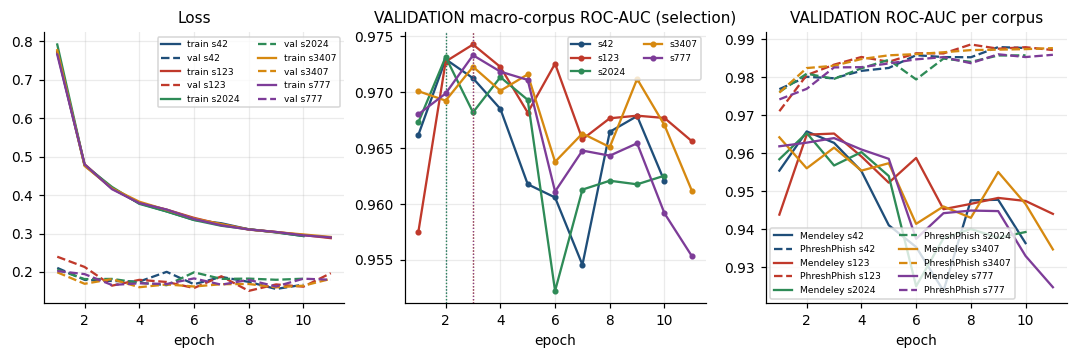

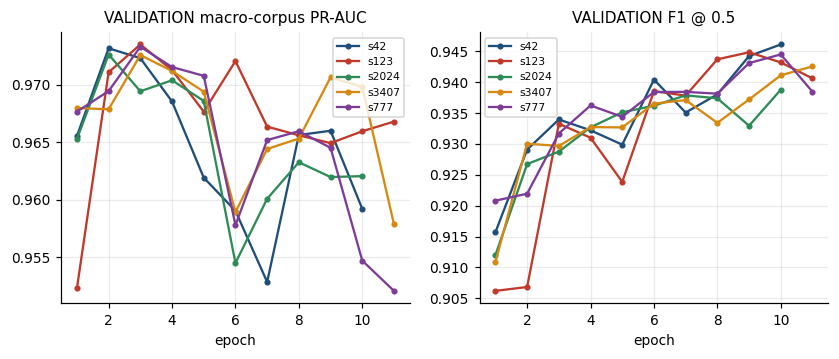

{"phase": "G2", "status": "COMPLETED", "seeds": [42, 123, 2024, 3407, 777], "best_epochs": {"42": 2, "123": 3, "2024": 2, "3407": 3, "777": 3}, "val_macro_auc_stack_P": 0.969, "models": 27}


In [15]:
# ============================================================
# CELLS 12b–13 — TRAINING (N_SEEDS seeds) + BASELINES (same conditions) + ADAPT-X STACK + VALIDATION + LOCO CHECK
# External sets are NOT opened here (they are opened once each in G3).
# v11: B4 every model through the same leave-one-corpus-out check · B5 LightGBM on view E · B6 macro-corpus metrics
#      C9 several seeds + seed ensemble · C10 temperature fitted on VALIDATION for EVERY model (fair ECE)
#      A2 representation-level corpus identifiability (probe on the fused embedding z)
# ============================================================
RUN_PSEUDO_EXTERNAL = True
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
try:
    import lightgbm as lgb
except ImportError:
    lgb = None; print("LightGBM: NOT_AVAILABLE (pip install lightgbm)")

MODEL_REG, SCORES = {}, {}        # model registry (frozen after cell 16) and cached RAW logits per (model, split)
yv, dv = PRE["val"]["label"].astype(int), PRE["val"]["ds_id"]; wv = cell_weights(dv, yv)
gv = SPLITS["val"].registrable_domain.values

def register(name, kind, logit_val, family, portable, **kw):
    """Temperature + thresholds fitted on VALIDATION only (identical rule for every model)."""
    T = fit_temperature_weighted(np.asarray(logit_val, float), yv, wv)
    thr = thresholds_from_val(yv, sigmoid(np.asarray(logit_val) / T), dv)
    MODEL_REG[name] = dict(kind=kind, family=family, portable=portable, T=T, thresholds=thr, **kw)
    SCORES[(name, "val")] = np.asarray(logit_val, float)
    return MODEL_REG[name]

def raw_logit(name, split, rows=None):
    """RAW (uncalibrated) logit of a registered model on a split; cached for full splits."""
    key = (name, split)
    if rows is None and key in SCORES: return SCORES[key]
    M = MODEL_REG[name]; k = M["kind"]
    if k == "adapt" and M["view"] == "E" and not any(DS_FEAT_COLS[c][IS_NATIVE].any() for c in pd.unique(PRE[split]["dataset"])):
        out = raw_logit(name.replace("(E)", "(P)"), split, rows)       # no native schema in this split: view E ≡ view P (identical input)
    elif k == "adapt":
        out = predict(M["obj"], split, rows=rows, view=M["view"], cfg=M.get("cfg"))["logit"]
    elif k == "ens":
        # v13: mean of the RAW member logits; ONE temperature is fitted on the ensemble (register). In v12 each member was
        # divided by its own view-specific temperature before averaging, so the P and E ensembles weighted the same member
        # logits differently and their rankings differed slightly on corpora without native features (Table 8).
        out = np.mean([raw_logit(b, split, rows) for b in M["members"]], 0)
    elif k == "lgbm":
        X = SPLITS[split].reindex(columns=M["cols"]).to_numpy(np.float32); X = X if rows is None else X[rows]   # absent schema -> NaN (LightGBM missing branch)
        out = M["obj"].predict(X, raw_score=True)
    elif k == "lr":
        u = SPLITS[split].url.values; u = u if rows is None else u[rows]
        out = M["obj"].decision_function(M["vec"].transform(u))
    elif k == "stack":
        out = M["obj"].decision_function(np.column_stack([raw_logit(b, split, rows) / MODEL_REG[b]["T"] for b in M["bases"]]))
    else:
        raise ValueError(k)
    out = np.asarray(out, float)
    if rows is None: SCORES[key] = out
    return out
def prob(name, split, rows=None): return sigmoid(raw_logit(name, split, rows) / MODEL_REG[name]["T"])

# ---------------- 1. ADAPT-PHISH, N_SEEDS seeds ----------------
t0 = time.perf_counter(); ADAPT = {}
for s in MODEL_SEEDS:
    m_, info_ = train_run("main", {}, s); ADAPT[s] = (m_, info_)
    for view in ["P", "E"]:
        register(f"ADAPT-PHISH ({view}) s{s}", "adapt", predict(m_, "val", view=view)["logit"], "ADAPT-PHISH", view == "P",
                 view=view, seed=s, obj=m_, cfg=info_["cfg"])
G2_SECONDS = time.perf_counter() - t0
MAIN_MODEL, MAIN_INFO = ADAPT[MODEL_SEEDS[0]]
# v14: a reused v13 run must reproduce the v13 VALIDATION numbers exactly (same data, split, preprocessing and code path)
_v13_val = V14["v13_dir"] / "reports" / "validation_results.csv"
if any(r.startswith("main/") for r in V14_REUSED):
    if not _v13_val.exists():
        raise GateFailure(f"v13 checkpoints were reused but {_v13_val} is missing: set ADAPT_PHISH_V14_REUSE_V13=0 or ADAPT_PHISH_V13_DIR")
    _ref = pd.read_csv(_v13_val)
    for s in MODEL_SEEDS:
        nm = f"ADAPT-PHISH (P) s{s}"
        r_ = _ref[(_ref.model == nm) & (_ref.corpus == "ALL (pooled)")]
        if len(r_) and f"main/seed_{s}" in V14_REUSED:
            now = roc_auc_score(yv, sigmoid(SCORES[(nm, "val")]))
            integrity(f"v14 reuse: {nm} reproduces the v13 VALIDATION ROC-AUC", abs(now - float(r_.roc_auc.iloc[0])) < 1e-6,
                      f"v13 {float(r_.roc_auc.iloc[0]):.6f} vs now {now:.6f} (if this fails: ADAPT_PHISH_V14_REUSE_V13=0)")
for view in ["P", "E"]:
    mem = [f"ADAPT-PHISH ({view}) s{s}" for s in MODEL_SEEDS]
    lv = np.mean([SCORES[(b, "val")] for b in mem], 0)          # v13: raw-logit mean (see raw_logit, kind "ens")
    register(f"ADAPT-PHISH ({view}) seed-ens", "ens", lv, "ADAPT-PHISH", view == "P", members=mem, view=view)

# ---------------- 2. LightGBM on view P and on view E (fix B5), cell-weighted, same seeds ----------------
def fit_lgbm(cols, tr_rows, va_rows, seed):
    Xtr = SPLITS["train"][cols].to_numpy(np.float32)[tr_rows]; ytr = PRE["train"]["label"][tr_rows]
    Xva = SPLITS["val"][cols].to_numpy(np.float32)[va_rows]; yva = PRE["val"]["label"][va_rows]
    g = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, reg_lambda=1.0, random_state=seed, n_jobs=-1, verbose=-1)
    g.fit(Xtr, ytr, sample_weight=cell_weights(PRE["train"]["ds_id"][tr_rows], ytr), eval_set=[(Xva, yva)],
          eval_sample_weight=[cell_weights(PRE["val"]["ds_id"][va_rows], yva)], callbacks=[lgb.early_stopping(100, verbose=False)])
    return g
ALL_TR, ALL_VA = np.arange(len(PRE["train"]["label"])), np.arange(len(yv))
if lgb is not None:
    for view, cols in [("P", P_COLS), ("E", E_COLS)]:
        mem = []
        for s in MODEL_SEEDS:
            g_ = fit_lgbm(cols, ALL_TR, ALL_VA, s); nm = f"LightGBM ({view}) s{s}"; mem.append(nm)
            register(nm, "lgbm", g_.predict(SPLITS["val"][cols].to_numpy(np.float32), raw_score=True), "LightGBM", view == "P",
                     obj=g_, cols=cols, view=view, seed=s)
        lv = np.mean([SCORES[(b, "val")] for b in mem], 0)      # v13: raw-logit mean
        register(f"LightGBM ({view}) seed-ens", "ens", lv, "LightGBM", view == "P", members=mem, view=view)

# ---------------- 3. char 3–5-gram TF-IDF + logistic regression on the normalized URL (portable) ----------------
def fit_char_lr(tr_rows):
    vec = TfidfVectorizer(analyzer="char", ngram_range=(3, 5), min_df=2, max_features=300_000, sublinear_tf=True, dtype=np.float32)
    X = vec.fit_transform(SPLITS["train"].url.values[tr_rows]); y_ = PRE["train"]["label"][tr_rows]
    lr_ = LogisticRegression(max_iter=3000, C=4.0, solver="liblinear").fit(X, y_, sample_weight=cell_weights(PRE["train"]["ds_id"][tr_rows], y_))
    return vec, lr_
vec_, lr_ = fit_char_lr(ALL_TR)
register("char 3-5-gram LR", "lr", lr_.decision_function(vec_.transform(SPLITS["val"].url.values)), "char-LR", True, obj=lr_, vec=vec_, view="P")

# ---------------- 4. ADAPT-X: evidence-fusion stack (meta-learner fitted on VALIDATION, out-of-fold by domain) ----------------
# Novel component of the v11 pipeline: the three complementary views of the same URL (sequence model, tree model on
# canonical features, character n-grams) are fused by a cell-weighted logistic meta-learner. VALIDATION predictions are
# OUT-OF-FOLD (GroupKFold by registrable domain), so its validation numbers are honest; the tests are never touched.
def fit_stack(bases, va_rows):
    Xm = np.column_stack([SCORES[(b, "val")][va_rows] / MODEL_REG[b]["T"] for b in bases])
    y_, ds_, g_ = yv[va_rows], dv[va_rows], gv[va_rows]; w_ = cell_weights(ds_, y_)
    oof = np.zeros(len(y_))
    for tr_i, te_i in GroupKFold(n_splits=5).split(Xm, y_, g_):
        mm = LogisticRegression(C=1.0, max_iter=2000).fit(Xm[tr_i], y_[tr_i], sample_weight=w_[tr_i]); oof[te_i] = mm.decision_function(Xm[te_i])
    meta = LogisticRegression(C=1.0, max_iter=2000).fit(Xm, y_, sample_weight=w_)
    return meta, oof
STACKS = {}
for view in ["P", "E"]:
    bases = [f"ADAPT-PHISH ({view}) seed-ens"] + ([f"LightGBM ({view}) seed-ens"] if lgb is not None else []) + ["char 3-5-gram LR"]
    meta_, oof_ = fit_stack(bases, ALL_VA)
    register(f"ADAPT-X stack ({view})", "stack", oof_, "ADAPT-X", view == "P", obj=meta_, bases=bases, view=view,
             meta_weights=dict(zip(bases, np.round(meta_.coef_[0], 4).tolist())))
    print(f"ADAPT-X ({view}) meta-learner weights:", MODEL_REG[f"ADAPT-X stack ({view})"]["meta_weights"])

# ---------------- 5. VALIDATION table: pooled + per corpus + MACRO, same threshold rule for every model ----------------
def eval_rows(name, split, y, p, ds_names, extra=None, thr_rule="val_mcc"):
    thr = MODEL_REG[name]["thresholds"][thr_rule]
    base = {"model": name, "family": MODEL_REG[name]["family"], "view": MODEL_REG[name].get("view", "P"), "split": split,
            "threshold_rule": thr_rule, **(extra or {})}
    rows = [{**base, "corpus": "ALL (pooled)", **metrics(y, p, thr)}]
    per = [{**base, "corpus": c, **metrics(y[ds_names == c], p[ds_names == c], thr)} for c in pd.unique(ds_names)]
    rows += per
    if len(per) > 1: rows.append({**base, "corpus": "MACRO (mean of corpora)", **macro_rows(pd.DataFrame(per))})
    return rows
ds_val_names = np.array(DATASETS)[dv]
VAL_ROWS = []
for name in MODEL_REG:
    VAL_ROWS += eval_rows(name, "VALIDATION", yv, prob(name, "val"), ds_val_names)
G2_TABLE = pd.DataFrame(VAL_ROWS)
G2_TABLE.to_csv(D["reports"] / "validation_results.csv", index=False)
G2_TABLE[~G2_TABLE.family.eq("ADAPT-PHISH")].to_csv(D["reports"] / "baselines.csv", index=False)
show = ["model", "corpus", "roc_auc", "pr_auc", "f1", "mcc", "recall", "fpr", "ece"]
display(G2_TABLE[G2_TABLE.corpus.isin(["MACRO (mean of corpora)"]) | G2_TABLE.model.str.contains("ens|stack|LR")][show].round(4))
# calibration before / after temperature (fix C10)
CAL_ROWS = []
for name, M in MODEL_REG.items():
    lg_ = SCORES[(name, "val")]
    CAL_ROWS.append({"model": name, "T (fitted on VALIDATION)": round(M["T"], 4), "ECE raw": ece_score(yv, sigmoid(lg_)),
                     "ECE calibrated": ece_score(yv, sigmoid(lg_ / M["T"])), "Brier raw": brier_score_loss(yv, sigmoid(lg_)),
                     "Brier calibrated": brier_score_loss(yv, sigmoid(lg_ / M["T"])),
                     "note": "stack: out-of-fold" if M["kind"] == "stack" else ""})
CAL_TABLE = pd.DataFrame(CAL_ROWS); CAL_TABLE.to_csv(D["reports"] / "calibration_validation.csv", index=False); display(CAL_TABLE.round(4))

# ---------------- 6. representation-level corpus identifiability (fix A2 target ≤ 0.6) ----------------
ben_rows = np.where(yv == 0)[0]
def embedding_identifiability(model, view, cfg=None, rows=ben_rows):
    r = predict(model, "val", rows=rows, view=view, return_z=True, cfg=cfg)
    yb = (r["ds_id"] == DS2ID["Mendeley"]).astype(int)
    if len(np.unique(yb)) < 2: return np.nan
    pr_ = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), r["z"], yb,
                            cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    return float(roc_auc_score(yb, pr_))
IDF_ROWS = [{"model": f"ADAPT-PHISH seed {s}", "view": v, "benign_corpus_identifiability_AUC (fused embedding z, VALIDATION)": embedding_identifiability(ADAPT[s][0], v)}
            for s in MODEL_SEEDS for v in ["P", "E"]]
IDF_TABLE = pd.DataFrame(IDF_ROWS); IDF_TABLE.to_csv(D["reports"] / "corpus_identifiability_representation.csv", index=False); display(IDF_TABLE.round(4))

# ---------------- 7. leave-one-development-corpus-out check — SAME conditions for every model (fix B4) ----------------
pseudo = []
if RUN_PSEUDO_EXTERNAL:
    ds_tr, ds_va = PRE["train"]["dataset"], PRE["val"]["dataset"]
    for src, tgt in [("PhreshPhish", "Mendeley"), ("Mendeley", "PhreshPhish")]:
        trr, vas, vat = np.where(ds_tr == src)[0], np.where(ds_va == src)[0], np.where(ds_va == tgt)[0]
        ys_, yt_ = yv[vas], yv[vat]
        def _add(model_name, view, lg_src, lg_tgt):
            T_ = fit_temperature_weighted(lg_src, ys_, np.ones(len(ys_)))
            th = thresholds_from_val(ys_, sigmoid(lg_src / T_), np.zeros(len(ys_), int))
            pt = sigmoid(lg_tgt / T_)
            for rule in ["val_mcc", "val_fpr@1%"]:
                mm = metrics(yt_, pt, th[rule])
                pseudo.append({"trained on": src, "evaluated on (unseen corpus, VALIDATION rows)": tgt, "model": model_name, "view": view,
                               "threshold_rule": rule + " (source VALIDATION)", **{k: mm[k] for k in
                               ["roc_auc", "pr_auc", "f1", "mcc", "recall", "fpr", "oracle_tpr@fpr=1%", "ece"]}})
            return lg_src / T_, lg_tgt / T_
        m_, i_ = train_run(f"pseudo_{src}_only", {"epochs": PSEUDO_EPOCHS, "epoch_samples": PSEUDO_EPOCH_SAMPLES}, MODEL_SEEDS[0],
                           train_rows=trr, val_rows=vas, verbose=False)
        cal = {}
        for view in ["P", "E"]:
            cal[f"ADAPT-PHISH ({view})"] = _add("ADAPT-PHISH", view, predict(m_, "val", rows=vas, view=view)["logit"], predict(m_, "val", rows=vat, view=view)["logit"])
        del m_
        if lgb is not None:
            for view, cols in [("P", P_COLS), ("E", E_COLS)]:
                g_ = fit_lgbm(cols, trr, vas, MODEL_SEEDS[0]); X_ = SPLITS["val"][cols].to_numpy(np.float32)
                cal[f"LightGBM ({view})"] = _add("LightGBM", view, g_.predict(X_[vas], raw_score=True), g_.predict(X_[vat], raw_score=True))
        v2, l2 = fit_char_lr(trr); U = SPLITS["val"].url.values
        cal["char-LR"] = _add("char 3-5-gram LR", "P", l2.decision_function(v2.transform(U[vas])), l2.decision_function(v2.transform(U[vat])))
        bases = ["ADAPT-PHISH (P)"] + (["LightGBM (P)"] if lgb is not None else []) + ["char-LR"]       # ADAPT-X (P) with a source-only meta-learner
        Xs = np.column_stack([cal[b][0] for b in bases]); Xt = np.column_stack([cal[b][1] for b in bases])
        meta = LogisticRegression(C=1.0, max_iter=2000).fit(Xs, ys_)
        _add("ADAPT-X stack", "P", meta.decision_function(Xs), meta.decision_function(Xt))
    PSEUDO = pd.DataFrame(pseudo); PSEUDO.to_csv(D["reports"] / "pseudo_external_check.csv", index=False)
    display(PSEUDO[PSEUDO.threshold_rule.str.startswith("val_mcc")].round(4))

# ---------------- 8. training / validation curves (all seeds) ----------------
HIST = pd.concat([pd.read_csv(D["checkpoints"] / "main" / f"seed_{s}" / "training_history.csv").assign(seed=s) for s in MODEL_SEEDS])
HIST.to_csv(D["tables"] / "training_history_all_seeds.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for i, s in enumerate(MODEL_SEEDS):
    h = HIST[HIST.seed == s]; c = PALETTE[i % len(PALETTE)]
    ax[0].plot(h.epoch, h.train_loss, "-", c=c, label=f"train s{s}"); ax[0].plot(h.epoch, h.val_loss, "--", c=c, label=f"val s{s}")
    ax[1].plot(h.epoch, h.val_macro_corpus_roc_auc, "-o", ms=3, c=c, label=f"s{s}")
    ax[1].axvline(ADAPT[s][1]["best_epoch"], c=c, ls=":", lw=.8)
    for j, dname in enumerate([c_ for c_ in h.columns if c_.startswith("val_auc_")]):
        ax[2].plot(h.epoch, h[dname], ["-", "--", ":"][j % 3], c=c, label=f"{dname.replace('val_auc_', '')} s{s}")
ax[0].set(title="Loss", xlabel="epoch"); ax[1].set(title="VALIDATION macro-corpus ROC-AUC (selection)", xlabel="epoch")
ax[2].set(title="VALIDATION ROC-AUC per corpus", xlabel="epoch")
for a in ax: a.legend(fontsize=6, ncol=2)
savefig(fig, "training_curves")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for i, s in enumerate(MODEL_SEEDS):
    h = HIST[HIST.seed == s]; ax[0].plot(h.epoch, h.val_macro_corpus_pr_auc, "-o", ms=3, c=PALETTE[i], label=f"s{s}")
    ax[1].plot(h.epoch, h["val_f1@0.5"], "-o", ms=3, c=PALETTE[i], label=f"s{s}")
ax[0].set(title="VALIDATION macro-corpus PR-AUC", xlabel="epoch"); ax[1].set(title="VALIDATION F1 @ 0.5", xlabel="epoch")
for a in ax: a.legend(fontsize=7)
savefig(fig, "validation_curves")

hist = HIST[HIST.seed == MODEL_SEEDS[0]]
sane = bool(np.isfinite(hist.train_loss).all() and np.isfinite(hist.val_loss).all()
            and (len(hist) < 2 or hist.train_loss.iloc[-1] < hist.train_loss.iloc[0]) and hist.val_roc_auc.max() > 0.5)
macro = G2_TABLE[G2_TABLE.corpus == "MACRO (mean of corpora)"].set_index("model")
(D["reports"] / "g2_summary.json").write_text(json.dumps({"training_curve_sane": sane, "seeds": MODEL_SEEDS,
    "best_epochs": {s: ADAPT[s][1]["best_epoch"] for s in MODEL_SEEDS},
    "val_macro_roc_auc": macro.roc_auc.round(4).to_dict(), "baselines_recorded": [n for n in MODEL_REG if MODEL_REG[n]["family"] != "ADAPT-PHISH"],
    "pseudo_external_run": RUN_PSEUDO_EXTERNAL, "wall_seconds_adapt_seeds": G2_SECONDS, "device": str(DEVICE),
    "training_profile": TRAINING_PROFILE}, indent=2, default=str))
if not sane:
    phase_status("G2", "FAILED", reason="training loss not decreasing / not finite"); raise GateFailure("G2: training curve not sane")
RUN_CONTEXT.update(model=MAIN_MODEL, model_info=MAIN_INFO, model_reg=MODEL_REG, adapt=ADAPT)
phase_status("G2", "COMPLETED" if RUN_PSEUDO_EXTERNAL and lgb is not None else "PARTIALLY_COMPLETED",
             seeds=MODEL_SEEDS, best_epochs={s: ADAPT[s][1]["best_epoch"] for s in MODEL_SEEDS},
             val_macro_auc_stack_P=round(float(macro.loc["ADAPT-X stack (P)", "roc_auc"]), 4), models=len(MODEL_REG))


## 13b — Additional baselines

In [16]:
# ============================================================
# CELL 13b — v13 REVISION BASELINES (trained, calibrated and thresholded BEFORE the freeze; identical protocol)
# Requested by reviewers 1, 4, 5, 7, 8, 9:
#   * trivial sanity baselines (url_len only, has_path only, url_len + path depth)
#   * URLNet-style character + word CNN (Le et al., 2018) and a bidirectional GRU character model
#   * LightGBM on hashed character n-grams + the canonical URL features (a tree comparator that sees the string)
#   * optional fine-tuned pretrained character model (ADAPT_PHISH_REV_PRETRAINED=1; GPU recommended)
#   * a simpler ensemble WITHOUT the neural detector (LightGBM (P) + char-LR stack)
# Same TRAIN rows, same byte-level model input (url_ids, identical truncation), same corpus-tempered sampling and per-epoch
# budget as ADAPT-PHISH, same VALIDATION selection rule (macro-corpus ROC-AUC), same temperature / threshold rules
# (register), same seeds. External sets are NOT opened here; every new model is frozen with the others in cell 16.
# ============================================================
print("=" * 52 + "\nPHASE: G2-REV (revision baselines)\nSTATUS: RUNNING\n" + "=" * 52)
import zlib as _zlib
from scipy import sparse as _sp
from sklearn.feature_extraction.text import HashingVectorizer
REV_ART = D["artifacts/frozen_model"]
REV_SEEDS = MODEL_SEEDS[:max(1, min(len(MODEL_SEEDS), REV["baseline_seeds"]))]
REV_HEADLINE, REV_ALL, REV_INFO = [], [], {}
t_rev = time.perf_counter()

# ---------------- generic dispatch for the new model kinds (the v12 kinds are untouched) ----------------
_raw_logit_v12 = raw_logit
def raw_logit(name, split, rows=None):
    """v13 wrapper: new kinds rev_* are scored here, every v12 kind goes to the v12 function (which calls this one recursively
    for ensembles and stacks, so a stack can mix old and new members)."""
    M = MODEL_REG[name]; k = M["kind"]
    if not str(k).startswith("rev_"):
        return _raw_logit_v12(name, split, rows)
    key = (name, split)
    if rows is None and key in SCORES: return SCORES[key]
    if k == "rev_triv":
        X = _triv_X(split, M["cols"]); out = M["obj"].decision_function(X if rows is None else X[rows])
    elif k == "rev_hlgbm":
        X = _hashed_X(split); out = M["obj"].predict(X if rows is None else X[np.asarray(rows)], raw_score=True)
    elif k == "rev_nn":
        out = _nn_predict(M["obj"], split, rows)
    elif k == "rev_hf":
        out = _hf_predict(M["obj"], M["tok"], split, rows)
    else:
        raise ValueError(k)
    out = np.asarray(out, float)
    if rows is None: SCORES[key] = out
    return out

def _add_ens(base, family, members):
    lv = np.mean([SCORES[(b, "val")] for b in members], 0)
    register(f"{base} seed-ens", "ens", lv, family, True, members=members, view="P")
    REV_ALL.append(f"{base} seed-ens"); REV_HEADLINE.append(f"{base} seed-ens")

# ---------------- 1. trivial sanity baselines ----------------
def _triv_X(split, cols):
    d = SPLITS[split]; out = []
    for c in cols:
        if c == "has_path": out.append((~d.is_root.values.astype(bool)).astype(np.float32))
        elif c == "path_depth_struct": out.append(d.path_depth.values.astype(np.float32))
        else: out.append(d[c].to_numpy(np.float32))
    X = np.column_stack(out); X = np.where(np.isfinite(X), X, 0.0)
    return np.log1p(np.clip(X, 0, None))
TRIVIAL = {"Sanity: url_len only (LR)": ["feat::url::url_len"], "Sanity: has_path only (LR)": ["has_path"],
           "Sanity: url_len + path depth (LR)": ["feat::url::url_len", "path_depth_struct"]}
ytr_all = PRE["train"]["label"].astype(int); wtr_all = cell_weights(PRE["train"]["ds_id"], ytr_all)
for nm, cols in TRIVIAL.items():
    lr_t = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(_triv_X("train", cols), ytr_all,
                                                                                  logisticregression__sample_weight=wtr_all)
    register(nm, "rev_triv", lr_t.decision_function(_triv_X("val", cols)), "sanity", True, obj=lr_t, cols=cols, view="P")
    REV_ALL.append(nm); REV_HEADLINE.append(nm)
print(f"sanity baselines registered ({time.perf_counter() - t_rev:.0f}s)")

# ---------------- 2. LightGBM on hashed character n-grams + canonical URL features (view P) ----------------
_HV = HashingVectorizer(analyzer="char", ngram_range=(3, 5), n_features=REV["hashed_dim"], alternate_sign=False, binary=True,
                        norm=None, lowercase=True, dtype=np.float32)
_HX = {}
def _hashed_X(split):
    if split not in _HX:
        H = _HV.transform(SPLITS[split].url.values)
        T = _sp.csr_matrix(SPLITS[split].reindex(columns=P_COLS).to_numpy(np.float32))      # NaN kept -> LightGBM missing branch
        _HX[split] = _sp.hstack([T, H], format="csr")
    return _HX[split]
if REV["hashed_lgbm"] and lgb is not None:
    mem = []
    Xh_tr, Xh_va = _hashed_X("train"), _hashed_X("val")
    for s in REV_SEEDS:
        t0 = time.perf_counter(); _hl_ck = D["checkpoints"] / "rev_hlgbm" / f"seed_{s}.pkl"     # resume: finished fit reloaded
        if _hl_ck.exists():
            with open(_hl_ck, "rb") as f: g_, _hl_sec = pickle.load(f)
            print(f"[LightGBM hashed s{s}] finished run reloaded from {_hl_ck}")
        else:
            g_ = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
                                    colsample_bytree=0.5, reg_lambda=1.0, random_state=s, n_jobs=-1, verbose=-1)
            g_.fit(Xh_tr, ytr_all, sample_weight=wtr_all, eval_set=[(Xh_va, yv)], eval_sample_weight=[cell_weights(dv, yv)],
                   callbacks=[lgb.early_stopping(100, verbose=False)])
            _hl_sec = time.perf_counter() - t0; _hl_ck.parent.mkdir(parents=True, exist_ok=True)
            with open(_hl_ck, "wb") as f: pickle.dump((g_, _hl_sec), f)
        nm = f"LightGBM (P) + hashed char n-grams s{s}"; mem.append(nm)
        register(nm, "rev_hlgbm", g_.predict(Xh_va, raw_score=True), "LightGBM+ngrams", True, obj=g_, view="P", seed=s)
        REV_ALL.append(nm); REV_INFO[nm] = {"train_seconds": _hl_sec, "trees": int(g_.booster_.num_trees())}
    _add_ens("LightGBM (P) + hashed char n-grams", "LightGBM+ngrams", mem)
    print(f"hashed-n-gram LightGBM: {len(mem)} seeds ({time.perf_counter() - t_rev:.0f}s)")

# ---------------- 3. neural string baselines on the SAME byte-level input as ADAPT-PHISH ----------------
WORD_VOCAB, WORD_LEN = 2 ** 16, 32
def _word_ids(urls):
    out = np.zeros((len(urls), WORD_LEN), np.int32)
    for i, u in enumerate(urls):
        toks = [t for t in re.split(r"[^A-Za-z0-9]+", str(u).lower()) if t][:WORD_LEN]
        for j, t in enumerate(toks): out[i, j] = 1 + _zlib.crc32(t.encode()) % (WORD_VOCAB - 1)
    return out
WORDS = {k: torch.from_numpy(_word_ids(SPLITS[k].url.values)) for k in PRE}

def _rev_batch(split, idx_np):
    t = STORE[split]; idx = torch.as_tensor(np.asarray(idx_np), dtype=torch.long, device=STORE_DEVICE)
    ul = t["url_len"][idx].long(); L = min(MAX_URL_LEN, max(8, ((int(ul.max()) + 7) // 8) * 8))
    ids = t["url_ids"][idx, :L].long().to(DEVICE); ul = ul.to(DEVICE)
    mask = torch.arange(L, device=DEVICE)[None, :] < ul[:, None]
    words = WORDS[split][torch.as_tensor(np.asarray(idx_np), dtype=torch.long)].long().to(DEVICE)
    return ids, mask, words

class URLNetStyle(nn.Module):
    """URLNet-style (Le et al., 2018): character-CNN and word-CNN branches (filter widths 3–6), max-pooled, concatenated, MLP head."""
    def __init__(self, d=32, nf=64, widths=(3, 4, 5, 6)):
        super().__init__()
        self.ce = nn.Embedding(260, d, padding_idx=0); self.cc = nn.ModuleList([nn.Conv1d(d, nf, w, padding=w // 2) for w in widths])
        self.we = nn.Embedding(WORD_VOCAB, d, padding_idx=0); self.wc = nn.ModuleList([nn.Conv1d(d, nf, w, padding=w // 2) for w in widths])
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(2 * nf * len(widths), 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 1))
    @staticmethod
    def _branch(x, mask, convs):
        h = x.transpose(1, 2); outs = []
        for c in convs:
            o = F.relu(c(h))[:, :, : mask.size(1)]
            outs.append(o.masked_fill(~mask[:, None, :], -1e4).max(2).values)
        return torch.cat(outs, 1)
    def forward(self, ids, mask, words):
        wm = words > 0; wm[:, 0] = True
        return self.head(torch.cat([self._branch(self.ce(ids), mask, self.cc), self._branch(self.we(words), wm, self.wc)], 1)).squeeze(1)

class BiGRUChar(nn.Module):
    """Bidirectional GRU over the byte sequence, mean + max pooling, MLP head."""
    def __init__(self, d=48, h=64):
        super().__init__(); self.e = nn.Embedding(260, d, padding_idx=0)
        self.rnn = nn.GRU(d, h, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(4 * h, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, ids, mask, words=None):
        lens = mask.sum(1).clamp_min(1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(self.e(ids), lens, batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed); out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=ids.size(1))
        m = mask[:, :, None]
        mean = (out * m.float()).sum(1) / m.float().sum(1).clamp_min(1); mx = out.masked_fill(~m, -1e4).max(1).values
        return self.head(torch.cat([mean, mx], 1)).squeeze(1)

@torch.inference_mode()
def _nn_predict(model, split, rows=None, bs=None):
    model.eval(); bs = bs or BATCH_SIZE * 4
    rows = np.arange(len(PRE[split]["label"])) if rows is None else np.asarray(rows); out = []
    for s in range(0, len(rows), bs):
        ids, mask, words = _rev_batch(split, rows[s:s + bs]); out.append(model(ids, mask, words).float().cpu())
    return torch.cat(out).numpy() if out else np.zeros(0)

def _selection_rows(seed):
    """Identical to train_run: fixed stratified VALIDATION subset (corpus × label) of at most VAL_SELECT_MAX rows."""
    all_val = np.arange(len(yv))
    if not (VAL_SELECT_MAX and len(all_val) > VAL_SELECT_MAX): return all_val
    key = dv * 2 + yv.astype(int)
    return np.sort(np.concatenate([np.random.default_rng(seed).choice(all_val[key == k], max(1, min(int((key == k).sum()), int(round(VAL_SELECT_MAX * (key == k).mean())))), replace=False)
                                   for k in np.unique(key)]))

def train_rev_nn(name, ctor, seed, lr=1e-3, alpha=None, epochs=None, epoch_samples=None, patience=None, wd=1e-4, ema=0.0, kd=0.0):
    """Same budget as ADAPT-PHISH: EPOCHS epochs of EPOCH_SAMPLES rows drawn with p(corpus) ∝ n^SAMPLING_ALPHA, early stopping with
    PATIENCE on macro-corpus VALIDATION ROC-AUC; cell-weighted BCE (each corpus × label cell has equal total weight)."""
    run = D["checkpoints"] / ("rev_" + re.sub(r"[^A-Za-z0-9]+", "_", name).strip("_")) / f"seed_{seed}"; run.mkdir(parents=True, exist_ok=True)
    seed_everything(seed); model = ctor().to(DEVICE); info_f = run / "info.json"
    if info_f.exists() and json.loads(info_f.read_text()).get("finished"):
        model.load_state_dict(torch.load(run / "best_model.pt", map_location=DEVICE)); model.eval(); return model, json.loads(info_f.read_text())
    alpha = SAMPLING_ALPHA if alpha is None else alpha; epochs = epochs or EPOCHS; patience = patience or PATIENCE      # v14: tunable
    tr_rows = np.arange(len(ytr_all)); p_pick = tempered_weights(PRE["train"]["dataset"], alpha)
    n_ep = int(min((epoch_samples or EPOCH_SAMPLES) or len(tr_rows), len(tr_rows) * 10)); sel = _selection_rows(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd); rng_n = np.random.default_rng(seed)
    best, best_ep, bad, hist, t_start = -1.0, 0, 0, [], time.perf_counter()
    ema_s = {k: v.detach().clone() for k, v in model.state_dict().items()} if ema else None        # v14: same EMA option as ADAPT-PHISH
    for ep in range(epochs):
        if bad >= patience: break
        check_deadline(f"{name} seed {seed} epoch {ep + 1}")
        model.train(); t0 = time.perf_counter(); tot = 0.0
        order = rng_n.choice(tr_rows, n_ep, replace=True, p=p_pick) if alpha != 1.0 else rng_n.permutation(tr_rows)[:n_ep]
        for s in range(0, len(order), BATCH_SIZE):
            idx = order[s:s + BATCH_SIZE]; ids, mask, words = _rev_batch("train", idx)
            y_ = torch.as_tensor(ytr_all[idx], dtype=torch.float32, device=DEVICE); w_ = torch.as_tensor(wtr_all[idx], dtype=torch.float32, device=DEVICE)
            lo_ = model(ids, mask, words)
            loss = (F.binary_cross_entropy_with_logits(lo_, y_, reduction="none") * w_).sum() / w_.sum()
            if kd > 0 and "teacher" in PRE["train"]:                 # v14 distillation control (same rule as ADAPT-PHISH v2-KD)
                tq = torch.as_tensor(PRE["train"]["teacher"][idx], dtype=torch.float32, device=DEVICE)
                loss = (1 - kd) * loss + kd * F.binary_cross_entropy_with_logits(lo_, tq)
            opt.zero_grad(set_to_none=True); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            if ema_s is not None: ema_update(ema_s, model, ema)
            tot += float(loss.detach()) * len(idx)
        with ema_weights(model, ema_s):
            pv = sigmoid(_nn_predict(model, "val", sel))
        sel_auc = macro_corpus_roc_auc(yv[sel], pv, dv[sel]); score = sel_auc + 1e-3 * macro_corpus_pr_auc(yv[sel], pv, dv[sel])
        hist.append({"epoch": ep + 1, "train_loss": tot / max(1, len(order)), "val_macro_corpus_roc_auc": sel_auc, "epoch_seconds": time.perf_counter() - t0})
        if score > best:
            best, best_ep, bad = score, ep + 1, 0; torch.save(ema_s if ema_s is not None else model.state_dict(), run / "best_model.pt")
        else:
            bad += 1
        print(f"[{name} s{seed}] ep {ep + 1:02d} | loss {hist[-1]['train_loss']:.4f} | val macro-corpus AUC {sel_auc:.4f}{' ★' if bad == 0 else ''}", flush=True)
    pd.DataFrame(hist).to_csv(run / "training_history.csv", index=False)
    model.load_state_dict(torch.load(run / "best_model.pt", map_location=DEVICE)); model.eval()
    info = {"name": name, "seed": seed, "best_epoch": best_ep, "best_val_selection": best, "epochs_run": len(hist),
            "train_seconds": float(time.perf_counter() - t_start), "parameters": int(sum(p.numel() for p in model.parameters())),
            "budget": {"epochs": epochs, "patience": patience, "epoch_samples": n_ep, "batch": BATCH_SIZE, "alpha": alpha, "lr": lr, "wd": wd, "ema": ema, "kd": kd}, "finished": True}
    info_f.write_text(json.dumps(info, indent=2)); return model, info

if REV["neural_baselines"]:
    for base, ctor, fam in [("URLNet-style char+word CNN", URLNetStyle, "URLNet-style"), ("BiGRU character model", BiGRUChar, "BiGRU")]:
        mem = []
        for s in REV_SEEDS:
            m_, i_ = train_rev_nn(base, ctor, s); nm = f"{base} s{s}"; mem.append(nm)
            register(nm, "rev_nn", _nn_predict(m_, "val"), fam, True, obj=m_, view="P", seed=s)
            torch.save(m_.state_dict(), REV_ART / f"rev_{re.sub(r'[^A-Za-z0-9]+', '_', base).strip('_')}_seed_{s}.pt")
            REV_ALL.append(nm); REV_INFO[nm] = i_
        _add_ens(base, fam, mem)
        print(f"{base}: {len(mem)} seeds ({time.perf_counter() - t_rev:.0f}s)")

# ---------------- 4. fine-tuned pretrained models (v14: CANINE-s character model + a URLTran-style small BERT) ----------------
# URLTran (Maneriker et al., 2021) fine-tunes a BERT model on URL strings; on CPU we use the 4-layer, 256-dim BERT of Turc et al.
# (google/bert_uncased_L-4_H-256_A-4, ~11 M parameters) with its WordPiece tokenizer. Same rows, cell weights, corpus-tempered
# sampling and VALIDATION selection as every other model; reduced CPU budget, one seed (disclosed). Resumable per epoch.
REV_PRETRAINED_STATUS = "NOT_RUN (ADAPT_PHISH_REV_PRETRAINED=0)"; PRETRAINED_NAMES = []
if REV["pretrained"]:
    PT_LIST = [x.strip() for x in os.environ.get("ADAPT_PHISH_REV_PRETRAINED_NAMES",
                                                 f"{REV['pretrained_name']},google/bert_uncased_L-4_H-256_A-4").split(",") if x.strip()]
    PT_LR = {"google/canine-s": 2e-5}                     # other (smaller) models: 5e-5
    _status = {}
    try:
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
    except Exception as ex:
        _status = {n: f"FAILED: {ex!r}"[:200] for n in PT_LIST}; PT_LIST = []
    def _hf_predict(model, tok, split, rows=None, bs=128):
        model.eval(); u = SPLITS[split].url.values; u = u if rows is None else u[np.asarray(rows)]; out = []
        with torch.inference_mode():
            for s0 in range(0, len(u), bs):
                enc = tok(list(u[s0:s0 + bs]), truncation=True, max_length=REV["pretrained_maxlen"], padding=True, return_tensors="pt").to(DEVICE)
                out.append(model(**enc).logits[:, 0].float().cpu())
        return torch.cat(out).numpy() if out else np.zeros(0)
    for pname in PT_LIST:
        try:
            _tok = AutoTokenizer.from_pretrained(pname)
            s = REV_SEEDS[0]; seed_everything(s)
            hfm = AutoModelForSequenceClassification.from_pretrained(pname, num_labels=1).to(DEVICE)
            lr_h = PT_LR.get(pname, 5e-5)
            opt_h = torch.optim.AdamW(hfm.parameters(), lr=lr_h, weight_decay=0.01); sel = _selection_rows(s); best, best_state = -1, None
            p_pick = tempered_weights(PRE["train"]["dataset"], SAMPLING_ALPHA); U_tr = SPLITS["train"].url.values
            n_ep = int(min(REV["pretrained_samples"] or EPOCH_SAMPLES or len(U_tr), len(U_tr))); t0 = time.perf_counter()
            print(f"[pretrained {pname}] {REV['pretrained_epochs']} epochs x {n_ep} rows, max_length {REV['pretrained_maxlen']}, lr {lr_h}, seed {s}", flush=True)
            _hf_ck = D["checkpoints"] / ("rev_pretrained" if pname == "google/canine-s" else "rev_pretrained_" + re.sub(r"[^A-Za-z0-9]+", "_", pname)) / f"seed_{s}"
            _hf_ck.mkdir(parents=True, exist_ok=True)
            _done = json.loads((_hf_ck / "info.json").read_text()) if (_hf_ck / "info.json").exists() else {}
            _ep0 = int(_done.get("epochs_done", 0)); best = float(_done.get("best", -1))
            if _ep0 > 0 and (_hf_ck / "last.pt").exists():
                hfm.load_state_dict(torch.load(_hf_ck / "last.pt", map_location=DEVICE)); best_state = torch.load(_hf_ck / "best.pt", map_location="cpu")
                print(f"[pretrained {pname}] resumed after epoch {_ep0} (best {best:.4f})", flush=True)
            for ep in range(_ep0, REV["pretrained_epochs"]):
                check_deadline(f"pretrained {pname} epoch {ep + 1}")
                hfm.train(); order = np.random.default_rng(s * 1000 + ep).choice(len(U_tr), n_ep, replace=True, p=p_pick); t_ep = time.perf_counter()
                for b0 in range(0, n_ep, 32):
                    if b0 == 32 * 20: print(f"[pretrained {pname}] 20 batches in {time.perf_counter() - t_ep:.0f}s -> epoch ETA ~{(time.perf_counter() - t_ep) * n_ep / 640 / 60:.0f} min", flush=True)
                    idx = order[b0:b0 + 32]
                    enc = _tok(list(U_tr[idx]), truncation=True, max_length=REV["pretrained_maxlen"], padding=True, return_tensors="pt").to(DEVICE)
                    y_ = torch.as_tensor(ytr_all[idx], dtype=torch.float32, device=DEVICE); w_ = torch.as_tensor(wtr_all[idx], dtype=torch.float32, device=DEVICE)
                    loss = (F.binary_cross_entropy_with_logits(hfm(**enc).logits[:, 0], y_, reduction="none") * w_).sum() / w_.sum()
                    opt_h.zero_grad(set_to_none=True); loss.backward(); torch.nn.utils.clip_grad_norm_(hfm.parameters(), 1.0); opt_h.step()
                pv = sigmoid(_hf_predict(hfm, _tok, "val", sel)); sc = macro_corpus_roc_auc(yv[sel], pv, dv[sel])
                print(f"[pretrained {pname}] epoch {ep + 1}: val macro-corpus AUC {sc:.4f}", flush=True)
                if sc > best: best, best_state = sc, {k: v.detach().cpu().clone() for k, v in hfm.state_dict().items()}
                torch.save(best_state, _hf_ck / "best.pt"); torch.save(hfm.state_dict(), _hf_ck / "last.pt")
                (_hf_ck / "info.json").write_text(json.dumps({"epochs_done": ep + 1, "best": best,
                                                             "train_seconds": float(_done.get("train_seconds", 0)) + time.perf_counter() - t0}))
            hfm.load_state_dict(best_state); hfm.eval()
            nm = f"Pretrained {pname} (fine-tuned)"
            register(nm, "rev_hf", _hf_predict(hfm, _tok, "val"), "pretrained", True, obj=hfm, tok=_tok, view="P", seed=s)
            torch.save(hfm.state_dict(), REV_ART / f"rev_pretrained_{re.sub(r'[^A-Za-z0-9]+', '_', pname)}.pt")
            REV_ALL.append(nm); REV_HEADLINE.append(nm); PRETRAINED_NAMES.append(nm)
            REV_INFO[nm] = {"train_seconds": json.loads((_hf_ck / "info.json").read_text())["train_seconds"],
                            "parameters": int(sum(p.numel() for p in hfm.parameters())), "max_length": REV["pretrained_maxlen"],
                            "epochs": REV["pretrained_epochs"], "rows_per_epoch": n_ep, "lr": lr_h, "seed": s}
            _status[pname] = "COMPLETED"
        except SessionDeadline:
            raise
        except Exception as ex:
            _status[pname] = f"FAILED: {ex!r}"[:300]; print(f"pretrained baseline {pname}:", _status[pname])
    REV_PRETRAINED_STATUS = "; ".join(f"{k}: {v}" for k, v in _status.items())

# ---------------- 5. simpler ensemble without the neural detector (reviewers 2, 9) ----------------
if "LightGBM (P) seed-ens" in MODEL_REG:
    bases_s = ["LightGBM (P) seed-ens", "char 3-5-gram LR"]
    meta_s, oof_s = fit_stack(bases_s, ALL_VA)
    register("Simple stack (P): LightGBM + char-LR, no neural", "stack", oof_s, "simple-stack", True, obj=meta_s, bases=bases_s, view="P",
             meta_weights=dict(zip(bases_s, np.round(meta_s.coef_[0], 4).tolist())))
    REV_ALL.append("Simple stack (P): LightGBM + char-LR, no neural"); REV_HEADLINE.append("Simple stack (P): LightGBM + char-LR, no neural")

# ---------------- 6. VALIDATION rows (same table as every other model) + frozen artefacts of the new models ----------------
G2_TABLE = pd.concat([G2_TABLE, pd.DataFrame(sum([eval_rows(n, "VALIDATION", yv, prob(n, "val"), ds_val_names) for n in REV_ALL], []))], ignore_index=True)
G2_TABLE.to_csv(D["reports"] / "validation_results.csv", index=False)
G2_TABLE[~G2_TABLE.family.eq("ADAPT-PHISH")].to_csv(D["reports"] / "baselines.csv", index=False)
with open(REV_ART / "rev_baselines.pkl", "wb") as f:
    pickle.dump({n: {k: v for k, v in MODEL_REG[n].items() if k not in ("obj", "tok") or MODEL_REG[n]["kind"] in ("rev_triv", "rev_hlgbm", "stack")}
                 for n in REV_ALL if MODEL_REG[n]["kind"] != "rev_nn" and MODEL_REG[n]["kind"] != "rev_hf"}, f)
(REV_ART / "rev_models.json").write_text(json.dumps({"headline": REV_HEADLINE, "all": REV_ALL, "seeds": REV_SEEDS, "info": REV_INFO,
                                                     "pretrained": REV_PRETRAINED_STATUS, "hashed_dim": REV["hashed_dim"]}, indent=2, default=str))
show_rev = G2_TABLE[G2_TABLE.model.isin(REV_HEADLINE) & (G2_TABLE.corpus == "MACRO (mean of corpora)")][["model", "roc_auc", "pr_auc", "f1", "mcc", "fpr", "ece"]]
display(show_rev.round(4))
phase_status("G2_REV_BASELINES", "COMPLETED", models=len(REV_ALL), headline=REV_HEADLINE, seeds=REV_SEEDS, pretrained=REV_PRETRAINED_STATUS,
             seconds=round(time.perf_counter() - t_rev, 1))

PHASE: G2-REV (revision baselines)
STATUS: RUNNING
sanity baselines registered (7s)
[LightGBM hashed s42] finished run reloaded from D:\KHAYATI 2026\adapt_phish_v15_gpu_results\checkpoints\rev_hlgbm\seed_42.pkl
[LightGBM hashed s123] finished run reloaded from D:\KHAYATI 2026\adapt_phish_v15_gpu_results\checkpoints\rev_hlgbm\seed_123.pkl
[LightGBM hashed s2024] finished run reloaded from D:\KHAYATI 2026\adapt_phish_v15_gpu_results\checkpoints\rev_hlgbm\seed_2024.pkl
[LightGBM hashed s3407] finished run reloaded from D:\KHAYATI 2026\adapt_phish_v15_gpu_results\checkpoints\rev_hlgbm\seed_3407.pkl
[LightGBM hashed s777] finished run reloaded from D:\KHAYATI 2026\adapt_phish_v15_gpu_results\checkpoints\rev_hlgbm\seed_777.pkl
hashed-n-gram LightGBM: 5 seeds (64s)
URLNet-style char+word CNN: 5 seeds (92s)
BiGRU character model: 5 seeds (115s)


config.json:   0%|          | 0.00/670 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/854 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/657 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  528MB            

model.safetensors: downloading bytes:           |  0.00B            

... (10 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 45.1MB            

model.safetensors: downloading bytes:           |  0.00B            

,model,roc_auc,pr_auc,f1,mcc,fpr,ece
111,Sanity: url_len only (LR),0.4941,0.5262,0.1368,0.1303,0.0133,0.0838
115,Sanity: has_path only (LR),0.5590,0.5649,0.4514,0.1328,0.2487,0.1768
119,Sanity: url_len + path depth (LR),0.6106,0.6298,0.3820,0.2284,0.0872,0.1411
143,LightGBM (P) + hashed char n-grams seed-ens,0.9711,0.9690,0.9130,0.8349,0.0651,0.0173
167,URLNet-style char+word CNN seed-ens,0.9563,0.9523,0.8876,0.7883,0.0827,0.0207
191,BiGRU character model seed-ens,0.9698,0.9694,0.9109,0.8297,0.0721,0.0223
195,Pretrained google/canine-s (fine-tuned),0.9570,0.9589,0.8888,0.7861,0.0959,0.0538
199,Pretrained google/bert_uncased_L-4_H-256_A-4 (...,0.9688,0.9666,0.9082,0.8265,0.0677,0.0375
203,"Simple stack (P): LightGBM + char-LR, no neural",0.9649,0.9597,0.9085,0.8202,0.0992,0.0294


{"phase": "G2_REV_BASELINES", "status": "COMPLETED", "models": 24, "headline": ["Sanity: url_len only (LR)", "Sanity: has_path only (LR)", "Sanity: url_len + path depth (LR)", "LightGBM (P) + hashed char n-grams seed-ens", "URLNet-style char+word CNN seed-ens", "BiGRU character model seed-ens", "Pretrained google/canine-s (fine-tuned)", "Pretrained google/bert_uncased_L-4_H-256_A-4 (fine-tuned)", "Simple stack (P): LightGBM + char-LR, no neural"], "seeds": [42, 123, 2024, 3407, 777], "pretrained": "google/canine-s: COMPLETED; google/bert_uncased_L-4_H-256_A-4: COMPLETED", "seconds": 393.4}


## 13c — Equal-budget tuning round (ADAPT-Net v2, ADAPT-X2)

In [17]:

# ============================================================
# CELL 13c — v14 IMPROVEMENT ROUND (pre-freeze, VALIDATION only, equal tuning budget for every family)
# Post hoc with respect to the v13 results, and disclosed as such. Rules fixed before the run (cell 00, V14):
#   * every family gets V14["tune_trials"] random-search trials; trial 0 is its v13 default configuration;
#   * neural trials share one short budget (tune_epochs x tune_epoch_samples rows); tree / linear trials are full fits;
#   * ONE criterion for every family: worst development-corpus ROC-AUC on VALIDATION (tie-break: macro PR-AUC);
#   * the selected configuration of every family is re-trained with the v13 budget on the same 5 seeds;
#   * ADAPT-PHISH v2 = ADAPT-PHISH + optional recurrent (BiGRU) branch in the URL encoder, chosen by the search like any
#     other hyper-parameter (url_rnn = none | patch | byte);
#   * ADAPT-X2 = cell-weighted logistic stack of ADAPT-PHISH v2 and the tuned string baselines, out-of-fold by registrable
#     domain; the SAME stack without ADAPT-PHISH v2 ("Baseline stack") is the control for its added value;
#   * external sets are not opened here; every model below is frozen with the others in cell 16.
# ============================================================
print("=" * 52 + "\nPHASE: G2-V14 (tuning + ADAPT-PHISH v2 + ADAPT-X2)\nSTATUS: RUNNING\n" + "=" * 52)
V14_HEADLINE, V14_ALL, V14_INFO, V14_BEST, V14_TRIALS = [], [], {}, {}, []
HEADLINE_V13 = ["ADAPT-X stack (P)", "ADAPT-PHISH (P) seed-ens", "LightGBM (P) seed-ens", "char 3-5-gram LR",
                "ADAPT-X stack (E)", "ADAPT-PHISH (E) seed-ens", "LightGBM (E) seed-ens"]
if V14["enabled"]:
    TUNE_DIR = D["reports"] / "v14_tuning"; TUNE_DIR.mkdir(parents=True, exist_ok=True)
    t_v14 = time.perf_counter()
    NT, TS = V14["tune_trials"], V14["tune_seed"]
    # v14.2: with the 'full' profile (GPU) the tuning budget is larger — still IDENTICAL for every family — unless set explicitly
    FULLP = TRAINING_PROFILE == "full"
    if FULLP:
        if "ADAPT_PHISH_V14_TUNE_TRIALS" not in os.environ: NT = 16
        if "ADAPT_PHISH_V14_TUNE_EPOCHS" not in os.environ: V14["tune_epochs"] = 8
        if "ADAPT_PHISH_V14_TUNE_EPOCH_SAMPLES" not in os.environ: V14["tune_epoch_samples"] = 120_000
    print(f"v14 tuning budget: {NT} trials per family | neural trials {V14['tune_epochs']} epochs x {V14['tune_epoch_samples']} rows | profile {TRAINING_PROFILE}")

    def v14_score(logit, rows=None):
        """Pre-specified selection criterion (identical for every family): worst development-corpus ROC-AUC on VALIDATION."""
        y_, d_ = (yv, dv) if rows is None else (yv[rows], dv[rows]); lg = np.asarray(logit, float)
        cs = [d for d in np.unique(d_) if len(np.unique(y_[d_ == d])) > 1]
        auc = {DATASETS[d]: roc_auc_score(y_[d_ == d], lg[d_ == d]) for d in cs}
        pr = [average_precision_score(y_[d_ == d], lg[d_ == d]) for d in cs]
        return {"worst_corpus_roc_auc": min(auc.values()), "macro_roc_auc": float(np.mean(list(auc.values()))),
                "macro_pr_auc": float(np.mean(pr)), **{f"roc_auc_{k}": v for k, v in auc.items()},
                "score": min(auc.values()) + 1e-3 * float(np.mean(pr))}

    def sample_space(space, default, n, seed):
        """trial 0 = v13 default; trials 1..n-1 = distinct random draws from the grid (fixed seed, logged)."""
        r_ = np.random.default_rng(seed); out, seen = [dict(default)], {json.dumps(default, sort_keys=True, default=str)}
        tries = 0
        while len(out) < n and tries < 10_000:
            tries += 1
            c = {k: v[int(r_.integers(len(v)))] for k, v in space.items()}
            key = json.dumps(c, sort_keys=True, default=str)
            if key not in seen: seen.add(key); out.append(c)
        return out

    def run_trials(family, configs, fit_fn):
        """fit_fn(cfg, trial_no) -> (validation logits, seconds, extra). Results are cached per trial (resumable)."""
        res = []
        for i, c in enumerate(configs):
            f_ = TUNE_DIR / f"{re.sub(r'[^A-Za-z0-9]+', '_', family)}_trial{i:02d}.json"
            if f_.exists():
                r = json.loads(f_.read_text())
            else:
                check_deadline(f"{family} trial {i}"); t0 = time.perf_counter(); lg, extra = fit_fn(c, i)
                r = {"family": family, "trial": i, "is_v13_default": i == 0, "config": c, **v14_score(lg),
                     "seconds": time.perf_counter() - t0, **(extra or {})}
                f_.write_text(json.dumps(r, indent=1, default=str))
            print(f"  [{family}] trial {i:02d}: worst-corpus AUC {r['worst_corpus_roc_auc']:.4f} | macro {r['macro_roc_auc']:.4f} "
                  f"| {r['seconds']:.0f}s | {r['config']}", flush=True)
            res.append(r); V14_TRIALS.append({k: (json.dumps(v, default=str) if k == "config" else v) for k, v in r.items()})
        best = max(res, key=lambda r: r["score"])
        V14_BEST[family] = {"trial": best["trial"], "config": best["config"], "score": best["score"],
                            "worst_corpus_roc_auc": best["worst_corpus_roc_auc"], "default_score": res[0]["score"]}
        print(f"  [{family}] SELECTED trial {best['trial']} -> {best['config']}", flush=True)
        pd.DataFrame(V14_TRIALS).to_csv(D["reports"] / "v14_tuning_trials.csv", index=False)
        (D["reports"] / "v14_best_configs.json").write_text(json.dumps(V14_BEST, indent=2, default=str))
        return best["config"]

    SHORT_NN = {"epochs": V14["tune_epochs"], "epoch_samples": V14["tune_epoch_samples"], "patience": V14["tune_epochs"]}

    # ---------------- 1. ADAPT-PHISH v2 ----------------
    ADAPT_DEFAULT = {"url_rnn": "none", "d": D_MODEL, "url_layers": URL_LAYERS, "lr": LEARNING_RATE, "dann_weight": DANN_WEIGHT,
                     "native_drop": NATIVE_TOKEN_DROPOUT, "alpha": SAMPLING_ALPHA, "md_p": MODALITY_DROPOUT, "dro": GROUP_DRO, "wd": WEIGHT_DECAY, "ema": 0.0}
    ADAPT_SPACE = {"url_rnn": ["none", "patch", "byte"], "d": [96, 128, 192] if FULLP else [64, 96], "url_layers": [2, 3, 4] if FULLP else [1, 2, 3], "lr": [3e-4, 5e-4, 1e-3],
                   "dann_weight": [0.0, 0.1, 0.3], "native_drop": [0.3, 0.5, 0.7], "alpha": [0.3, 0.5, 1.0], "md_p": [0.1, 0.2, 0.3],
                   "dro": [True, False], "wd": [1e-4, 1e-3], "ema": [0.0, 0.99, 0.998]}
    def _fit_adapt(c, i):
        m_, i_ = train_run(f"v14tune_adapt_t{i:02d}", {**c, **SHORT_NN}, TS, verbose=False)
        lg = predict(m_, "val", view="P", cfg=i_["cfg"])["logit"]; n_par = int(sum(p.numel() for p in m_.parameters())); del m_
        import gc; gc.collect(); torch.cuda.empty_cache()     # free GPU memory between tuning trials
        return lg, {"parameters": n_par, "best_epoch": i_["best_epoch"], "train_seconds": i_["train_seconds"]}
    V2_CFG = run_trials("ADAPT-PHISH v2", sample_space(ADAPT_SPACE, ADAPT_DEFAULT, NT, TS), _fit_adapt)

    # ---------------- 2. neural string baselines (BiGRU, URLNet-style) ----------------
    BIGRU_DEFAULT = {"d": 48, "h": 64, "lr": 1e-3, "alpha": SAMPLING_ALPHA, "wd": 1e-4, "ema": 0.0}
    BIGRU_SPACE = {"d": [48, 64, 96] if FULLP else [32, 48, 64], "h": [64, 96, 128] if FULLP else [48, 64, 96], "lr": [5e-4, 1e-3, 2e-3], "alpha": [0.3, 0.5, 1.0], "wd": [1e-4, 1e-3], "ema": [0.0, 0.99, 0.998]}
    URLNET_DEFAULT = {"d": 32, "nf": 64, "lr": 1e-3, "alpha": SAMPLING_ALPHA, "wd": 1e-4, "ema": 0.0}
    URLNET_SPACE = {"d": [32, 48, 64] if FULLP else [16, 32, 48], "nf": [64, 128, 256] if FULLP else [32, 64, 128], "lr": [5e-4, 1e-3, 2e-3], "alpha": [0.3, 0.5, 1.0], "wd": [1e-4, 1e-3], "ema": [0.0, 0.99, 0.998]}
    def _ctor(kind, c):
        return (lambda: BiGRUChar(d=c["d"], h=c["h"])) if kind == "BiGRU" else (lambda: URLNetStyle(d=c["d"], nf=c["nf"]))
    def _fit_nn(kind):
        def f(c, i):
            m_, i_ = train_rev_nn(f"v14tune {kind} t{i:02d}", _ctor(kind, c), TS, lr=c["lr"], alpha=c["alpha"], wd=c["wd"], ema=c.get("ema", 0.0),
                                  epochs=SHORT_NN["epochs"], epoch_samples=SHORT_NN["epoch_samples"], patience=SHORT_NN["patience"])
            lg = _nn_predict(m_, "val"); del m_
            import gc; gc.collect(); torch.cuda.empty_cache()     # free GPU memory between tuning trials
            return lg, {"parameters": i_["parameters"], "best_epoch": i_["best_epoch"], "train_seconds": i_["train_seconds"]}
        return f
    BIGRU_CFG = run_trials("BiGRU", sample_space(BIGRU_SPACE, BIGRU_DEFAULT, NT, TS + 1), _fit_nn("BiGRU"))
    URLNET_CFG = run_trials("URLNet-style", sample_space(URLNET_SPACE, URLNET_DEFAULT, NT, TS + 2), _fit_nn("URLNet"))

    # ---------------- 3. LightGBM (P) and LightGBM + hashed n-grams ----------------
    LGB_DEFAULT = {"num_leaves": 63, "learning_rate": 0.05, "min_child_samples": 40, "colsample_bytree": 0.8, "reg_lambda": 1.0, "subsample": 0.8}
    LGB_SPACE = {"num_leaves": [15, 31, 63, 127], "learning_rate": [0.02, 0.05, 0.1], "min_child_samples": [20, 40, 100, 200],
                 "colsample_bytree": [0.3, 0.5, 0.8, 1.0], "reg_lambda": [0.0, 1.0, 5.0], "subsample": [0.7, 0.8, 1.0]}
    def _lgb(c, seed):
        return lgb.LGBMClassifier(n_estimators=3000, subsample_freq=1, random_state=seed, n_jobs=-1, verbose=-1, **c)
    def _fit_lgb_P(c, seed=TS):
        g_ = _lgb(c, seed); Xtr = SPLITS["train"][P_COLS].to_numpy(np.float32); Xva = SPLITS["val"][P_COLS].to_numpy(np.float32)
        g_.fit(Xtr, ytr_all, sample_weight=wtr_all, eval_set=[(Xva, yv)], eval_sample_weight=[wv], callbacks=[lgb.early_stopping(100, verbose=False)])
        return g_, g_.predict(Xva, raw_score=True)
    def _fit_lgb_H(c, seed=TS):
        g_ = _lgb(c, seed); Xtr, Xva = _hashed_X("train"), _hashed_X("val")
        g_.fit(Xtr, ytr_all, sample_weight=wtr_all, eval_set=[(Xva, yv)], eval_sample_weight=[wv], callbacks=[lgb.early_stopping(100, verbose=False)])
        return g_, g_.predict(Xva, raw_score=True)
    if lgb is not None:
        LGBP_CFG = run_trials("LightGBM (P)", sample_space(LGB_SPACE, LGB_DEFAULT, NT, TS + 3),
                              lambda c, i: (lambda g, l: (l, {"trees": int(g.booster_.num_trees())}))(*_fit_lgb_P(c)))
        LGBH_CFG = run_trials("LightGBM (P) + hashed n-grams", sample_space(LGB_SPACE, {**LGB_DEFAULT, "colsample_bytree": 0.5}, NT, TS + 4),
                              lambda c, i: (lambda g, l: (l, {"trees": int(g.booster_.num_trees())}))(*_fit_lgb_H(c)))

    # ---------------- 4. char n-gram logistic regression ----------------
    LR_DEFAULT = {"ngram": [3, 5], "C": 4.0, "max_features": 300_000, "min_df": 2}
    LR_SPACE = {"ngram": [[2, 4], [3, 5], [3, 6], [1, 5]], "C": [0.5, 1.0, 4.0, 16.0], "max_features": [100_000, 300_000, 500_000], "min_df": [2, 3]}
    def _fit_lr(c):
        vec = TfidfVectorizer(analyzer="char", ngram_range=tuple(c["ngram"]), min_df=c["min_df"], max_features=c["max_features"],
                              sublinear_tf=True, dtype=np.float32)
        X = vec.fit_transform(SPLITS["train"].url.values)
        lr_ = LogisticRegression(max_iter=3000, C=c["C"], solver="liblinear").fit(X, ytr_all, sample_weight=wtr_all)
        return vec, lr_, lr_.decision_function(vec.transform(SPLITS["val"].url.values))
    LR_CFG = run_trials("char n-gram LR", sample_space(LR_SPACE, LR_DEFAULT, NT, TS + 5), lambda c, i: (_fit_lr(c)[2], {}))

    # ---------------- 5. final models: selected configurations, v13 budget, the same seeds ----------------
    def _ens(base, family, members, view="P", headline=True):
        lv = np.mean([SCORES[(b, "val")] for b in members], 0)
        register(f"{base} seed-ens", "ens", lv, family, view == "P", members=members, view=view)
        V14_ALL.append(f"{base} seed-ens")
        if headline: V14_HEADLINE.append(f"{base} seed-ens")
    ADAPT_V2 = {}
    for s in MODEL_SEEDS:
        m_, i_ = train_run("v14_adapt_v2", V2_CFG, s); ADAPT_V2[s] = (m_, i_)
        for view in ["P", "E"]:
            nm = f"ADAPT-PHISH v2 ({view}) s{s}"
            register(nm, "adapt", predict(m_, "val", view=view, cfg=i_["cfg"])["logit"], "ADAPT-PHISH v2", view == "P", view=view, seed=s, obj=m_, cfg=i_["cfg"])
            V14_ALL.append(nm)
        V14_INFO[f"ADAPT-PHISH v2 s{s}"] = {"train_seconds": i_["train_seconds"], "epochs_run": i_["epochs_run"], "best_epoch": i_["best_epoch"],
                                            "parameters": int(sum(p.numel() for p in m_.parameters()))}
    for view in ["P", "E"]:
        _ens(f"ADAPT-PHISH v2 ({view})", "ADAPT-PHISH v2", [f"ADAPT-PHISH v2 ({view}) s{s}" for s in MODEL_SEEDS], view=view)
    # corpus identifiability of the v2 fused embedding (reviewer M5 target ≤ 0.6), same probe as cell 13 §6
    V14_IDF = pd.DataFrame([{"model": f"ADAPT-PHISH v2 seed {s}", "view": v, "benign_corpus_identifiability_AUC (fused embedding z, VALIDATION)":
                             embedding_identifiability(ADAPT_V2[s][0], v, cfg=ADAPT_V2[s][1]["cfg"])} for s in MODEL_SEEDS for v in ["P", "E"]])
    V14_IDF.to_csv(D["reports"] / "v14_corpus_identifiability_representation.csv", index=False); display(V14_IDF.round(4))
    for kind, cfg_, fam in [("BiGRU", BIGRU_CFG, "BiGRU (tuned)"), ("URLNet", URLNET_CFG, "URLNet-style (tuned)")]:
        mem = []
        for s in MODEL_SEEDS:
            m_, i_ = train_rev_nn(f"v14 {kind} tuned", _ctor(kind, cfg_), s, lr=cfg_["lr"], alpha=cfg_["alpha"], wd=cfg_["wd"], ema=cfg_.get("ema", 0.0))
            nm = f"{kind} tuned s{s}"; mem.append(nm); V14_ALL.append(nm); V14_INFO[nm] = i_
            register(nm, "rev_nn", _nn_predict(m_, "val"), fam, True, obj=m_, view="P", seed=s)
        _ens(f"{kind} tuned", fam, mem)
    if lgb is not None:
        for tag, fitf, kind, cfg_ in [("LightGBM (P) tuned", _fit_lgb_P, "lgbm", LGBP_CFG), ("LightGBM + n-grams tuned", _fit_lgb_H, "rev_hlgbm", LGBH_CFG)]:
            mem = []
            for s in MODEL_SEEDS:
                t0 = time.perf_counter(); g_, lv_ = fitf(cfg_, s); nm = f"{tag} s{s}"; mem.append(nm); V14_ALL.append(nm)
                extra = {"cols": P_COLS} if kind == "lgbm" else {}
                register(nm, kind, lv_, tag.replace(" tuned", " (tuned)"), True, obj=g_, view="P", seed=s, **extra)
                V14_INFO[nm] = {"train_seconds": time.perf_counter() - t0, "trees": int(g_.booster_.num_trees())}
            _ens(tag, tag.replace(" tuned", " (tuned)"), mem)
    t0 = time.perf_counter(); vec_t, lr_t, lv_t = _fit_lr(LR_CFG)
    register("char n-gram LR tuned", "lr", lv_t, "char-LR (tuned)", True, obj=lr_t, vec=vec_t, view="P")
    V14_ALL.append("char n-gram LR tuned"); V14_HEADLINE.append("char n-gram LR tuned"); V14_INFO["char n-gram LR tuned"] = {"train_seconds": time.perf_counter() - t0}

    # ---------------- 6. stacks: ADAPT-X2 and the same stack WITHOUT ADAPT-PHISH v2 ----------------
    def fit_stack_v14(bases):
        """cell-weighted logistic meta-learner on calibrated base logits; C chosen on out-of-fold VALIDATION predictions
        (GroupKFold by registrable domain) with the v14 criterion; validation numbers reported OUT-OF-FOLD."""
        Xm = np.column_stack([SCORES[(b, "val")] / MODEL_REG[b]["T"] for b in bases]); best = None
        for C_ in [0.01, 0.1, 1.0, 10.0]:
            oof = np.zeros(len(yv))
            for tr_i, te_i in GroupKFold(n_splits=5).split(Xm, yv, gv):
                mm = LogisticRegression(C=C_, max_iter=2000).fit(Xm[tr_i], yv[tr_i], sample_weight=wv[tr_i]); oof[te_i] = mm.decision_function(Xm[te_i])
            sc = v14_score(oof)["score"]
            if best is None or sc > best[0]: best = (sc, C_, oof)
        meta = LogisticRegression(C=best[1], max_iter=2000).fit(Xm, yv, sample_weight=wv)
        return meta, best[2], best[1]
    STR_BASES = [b for b in ["LightGBM + n-grams tuned seed-ens", "char n-gram LR tuned", "BiGRU tuned seed-ens", "URLNet tuned seed-ens"] if b in MODEL_REG]
    for nm, bases in [("ADAPT-X2 stack (P)", ["ADAPT-PHISH v2 (P) seed-ens"] + STR_BASES), ("ADAPT-X2 stack (E)", ["ADAPT-PHISH v2 (E) seed-ens"] + STR_BASES),
                      ("Baseline stack (P): tuned baselines, no ADAPT", STR_BASES)]:
        meta_, oof_, C_ = fit_stack_v14(bases)
        register(nm, "stack", oof_, "ADAPT-X2" if nm.startswith("ADAPT-X2") else "baseline-stack", "(E)" not in nm, obj=meta_, bases=bases,
                 view="E" if "(E)" in nm else "P", meta_C=C_, meta_weights=dict(zip(bases, np.round(meta_.coef_[0], 4).tolist())))
        V14_ALL.append(nm); V14_HEADLINE.insert(0 if nm == "ADAPT-X2 stack (P)" else len(V14_HEADLINE), nm)
        print(f"{nm}: C = {C_} | weights {MODEL_REG[nm]['meta_weights']}")

    # ---------------- 6b. distillation: ONE fast ADAPT-PHISH v2 network that learns from ADAPT-X2 (soft targets on TRAIN) ----------------
    # Teacher = ADAPT-X2 stack (P), calibrated probability on the TRAIN rows. Student loss = (1 − kd)·task loss + kd·BCE(student,
    # teacher). Same configuration, budget, seeds, selection, calibration and thresholds as ADAPT-PHISH v2. Control: the tuned BiGRU
    # distilled from the SAME teacher with the SAME rule, so any gain can be attributed to the student architecture, not to the teacher.
    if V14["distill"]:
        kd = V14["kd_weight"]; teach = prob("ADAPT-X2 stack (P)", "train").astype(np.float32)
        PRE["train"]["teacher"] = teach; STORE["train"]["teacher"] = torch.from_numpy(teach).to(STORE_DEVICE)
        mem = []
        for s in MODEL_SEEDS:
            m_, i_ = train_run("v14_adapt_v2_kd", {**V2_CFG, "kd": kd}, s)
            nm = f"ADAPT-PHISH v2-KD (P) s{s}"; mem.append(nm); V14_ALL.append(nm)
            register(nm, "adapt", predict(m_, "val", view="P", cfg=i_["cfg"])["logit"], "ADAPT-PHISH v2-KD", True, view="P", seed=s, obj=m_, cfg=i_["cfg"])
            V14_INFO[nm] = {"train_seconds": i_["train_seconds"], "epochs_run": i_["epochs_run"], "best_epoch": i_["best_epoch"],
                            "parameters": int(sum(p.numel() for p in m_.parameters()))}
        _ens("ADAPT-PHISH v2-KD (P)", "ADAPT-PHISH v2-KD", mem)
        mem = []
        for s in MODEL_SEEDS:
            m_, i_ = train_rev_nn("v14 BiGRU tuned KD", _ctor("BiGRU", BIGRU_CFG), s, lr=BIGRU_CFG["lr"], alpha=BIGRU_CFG["alpha"], wd=BIGRU_CFG["wd"],
                                  ema=BIGRU_CFG.get("ema", 0.0), kd=kd)
            nm = f"BiGRU-KD tuned s{s}"; mem.append(nm); V14_ALL.append(nm); V14_INFO[nm] = i_
            register(nm, "rev_nn", _nn_predict(m_, "val"), "BiGRU-KD (tuned, control)", True, obj=m_, view="P", seed=s)
        _ens("BiGRU-KD tuned", "BiGRU-KD (tuned, control)", mem)
        del PRE["train"]["teacher"], STORE["train"]["teacher"]

    # ---------------- 7. budget sensitivity (replaces the 'full' profile, infeasible on CPU): 2x rows per epoch, seed 42 ----------------
    if V14["budget_x2"]:
        s = MODEL_SEEDS[0]; n2 = 2 * int(EPOCH_SAMPLES or len(ytr_all))
        m_, i_ = train_run("v14_adapt_v2_budget2x", {**V2_CFG, "epoch_samples": n2}, s)
        register(f"ADAPT-PHISH v2 (P) 2x budget s{s}", "adapt", predict(m_, "val", view="P", cfg=i_["cfg"])["logit"], "budget-sensitivity", True,
                 view="P", seed=s, obj=m_, cfg=i_["cfg"]); V14_ALL.append(f"ADAPT-PHISH v2 (P) 2x budget s{s}")
        V14_INFO[f"ADAPT-PHISH v2 (P) 2x budget s{s}"] = {"train_seconds": i_["train_seconds"], "epochs_run": i_["epochs_run"], "epoch_samples": n2}
        m_, i_ = train_rev_nn("v14 BiGRU tuned budget2x", _ctor("BiGRU", BIGRU_CFG), s, lr=BIGRU_CFG["lr"], alpha=BIGRU_CFG["alpha"], wd=BIGRU_CFG["wd"], ema=BIGRU_CFG.get("ema", 0.0), epoch_samples=n2)
        register(f"BiGRU tuned 2x budget s{s}", "rev_nn", _nn_predict(m_, "val"), "budget-sensitivity", True, obj=m_, view="P", seed=s)
        V14_ALL.append(f"BiGRU tuned 2x budget s{s}"); V14_INFO[f"BiGRU tuned 2x budget s{s}"] = i_

    # ---------------- 8. VALIDATION rows + summary ----------------
    G2_TABLE = pd.concat([G2_TABLE, pd.DataFrame(sum([eval_rows(n, "VALIDATION", yv, prob(n, "val"), ds_val_names) for n in V14_ALL], []))], ignore_index=True)
    G2_TABLE.to_csv(D["reports"] / "validation_results.csv", index=False)
    V14_VAL = pd.DataFrame([{"model": n, "family": MODEL_REG[n]["family"], **v14_score(SCORES[(n, "val")])} for n in V14_HEADLINE + [m for m in HEADLINE_V13 if m in MODEL_REG]
                            + [m for m in REV_HEADLINE if m in MODEL_REG]])
    V14_VAL.to_csv(D["reports"] / "v14_validation_summary.csv", index=False); display(V14_VAL.round(4))
    (D["reports"] / "v14_models.json").write_text(json.dumps({"headline": V14_HEADLINE, "all": V14_ALL, "best_configs": V14_BEST, "info": V14_INFO,
                                                              "rules": {k: v for k, v in V14.items() if k != "v13_dir"}}, indent=2, default=str))
    phase_status("G2_V14", "COMPLETED", models=len(V14_ALL), headline=V14_HEADLINE, seconds=round(time.perf_counter() - t_v14, 1),
                 selected={k: v["config"] for k, v in V14_BEST.items()})
else:
    phase_status("G2_V14", "NOT_RUN", reason="ADAPT_PHISH_V14=0")


PHASE: G2-V14 (tuning + ADAPT-PHISH v2 + ADAPT-X2)
STATUS: RUNNING
v14 tuning budget: 16 trials per family | neural trials 8 epochs x 120000 rows | profile full
  [ADAPT-PHISH v2] trial 00: worst-corpus AUC 0.9332 | macro 0.9437 | 2040s | {'url_rnn': 'none', 'd': 128, 'url_layers': 3, 'lr': 0.0005, 'dann_weight': 0.3, 'native_drop': 0.5, 'alpha': 0.5, 'md_p': 0.2, 'dro': True, 'wd': 0.0001, 'ema': 0.0}


v14tune_adapt_t01 s42 ep1:   0%|          | 0/235 [00:00<?, ?it/s]

[v14tune_adapt_t01 s42 ep1] first batch 1.4s -> epoch ETA ~5.4 min (235 batches)


val:   0%|          | 0/53 [00:00<?, ?it/s]

v14tune_adapt_t01 s42 ep2:   0%|          | 0/235 [00:00<?, ?it/s]

[v14tune_adapt_t01 s42 ep2] first batch 0.5s -> epoch ETA ~2.1 min (235 batches)


... (1,172 outputs left out)

predict val:   0%|          | 0/53 [00:00<?, ?it/s]

[v14 BiGRU tuned budget2x s42] ep 01 | loss 0.1931 | val macro-corpus AUC 0.9547 ★
[v14 BiGRU tuned budget2x s42] ep 02 | loss 0.0546 | val macro-corpus AUC 0.9648 ★
[v14 BiGRU tuned budget2x s42] ep 03 | loss 0.0349 | val macro-corpus AUC 0.9644
[v14 BiGRU tuned budget2x s42] ep 04 | loss 0.0254 | val macro-corpus AUC 0.9636
[v14 BiGRU tuned budget2x s42] ep 05 | loss 0.0311 | val macro-corpus AUC 0.9645
[v14 BiGRU tuned budget2x s42] ep 06 | loss 0.0240 | val macro-corpus AUC 0.9658 ★
[v14 BiGRU tuned budget2x s42] ep 07 | loss 0.0221 | val macro-corpus AUC 0.9606
[v14 BiGRU tuned budget2x s42] ep 08 | loss 0.0171 | val macro-corpus AUC 0.9610
[v14 BiGRU tuned budget2x s42] ep 09 | loss 0.0270 | val macro-corpus AUC 0.9631
[v14 BiGRU tuned budget2x s42] ep 10 | loss 0.0148 | val macro-corpus AUC 0.9582
[v14 BiGRU tuned budget2x s42] ep 11 | loss 0.0233 | val macro-corpus AUC 0.9619
[v14 BiGRU tuned budget2x s42] ep 12 | loss 0.0175 | val macro-corpus AUC 0.9586
[v14 BiGRU tuned budge

,model,family,worst_corpus_roc_auc,macro_roc_auc,macro_pr_auc,roc_auc_Mendeley,roc_auc_PhreshPhish,score
0,ADAPT-X2 stack (P),ADAPT-X2,0.9592,0.9743,0.9722,0.9592,0.9895,0.9602
1,ADAPT-PHISH v2 (P) seed-ens,ADAPT-PHISH v2,0.9606,0.9714,0.9706,0.9606,0.9823,0.9615
2,ADAPT-PHISH v2 (E) seed-ens,ADAPT-PHISH v2,0.9765,0.9845,0.9841,0.9765,0.9925,0.9775
3,BiGRU tuned seed-ens,BiGRU (tuned),0.9567,0.9692,0.9686,0.9567,0.9817,0.9576
4,URLNet tuned seed-ens,URLNet-style (tuned),0.9320,0.9566,0.9527,0.9320,0.9812,0.9329
5,LightGBM (P) tuned seed-ens,LightGBM (P) (tuned),0.9205,0.9408,0.9370,0.9205,0.9612,0.9214
6,LightGBM + n-grams tuned seed-ens,LightGBM + n-grams (tuned),0.9545,0.9714,0.9693,0.9545,0.9883,0.9555
7,char n-gram LR tuned,char-LR (tuned),0.9294,0.9559,0.9570,0.9294,0.9824,0.9303
8,ADAPT-X2 stack (E),ADAPT-X2,0.9726,0.9832,0.9813,0.9726,0.9938,0.9736
9,"Baseline stack (P): tuned baselines, no ADAPT",baseline-stack,0.9576,0.9737,0.9714,0.9576,0.9897,0.9586


{"phase": "G2_V14", "status": "COMPLETED", "models": 54, "headline": ["ADAPT-X2 stack (P)", "ADAPT-PHISH v2 (P) seed-ens", "ADAPT-PHISH v2 (E) seed-ens", "BiGRU tuned seed-ens", "URLNet tuned seed-ens", "LightGBM (P) tuned seed-ens", "LightGBM + n-grams tuned seed-ens", "char n-gram LR tuned", "ADAPT-X2 stack (E)", "Baseline stack (P): tuned baselines, no ADAPT", "ADAPT-PHISH v2-KD (P) seed-ens", "BiGRU-KD tuned seed-ens"], "seconds": 170619.4, "selected": {"ADAPT-PHISH v2": {"url_rnn": "patch", "d": 128, "url_layers": 2, "lr": 0.0005, "dann_weight": 0.1, "native_drop": 0.7, "alpha": 1.0, "md_p": 0.2, "dro": true, "wd": 0.0001, "ema": 0.99}, "BiGRU": {"d": 96, "h": 128, "lr": 0.002, "alpha": 0.5, "wd": 0.001, "ema": 0.998}, "URLNet-style": {"d": 32, "nf": 64, "lr": 0.0005, "alpha": 0.5, "wd": 0.0001, "ema": 0.998}, "LightGBM (P)": {"num_leaves": 127, "learning_rate": 0.05, "min_child_samples": 200, "colsample_bytree": 0.8, "reg_lambda": 5.0, "subsample": 0.7}, "LightGBM (P) + hashed n-

## 14–16 — Calibration, thresholds and freeze

In [18]:
# CELLS 14–16 — CALIBRATION (temperature.json), THRESHOLDS (threshold.json), FREEZE (G3 entry)
# Every model of the registry is frozen with its VALIDATION temperature and VALIDATION thresholds
# (weighted-MCC operating point + macro-corpus FPR ≤ 1 % and ≤ 0.1 %). Nothing below may change after this cell.
require_context("model", "model_info", "model_reg")
MODEL_REG = RUN_CONTEXT["model_reg"]
FZ = D["artifacts/frozen_model"]
cal = {n: {"temperature": M["T"], "fitted_on": "VALIDATION only", "weighting": "each (corpus, label) cell equal total weight"} for n, M in MODEL_REG.items()}
thr = {n: {**{k: v for k, v in M["thresholds"].items() if not k.startswith("_")},
           "criterion_val_mcc": "max weighted MCC on VALIDATION (grid 0.01–0.99), weighted F1 secondary",
           "criterion_val_fpr": "smallest threshold with macro-corpus benign FPR ≤ target on VALIDATION", "frozen": True}
       for n, M in MODEL_REG.items()}
(FZ / "temperature.json").write_text(json.dumps(cal, indent=2))
(FZ / "threshold.json").write_text(json.dumps(thr, indent=2))
(D["reports"] / "final_threshold.json").write_text(json.dumps(thr, indent=2))
THR_TABLE = pd.DataFrame([{"model": n, "T": MODEL_REG[n]["T"], **{k: v for k, v in t.items() if k.startswith("val_")}} for n, t in thr.items()])
THR_TABLE.to_csv(D["reports"] / "thresholds_validation.csv", index=False); display(THR_TABLE.round(4))
phase_status("CELL14_CALIBRATION", "COMPLETED", models=len(cal))
phase_status("CELL15_THRESHOLD", "COMPLETED", main_threshold=MODEL_REG[f"ADAPT-PHISH (P) s{MODEL_SEEDS[0]}"]["thresholds"]["val_mcc"])

torch.save(RUN_CONTEXT["model"].state_dict(), FZ / "model.pt")
for s, (m_, _) in RUN_CONTEXT["adapt"].items():
    torch.save(m_.state_dict(), FZ / f"model_seed_{s}.pt")
with open(FZ / "baselines_and_stack.pkl", "wb") as f:
    pickle.dump({n: {k: v for k, v in M.items() if (k != "obj" or M["kind"] in ("lgbm", "lr", "stack", "rev_hlgbm")) and k != "tok"}
                 for n, M in MODEL_REG.items() if M["kind"] != "adapt"}, f)
for n, M in MODEL_REG.items():                                                    # v14: weights of every other neural model
    if M["kind"] == "adapt" and not n.startswith("ADAPT-PHISH (") and n.endswith(tuple(f"s{s}" for s in MODEL_SEEDS)) and "(P)" in n:
        torch.save(M["obj"].state_dict(), FZ / f"{re.sub(r'[^A-Za-z0-9]+', '_', n).strip('_')}.pt")
    elif M["kind"] == "rev_nn" and n in globals().get("V14_ALL", []):
        torch.save(M["obj"].state_dict(), FZ / f"{re.sub(r'[^A-Za-z0-9]+', '_', n).strip('_')}.pt")
with open(FZ / "preprocessor.pkl", "wb") as f:
    pickle.dump({"FEATURE_COLS": FEATURE_COLS, "NORM": NORM, "DS_FEAT_COLS": DS_FEAT_COLS, "MAX_URL_LEN": MAX_URL_LEN, "URL_TAIL": URL_TAIL,
                 "CANON_EXCLUDED_MAIN": CANON_EXCLUDED_MAIN, "CANON_ABLATION_ONLY": CANON_ABLATION_ONLY, "MAIN_DISALLOWED": MAIN_DISALLOWED,
                 "P_COLS": P_COLS, "E_COLS": E_COLS, "BRIDGES": BRIDGE_OF, "DATASETS": DATASETS}, f)
(FZ / "feature_schema.json").write_text(json.dumps({"feature_cols": FEATURE_COLS, "portable_P": P_COLS, "enriched_E": E_COLS,
                                                    "disallowed_in_main_models": MAIN_DISALLOWED, "shortcut_filter": SHORTCUT_DROP,
                                                    "group_c_excluded": sorted(GROUP_C), "verified_bridges": BRIDGE_OF}, indent=2))
(FZ / "config.yaml").write_text("\n".join(f"{k}: {v}" for k, v in RUN_CONTEXT["model_info"]["cfg"].items()), encoding="utf-8")
(FZ / "metadata.json").write_text(json.dumps({"seeds": MODEL_SEEDS, "main_seed": MODEL_SEEDS[0], "best_epochs": {s: i["best_epoch"] for s, (_, i) in RUN_CONTEXT["adapt"].items()},
                                              "split_seed": SPLIT_SEED_USED, "selection_metric": "macro-corpus ROC-AUC on VALIDATION (fix B6)",
                                              "models_frozen": list(MODEL_REG), "training_profile": RUN_CONTEXT.get("training_profile"),
                                              "run_level": RUN_LEVEL, "frozen_at": datetime.datetime.now().isoformat(timespec="seconds")}, indent=2, default=str))
FROZEN = {p.name: sha256_file(p) for p in sorted(FZ.iterdir()) if p.name != "frozen_manifest.json"}
(FZ / "frozen_manifest.json").write_text(json.dumps(FROZEN, indent=2))
RUN_CONTEXT["frozen_manifest"] = FROZEN; RUN_CONTEXT["calibration"] = cal; RUN_CONTEXT["threshold"] = thr

def verify_frozen():
    """Raises if any frozen artifact changed since the freeze (never overwrite a frozen model after external evaluation)."""
    now = {p.name: sha256_file(p) for p in sorted(FZ.iterdir()) if p.name != "frozen_manifest.json"}
    changed = [k for k in RUN_CONTEXT["frozen_manifest"] if now.get(k) != RUN_CONTEXT["frozen_manifest"][k]]
    if changed: raise GateFailure(f"frozen artifacts modified after the freeze: {changed}")
    return True

EXTERNAL_LOG = []
def open_external(name, purpose):
    """Single, logged access point to an external / test set (counter + timestamp + frozen-hash verification)."""
    verify_frozen()
    RUN_CONTEXT["external_open_counter"] += 1
    EXTERNAL_LOG.append({"open_no": RUN_CONTEXT["external_open_counter"], "dataset": name, "purpose": purpose,
                         "time": datetime.datetime.now().isoformat(timespec="seconds"), "frozen_hashes_verified": True})
    pd.DataFrame(EXTERNAL_LOG).to_csv(D["reports"] / "external_access_log.csv", index=False)
    print(f"open_external #{RUN_CONTEXT['external_open_counter']}: {name} — {purpose}")
display(pd.Series(FROZEN, name="sha256"))
phase_status("CELL16_FREEZE", "COMPLETED", files=len(FROZEN))


,model,T,val_mcc,val_fpr@1%,val_fpr@0.1%,val_minimax_mcc,val_maxfpr@1%
0,ADAPT-PHISH (P) s42,1.4150,0.47,0.9403,0.9828,0.47,0.9486
1,ADAPT-PHISH (E) s42,1.3049,0.55,0.9504,0.9883,0.55,0.9733
2,ADAPT-PHISH (P) s123,1.6075,0.46,0.9372,0.9830,0.46,0.9582
3,ADAPT-PHISH (E) s123,1.3665,0.62,0.9610,0.9906,0.64,0.9817
4,ADAPT-PHISH (P) s2024,1.2619,0.65,0.9551,0.9889,0.59,0.9611
...,...,...,...,...,...,...,...
100,BiGRU-KD tuned s3407,1.3182,0.46,0.9465,0.9916,0.46,0.9671
101,BiGRU-KD tuned s777,1.2491,0.46,0.9555,0.9855,0.57,0.9662
102,BiGRU-KD tuned seed-ens,1.1782,0.47,0.9411,0.9899,0.62,0.9711
103,ADAPT-PHISH v2 (P) 2x budget s42,1.2996,0.55,0.9447,0.9873,0.55,0.9591


{"phase": "CELL14_CALIBRATION", "status": "COMPLETED", "models": 105}
{"phase": "CELL15_THRESHOLD", "status": "COMPLETED", "main_threshold": 0.47}


ADAPT_PHISH_v2_KD_P_s123.pt                            d8601998be8b338e45621a1575585bdcd9702b2960bf89...
ADAPT_PHISH_v2_KD_P_s2024.pt                           9f3e5ad4c4f4fa52d8548c93cbc91e96e7017eac430f8f...
ADAPT_PHISH_v2_KD_P_s3407.pt                           5308b1d807fbb885a663cb69c7b40beeafbd2e412cbfb7...
ADAPT_PHISH_v2_KD_P_s42.pt                             863813ada09f84bbc7d3aaaa0fd4c4bf26963c36cde580...
ADAPT_PHISH_v2_KD_P_s777.pt                            63987fc7674155a9f9669f3715f396f903758f33e0b817...
ADAPT_PHISH_v2_P_2x_budget_s42.pt                      c794e891bb5a491d6d7791c2f266e9bb74efd40887ae57...
ADAPT_PHISH_v2_P_s123.pt                               9dd8e3f7e0341736201d400694f00acce34a66a84684b9...
ADAPT_PHISH_v2_P_s2024.pt                              c64d773eb7329c1988ac688be3b049bfbd2059b1e5a2c6...
ADAPT_PHISH_v2_P_s3407.pt                              be07714c7db6513e86090b9d28b29b633b58f6af902552...
ADAPT_PHISH_v2_P_s42.pt                                

{"phase": "CELL16_FREEZE", "status": "COMPLETED", "files": 54}


## 17 — Evaluation engine and PhreshTest

In [19]:
# CELL 17 — G3 EVALUATION ENGINE + IID TEST (PhreshTest, seen-domain vs unseen-domain subsets) via open_external()
# Every model is FROZEN (cell 16). Thresholds come from VALIDATION only: weighted-MCC point + macro FPR ≤ 1 % / ≤ 0.1 % (fix B8).
# oracle_tpr@fpr columns are computed on the evaluated set itself and are DIAGNOSTIC only (never a headline).
print("=" * 52 + "\nPHASE: G3\nSTATUS: RUNNING\n" + "=" * 52)
require_context("frozen_manifest", "model_reg")
EVAL_MODELS = list(MODEL_REG)
HEADLINE = [m for m in ["ADAPT-X stack (P)", "ADAPT-PHISH (P) seed-ens", "LightGBM (P) seed-ens", "char 3-5-gram LR",
                        "ADAPT-X stack (E)", "ADAPT-PHISH (E) seed-ens", "LightGBM (E) seed-ens"] if m in MODEL_REG]
RULES = ["val_mcc", "val_fpr@1%", "val_fpr@0.1%", "val_minimax_mcc", "val_maxfpr@1%"]      # v14: last two = worst-corpus rules
TEST_ROWS, PRED_STORE = [], {}
SMALL_N = 1000

def evaluate_split(split, subsets, display_name, models=None, rules=RULES):
    """Scores every frozen model once on `split`, stores the predictions, returns metric rows for every subset × model × rule."""
    models = models or EVAL_MODELS
    d = SPLITS[split]; y = d.label.values.astype(int)
    P = {m: prob(m, split) for m in models}
    PRED_STORE[display_name] = pd.DataFrame({"y": y, "registrable_domain": d.registrable_domain.values, "dataset": d.dataset.values,
                                             **{f"subset::{k}": np.asarray(v, bool) for k, v in subsets.items()}, **P})
    PRED_STORE[display_name].to_csv(D["predictions"] / f"{display_name}.csv.gz", index=False, compression="gzip")
    rows = []
    for sname, mask in subsets.items():
        mask = np.asarray(mask, bool)
        if mask.sum() == 0:
            rows.append({"dataset": display_name, "subset": sname, "n_subset": 0, "status": "NOT_AVAILABLE (empty subset)"}); continue
        for m in models:
            for rule in rules:
                mm = metrics(y[mask], P[m][mask], MODEL_REG[m]["thresholds"][rule])
                rows.append({"dataset": display_name, "subset": sname, "n_subset": int(mask.sum()), "model": m,
                             "family": MODEL_REG[m]["family"], "view": MODEL_REG[m].get("view", "P"), "threshold_rule": rule,
                             "status": "SMALL_SAMPLE" if mask.sum() < SMALL_N else "OK", **mm})
    TEST_ROWS.extend(rows)
    pd.DataFrame(TEST_ROWS).to_csv(D["reports"] / "test_results_all.csv", index=False)
    return pd.DataFrame(rows)

def show_headline(res, cols=("roc_auc", "pr_auc", "f1", "mcc", "recall", "fpr", "ece")):
    r = res[res.model.isin(HEADLINE) & (res.threshold_rule == "val_mcc")]
    display(r[["dataset", "subset", "n_subset", "model", *cols]].round(4))
    dep = res[res.model.isin(HEADLINE) & res.threshold_rule.str.startswith("val_fpr") & (res.subset == res.subset.iloc[0])]
    print("Deployment operating points (threshold fixed on VALIDATION at a target macro FPR, applied unchanged):")
    display(dep[["dataset", "subset", "model", "threshold_rule", "threshold", "recall", "fpr", "precision@prev=0.01"]].round(4))

if "PhreshTest" in SPLITS:
    open_external("PhreshTest", "IID test + seen/unseen registrable-domain subsets (frozen models, VALIDATION thresholds)")
    t_ = SPLITS["PhreshTest"]
    RES_IID = evaluate_split("PhreshTest", {"ALL": np.ones(len(t_), bool), "seen_domain": t_.domain_seen_in_train.values,
                                            "unseen_domain (domain-disjoint)": t_.domain_disjoint.values}, "PhreshTest")
    show_headline(RES_IID)
    phase_status("G3_IID_TEST", "COMPLETED", rows=len(t_), unseen_domain_rows=int(t_.domain_disjoint.sum()))
else:
    phase_status("G3_IID_TEST", "NOT_AVAILABLE", reason="PhreshTest missing")


PHASE: G3
STATUS: RUNNING
open_external #1: PhreshTest — IID test + seen/unseen registrable-domain subsets (frozen models, VALIDATION thresholds)


predict PhreshTest:   0%|          | 0/95 [00:00<?, ?it/s]

predict PhreshTest:   0%|          | 0/95 [00:00<?, ?it/s]

predict PhreshTest:   0%|          | 0/95 [00:00<?, ?it/s]

predict PhreshTest:   0%|          | 0/95 [00:00<?, ?it/s]

predict PhreshTest:   0%|          | 0/95 [00:00<?, ?it/s]

... (21 outputs left out)

,dataset,subset,n_subset,model,roc_auc,pr_auc,f1,mcc,recall,fpr,ece
50,PhreshTest,ALL,96319,ADAPT-PHISH (P) seed-ens,0.9798,0.9796,0.9148,0.8420,0.8869,0.0483,0.0288
55,PhreshTest,ALL,96319,ADAPT-PHISH (E) seed-ens,0.9922,0.9922,0.9573,0.9187,0.9466,0.0288,0.0146
85,PhreshTest,ALL,96319,LightGBM (P) seed-ens,0.9752,0.9751,0.9126,0.8334,0.9028,0.0702,0.0251
115,PhreshTest,ALL,96319,LightGBM (E) seed-ens,0.9968,0.9969,0.9752,0.9527,0.9667,0.0148,0.0187
120,PhreshTest,ALL,96319,char 3-5-gram LR,0.9942,0.9942,0.9614,0.9261,0.9544,0.0288,0.0321
125,PhreshTest,ALL,96319,ADAPT-X stack (P),0.9954,0.9953,0.9635,0.9293,0.9675,0.0379,0.0202
130,PhreshTest,ALL,96319,ADAPT-X stack (E),0.9987,0.9987,0.9833,0.9678,0.9859,0.0179,0.0140
575,PhreshTest,seen_domain,51451,ADAPT-PHISH (P) seed-ens,0.9900,0.9887,0.9461,0.9027,0.9321,0.0319,0.0345
580,PhreshTest,seen_domain,51451,ADAPT-PHISH (E) seed-ens,0.9954,0.9950,0.9666,0.9398,0.9526,0.0154,0.0174
610,PhreshTest,seen_domain,51451,LightGBM (P) seed-ens,0.9869,0.9854,0.9376,0.8871,0.9252,0.0403,0.0308


Deployment operating points (threshold fixed on VALIDATION at a target macro FPR, applied unchanged):


,dataset,subset,model,threshold_rule,threshold,recall,fpr,precision@prev=0.01
51,PhreshTest,ALL,ADAPT-PHISH (P) seed-ens,val_fpr@1%,0.9405,0.6992,0.0050,0.5835
52,PhreshTest,ALL,ADAPT-PHISH (P) seed-ens,val_fpr@0.1%,0.9897,0.2642,0.0002,0.9175
56,PhreshTest,ALL,ADAPT-PHISH (E) seed-ens,val_fpr@1%,0.9365,0.8072,0.0031,0.7232
57,PhreshTest,ALL,ADAPT-PHISH (E) seed-ens,val_fpr@0.1%,0.9943,0.2795,0.0001,0.9592
86,PhreshTest,ALL,LightGBM (P) seed-ens,val_fpr@1%,0.9532,0.5701,0.0020,0.7383
87,PhreshTest,ALL,LightGBM (P) seed-ens,val_fpr@0.1%,0.9943,0.1165,0.0001,0.9363
116,PhreshTest,ALL,LightGBM (E) seed-ens,val_fpr@1%,0.9427,0.8367,0.0008,0.9155
117,PhreshTest,ALL,LightGBM (E) seed-ens,val_fpr@0.1%,0.9984,0.1375,0.0000,1.0000
121,PhreshTest,ALL,char 3-5-gram LR,val_fpr@1%,0.9171,0.7852,0.0011,0.8781
122,PhreshTest,ALL,char 3-5-gram LR,val_fpr@0.1%,0.9920,0.3332,0.0000,0.9882


{"phase": "G3_IID_TEST", "status": "COMPLETED", "rows": 96319, "unseen_domain_rows": 44868}


## 18 — Crawling2024

In [20]:
# CELL 18 — Crawling2024 domain-shift test: ALL, seen/unseen domain, ROOT / DEEP URL strata
if "Crawling2024" in SPLITS:
    open_external("Crawling2024", "domain-shift test + seen/unseen domain + ROOT/DEEP strata (frozen models)")
    t_ = SPLITS["Crawling2024"]
    RES_CRAWL = evaluate_split("Crawling2024", {"ALL": np.ones(len(t_), bool), "seen_domain": t_.domain_seen_in_train.values,
                                                "unseen_domain": t_.domain_disjoint.values, "ROOT URL": t_.is_root.values,
                                                "DEEP URL": ~t_.is_root.values, "unseen_domain ∩ ROOT": t_.domain_disjoint.values & t_.is_root.values},
                               "Crawling2024")
    show_headline(RES_CRAWL)
    phase_status("G3_CRAWLING_TEST", "COMPLETED", rows=len(t_), root_share=round(float(t_.is_root.mean()), 4))
else:
    phase_status("G3_CRAWLING_TEST", "NOT_AVAILABLE", reason="Crawling2024 missing")


open_external #2: Crawling2024 — domain-shift test + seen/unseen domain + ROOT/DEEP strata (frozen models)


predict Crawling2024:   0%|          | 0/46 [00:00<?, ?it/s]

predict Crawling2024:   0%|          | 0/46 [00:00<?, ?it/s]

predict Crawling2024:   0%|          | 0/46 [00:00<?, ?it/s]

predict Crawling2024:   0%|          | 0/46 [00:00<?, ?it/s]

predict Crawling2024:   0%|          | 0/46 [00:00<?, ?it/s]

... (11 outputs left out)

,dataset,subset,n_subset,model,roc_auc,pr_auc,f1,mcc,recall,fpr,ece
50,Crawling2024,ALL,46322,ADAPT-PHISH (P) seed-ens,0.8992,0.8754,0.8219,0.6506,0.8915,0.2418,0.1959
55,Crawling2024,ALL,46322,ADAPT-PHISH (E) seed-ens,0.8992,0.8754,0.7874,0.5738,0.9343,0.3816,0.1983
85,Crawling2024,ALL,46322,LightGBM (P) seed-ens,0.8552,0.8424,0.7490,0.4850,0.8904,0.4239,0.1934
115,Crawling2024,ALL,46322,LightGBM (E) seed-ens,0.8385,0.8338,0.7637,0.5623,0.7557,0.1942,0.0964
120,Crawling2024,ALL,46322,char 3-5-gram LR,0.8900,0.8586,0.7774,0.5508,0.9242,0.3945,0.1753
125,Crawling2024,ALL,46322,ADAPT-X stack (P),0.9205,0.9082,0.7829,0.5656,0.9547,0.4212,0.1993
130,Crawling2024,ALL,46322,ADAPT-X stack (E),0.9114,0.8987,0.8056,0.6137,0.9309,0.3308,0.1475
575,Crawling2024,seen_domain,11099,ADAPT-PHISH (P) seed-ens,0.9388,0.9550,0.9122,0.7431,0.9573,0.2494,0.1172
580,Crawling2024,seen_domain,11099,ADAPT-PHISH (E) seed-ens,0.9388,0.9550,0.8941,0.6828,0.9700,0.3517,0.1202
610,Crawling2024,seen_domain,11099,LightGBM (P) seed-ens,0.9105,0.9388,0.8783,0.6316,0.9479,0.3706,0.1058


Deployment operating points (threshold fixed on VALIDATION at a target macro FPR, applied unchanged):


,dataset,subset,model,threshold_rule,threshold,recall,fpr,precision@prev=0.01
51,Crawling2024,ALL,ADAPT-PHISH (P) seed-ens,val_fpr@1%,0.9405,0.6675,0.0715,0.0861
52,Crawling2024,ALL,ADAPT-PHISH (P) seed-ens,val_fpr@0.1%,0.9897,0.3199,0.0164,0.1643
56,Crawling2024,ALL,ADAPT-PHISH (E) seed-ens,val_fpr@1%,0.9365,0.7082,0.0861,0.0767
57,Crawling2024,ALL,ADAPT-PHISH (E) seed-ens,val_fpr@0.1%,0.9943,0.2836,0.0147,0.1635
86,Crawling2024,ALL,LightGBM (P) seed-ens,val_fpr@1%,0.9532,0.4862,0.0488,0.0913
87,Crawling2024,ALL,LightGBM (P) seed-ens,val_fpr@0.1%,0.9943,0.1503,0.0094,0.1395
116,Crawling2024,ALL,LightGBM (E) seed-ens,val_fpr@1%,0.9427,0.4411,0.0332,0.1184
117,Crawling2024,ALL,LightGBM (E) seed-ens,val_fpr@0.1%,0.9984,0.0012,0.0001,0.1311
121,Crawling2024,ALL,char 3-5-gram LR,val_fpr@1%,0.9171,0.7201,0.0878,0.0765
122,Crawling2024,ALL,char 3-5-gram LR,val_fpr@0.1%,0.9920,0.1685,0.0133,0.1136


{"phase": "G3_CRAWLING_TEST", "status": "COMPLETED", "rows": 46322, "root_share": 0.5107}


## 19 — CompPhish

In [21]:
# CELL 19 — CompPhish external test (70 % not used by Track A) + pre-specified subgroups (brand / free hosting / shortener / IP)
if "CompPhish" in SPLITS:
    open_external("CompPhish", "external test + seen/unseen domain + metadata subgroups (frozen models)")
    t_ = SPLITS["CompPhish"]
    subs = {"ALL": np.ones(len(t_), bool), "seen_domain": t_.domain_seen_in_train.values, "unseen_domain": t_.domain_disjoint.values}
    for mcol in ["brand_subdomain", "brand_substring_domain", "brand_typo_dom", "brand_in_path_query", "fake_tld",
                 "presence_of_free_hosting", "presence_of_url_shortner", "url_contains_ip"]:
        if f"meta::{mcol}" in t_:
            subs[f"{mcol}=1"] = pd.to_numeric(t_[f"meta::{mcol}"].astype(str).str.replace(",", "."), errors="coerce").fillna(0).values == 1
    RES_COMP = evaluate_split("CompPhish", subs, "CompPhish")
    show_headline(RES_COMP)
    phase_status("G3_COMPPHISH_TEST", "COMPLETED", rows=len(t_), subgroups=[k for k, v in subs.items() if v.sum()])
else:
    phase_status("G3_COMPPHISH_TEST", "NOT_AVAILABLE", reason="CompPhish missing")


open_external #3: CompPhish — external test + seen/unseen domain + metadata subgroups (frozen models)


predict CompPhish:   0%|          | 0/10 [00:00<?, ?it/s]

predict CompPhish:   0%|          | 0/10 [00:00<?, ?it/s]

predict CompPhish:   0%|          | 0/10 [00:00<?, ?it/s]

predict CompPhish:   0%|          | 0/10 [00:00<?, ?it/s]

predict CompPhish:   0%|          | 0/10 [00:00<?, ?it/s]

... (11 outputs left out)

,dataset,subset,n_subset,model,roc_auc,pr_auc,f1,mcc,recall,fpr,ece
50,CompPhish,ALL,9353,ADAPT-PHISH (P) seed-ens,0.9301,0.9133,0.8478,0.7341,0.8299,0.0997,0.0921
55,CompPhish,ALL,9353,ADAPT-PHISH (E) seed-ens,0.9301,0.9133,0.8329,0.6920,0.8899,0.1926,0.0908
85,CompPhish,ALL,9353,LightGBM (P) seed-ens,0.8980,0.8762,0.7817,0.5975,0.8258,0.2238,0.0950
115,CompPhish,ALL,9353,LightGBM (E) seed-ens,0.8993,0.8840,0.7777,0.6596,0.6828,0.0571,0.0430
120,CompPhish,ALL,9353,char 3-5-gram LR,0.9147,0.9152,0.8120,0.6507,0.8819,0.2265,0.1037
...,...,...,...,...,...,...,...,...,...,...,...
4811,CompPhish,url_contains_ip=1,6,LightGBM (P) seed-ens,NaN,NaN,1.0000,NaN,1.0000,NaN,0.0485
4841,CompPhish,url_contains_ip=1,6,LightGBM (E) seed-ens,NaN,NaN,1.0000,NaN,1.0000,NaN,0.0494
4846,CompPhish,url_contains_ip=1,6,char 3-5-gram LR,NaN,NaN,1.0000,NaN,1.0000,NaN,0.0512
4851,CompPhish,url_contains_ip=1,6,ADAPT-X stack (P),NaN,NaN,1.0000,NaN,1.0000,NaN,0.0049


Deployment operating points (threshold fixed on VALIDATION at a target macro FPR, applied unchanged):


,dataset,subset,model,threshold_rule,threshold,recall,fpr,precision@prev=0.01
51,CompPhish,ALL,ADAPT-PHISH (P) seed-ens,val_fpr@1%,0.9405,0.5610,0.0226,0.2002
52,CompPhish,ALL,ADAPT-PHISH (P) seed-ens,val_fpr@0.1%,0.9897,0.1999,0.0055,0.2678
56,CompPhish,ALL,ADAPT-PHISH (E) seed-ens,val_fpr@1%,0.9365,0.6049,0.0282,0.1783
57,CompPhish,ALL,ADAPT-PHISH (E) seed-ens,val_fpr@0.1%,0.9943,0.1769,0.0042,0.2992
86,CompPhish,ALL,LightGBM (P) seed-ens,val_fpr@1%,0.9532,0.4397,0.0238,0.1573
87,CompPhish,ALL,LightGBM (P) seed-ens,val_fpr@0.1%,0.9943,0.1218,0.0027,0.3159
116,CompPhish,ALL,LightGBM (E) seed-ens,val_fpr@1%,0.9427,0.3177,0.0118,0.2138
117,CompPhish,ALL,LightGBM (E) seed-ens,val_fpr@0.1%,0.9984,0.0010,0.0000,1.0000
121,CompPhish,ALL,char 3-5-gram LR,val_fpr@1%,0.9171,0.5827,0.0200,0.2276
122,CompPhish,ALL,char 3-5-gram LR,val_fpr@0.1%,0.9920,0.1874,0.0017,0.5250


{"phase": "G3_COMPPHISH_TEST", "status": "COMPLETED", "rows": 9353, "subgroups": ["ALL", "seen_domain", "unseen_domain", "brand_substring_domain=1", "brand_typo_dom=1", "brand_in_path_query=1", "fake_tld=1", "presence_of_free_hosting=1", "presence_of_url_shortner=1", "url_contains_ip=1"]}


## 20 — D4v

In [22]:
# CELL 20 — D4v external test (SMALL_SAMPLE flag) + post-freeze shortcut audit of every test corpus
if "D4v" in SPLITS:
    open_external("D4v", "external test, small sample (frozen models)")
    t_ = SPLITS["D4v"]
    RES_D4V = evaluate_split("D4v", {"ALL": np.ones(len(t_), bool), "seen_domain": t_.domain_seen_in_train.values,
                                     "unseen_domain": t_.domain_disjoint.values}, "D4v")
    show_headline(RES_D4V)
    phase_status("G3_D4V_TEST", "COMPLETED" if len(t_) >= SMALL_N else "PARTIALLY_COMPLETED", rows=len(t_),
                 note="SMALL_SAMPLE: wide confidence intervals" if len(t_) < SMALL_N else "")
else:
    phase_status("G3_D4V_TEST", "NOT_AVAILABLE", reason="D4v not found by schema")

# ---- POST-FREEZE DIAGNOSTIC: univariate AUC of every canonical feature on each test corpus (no decision uses it) ----
ext_rows = []
for nm in [n for n in ["PhreshTest", "Crawling2024", "CompPhish", "D4v"] if n in SPLITS]:
    g = SPLITS[nm]
    for c in [c for c in CANON_COLS if c not in CANON_EXCLUDED_MAIN]:
        x = g[c].values.astype(float); ok = np.isfinite(x)
        if ok.sum() > 30 and len(np.unique(x[ok])) > 1 and 0 < g.label.values[ok].mean() < 1:
            ext_rows.append({"dataset": nm, "feature": c.replace("feat::", ""), "AUC": roc_auc_score(g.label.values[ok], x[ok])})
SFA_EXT = pd.DataFrame(ext_rows).pivot(index="feature", columns="dataset", values="AUC") if ext_rows else pd.DataFrame()
SFA = RUN_CONTEXT["shortcut_table"]; DEV_C = ["Mendeley", "PhreshTrain"]
SFA_ALL = SFA[DEV_C].join(SFA_EXT, how="left") if len(SFA_EXT) else SFA[DEV_C]
SFA_ALL["removed_by_filter"] = ["feat::" + f in SHORTCUT_DROP for f in SFA_ALL.index]
SFA_ALL.round(4).to_csv(D["reports"] / "shortcut_audit_all_corpora.csv")
print("Univariate AUC per corpus (development = decision, tests = post-freeze diagnostic): reports/shortcut_audit_all_corpora.csv")
display(SFA_ALL[SFA_ALL.index.isin(SFA.index[SFA.flag != ""])].round(3).head(20))


open_external #4: D4v — external test, small sample (frozen models)


predict D4v:   0%|          | 0/1 [00:00<?, ?it/s]

predict D4v:   0%|          | 0/1 [00:00<?, ?it/s]

predict D4v:   0%|          | 0/1 [00:00<?, ?it/s]

predict D4v:   0%|          | 0/1 [00:00<?, ?it/s]

predict D4v:   0%|          | 0/1 [00:00<?, ?it/s]

... (12 outputs left out)

Deployment operating points (threshold fixed on VALIDATION at a target macro FPR, applied unchanged):


,dataset,subset,model,threshold_rule,threshold,recall,fpr,precision@prev=0.01
51,D4v,ALL,ADAPT-PHISH (P) seed-ens,val_fpr@1%,0.9405,0.6176,0.0021,0.7520
52,D4v,ALL,ADAPT-PHISH (P) seed-ens,val_fpr@0.1%,0.9897,0.2059,0.0000,1.0000
56,D4v,ALL,ADAPT-PHISH (E) seed-ens,val_fpr@1%,0.9365,0.6555,0.0062,0.5175
57,D4v,ALL,ADAPT-PHISH (E) seed-ens,val_fpr@0.1%,0.9943,0.1681,0.0000,1.0000
86,D4v,ALL,LightGBM (P) seed-ens,val_fpr@1%,0.9532,0.4790,0.0021,0.7016
87,D4v,ALL,LightGBM (P) seed-ens,val_fpr@0.1%,0.9943,0.0882,0.0000,1.0000
116,D4v,ALL,LightGBM (E) seed-ens,val_fpr@1%,0.9427,0.4097,0.0041,0.5014
117,D4v,ALL,LightGBM (E) seed-ens,val_fpr@0.1%,0.9984,0.0000,0.0000,NaN
121,D4v,ALL,char 3-5-gram LR,val_fpr@1%,0.9171,0.5714,0.0412,0.1230
122,D4v,ALL,char 3-5-gram LR,val_fpr@0.1%,0.9920,0.1092,0.0103,0.0969


{"phase": "G3_D4V_TEST", "status": "PARTIALLY_COMPLETED", "rows": 962, "note": "SMALL_SAMPLE: wide confidence intervals"}
Univariate AUC per corpus (development = decision, tests = post-freeze diagnostic): reports/shortcut_audit_all_corpora.csv


dataset,Mendeley,PhreshTrain,CompPhish,Crawling2024,D4v,PhreshTest,removed_by_filter
feature,,,,,,,
url::path_depth,0.615,0.210,0.571,0.421,0.918,0.214,True
struct::path_depth,0.624,0.217,NaN,NaN,NaN,NaN,False
url::n_slashes,0.621,0.219,0.572,0.421,0.918,0.223,True
url::n_special,0.623,0.293,0.778,0.563,0.956,0.293,True
url::n_letters,0.635,0.310,0.857,0.662,0.909,0.316,True
url::url_len,0.661,0.327,0.884,0.671,0.958,0.334,True
url::path_url_ratio,0.499,0.170,0.540,0.383,0.918,0.169,False


## 21 — PhishTank stream

In [23]:
# CELL 21 — PhishTank temporal stream, FROZEN models: recall per window (weekly -> daily fallback), PhishTankNovel = primary
# PhishTank contains phishing only: precision / FPR / AUC are NOT_AVAILABLE on it (no PhishTank negatives are invented and
# training negatives are never used as PhishTank negatives). `target` is metadata, never a label.
print("=" * 52 + "\nPHASE: G4 (PhishTank temporal)\nSTATUS: RUNNING\n" + "=" * 52)
PTK_WINDOWS = None
if "phishtank" in SPLITS:
    open_external("PhishTank", "temporal stream, frozen models, recall per window (purged; PhishTankNovel primary)")
    t_ = SPLITS["phishtank"].copy()
    ts = pd.to_datetime(t_.get("meta::submission_time"), errors="coerce", utc=True)
    t_["_ts"] = ts
    span = (ts.min(), ts.max())
    def make_windows(freq):
        w = ts.dt.to_period(freq).astype(str)
        cnt = w.value_counts(); valid = cnt[cnt >= 50].index
        return w.where(w.isin(valid)), len(valid)
    win, nwin = make_windows("W-MON"); WINDOW_FREQ = "weekly"
    if nwin < 3:
        win, nwin = make_windows("D"); WINDOW_FREQ = "daily"
    if nwin < 3 or ts.isna().all():
        phase_status("G4_PHISHTANK", "NOT_RUN", reason=f"fewer than 3 valid windows (span {span})"); WINDOW_FREQ = None
    else:
        t_["_window"] = win.values; PTK_WINDOWS = t_
        PTK_MODELS = list(dict.fromkeys(HEADLINE + globals().get("REV_HEADLINE", []) + globals().get("V14_HEADLINE", [])))   # v14: every headline model
        Pm = {m: prob(m, "phishtank") for m in PTK_MODELS if m in MODEL_REG}
        subsets = {"PhishTank (purged)": np.ones(len(t_), bool), "PhishTankNovel (primary)": t_.novel.values,
                   "PhishTankNovel ∩ unseen domain": t_.novel.values & t_.domain_disjoint.values}
        PRED_STORE["PhishTank"] = pd.DataFrame({"y": 1, "registrable_domain": t_.registrable_domain.values, "window": t_._window.values,
                                                **{f"subset::{k}": v for k, v in subsets.items()}, **Pm})
        PRED_STORE["PhishTank"].to_csv(D["predictions"] / "PhishTank.csv.gz", index=False, compression="gzip")
        rows, wrows = [], []
        for sname, mask in subsets.items():
            for m in Pm:
                for rule in RULES:
                    thr = MODEL_REG[m]["thresholds"][rule]; hit = Pm[m] >= thr
                    rows.append({"dataset": "PhishTank", "subset": sname, "n_subset": int(mask.sum()), "model": m, "family": MODEL_REG[m]["family"],
                                 "view": MODEL_REG[m].get("view", "P"), "threshold_rule": rule, "threshold": thr,
                                 "recall": float(hit[mask].mean()) if mask.any() else np.nan, "fpr": np.nan, "precision": np.nan,
                                 "roc_auc": np.nan, "status": "positives only: precision/FPR/AUC NOT_AVAILABLE"})
                    for w_, g in t_[mask].groupby("_window"):
                        idx = g.index.values
                        wrows.append({"subset": sname, "window": w_, "n": len(idx), "model": m, "threshold_rule": rule,
                                      "recall": float(hit[idx].mean()), "mean_score": float(Pm[m][idx].mean())})
        TEST_ROWS.extend(rows); pd.DataFrame(TEST_ROWS).to_csv(D["reports"] / "test_results_all.csv", index=False)
        PTK_REC = pd.DataFrame(rows); PTK_WIN = pd.DataFrame(wrows)
        PTK_WIN.to_csv(D["reports"] / "phishtank_recall_per_window.csv", index=False)
        display(PTK_REC[PTK_REC.threshold_rule == "val_mcc"][["subset", "n_subset", "model", "recall"]].round(4))
        piv = PTK_WIN[(PTK_WIN.threshold_rule == "val_mcc") & (PTK_WIN.subset == "PhishTankNovel (primary)")].pivot(index="window", columns="model", values="recall")
        display(piv.round(3))
        phase_status("G4_PHISHTANK", "COMPLETED", windows=nwin, window_freq=WINDOW_FREQ, span=[str(span[0]), str(span[1])],
                     purged_rows=len(t_), novel_rows=int(t_.novel.sum()))
else:
    phase_status("G4_PHISHTANK", "NOT_AVAILABLE", reason="PhishTank missing")


PHASE: G4 (PhishTank temporal)
STATUS: RUNNING
open_external #5: PhishTank — temporal stream, frozen models, recall per window (purged; PhishTankNovel primary)


predict phishtank:   0%|          | 0/63 [00:00<?, ?it/s]

predict phishtank:   0%|          | 0/63 [00:00<?, ?it/s]

predict phishtank:   0%|          | 0/63 [00:00<?, ?it/s]

predict phishtank:   0%|          | 0/63 [00:00<?, ?it/s]

predict phishtank:   0%|          | 0/63 [00:00<?, ?it/s]

... (9 outputs left out)

predict phishtank:   0%|          | 0/63 [00:00<?, ?it/s]

,subset,n_subset,model,recall
0,PhishTank (purged),63822,ADAPT-X stack (P),0.9571
5,PhishTank (purged),63822,ADAPT-PHISH (P) seed-ens,0.8991
10,PhishTank (purged),63822,LightGBM (P) seed-ens,0.8868
15,PhishTank (purged),63822,char 3-5-gram LR,0.9261
20,PhishTank (purged),63822,ADAPT-X stack (E),0.9341
...,...,...,...,...
395,PhishTankNovel ∩ unseen domain,31626,char n-gram LR tuned,0.8499
400,PhishTankNovel ∩ unseen domain,31626,ADAPT-X2 stack (E),0.9331
405,PhishTankNovel ∩ unseen domain,31626,"Baseline stack (P): tuned baselines, no ADAPT",0.9188
410,PhishTankNovel ∩ unseen domain,31626,ADAPT-PHISH v2-KD (P) seed-ens,0.9340


model,ADAPT-PHISH (E) seed-ens,ADAPT-PHISH (P) seed-ens,ADAPT-PHISH v2 (E) seed-ens,ADAPT-PHISH v2 (P) seed-ens,ADAPT-PHISH v2-KD (P) seed-ens,ADAPT-X stack (E),ADAPT-X stack (P),ADAPT-X2 stack (E),ADAPT-X2 stack (P),"Baseline stack (P): tuned baselines, no ADAPT",...,Pretrained google/bert_uncased_L-4_H-256_A-4 (fine-tuned),Pretrained google/canine-s (fine-tuned),Sanity: has_path only (LR),Sanity: url_len + path depth (LR),Sanity: url_len only (LR),"Simple stack (P): LightGBM + char-LR, no neural",URLNet tuned seed-ens,URLNet-style char+word CNN seed-ens,char 3-5-gram LR,char n-gram LR tuned
window,,,,,,,,,,,,,,,,,,,,,
2022-08-16/2022-08-22,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,...,1.000,1.000,0.667,0.667,0.333,1.000,1.000,1.000,1.000,1.000
2023-01-17/2023-01-23,0.833,0.667,1.000,1.000,0.833,0.833,0.833,1.000,0.833,0.833,...,0.833,0.833,0.167,0.000,0.000,0.833,0.833,0.667,0.833,0.833
2023-01-24/2023-01-30,0.636,0.636,0.636,0.636,0.636,0.727,0.818,0.727,0.818,0.818,...,0.818,0.727,0.182,0.273,0.091,0.818,0.909,0.909,0.909,0.818
2023-01-31/2023-02-06,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,...,1.000,1.000,0.667,0.333,0.000,1.000,1.000,1.000,1.000,1.000
2023-02-07/2023-02-13,0.750,0.500,0.750,0.750,0.750,0.750,1.000,0.750,1.000,1.000,...,0.750,0.750,0.000,0.000,0.000,1.000,1.000,1.000,1.000,0.750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-01/2026-09-07,0.819,0.755,0.913,0.875,0.889,0.805,0.840,0.895,0.892,0.852,...,0.877,0.848,0.467,0.289,0.018,0.846,0.849,0.782,0.763,0.779
2026-09-08/2026-09-14,0.886,0.828,0.960,0.931,0.924,0.866,0.882,0.942,0.933,0.914,...,0.933,0.934,0.386,0.230,0.018,0.884,0.923,0.854,0.809,0.867
2026-09-15/2026-09-21,0.871,0.822,0.948,0.915,0.927,0.860,0.893,0.938,0.908,0.893,...,0.867,0.870,0.483,0.315,0.042,0.906,0.882,0.843,0.818,0.830


{"phase": "G4_PHISHTANK", "status": "COMPLETED", "windows": 191, "window_freq": "weekly", "span": ["2013-09-30 13:24:39+00:00", "2026-10-04 10:35:08+00:00"], "purged_rows": 63822, "novel_rows": 51841}


## 22 — ECRAC and continual-learning baselines

In [24]:
# CELL 22 — ECRAC (G5): Frozen vs Naive vs ECRAC (+ continual baselines + controller ablations A1–A8)
# ------------------------------------------------------------------------------------------------------------
# Base detector = frozen ADAPT-PHISH (P view, main seed). Its URL encoder and Feature-Token Encoder are FROZEN; candidate
# updates touch only the fusion stage (cross-modal attention + gate + heads), which makes every update cheap, reversible
# (COMMIT / ROLLBACK of one small state dict) and auditable. Frozen temperature and frozen VALIDATION threshold are kept
# (an external threshold is never chosen).
#   Track A — CompPhish Track-A pool (30 %, labelled, domain-disjoint from the CompPhish external test) streamed in windows;
#             target metrics on the CompPhish external test.
#   Track B — PhishTankNovel in temporal windows (prequential: predict window t with the model after window t−1; labels used
#             only after verification). Positive-only labels -> recall; negatives in contracts/replay come from VALIDATION /
#             TRAIN anchors only and are never reported as PhishTank negatives.
#   Track C — controlled drift scenarios built from a VALIDATION stream split (development distribution) and the Track-A pool.
# Controller constants are fixed a priori (ASSUMPTION) — never tuned on a test stream.
# ------------------------------------------------------------------------------------------------------------
print("=" * 52 + "\nPHASE: G5 (ECRAC)\nSTATUS: RUNNING\n" + "=" * 52)
require_context("frozen_manifest", "model_reg")
from sklearn.model_selection import GroupShuffleSplit
BASE_NAME = f"ADAPT-PHISH (P) s{MODEL_SEEDS[0]}"
BASE = MODEL_REG[BASE_NAME]; T0 = BASE["T"]; THR0 = BASE["thresholds"]["val_mcc"]
ECRAC_SEEDS = MODEL_SEEDS[:max(1, REV["ecrac_seeds"])] if RUN_LEVEL == "paper" else MODEL_SEEDS[:1]   # v13: 5 seeds (reviewer 3)
CFG_E = dict(tau_N=0.25, tau_R=0.50, tau_A=0.50, H=3, w_need=(0.40, 0.20, 0.15, 0.10, 0.15), w_risk=(1 / 6,) * 6, eps=1e-6,
             lr_micro=3e-4, lr_prot=1e-4, l2sp_micro=1e-3, l2sp_prot=1e-2, budget_fixed=0.20, budget_min=0.10, budget_max=0.30,
             delta_new=0.0, eps_old=0.01, eps_rare=0.02, eps_C=0.90, mem_max=5000, compute_max_s=60.0, trust_conf=0.98,
             anchor_rows=8000, window_rows_C=400, n_windows_A=8, n_windows_C=10, max_windows_B=26, ref_boot=200,
             # v13: the wall-clock condition is logged but no longer gates a commit (hardware-dependent, reviewer 7)
             use_compute_gate=False, retention_rows=8000, bmix_max_phish=500, bmix_neg_ratio=1.0,
             tauN_calibration_windows=40, tauN_calibration_q=0.95)
CFG_E.update(json.loads(os.environ.get("ADAPT_PHISH_ECRAC_CFG", "{}")))          # explicit override (logged), e.g. for a sensitivity run
(D["configs"] / "ecrac_config.json").write_text(json.dumps({**CFG_E, "base_model": BASE_NAME, "seeds": ECRAC_SEEDS,
                                                            "note": "ASSUMPTION: constants fixed a priori, not tuned on test streams"}, indent=2))
_ENC_MODEL = BASE["obj"]; _ENC_MODEL.eval()                    # frozen encoders run on DEVICE (GPU if any)
base_model = copy.deepcopy(BASE["obj"]).cpu().eval()             # v14: the fusion stage that ECRAC adapts runs on CPU (cached embeddings are CPU tensors)
P_IDX = np.array([FEATURE_COLS.index(c) for c in P_COLS])
FUSION_PREFIX_EXCLUDE = ("url.", "tab.", "corpus_head.")

@torch.inference_mode()
def encode_rows(split, rows=None):
    Zs, Ms = [], []
    for b in FastLoader(split, rows, BATCH_SIZE * 2):
        Z, m = _ENC_MODEL.encode(b, view="P"); Zs.append(Z.float().cpu()); Ms.append(m.float().cpu())
    rows = np.arange(len(PRE[split]["label"])) if rows is None else np.asarray(rows)
    return {"Z": torch.cat(Zs), "m": torch.cat(Ms), "y": PRE[split]["label"][rows].astype(np.float32),
            "X": PRE[split]["features"][rows][:, P_IDX].astype(np.float32), "dom": PRE[split]["domain"][rows], "rows": rows}
def sub(E, idx):
    idx = np.asarray(idx); return {k: (v[torch.as_tensor(idx)] if torch.is_tensor(v) else v[idx]) for k, v in E.items()}
def cat(*Es):
    Es = [e for e in Es if e is not None and len(e["y"])]
    if not Es: return None
    return {k: (torch.cat([e[k] for e in Es]) if torch.is_tensor(Es[0][k]) else np.concatenate([e[k] for e in Es])) for k in Es[0]}
def strat_sample(E, n, seed, rare_share=None):
    y = E["y"]; r = np.random.default_rng(seed)
    if rare_share is None:
        return sub(E, r.choice(len(y), min(n, len(y)), replace=False))
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]; k1 = min(len(pos), int(round(n * rare_share)))
    return sub(E, np.concatenate([r.choice(pos, k1, replace=False), r.choice(neg, min(len(neg), n - k1), replace=False)]))

# ---------------- 1. cached frozen-encoder embeddings ----------------
t_enc = time.perf_counter()
gss = GroupShuffleSplit(n_splits=1, test_size=0.6, random_state=SEED)
vi = np.arange(len(PRE["val"]["label"])); a_i, rest = next(gss.split(vi, groups=PRE["val"]["domain"]))
b_i, c_i = next(GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED).split(rest, groups=PRE["val"]["domain"][rest]))
VAL_CONTRACT_ROWS, VAL_RETAIN_ALL, VAL_STREAM_ROWS = vi[a_i], rest[b_i], rest[c_i]        # disjoint by registrable domain
# v13 (reviewers 1, 2, 3, 7): the retention partition is split by registrable domain into three disjoint parts
#   retain      -> read by the controller only (no-drift percentiles q95 / q95_err, forgetting term F of the risk)
#   retain_cal  -> development windows used only to calibrate tau_N of the revised trigger "ECRAC-cal"
#   retain_test -> never read by any controller; the reported forgetting is measured on it (+ PhreshTest external retention)
_g3 = PRE["val"]["domain"][VAL_RETAIN_ALL]; _u3 = pd.unique(_g3); np.random.default_rng(SEED + 7).shuffle(_u3)
_part3 = {d: i % 3 for i, d in enumerate(_u3)}; _pid3 = np.array([_part3[d] for d in _g3])
VAL_RETAIN_ROWS, VAL_RETCAL_ROWS, VAL_RETTEST_ROWS = VAL_RETAIN_ALL[_pid3 == 0], VAL_RETAIN_ALL[_pid3 == 1], VAL_RETAIN_ALL[_pid3 == 2]
integrity("v13: retain / retain_cal / retain_test are domain-disjoint",
          not (set(_g3[_pid3 == 0]) & set(_g3[_pid3 == 2])) and not (set(_g3[_pid3 == 1]) & set(_g3[_pid3 == 2])) and not (set(_g3[_pid3 == 0]) & set(_g3[_pid3 == 1])),
          f"rows {len(VAL_RETAIN_ROWS)} / {len(VAL_RETCAL_ROWS)} / {len(VAL_RETTEST_ROWS)}")
rs = np.random.default_rng(SEED)
EMB = {"contract": encode_rows("val", np.sort(rs.choice(VAL_CONTRACT_ROWS, min(CFG_E["anchor_rows"], len(VAL_CONTRACT_ROWS)), replace=False))),
       "retain": encode_rows("val", np.sort(rs.choice(VAL_RETAIN_ROWS, min(CFG_E["anchor_rows"], len(VAL_RETAIN_ROWS)), replace=False))),
       "vstream": encode_rows("val", VAL_STREAM_ROWS)}
tr_key = PRE["train"]["ds_id"] * 2 + PRE["train"]["label"].astype(int)
anc = np.concatenate([rs.choice(np.where(tr_key == k)[0], min(int((tr_key == k).sum()), 5000), replace=False) for k in np.unique(tr_key)])
EMB["anchor_train"] = encode_rows("train", np.sort(anc))                          # replay anchors: cell-balanced TRAIN sample
_rs13 = np.random.default_rng(SEED + 11)                                          # separate RNG: v12 draws above are unchanged
EMB["retain_cal"] = encode_rows("val", np.sort(VAL_RETCAL_ROWS))
EMB["retain_test"] = encode_rows("val", np.sort(_rs13.choice(VAL_RETTEST_ROWS, min(CFG_E["retention_rows"], len(VAL_RETTEST_ROWS)), replace=False)))
# external retention set + benign pool of Track B-mix: PhreshTest rows on registrable domains unseen in TRAIN and absent from
# PhishTank, split by domain into two disjoint halves (A = benign pool of B-mix, B = external retention, both classes)
if "PhreshTest" in PRE:
    open_external("PhreshTest", "ECRAC v13: external retention set + benign pool of Track B-mix (frozen base model, no decision)")
    _pt = SPLITS["PhreshTest"]; _dom = _pt.registrable_domain.values.astype(str)
    _ptk_doms = set(SPLITS["phishtank"].registrable_domain.astype(str)) if "phishtank" in SPLITS else set()
    _ok = _pt.domain_disjoint.values & ~pd.Series(_dom).isin(_ptk_doms).values
    _ud = pd.unique(_dom[_ok]); np.random.default_rng(SEED + 13).shuffle(_ud); _halfA = set(_ud[: len(_ud) // 2])
    _inA = pd.Series(_dom).isin(_halfA).values & _ok; _inB = ~pd.Series(_dom).isin(_halfA).values & _ok
    _rb = np.where(_inB)[0]; _rb = np.sort(_rs13.choice(_rb, min(CFG_E["retention_rows"], len(_rb)), replace=False))
    if len(_rb): EMB["retain_ext"] = encode_rows("PhreshTest", _rb)
    _ra = np.where(_inA & (_pt.label.values == 0))[0]
    if len(_ra): EMB["benign_pool_B"] = encode_rows("PhreshTest", _ra)
    integrity("v13: B-mix benign pool and external retention set are domain-disjoint",
              not (set(_dom[_ra]) & set(_dom[_rb])), f"benign pool {len(_ra)} rows | external retention {len(_rb)} rows")
for sp in ["trackA_pool", "CompPhish", "phishtank"]:
    if sp in PRE: EMB[sp] = encode_rows(sp)
print(f"embeddings cached in {time.perf_counter() - t_enc:.0f}s:", {k: len(v["y"]) for k, v in EMB.items()})

# ---------------- 2. reference drift distribution (development only: VALIDATION) ----------------
def entropy(p): p = np.clip(p, 1e-7, 1 - 1e-7); return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
def fuse_logits(model, E, bs=4096):
    model.eval(); out = []
    with torch.inference_mode():
        for s in range(0, len(E["y"]), bs):
            out.append(model.fuse(E["Z"][s:s + bs], E["m"][s:s + bs])["logit"].float())
    return (torch.cat(out).numpy() if out else np.zeros(0)) / T0
REF = {"X_mu": EMB["contract"]["X"].mean(0), "X_sd": EMB["contract"]["X"].std(0) + 1e-6}
REF["p"] = sigmoid(fuse_logits(base_model, EMB["contract"])); REF["u"] = entropy(REF["p"]).mean()
REF["bins"] = np.unique(np.quantile(REF["p"], np.linspace(0, 1, 11)))
def drift_signals(Ew, p_w):
    dx = float(np.mean(np.abs(Ew["X"].mean(0) - REF["X_mu"]) / REF["X_sd"])); Dx = 1 - math.exp(-dx)
    e_ref = np.histogram(REF["p"], REF["bins"])[0] / len(REF["p"]) + 1e-4; e_w = np.histogram(p_w, REF["bins"])[0] / max(1, len(p_w)) + 1e-4
    psi = float(np.sum((e_w - e_ref) * np.log(e_w / e_ref))); Dy = 1 - math.exp(-psi)
    du = abs(entropy(p_w).mean() - REF["u"]) / (REF["u"] + 1e-6); Du = 1 - math.exp(-du)
    return Dx, Dy, Du
_q95_cache = {}
def q95(n):
    """95th percentile of each drift signal on NO-DRIFT windows of size n (VALIDATION retain split vs contract reference)."""
    n = int(min(n, len(EMB["retain"]["y"]))); key = n // 50
    if key not in _q95_cache:
        r = np.random.default_rng(SEED); pr = sigmoid(fuse_logits(base_model, EMB["retain"])); vals = []
        for _ in range(CFG_E["ref_boot"]):
            i = r.choice(len(pr), n, replace=False); vals.append(drift_signals(sub(EMB["retain"], i), pr[i]))
        _q95_cache[key] = np.percentile(np.array(vals), 95, axis=0)
    return _q95_cache[key]

_qerr_cache = {}
def q95_err(n, positive_only):
    """95th percentile of the frozen model's error rate on NO-DRIFT labelled samples of size n (VALIDATION retain split);
    positive_only -> miss rate on phishing rows (PhishTank windows only carry phishing labels)."""
    E = EMB["retain"]; y = E["y"].astype(int); pool = np.where(y == 1)[0] if positive_only else np.arange(len(y))
    n = int(max(1, min(n, len(pool)))); key = (n // 10, positive_only)
    if key not in _qerr_cache:
        err = ((sigmoid(fuse_logits(base_model, E)) >= THR0).astype(int) != y); r = np.random.default_rng(SEED)
        _qerr_cache[key] = float(np.percentile([err[r.choice(pool, n, replace=False)].mean() for _ in range(CFG_E["ref_boot"])], 95))
    return _qerr_cache[key]

# ---------------- 3. controller pieces ----------------
def fusion_params(model): return [p for n, p in model.named_parameters() if not n.startswith(FUSION_PREFIX_EXCLUDE)]
def fusion_state(model): return {n: p.detach().clone() for n, p in model.named_parameters() if not n.startswith(FUSION_PREFIX_EXCLUDE)}
def load_fusion(model, st):
    with torch.no_grad():
        for n, p in model.named_parameters():
            if n in st: p.copy_(st[n])
def bce(model, E, w=None):
    out = model.fuse(E["Z"], E["m"])["logit"].float() / T0; y = torch.as_tensor(E["y"])
    l = F.binary_cross_entropy_with_logits(out, y, reduction="none"); w = torch.ones_like(l) if w is None else torch.as_tensor(w, dtype=l.dtype)
    return (l * w).sum() / w.sum().clamp_min(1e-8)
def grad_vec(model, E):
    model.eval(); ps = fusion_params(model)
    g = torch.autograd.grad(bce(model, E), ps, allow_unused=True)
    return torch.cat([(gi if gi is not None else torch.zeros_like(p)).flatten() for gi, p in zip(g, ps)])
def conflict(model, E_new, E_old):
    if len(E_new["y"]) == 0 or len(E_old["y"]) == 0: return 0.0
    a, b = grad_vec(model, E_new), grad_vec(model, E_old)
    return float((1 - F.cosine_similarity(a, b, dim=0).item()) / 2)                    # in [0, 1]
def finetune(model, E, lr, epochs, l2sp, theta0, seed, bs=256, rare_weight=1.0):
    ps = fusion_params(model); p0 = [theta0[n] for n, p in model.named_parameters() if not n.startswith(FUSION_PREFIX_EXCLUDE)]
    opt = torch.optim.AdamW(ps, lr=lr, weight_decay=0.0); g = torch.Generator().manual_seed(int(seed)); y = torch.as_tensor(E["y"])
    w = torch.where(y == 1, torch.tensor(rare_weight), torch.tensor(1.0))
    model.train()
    for _ in range(int(epochs)):
        perm = torch.randperm(len(y), generator=g)
        for s in range(0, len(y), bs):
            i = perm[s:s + bs]
            out = model.fuse(E["Z"][i], E["m"][i])["logit"].float() / T0
            loss = (F.binary_cross_entropy_with_logits(out, y[i], reduction="none") * w[i]).sum() / w[i].sum()
            if l2sp > 0: loss = loss + l2sp * sum(((p - q) ** 2).sum() for p, q in zip(ps, p0))
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    model.eval()
def f1s(model, E):
    """macro-F1, phishing-class F1 (rare class), benign-class F1 at the FROZEN threshold."""
    if len(E["y"]) == 0: return np.nan, np.nan, np.nan
    p = sigmoid(fuse_logits(model, E)); pr = (p >= THR0).astype(int); y = E["y"].astype(int)
    return (f1_score(y, pr, average="macro", zero_division=0), f1_score(y, pr, pos_label=1, zero_division=0),
            f1_score(y, pr, pos_label=0, zero_division=0))
def window_metrics(p, y):
    y = y.astype(int); pr = (p >= THR0).astype(int)
    return {"f1": f1_score(y, pr, zero_division=0), "macro_f1": f1_score(y, pr, average="macro", zero_division=0) if len(np.unique(y)) > 1 else np.nan,
            "recall": float(pr[y == 1].mean()) if (y == 1).any() else np.nan, "fpr": float(pr[y == 0].mean()) if (y == 0).any() else np.nan,
            "roc_auc": roc_auc_score(y, p) if len(np.unique(y)) > 1 else np.nan}

VARIANTS = {   # flags: adapt, trigger(always|drift|ecrac), replay, memory, trust, budget, rare, cert, conflict, evidence, nr, l2sp
    "Frozen (static)":                          dict(adapt=False),
    "Naive (periodic fine-tuning = A8)":        dict(adapt=True, trigger="always", replay=False, memory=False, trust=False, budget=False, rare=False, cert=False, conflict=False, evidence=False, nr=False, l2sp=False),
    "Replay-only":                              dict(adapt=True, trigger="always", replay=True, memory=True, trust=False, budget=False, rare=False, cert=False, conflict=False, evidence=False, nr=False, l2sp=False),
    "Drift-triggered":                          dict(adapt=True, trigger="drift", replay=False, memory=False, trust=False, budget=False, rare=False, cert=False, conflict=False, evidence=False, nr=False, l2sp=False),
    "Drift + Replay":                           dict(adapt=True, trigger="drift", replay=True, memory=True, trust=False, budget=False, rare=False, cert=False, conflict=False, evidence=False, nr=False, l2sp=False),
    "ECRAC (A0 full)":                          dict(adapt=True, trigger="ecrac", replay=True, memory=True, trust=True, budget=True, rare=True, cert=True, conflict=True, evidence=True, nr=True, l2sp=True),
}
for k_, rm in [("A1 − evidence consistency", "evidence"), ("A2 − Need–Risk separation", "nr"), ("A3 − gradient-conflict test", "conflict"),
               ("A4 − trust gate / quarantine", "trust"), ("A5 − adaptive budget", "budget"), ("A6 − rare-class protection", "rare"),
               ("A7 − adaptation certificate", "cert")]:
    VARIANTS[k_] = {**VARIANTS["ECRAC (A0 full)"], rm: False}

def run_stream(windows, variant, seed, track, scenario, target_E=None, positive_only=False, label_noise=None):
    """windows: list of embedding dicts (prediction BEFORE labels). Returns (per-window log, per-run summary, events)."""
    V = VARIANTS[variant]; model = copy.deepcopy(base_model).eval()
    for n, p in model.named_parameters(): p.requires_grad_(not n.startswith(FUSION_PREFIX_EXCLUDE))
    theta0 = fusion_state(model); memory = None; quarantine = None
    rng_ = np.random.default_rng(seed); logs, events = [], []; A_hist = []; retain_hist = []
    retain0 = f1s(model, EMB["retain"])[0]; n_cand = n_commit = n_q = n_lab = 0; lat = []
    RT_SETS = [k for k in ("retain_test", "retain_ext") if k in EMB]               # v13: independent retention sets (never read by the controller)
    rt0 = {k: f1s(model, EMB[k])[0] for k in RT_SETS}; rt_hist = {k: [] for k in RT_SETS}
    blocked, reject_reasons = {}, {}                                                 # v13: why each window did not commit
    tauN = V.get("tau_N_value", CFG_E["tau_N"])
    for t, Ew in enumerate(windows):
        t_w = time.perf_counter()
        p_w = sigmoid(fuse_logits(model, Ew)); preq = window_metrics(p_w, Ew["y"])       # prequential (before labels)
        p_static = sigmoid(fuse_logits(base_model, Ew)); preq_static = window_metrics(p_static, Ew["y"])
        Dx, Dy, Du = drift_signals(Ew, p_w); q = q95(len(Ew["y"]))
        e = np.clip((np.array([Dx, Dy, Du]) - q) / np.maximum(1 - q, 1e-6), 0, 1)        # excess over the no-drift 95th percentile
        M = float((e.prod() + CFG_E["eps"]) ** (1 / 3)) if e.max() > 0 else 0.0           # magnitude (paper: geometric mean)
        N_pre = float(np.clip(e.mean(), 0, 1))                                             # unsupervised need -> label budget
        # ---- labels become available (after prediction); label budget ----
        bud = (float(np.clip(CFG_E["budget_min"] + (CFG_E["budget_max"] - CFG_E["budget_min"]) * max(N_pre, M), CFG_E["budget_min"], CFG_E["budget_max"]))
               if V.get("budget") else CFG_E["budget_fixed"])
        lab = rng_.choice(len(Ew["y"]), max(4, int(round(bud * len(Ew["y"])))), replace=False); El = sub(Ew, lab); n_lab += len(lab)
        if label_noise:                         # v13 Track A-contam (reviewer 5): corrupted REVEALED labels; prediction metrics keep true labels
            r_n = np.random.default_rng(seed * 1000 + t + 7); yN = El["y"].copy()
            if label_noise["mode"] == "campaign":   # v14: one attacker campaign = fixed set of phishing domains, ALWAYS reported benign
                cand_n = np.where((yN == 1) & campaign_mask(El["dom"]))[0]
            elif label_noise["mode"] == "adaptive":   # v15: score-aware attacker flips the phishing labels the deployed model is LEAST sure of
                pos_n = np.where(yN == 1)[0]; k_n = int(round(label_noise["rate"] * len(pos_n)))
                cand_n = pos_n[np.argsort(p_w[lab][pos_n], kind="stable")[:k_n]]; label_noise = {**label_noise, "_det": True}
            else:
                cand_n = np.arange(len(yN)) if label_noise["mode"] == "random" else np.where(yN == 1)[0]     # targeted: phishing reported as benign
            flip = cand_n if label_noise.get("_det") else cand_n[r_n.random(len(cand_n)) < label_noise["rate"]]; yN[flip] = 1 - yN[flip]; El = {**El, "y": yN}
        # label-revealed error excess L (supervised evidence; positives only on PhishTank)
        yl = El["y"].astype(int); pl = (p_w[lab] >= THR0).astype(int)
        err_l = float((pl[yl == 1] != 1).mean()) if positive_only else float((pl != yl).mean()); qe = q95_err(len(lab), positive_only)
        Lx = float(np.clip((err_l - qe) / max(1e-6, 0.5 - qe), 0, 1))
        e4 = np.append(e, Lx)
        A = float(np.clip(1 - e4.std() / (e4.mean() + CFG_E["eps"]), 0, 1)) if e4.mean() > 0 else 0.0
        A_hist.append(A); Pp = float(np.mean([a > CFG_E["tau_A"] for a in A_hist[-CFG_E["H"]:]])); K = 1 - A; Ev = max(M, Lx) * A * Pp
        wL, wM, wA, wP, wE = CFG_E["w_need"]
        N = (float(np.clip(wL * Lx + wM * M + wA * A + wP * Pp + wE * Ev, 0, 1)) if V.get("evidence", True)
             else float(np.clip(e4.mean(), 0, 1)))                                         # A1: magnitude only, no consistency terms
        # ---- trust gate: labels in strong disagreement with the frozen model are quarantined (possible contamination) ----
        if V.get("trust"):
            p0 = sigmoid(fuse_logits(base_model, El)); unc = ((El["y"] == 1) & (p0 < 1 - CFG_E["trust_conf"])) | ((El["y"] == 0) & (p0 > CFG_E["trust_conf"]))
        else:
            unc = np.zeros(len(El["y"]), bool)
        Q_t = float(unc.mean()); n_q += int(unc.sum())
        Etr_all = sub(El, np.where(~unc)[0]); quarantine = cat(quarantine, sub(El, np.where(unc)[0])) if unc.any() else quarantine
        half = rng_.permutation(len(Etr_all["y"])); E_fit, E_hold = sub(Etr_all, half[: len(half) // 2]), sub(Etr_all, half[len(half) // 2:])
        if positive_only:                       # contract "new" set needs negatives: VALIDATION benign anchors (never PhishTank negatives)
            neg = EMB["contract"]; nb = np.where(neg["y"] == 0)[0]; E_hold = cat(E_hold, sub(neg, rng_.choice(nb, min(len(nb), 2 * max(1, len(E_hold["y"]))), replace=False)))
        # ---- risk ----
        U = float(entropy(p_w).mean()); Fr = float(np.clip((retain0 - f1s(model, EMB["retain"])[0]) / 0.05, 0, 1)) if n_commit else 0.0
        E_old = strat_sample(EMB["contract"], 512, seed + t); E_rare = sub(EMB["contract"], np.where(EMB["contract"]["y"] == 1)[0][:512])
        C = conflict(model, E_fit, E_old) if (V.get("conflict") and len(E_fit["y"])) else 0.0
        Cr = conflict(model, E_fit, E_rare) if (V.get("conflict") and V.get("rare") and len(E_fit["y"])) else 0.0
        cost = len(lab) / max(1, CFG_E["budget_max"] * len(Ew["y"]))
        R = float(np.clip(np.dot(CFG_E["w_risk"], [U, Fr, C, Cr, Q_t, cost]), 0, 1))
        # ---- policy ----
        if not V["adapt"]: action = "INFERENCE"
        elif V["trigger"] == "always": action = "MICRO-UPDATE"
        elif V["trigger"] == "drift": action = "MICRO-UPDATE" if (e[1] > 0 or Lx > 0) else "INFERENCE"   # prediction drift or error excess
        elif not V.get("nr", True): action = "MICRO-UPDATE" if N >= tauN else "INFERENCE"
        else:
            action = ("MICRO-UPDATE" if N >= tauN and R < CFG_E["tau_R"] else "PROTECTED-UPDATE" if N >= tauN
                      else "QUARANTINE" if R >= CFG_E["tau_R"] else "INFERENCE")
        is_upd = action in ("MICRO-UPDATE", "PROTECTED-UPDATE")
        block = ("" if is_upd else "frozen variant" if not V["adapt"] else "no drift signal (drift trigger)" if V["trigger"] == "drift"
                 else "need<tau_N and risk>=tau_R (quarantine)" if action == "QUARANTINE" else "need<tau_N")
        if is_upd and len(E_fit["y"]) < 4: block = "too few trusted labels (<4)"
        decision, contracts = "NONE", {}
        if V.get("memory") and action in ("INFERENCE", "QUARANTINE") and len(Etr_all["y"]):       # trusted evidence is stored, not learned
            memory = cat(memory, Etr_all)
        if action in ("MICRO-UPDATE", "PROTECTED-UPDATE") and len(E_fit["y"]) >= 4:
            n_cand += 1; t0c = time.perf_counter()
            prot = action == "PROTECTED-UPDATE"
            if V.get("budget"):
                lr = (CFG_E["lr_prot"] if prot else CFG_E["lr_micro"]) * (0.5 + N) * (1 - 0.5 * R); ep = 1 + int(round((3 if prot else 2) * N))
                rho = (2 + 2 * R) if prot else 1.0
            else:
                lr, ep, rho = CFG_E["lr_micro"], 2, 1.0
            l2 = (CFG_E["l2sp_prot"] if prot else CFG_E["l2sp_micro"]) if V.get("l2sp") else 0.0
            parts_ = [E_fit]
            if V.get("memory") and memory is not None:
                parts_.append(strat_sample(memory, int(len(E_fit["y"]) * rho), seed + t))          # recent / rare via stratification below
            if V.get("replay"):
                parts_.append(strat_sample(EMB["anchor_train"], int(len(E_fit["y"]) * rho), seed + 100 + t,
                                           rare_share=0.5 if V.get("rare") else None))
            E_train = cat(*parts_)
            before = fusion_state(model)
            new_b = f1s(model, E_hold)[0]; old_b, rare_b, _ = f1s(model, EMB["contract"])
            finetune(model, E_train, lr, ep, l2, theta0, seed + t, rare_weight=1.5 if V.get("rare") else 1.0)
            new_a = f1s(model, E_hold)[0]; old_a, rare_a, _ = f1s(model, EMB["contract"])
            mem_rows = 0 if memory is None else len(memory["y"]); dt = time.perf_counter() - t0c; lat.append(dt)
            contracts = {"new_gain": new_a - new_b, "old_drop": old_b - old_a, "rare_drop": rare_b - rare_a, "C": C, "memory_rows": mem_rows, "compute_s": dt,
                         "pass_new": (new_a >= new_b + CFG_E["delta_new"]) if np.isfinite(new_a) and np.isfinite(new_b) else False,
                         "pass_old": old_a >= old_b - CFG_E["eps_old"], "pass_rare": (rare_a >= rare_b - CFG_E["eps_rare"]) if V.get("rare") else True,
                         "pass_conflict": (C <= CFG_E["eps_C"]) if V.get("conflict") else True,
                         "pass_memory": mem_rows <= CFG_E["mem_max"], "diag_compute_within_budget": dt <= CFG_E["compute_max_s"],
                         **({"pass_compute": dt <= CFG_E["compute_max_s"]} if CFG_E["use_compute_gate"] else {})}
            ok = all(v for k, v in contracts.items() if k.startswith("pass_")) if V.get("cert") else True
            if ok:
                decision = "COMMIT"; n_commit += 1
                if V.get("memory"): memory = cat(memory, Etr_all)
                if quarantine is not None and V.get("trust"):                                  # independent validation -> promotion
                    pq = sigmoid(fuse_logits(model, quarantine)); agree = np.abs(pq - quarantine["y"]) < 0.5
                    if agree.any() and V.get("memory"): memory = cat(memory, sub(quarantine, np.where(agree)[0]))
                    quarantine = sub(quarantine, np.where(~agree)[0]) if (~agree).any() else None
            else:
                decision = "ROLLBACK"; load_fusion(model, before)
                failed = [k_[5:] for k_, v_ in contracts.items() if k_.startswith("pass_") and not v_]
                block = "rejected by certificate: " + "+".join(failed)
                for f_ in failed: reject_reasons[f_] = reject_reasons.get(f_, 0) + 1
            if memory is not None and len(memory["y"]) > CFG_E["mem_max"]:
                memory = sub(memory, np.arange(len(memory["y"]) - CFG_E["mem_max"], len(memory["y"])))   # keep most recent
            events.append({"track": track, "scenario": scenario, "variant": variant, "seed": seed, "window": t, "action": action,
                           "result": block or "committed", "tau_N_used": tauN,
                           "decision": decision, "N": N, "R": R, "M": M, "L": Lx, "A": A, "P": Pp, "K": K, "E": Ev, "Dx": Dx, "Dy": Dy, "Du": Du,
                           "label_error": err_l, "label_error_q95_nodrift": qe,
                           "U": U, "F": Fr, "C": C, "C_rare": Cr, "Q": Q_t, "lr": lr, "epochs": ep, "replay_ratio": rho, "label_budget": bud,
                           **{f"contract_{k}": v for k, v in contracts.items()}})
        if block: blocked[block.split(":")[0]] = blocked.get(block.split(":")[0], 0) + 1
        retain_now = f1s(model, EMB["retain"])[0]; retain_hist.append(retain_now)
        rt_now = {k: f1s(model, EMB[k])[0] for k in RT_SETS}
        for k, v in rt_now.items(): rt_hist[k].append(v)
        tgt = window_metrics(sigmoid(fuse_logits(model, target_E)), target_E["y"]) if target_E is not None else {}
        logs.append({"track": track, "scenario": scenario, "variant": variant, "seed": seed, "window": t, "n": len(Ew["y"]),
                     "action": action, "decision": decision, "N": N, "R": R, "M": M, "L": Lx, "A": A, "P": Pp, "E": Ev, "Dx": Dx, "Dy": Dy, "Du": Du,
                     "Q": Q_t, "label_budget": bud, **{f"preq_{k}": v for k, v in preq.items()}, **{f"preq_static_{k}": v for k, v in preq_static.items()},
                     "retain_macro_f1": retain_now, **{f"{k}_macro_f1": v for k, v in rt_now.items()},
                     "result": block or ("committed" if decision == "COMMIT" else ""), "tau_N_used": tauN,
                     **{f"target_{k}": v for k, v in tgt.items()}, "window_seconds": time.perf_counter() - t_w})
    L = pd.DataFrame(logs); key = "preq_recall" if positive_only else "preq_f1"
    fin = {}
    if target_E is not None:
        pt = sigmoid(fuse_logits(model, target_E)); mm = metrics(target_E["y"], pt, THR0)
        fin = {f"final_target_{k}": mm[k] for k in ["f1", "macro_f1", "pr_auc", "roc_auc", "fpr", "recall", "ece"]}
        if label_noise and label_noise["mode"] == "campaign":   # v14: recall on the attacker's campaign domains (target corpus) vs frozen
            cm = campaign_mask(target_E["dom"]) & (target_E["y"] == 1)
            if cm.any():
                fin["final_target_campaign_recall"] = float((pt[cm] >= THR0).mean())
                fin["frozen_target_campaign_recall"] = float((sigmoid(fuse_logits(base_model, target_E))[cm] >= THR0).mean())
    ev = pd.DataFrame(events)
    unsafe = useful = 0
    for _, e_ in (ev[ev.decision == "COMMIT"].iterrows() if len(ev) else []):
        w_ = int(e_.window); r_drop = (retain_hist[w_ - 1] if w_ > 0 else retain0) - retain_hist[w_]
        nxt = L[L.window == w_ + 1]
        better = bool(len(nxt) and nxt[key].iloc[0] > nxt[key.replace("preq_", "preq_static_")].iloc[0])
        unsafe += int(r_drop > CFG_E["eps_old"] or (len(nxt) and not better)); useful += int(r_drop <= CFG_E["eps_old"] and better)
    summ = {"track": track, "scenario": scenario, "variant": variant, "seed": seed, "windows": len(L),
            f"prequential_mean_{key.replace('preq_', '')}": float(L[key].mean()),
            "forward_transfer (preq − static)": float((L[key] - L[key.replace("preq_", "preq_static_")]).mean()),
            "recovery (last 3 windows, preq − static)": float((L[key] - L[key.replace("preq_", "preq_static_")]).tail(3).mean()),
            "final_retain_macro_f1": retain_hist[-1] if retain_hist else np.nan,
            # v13: the reported forgetting is measured on retain_test (never read by any controller); the controller-side value
            # and the external PhreshTest retention are kept as separate columns
            "forgetting (max_k retain − final)": (float(max([rt0["retain_test"]] + rt_hist["retain_test"]) - rt_hist["retain_test"][-1])
                                                  if rt_hist.get("retain_test") else np.nan),
            "forgetting_ctrl (retain partition read by the controller)": float(max([retain0] + retain_hist) - retain_hist[-1]) if retain_hist else np.nan,
            "forgetting_ext (PhreshTest external retention)": (float(max([rt0["retain_ext"]] + rt_hist["retain_ext"]) - rt_hist["retain_ext"][-1])
                                                               if rt_hist.get("retain_ext") else np.nan),
            "final_retain_test_macro_f1": rt_hist["retain_test"][-1] if rt_hist.get("retain_test") else np.nan,
            "backward_transfer_test (final − initial, retain_test)": (rt_hist["retain_test"][-1] - rt0["retain_test"]) if rt_hist.get("retain_test") else np.nan,
            "backward_transfer (final retain − initial)": float(retain_hist[-1] - retain0) if retain_hist else np.nan,
            "candidate_updates": n_cand, "update_count (commits)": n_commit, "rollback_rate": (n_cand - n_commit) / n_cand if n_cand else 0.0,
            "attempted_updates": n_cand, "rejected_updates": n_cand - n_commit, "tau_N_used": tauN,
            **{f"blocked::{k}": v for k, v in blocked.items()}, **{f"rejected_because::{k}": v for k, v in reject_reasons.items()},
            "false_adaptation_rate": unsafe / n_cand if n_cand else 0.0, "safe_adaptation_rate": useful / n_cand if n_cand else 0.0,
            "quarantine_rate": n_q / max(1, n_lab), "update_latency_s (mean)": float(np.mean(lat)) if lat else 0.0,
            "memory_rows": 0 if memory is None else int(len(memory["y"])),
            "memory_MB": 0.0 if memory is None else float(memory["Z"].numel() * 4 / 2 ** 20), "labels_used": n_lab, **fin}
    return L, summ, events

# ---------------- 4. streams ----------------
def windows_by_domain(E, k, seed):
    doms = pd.Series(E["dom"]).astype(str); u = doms.unique(); r = np.random.default_rng(seed); r.shuffle(u)
    part = {d: i % k for i, d in enumerate(u)}; wid = doms.map(part).values
    return [sub(E, np.where(wid == i)[0]) for i in range(k) if (wid == i).sum() >= 10]
def scenario_windows(name, seed):
    S, Tt = EMB["vstream"], EMB.get("trackA_pool"); r = np.random.default_rng(seed); K = CFG_E["n_windows_C"]
    n = int(min(CFG_E["window_rows_C"], len(S["y"]) // K, (len(Tt["y"]) // K) if Tt is not None else 10 ** 9))
    used = {"S": set(), "T": set()}
    def _pick(E, cand, k):
        """rows not used yet in this scenario first (no repetition across windows while the pool allows it)."""
        tag = "S" if E is S else "T"; fresh = np.array([i for i in cand if i not in used[tag]], dtype=np.int64)
        pick = r.choice(fresh, k, replace=False) if len(fresh) >= k else np.concatenate([fresh, r.choice(cand, k - len(fresh), replace=True)]).astype(np.int64)
        used[tag].update(pick.tolist()); return pick
    def draw(E, m, share=None):
        if m <= 0: return None
        if share is None: return sub(E, _pick(E, np.arange(len(E["y"])), m))
        pos, neg = np.where(E["y"] == 1)[0], np.where(E["y"] == 0)[0]; k1 = min(m, max(1, int(round(m * share))))
        return sub(E, np.concatenate([_pick(E, pos, k1), _pick(E, neg, m - k1)]))
    W = []
    for t in range(K):
        if name == "no_drift": W.append(draw(S, n))
        elif name == "abrupt": W.append(draw(S if t < K // 2 else Tt, n))
        elif name == "gradual": a = t / (K - 1); W.append(cat(draw(S, n - int(a * n)), draw(Tt, int(a * n))) if 0 < int(a * n) < n else draw(S if a < .5 else Tt, n))
        elif name == "recurring": W.append(draw(S if (t // 2) % 2 == 0 else Tt, n))
        elif name == "class_prior": W.append(draw(S, n, share=[0.3, 0.2, 0.1, 0.05, 0.05, 0.3, 0.5, 0.6, 0.6, 0.4][t % 10]))
        elif name == "rare_class": W.append(draw(Tt, n, share=0.05))
        elif name == "mixed": a = t / (K - 1); W.append(cat(draw(S, n - int(a * n), share=0.3), draw(Tt, max(1, int(a * n)), share=[0.5, 0.1][t % 2])))
    return W
SCENARIOS_RUN = ["no_drift", "abrupt", "gradual", "recurring", "class_prior", "rare_class", "mixed"] if "trackA_pool" in EMB else ["no_drift", "class_prior"]
SCENARIOS_NOT_RUN = {"feature_only": "needs a label-independent covariate perturbation of raw URLs (not synthesised: would fabricate data)",
                     "prediction_only": "not separable from feature drift with real rows", "uncertainty_only": "not separable with real rows"}

# ---------------- v13: revised trigger calibrated on SEPARATE development windows (reviewers 2, 6, 7) ----------------
# Development: no-drift windows drawn from retain_cal (VALIDATION, domain-disjoint from contract / retain / retain_test / stream).
# tau_N := q-quantile of the need statistic N of the frozen model on those windows (target false-trigger rate 1 − q under no
# drift). Confirmation: Tracks A, B, B-mix and C, never used for the calibration. The a-priori ECRAC (A0) is kept unchanged.
def _nodrift_windows(E, k, n, seed):
    r = np.random.default_rng(seed); n = int(min(n, len(E["y"])))
    return [sub(E, r.choice(len(E["y"]), n, replace=False)) for _ in range(k)]
_cal_logs = []
for s in ECRAC_SEEDS:
    for n_w in sorted({int(CFG_E["window_rows_C"]), 200, 800}):
        Lc, _, _ = run_stream(_nodrift_windows(EMB["retain_cal"], max(3, CFG_E["tauN_calibration_windows"] // 3), n_w, s + n_w),
                              "Frozen (static)", s, "DEV: tau_N calibration", f"no-drift windows n={n_w}")
        _cal_logs.append(Lc)
TAU_CAL_LOG = pd.concat(_cal_logs, ignore_index=True); TAU_CAL_LOG.to_csv(D["reports"] / "ecrac_tauN_calibration_windows.csv", index=False)
TAU_N_CAL = float(np.quantile(TAU_CAL_LOG.N.values, CFG_E["tauN_calibration_q"])) + 1e-9
VARIANTS["ECRAC-cal (tau_N calibrated on no-drift development windows)"] = {**VARIANTS["ECRAC (A0 full)"], "tau_N_value": TAU_N_CAL}
VARIANTS["A1-cal (− evidence consistency, calibrated tau_N)"] = {**VARIANTS["A1 − evidence consistency"], "tau_N_value": TAU_N_CAL}
(D["configs"] / "ecrac_tauN_calibration.json").write_text(json.dumps({"tau_N_a_priori": CFG_E["tau_N"], "tau_N_calibrated": TAU_N_CAL,
    "quantile": CFG_E["tauN_calibration_q"], "development_windows": len(TAU_CAL_LOG), "source": "VALIDATION retain_cal partition (no drift)",
    "N_quantiles_on_dev": {q: float(np.quantile(TAU_CAL_LOG.N, q)) for q in (0.5, 0.9, 0.95, 0.99, 1.0)},
    "note": ("N = 0 on at least the q-quantile of no-drift development windows: the calibrated trigger fires on ANY positive evidence "
             "(any drift signal or label error above its no-drift 95th percentile)") if TAU_N_CAL < 1e-6 else ""}, indent=2))
print(f"tau_N: a priori {CFG_E['tau_N']} | calibrated on {len(TAU_CAL_LOG)} no-drift development windows: {TAU_N_CAL:.4f}")

ECRAC_LOGS, ECRAC_SUMM, ECRAC_EVENTS = [], [], []
t_all = time.perf_counter()
if "trackA_pool" in EMB and "CompPhish" in EMB:
    open_external("CompPhish", "ECRAC Track A target evaluation (pre-registered second use; frozen base model, adapted copies)")
    for s in ECRAC_SEEDS:
        WA = windows_by_domain(EMB["trackA_pool"], CFG_E["n_windows_A"], s)
        for v in VARIANTS:
            L, S_, E_ = run_stream(WA, v, s, "A: CompPhish pool", "real (domain-grouped windows)", target_E=EMB["CompPhish"])
            ECRAC_LOGS.append(L); ECRAC_SUMM.append(S_); ECRAC_EVENTS += E_
    print(f"Track A done ({time.perf_counter() - t_all:.0f}s)")
if PTK_WINDOWS is not None and "phishtank" in EMB:
    nov = PTK_WINDOWS[PTK_WINDOWS.novel & PTK_WINDOWS._window.notna()].sort_values("_ts")
    wins = [g.index.values for _, g in nov.groupby("_window", sort=True) if len(g) >= 50]
    if len(wins) > CFG_E["max_windows_B"]:
        print(f"Track B: {len(wins)} windows -> the most recent {CFG_E['max_windows_B']} kept (ASSUMPTION, logged)"); wins = wins[-CFG_E["max_windows_B"]:]
    if len(wins) >= 3:
        WB = [sub(EMB["phishtank"], w) for w in wins]
        for s in ECRAC_SEEDS:
            for v in VARIANTS:
                L, S_, E_ = run_stream(WB, v, s, "B: PhishTankNovel", f"{WINDOW_FREQ} windows (prequential)", positive_only=True)
                ECRAC_LOGS.append(L); ECRAC_SUMM.append(S_); ECRAC_EVENTS += E_
    print(f"Track B done ({time.perf_counter() - t_all:.0f}s)")
# ---------------- v13 Track B-mix (reviewers 1, 6, 7): mixed-class prequential stream ----------------
# The PhishTankNovel windows of Track B (at most bmix_max_phish phishing rows per window) are completed with an equal number of
# BENIGN rows from a PhreshTest pool (registrable domains unseen in TRAIN, absent from PhishTank and from the external retention
# set). The benign rows are NOT contemporaneous with the phishing rows: this is a mixed-class stream, not a forward temporal
# evaluation of legitimate traffic (stated as such in the manuscript).
if "wins" in globals() and len(wins) >= 3 and "benign_pool_B" in EMB:
    for s in ECRAC_SEEDS:
        r_b = np.random.default_rng(s + 500); pool = np.arange(len(EMB["benign_pool_B"]["y"])); r_b.shuffle(pool); pos_ = 0; WBM = []
        for w in wins:
            w = np.sort(r_b.choice(w, min(len(w), CFG_E["bmix_max_phish"]), replace=False))
            k = int(round(len(w) * CFG_E["bmix_neg_ratio"])); take = pool[pos_: pos_ + k]; pos_ += k
            if len(take) < k: take = np.concatenate([take, r_b.choice(pool, k - len(take), replace=True)])    # pool exhausted: logged below
            WBM.append(cat(sub(EMB["phishtank"], w), sub(EMB["benign_pool_B"], take)))
        if pos_ > len(pool): print(f"Track B-mix seed {s}: benign pool reused ({pos_} rows requested, {len(pool)} available)")
        for v in VARIANTS:
            L, S_, E_ = run_stream(WBM, v, s, "B-mix: PhishTankNovel + benign", f"{WINDOW_FREQ} windows + benign (prequential)")
            ECRAC_LOGS.append(L); ECRAC_SUMM.append(S_); ECRAC_EVENTS += E_
    print(f"Track B-mix done ({time.perf_counter() - t_all:.0f}s)")
# ---------------- v13 Track A-contam (reviewer 5: trustworthiness of new labels, targeted contamination) ----------------
# Same Track A windows; the labels REVEALED to the learner are corrupted after prediction: random flips (10%, 30%) or targeted
# poisoning (30% of phishing labels reported as benign). Prequential metrics and the final CompPhish target use the TRUE labels,
# so the table shows whether the trust gate and the certificate keep corrupted updates out, and what naive adaptation loses.
CONTAM_MODES = [("random flips 10%", dict(mode="random", rate=0.10)), ("random flips 30%", dict(mode="random", rate=0.30)),
                ("targeted: 30% of phishing labels -> benign", dict(mode="targeted", rate=0.30)),
                ("campaign: every phishing label of 30% of domains -> benign", dict(mode="campaign", rate=1.0))]   # v14
# v14 campaign poisoning: the attacker controls a fixed 30 % of registrable domains (selected by a hash, independent of the data)
# and reports ALL their phishing URLs as benign in every window, so the held-out labels used by the certificate are poisoned
# CONSISTENTLY (the threat the response letter described as untested). The final target table adds the recall on those domains.
def campaign_mask(dom):
    return np.array([zlib.crc32(str(d).encode()) % 10 < 3 for d in dom], bool)
CONTAM_VARIANTS = [v for v in ["Frozen (static)", "Naive (periodic fine-tuning = A8)", "Drift + Replay", "ECRAC (A0 full)",
                               "ECRAC-cal (tau_N calibrated on no-drift development windows)", "A4 − trust gate / quarantine",
                               "A7 − adaptation certificate"] if v in VARIANTS]
if "trackA_pool" in EMB and "CompPhish" in EMB and os.environ.get("ADAPT_PHISH_ECRAC_CONTAM", "1") == "1":
    for s in ECRAC_SEEDS:
        WA = windows_by_domain(EMB["trackA_pool"], CFG_E["n_windows_A"], s)
        for cname, cfg_n in CONTAM_MODES:
            for v in CONTAM_VARIANTS:
                L, S_, E_ = run_stream(WA, v, s, "A-contam: CompPhish pool, corrupted labels", cname, target_E=EMB["CompPhish"], label_noise=cfg_n)
                ECRAC_LOGS.append(L); ECRAC_SUMM.append(S_); ECRAC_EVENTS += E_
    print(f"Track A-contam done ({time.perf_counter() - t_all:.0f}s)")
for sc in SCENARIOS_RUN:
    for s in (ECRAC_SEEDS if RUN_LEVEL == "paper" else ECRAC_SEEDS[:1]):
        WC = scenario_windows(sc, s)
        for v in VARIANTS:
            L, S_, E_ = run_stream(WC, v, s, "C: controlled drift", sc, target_E=EMB.get("CompPhish") if sc not in ("no_drift", "class_prior") else None)
            ECRAC_LOGS.append(L); ECRAC_SUMM.append(S_); ECRAC_EVENTS += E_
print(f"Track C done ({time.perf_counter() - t_all:.0f}s)")
ECRAC_LOG = pd.concat(ECRAC_LOGS, ignore_index=True) if ECRAC_LOGS else pd.DataFrame()
ECRAC_SUM = pd.DataFrame(ECRAC_SUMM); ADAPT_EVENTS = pd.DataFrame(ECRAC_EVENTS)
ECRAC_LOG.to_csv(D["reports"] / "ecrac_window_log.csv", index=False)
ADAPT_EVENTS.to_csv(D["reports"] / "adaptation_events.csv", index=False)
# adaptation gain = variant − Frozen (same track / scenario / seed)
if len(ECRAC_SUM):
    for col, gname in [("final_target_f1", "adaptation_gain (final target F1 − frozen)"),
                       ("prequential_mean_recall", "adaptation_gain (prequential recall − frozen)"),
                       ("prequential_mean_f1", "adaptation_gain (prequential F1 − frozen)")]:
        if col in ECRAC_SUM:
            fz = ECRAC_SUM[ECRAC_SUM.variant == "Frozen (static)"][["track", "scenario", "seed", col]].rename(columns={col: "_fz"})
            ECRAC_SUM = ECRAC_SUM.drop(columns=["_fz"], errors="ignore").merge(fz, on=["track", "scenario", "seed"], how="left")
            ECRAC_SUM[gname] = ECRAC_SUM[col] - ECRAC_SUM["_fz"]; ECRAC_SUM = ECRAC_SUM.drop(columns=["_fz"])
    ECRAC_SUM.to_csv(D["reports"] / "continual_learning_results.csv", index=False)
    agg = ECRAC_SUM.groupby(["track", "variant"]).mean(numeric_only=True).drop(columns=["seed"], errors="ignore")
    ECRAC_TABLE = agg.reset_index(); ECRAC_TABLE.to_csv(D["tables"] / "ecrac_summary.csv", index=False)
    main_v = ["Frozen (static)", "Naive (periodic fine-tuning = A8)", "ECRAC (A0 full)"]
    cols_show = [c for c in ["track", "variant", "prequential_mean_f1", "prequential_mean_recall", "final_target_f1", "final_target_pr_auc",
                             "final_target_fpr", "forgetting (max_k retain − final)", "update_count (commits)", "rollback_rate",
                             "false_adaptation_rate", "quarantine_rate", "adaptation_gain (final target F1 − frozen)",
                             "adaptation_gain (prequential recall − frozen)"] if c in ECRAC_TABLE]
    print("Frozen vs Naive vs ECRAC (mean over seeds / scenarios):")
    display(ECRAC_TABLE[ECRAC_TABLE.variant.isin(main_v)][cols_show].round(4))
(D["reports"] / "ecrac_scenarios_not_run.json").write_text(json.dumps(SCENARIOS_NOT_RUN, indent=2))
phase_status("G5_ECRAC", "COMPLETED" if len(ECRAC_SUM) else "NOT_RUN", runs=len(ECRAC_SUM), events=len(ADAPT_EVENTS),
             tracks=sorted(ECRAC_SUM.track.unique().tolist()) if len(ECRAC_SUM) else [], scenarios_not_run=list(SCENARIOS_NOT_RUN),
             seconds=round(time.perf_counter() - t_all, 1))


PHASE: G5 (ECRAC)
STATUS: RUNNING
  [PASS] v13: retain / retain_cal / retain_test are domain-disjoint rows 6267 / 4387 / 6200
open_external #6: PhreshTest — ECRAC v13: external retention set + benign pool of Track B-mix (frozen base model, no decision)
  [PASS] v13: B-mix benign pool and external retention set are domain-disjoint benign pool 10805 rows | external retention 8000 rows
embeddings cached in 123s: {'contract': 8000, 'retain': 6267, 'vstream': 15215, 'anchor_train': 18934, 'retain_cal': 4387, 'retain_test': 6200, 'retain_ext': 8000, 'benign_pool_B': 10805, 'trackA_pool': 5073, 'CompPhish': 9353, 'phishtank': 63822}
tau_N: a priori 0.25 | calibrated on 195 no-drift development windows: 0.0000
open_external #7: CompPhish — ECRAC Track A target evaluation (pre-registered second use; frozen base model, adapted copies)
Track A done (419s)
Track B: 151 windows -> the most recent 26 kept (ASSUMPTION, logged)
Track B done (1416s)
Track B-mix seed 42: benign pool reused (12908 rows r

,track,variant,prequential_mean_f1,prequential_mean_recall,final_target_f1,final_target_pr_auc,final_target_fpr,forgetting (max_k retain − final),update_count (commits),rollback_rate,false_adaptation_rate,quarantine_rate,adaptation_gain (final target F1 − frozen),adaptation_gain (prequential recall − frozen)
3,"A-contam: CompPhish pool, corrupted labels",ECRAC (A0 full),0.8172,NaN,0.8205,0.9139,0.2048,0.0035,4.4000,0.1742,0.0750,0.0304,0.0506,NaN
5,"A-contam: CompPhish pool, corrupted labels",Frozen (static),0.7900,NaN,0.7699,0.9010,0.3286,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN
6,"A-contam: CompPhish pool, corrupted labels",Naive (periodic fine-tuning = A8),0.8308,NaN,0.8377,0.9283,0.0884,0.0157,8.0000,0.0000,0.2188,0.0000,0.0678,NaN
17,A: CompPhish pool,ECRAC (A0 full),0.7990,NaN,0.7959,0.9083,0.2647,0.0015,1.2000,0.0000,0.0000,0.0016,0.0260,NaN
19,A: CompPhish pool,Frozen (static),0.7900,NaN,0.7699,0.9010,0.3286,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN
20,A: CompPhish pool,Naive (periodic fine-tuning = A8),0.8508,NaN,0.8654,0.9373,0.0971,0.0059,8.0000,0.0000,0.0000,0.0000,0.0954,NaN
32,B-mix: PhishTankNovel + benign,ECRAC (A0 full),0.8825,NaN,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN
34,B-mix: PhishTankNovel + benign,Frozen (static),0.8825,NaN,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN
35,B-mix: PhishTankNovel + benign,Naive (periodic fine-tuning = A8),0.8923,NaN,NaN,NaN,NaN,0.0040,26.0000,0.0000,0.0846,0.0000,NaN,NaN
47,B: PhishTankNovel,ECRAC (A0 full),NaN,0.9101,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0000


{"phase": "G5_ECRAC", "status": "COMPLETED", "runs": 890, "events": 5201, "tracks": ["A-contam: CompPhish pool, corrupted labels", "A: CompPhish pool", "B-mix: PhishTankNovel + benign", "B: PhishTankNovel", "C: controlled drift"], "scenarios_not_run": ["feature_only", "prediction_only", "uncertainty_only"], "seconds": 6277.1}


## 23 — Ablations

In [25]:
# CELL 23 — ABLATIONS (G6)
# Part 1 = MODEL ablations: one training run per variant (seed = main seed, identical ablation budget for all variants
#          including the reference, so the deltas are comparable). Post-freeze ANALYSIS: no variant replaces the frozen model.
# Part 2 = CONTROLLER ablations A0–A8 (computed in cell 22). The two families are never mixed in one table.
# Component labels C2/C3/C5/M1–M4 follow the paper; C3 = canonical URL feature tokens (ASSUMPTION: label mapping).
print("=" * 52 + "\nPHASE: G6 (ablations)\nSTATUS: RUNNING\n" + "=" * 52)
RUN_MODEL_ABLATIONS = os.environ.get("ADAPT_PHISH_SKIP_ABLATIONS") != "1"
ABL_BUDGET = {"epochs": ABL_EPOCHS, "epoch_samples": ABL_EPOCH_SAMPLES, "patience": max(2, ABL_EPOCHS)}
MODEL_ABLATIONS = {
    "Reference (full model, ablation budget)": {},
    "C2 − FTE (dense MLP feature encoder)": {"feat_encoder": "mlp"},
    "C2-name − name priors": {"name_aware": False},
    "C3 − canonical URL feature tokens": {"drop_canonical": True},
    "C5 − corpus-tempered sampling (α = 1)": {"alpha": 1.0},
    "M1 − hierarchical dropout": {"md_p": 0.0, "tok_drop": 0.0},
    "M2 − cross-modal attention (gate only)": {"fusion": "gate"},
    "M3 − availability gate + aux heads (concat)": {"fusion": "concat", "aux_weight": 0.0},
    "M4 − label-conditional DANN": {"dann_weight": 0.0},
    "− group-DRO (pos-weighted BCE)": {"dro": False},
    "− DANN − group-DRO": {"dann_weight": 0.0, "dro": False},
    "− native-token dropout": {"native_drop": 0.0},
    "URL-only": {"modalities": ("url",)},
    "features-only": {"modalities": ("feat",)},
    "− string normalization (raw URL string)": {"url_field": "raw"},
    "+ shortcut features (no inversion filter)": {"allow": ("shortcut",)},
    "+ is_https": {"allow": ("is_https",)},
    "Group-C sensitivity (NON-DEPLOYABLE)": {"allow": ("group_c",)},
}
# v14: ablations of the ADAPT-PHISH v2 changes (same ablation budget and seeds; paired with the reference of the same seed)
if globals().get("V2_CFG"):
    MODEL_ABLATIONS["v2: selected configuration"] = dict(V2_CFG)
    if V2_CFG.get("url_rnn", "none") != "none":
        MODEL_ABLATIONS["v2 − recurrent branch"] = {**V2_CFG, "url_rnn": "none"}
        MODEL_ABLATIONS["v13 defaults + recurrent branch only"] = {"url_rnn": V2_CFG["url_rnn"]}
if RUN_LEVEL != "paper":
    MODEL_ABLATIONS = {k: v for k, v in MODEL_ABLATIONS.items() if k.split(" ")[0] in ("Reference", "C2", "M4", "−", "URL-only", "features-only", "+")
                       and "string" not in k and "native" not in k}
ABL_ROWS, ABL_IDF = [], []
abl_tests = [n for n in ["PhreshTest", "Crawling2024", "CompPhish", "D4v"] if n in SPLITS]
# v13: the core ablations are repeated over ABL_SEEDS seeds at the identical ablation budget; the reference is re-trained for
# every seed, so every Δ is paired within a seed. All other ablations run on the first seed unless
# ADAPT_PHISH_ABL_ALL_VARIANTS_ALL_SEEDS=1.
ABL_SEEDS = MODEL_SEEDS[:max(1, min(len(MODEL_SEEDS), REV["abl_seeds"]))]
ABL_CORE = ["Reference (full model, ablation budget)", "C2 − FTE (dense MLP feature encoder)", "C2-name − name priors",
            "M4 − label-conditional DANN", "− group-DRO (pos-weighted BCE)", "− DANN − group-DRO", "− native-token dropout", "URL-only",
            "+ shortcut features (no inversion filter)"]
if RUN_MODEL_ABLATIONS:
    open_external("ALL TEST SETS", "post-freeze model-ablation ANALYSIS (no decision, frozen models untouched)")
    t_abl = time.perf_counter()
    for s_abl in ABL_SEEDS:
        for an, acfg in MODEL_ABLATIONS.items():
            if s_abl != ABL_SEEDS[0] and not REV["abl_all_variants_all_seeds"] and an not in ABL_CORE:
                continue
            m_, i_ = train_run("ablation_" + re.sub(r"[^A-Za-z0-9]+", "_", an).strip("_")[:60], {**acfg, **ABL_BUDGET}, s_abl, verbose=False)
            cfg_ = {**BASE_CFG, **i_["cfg"]}
            for view in (["P", "E"] if "url" in cfg_["modalities"] and "feat" in cfg_["modalities"] else ["P"]):
                rv = predict(m_, "val", view=view, cfg=cfg_)
                T_ = fit_temperature_weighted(rv["logit"], yv, wv); th = thresholds_from_val(yv, sigmoid(rv["logit"] / T_), dv)
                per = [metrics(yv[dv == d], sigmoid(rv["logit"][dv == d] / T_), th["val_mcc"]) for d in np.unique(dv)]
                ABL_ROWS.append({"ablation": an, "seed": s_abl, "view": view, "dataset": "VALIDATION (macro of corpora)", **macro_rows(pd.DataFrame(per)),
                                 "best_epoch": i_["best_epoch"], "train_seconds": i_["train_seconds"]})
                if view == "P":
                    for tn in abl_tests:
                        rt = predict(m_, tn, view=view, cfg=cfg_); y_ = PRE[tn]["label"].astype(int)
                        ABL_ROWS.append({"ablation": an, "seed": s_abl, "view": view, "dataset": tn,
                                         **{k: v for k, v in metrics(y_, sigmoid(rt["logit"] / T_), th["val_mcc"]).items()
                                            if k in ("roc_auc", "pr_auc", "f1", "macro_f1", "mcc", "recall", "fpr", "ece", "brier")}})
                    if "phishtank" in SPLITS:
                        rp = predict(m_, "phishtank", view=view, cfg=cfg_); nov = SPLITS["phishtank"].novel.values
                        ABL_ROWS.append({"ablation": an, "seed": s_abl, "view": view, "dataset": "PhishTankNovel (recall only)",
                                         "recall": float((sigmoid(rp["logit"] / T_)[nov] >= th["val_mcc"]).mean()) if nov.any() else np.nan})
                    ABL_IDF.append({"ablation": an, "seed": s_abl,
                                    "benign corpus identifiability (z, VALIDATION, P view)": embedding_identifiability(m_, "P", cfg=cfg_)})
            print(f"  seed {s_abl} | {an}: done ({time.perf_counter() - t_abl:.0f}s cumulated)", flush=True)
            del m_
    ABL = pd.DataFrame(ABL_ROWS).merge(pd.DataFrame(ABL_IDF), on=["ablation", "seed"], how="left")
    ref = ABL[ABL.ablation.str.startswith("Reference")].set_index(["seed", "view", "dataset"])
    for k in ["roc_auc", "pr_auc", "f1", "mcc", "recall", "fpr", "ece"]:
        ABL[f"Δ{k} vs reference"] = [r[k] - ref[k].get((r["seed"], r["view"], r["dataset"]), np.nan) if k in ref else np.nan for _, r in ABL.iterrows()]
    ABL.to_csv(D["reports"] / "ablation_results.csv", index=False)
    # ---- v13: multi-seed aggregation: mean ± sd over seeds and 95 % t-interval of the PAIRED Δ (same seed) ----
    from scipy.stats import t as _tdist
    _ms = []
    for (an, ds_), g in ABL[ABL.view == "P"].groupby(["ablation", "dataset"], sort=False):
        row = {"ablation": an, "dataset": ds_, "n_seeds": int(g.seed.nunique())}
        for col in ["roc_auc", "Δroc_auc vs reference", "fpr", "Δfpr vs reference", "recall"]:
            v = g[col].dropna().values.astype(float) if col in g else np.array([]); n = len(v)
            m = float(v.mean()) if n else np.nan; sd = float(v.std(ddof=1)) if n > 1 else np.nan
            h = float(_tdist.ppf(0.975, n - 1) * sd / math.sqrt(n)) if n > 1 else np.nan
            row.update({f"{col} mean": m, f"{col} sd": sd, f"{col} ci95": (m - h, m + h) if n > 1 else (np.nan, np.nan)})
        _ms.append(row)
    ABL_MULTISEED = pd.DataFrame(_ms); ABL_MULTISEED.to_csv(D["tables"] / "ablation_multiseed.csv", index=False)
    display(ABL_MULTISEED[ABL_MULTISEED.n_seeds > 1].round(4).head(60))
    ABL_FIRST = ABL[ABL.seed == ABL_SEEDS[0]]
    ABL_SUMMARY = ABL_FIRST[(ABL_FIRST.view == "P")].pivot_table(index="ablation", columns="dataset", values="roc_auc", aggfunc="first")
    _idf = pd.DataFrame(ABL_IDF); _idf = _idf[_idf.seed == ABL_SEEDS[0]].set_index("ablation")
    ABL_SUMMARY["benign identifiability (z)"] = _idf["benign corpus identifiability (z, VALIDATION, P view)"]
    ABL_SUMMARY = ABL_SUMMARY.reindex([a for a in MODEL_ABLATIONS if a in ABL_SUMMARY.index])
    ABL_SUMMARY.to_csv(D["tables"] / "ablation_summary.csv"); display(ABL_SUMMARY.round(4))
    ABL = ABL_FIRST.copy()      # downstream v12 figure / table code reads the first-seed rows; multi-seed results: ABL_MULTISEED
    ABL_ALL_SEEDS = pd.DataFrame(ABL_ROWS)
else:
    ABL = pd.DataFrame(); ABL_MULTISEED = pd.DataFrame(); print("Model ablations: NOT_RUN (ADAPT_PHISH_SKIP_ABLATIONS=1)")

# ---- Part 2: controller ablations (separate table) ----
if len(ECRAC_SUM):
    ctrl = ECRAC_SUM[ECRAC_SUM.variant.str.match(r"^(ECRAC|A\d|Naive)")].copy()
    ctrl["controller_variant"] = ctrl.variant.str.replace("Naive (periodic fine-tuning = A8)", "A8 − all continual mechanisms (= naive)", regex=False)
    CTRL_ABL = ctrl.groupby(["track", "controller_variant"]).mean(numeric_only=True).drop(columns=["seed"], errors="ignore").reset_index()
    CTRL_ABL.to_csv(D["reports"] / "controller_ablation_results.csv", index=False)
    show_c = [c for c in ["track", "controller_variant", "final_target_f1", "prequential_mean_f1", "prequential_mean_recall",
                          "forgetting (max_k retain − final)", "update_count (commits)", "rollback_rate", "false_adaptation_rate",
                          "quarantine_rate", "update_latency_s (mean)"] if c in CTRL_ABL]
    display(CTRL_ABL[show_c].round(4))
phase_status("G6_ABLATIONS", "COMPLETED" if RUN_MODEL_ABLATIONS and len(ECRAC_SUM) else "PARTIALLY_COMPLETED",
             model_ablations=len(MODEL_ABLATIONS) if RUN_MODEL_ABLATIONS else 0,
             controller_variants=int(ECRAC_SUM.variant.nunique()) if len(ECRAC_SUM) else 0)


PHASE: G6 (ablations)
STATUS: RUNNING
open_external #8: ALL TEST SETS — post-freeze model-ablation ANALYSIS (no decision, frozen models untouched)


ablation_Reference_full_model_ablation_budget s42 ep1:   0%|          | 0/503 [00:00<?, ?it/s]

[ablation_Reference_full_model_ablation_budget s42 ep1] first batch 0.5s -> epoch ETA ~4.5 min (503 batches)


val:   0%|          | 0/53 [00:00<?, ?it/s]

ablation_Reference_full_model_ablation_budget s42 ep2:   0%|          | 0/503 [00:00<?, ?it/s]

[ablation_Reference_full_model_ablation_budget s42 ep2] first batch 0.5s -> epoch ETA ~3.9 min (503 batches)


... (2,887 outputs left out)

,ablation,dataset,n_seeds,roc_auc mean,roc_auc sd,roc_auc ci95,Δroc_auc vs reference mean,Δroc_auc vs reference sd,Δroc_auc vs reference ci95,fpr mean,fpr sd,fpr ci95,Δfpr vs reference mean,Δfpr vs reference sd,Δfpr vs reference ci95,recall mean,recall sd,recall ci95
0,"Reference (full model, ablation budget)",VALIDATION (macro of corpora),3,0.9364,0.0044,"(0.9254979432306548, 0.9472163482143868)",0.0000,0.0000,"(0.0, 0.0)",0.1214,0.0166,"(0.08024102433972556, 0.1626274269418962)",0.0000,0.0000,"(0.0, 0.0)",0.8533,0.0159,"(0.8137555418298862, 0.8928266801377073)"
1,"Reference (full model, ablation budget)",PhreshTest,3,0.9771,0.0105,"(0.9510905825377087, 1.0030440217343335)",0.0000,0.0000,"(0.0, 0.0)",0.0786,0.0077,"(0.05943601079636952, 0.0977759285066153)",0.0000,0.0000,"(0.0, 0.0)",0.9202,0.0369,"(0.828476096705037, 1.0118628180771712)"
2,"Reference (full model, ablation budget)",Crawling2024,3,0.8623,0.0166,"(0.8209828639823576, 0.9035283637622867)",0.0000,0.0000,"(0.0, 0.0)",0.4504,0.1073,"(0.18379143546816684, 0.7169756214555312)",0.0000,0.0000,"(0.0, 0.0)",0.9149,0.0220,"(0.8602634041195024, 0.9694507755389982)"
3,"Reference (full model, ablation budget)",CompPhish,3,0.9004,0.0044,"(0.8893408915147474, 0.9114327176982897)",0.0000,0.0000,"(0.0, 0.0)",0.2662,0.1149,"(-0.019186970340071552, 0.5515053972350922)",0.0000,0.0000,"(0.0, 0.0)",0.8583,0.0372,"(0.7658816762615827, 0.9507280520611766)"
4,"Reference (full model, ablation budget)",D4v,3,0.8793,0.0479,"(0.7602856728965155, 0.9984029877529295)",0.0000,0.0000,"(0.0, 0.0)",0.4403,0.3832,"(-0.5116396998961676, 1.3922981361101594)",0.0000,0.0000,"(0.0, 0.0)",0.8985,0.0525,"(0.7680595683761295, 1.0288591991308733)"
5,"Reference (full model, ablation budget)",PhishTankNovel (recall only),3,NaN,NaN,"(nan, nan)",NaN,NaN,"(nan, nan)",NaN,NaN,"(nan, nan)",NaN,NaN,"(nan, nan)",0.9170,0.0249,"(0.8550693792635606, 0.9789616000771157)"
6,C2 − FTE (dense MLP feature encoder),VALIDATION (macro of corpora),3,0.9430,0.0041,"(0.9328324197256961, 0.953101437153852)",0.0066,0.0067,"(-0.010099045863048883, 0.023318611297555157)",0.1145,0.0117,"(0.08544850282632828, 0.14354882146752618)",-0.0069,0.0097,"(-0.031128884740881272, 0.017257757753113976)",0.8538,0.0178,"(0.8096603850637243, 0.8980172191462272)"
7,C2 − FTE (dense MLP feature encoder),PhreshTest,3,0.9711,0.0087,"(0.9495191221520434, 0.9926183898688268)",-0.0060,0.0064,"(-0.02184588975012045, 0.009848797498948455)",0.0835,0.0073,"(0.06538168613702912, 0.1015817956038413)",0.0049,0.0124,"(-0.02601031146590508, 0.035761853903790705)",0.9035,0.0283,"(0.8330988958039369, 0.9738807923254147)"
8,C2 − FTE (dense MLP feature encoder),Crawling2024,3,0.8772,0.0191,"(0.8297100686508478, 0.9246477671904387)",0.0149,0.0061,"(-0.0002687143463441805, 0.03011532244298608)",0.4239,0.1286,"(0.1043314504065797, 0.7434413930868935)",-0.0265,0.0394,"(-0.12425014902714444, 0.07125593559691971)",0.9103,0.0183,"(0.8649196885920575, 0.9556383415984894)"
9,C2 − FTE (dense MLP feature encoder),CompPhish,3,0.9107,0.0107,"(0.8841666025868317, 0.9371820490726305)",0.0103,0.0093,"(-0.012731186763301669, 0.03330622920972657)",0.2178,0.0939,"(-0.01539161797270927, 0.4510402066184435)",-0.0483,0.0564,"(-0.1884599905316396, 0.09179015228235321)",0.8468,0.0199,"(0.7974911730232567, 0.8961805367538703)"


dataset,CompPhish,Crawling2024,D4v,PhreshTest,VALIDATION (macro of corpora),benign identifiability (z)
ablation,,,,,,
"Reference (full model, ablation budget)",0.8985,0.8694,0.8978,0.9725,0.9380,0.7627
C2 − FTE (dense MLP feature encoder),0.9183,0.8913,0.9155,0.9624,0.9383,0.7911
C2-name − name priors,0.8993,0.8489,0.8506,0.9865,0.9340,0.7635
C3 − canonical URL feature tokens,0.9224,0.8692,0.9602,0.9575,0.9080,0.7424
C5 − corpus-tempered sampling (α = 1),0.9036,0.8943,0.8793,0.9746,0.9401,0.7615
M1 − hierarchical dropout,0.9187,0.8942,0.8744,0.9799,0.9416,0.7708
M2 − cross-modal attention (gate only),0.8966,0.8509,0.8423,0.9871,0.9339,0.7560
M3 − availability gate + aux heads (concat),0.9214,0.8666,0.9128,0.9738,0.9389,0.7489
M4 − label-conditional DANN,0.8968,0.8915,0.8985,0.9761,0.9425,0.7676


,track,controller_variant,final_target_f1,prequential_mean_f1,prequential_mean_recall,forgetting (max_k retain − final),update_count (commits),rollback_rate,false_adaptation_rate,quarantine_rate,update_latency_s (mean)
0,"A-contam: CompPhish pool, corrupted labels",A4 − trust gate / quarantine,0.8123,0.8139,NaN,0.0045,4.1000,0.2827,0.1017,0.0000,0.3287
1,"A-contam: CompPhish pool, corrupted labels",A7 − adaptation certificate,0.8180,0.8153,NaN,0.0043,5.5000,0.0000,0.1667,0.0296,0.3139
2,"A-contam: CompPhish pool, corrupted labels",A8 − all continual mechanisms (= naive),0.8377,0.8308,NaN,0.0157,8.0000,0.0000,0.2188,0.0000,0.2563
3,"A-contam: CompPhish pool, corrupted labels",ECRAC (A0 full),0.8205,0.8172,NaN,0.0035,4.4000,0.1742,0.0750,0.0304,0.3041
4,"A-contam: CompPhish pool, corrupted labels",ECRAC-cal (tau_N calibrated on no-drift develo...,0.8277,0.8205,NaN,0.0036,6.6500,0.1688,0.0562,0.0319,0.2923
5,A: CompPhish pool,A1 − evidence consistency,0.8316,0.8216,NaN,0.0030,3.2000,0.1833,0.0000,0.0015,0.2965
6,A: CompPhish pool,"A1-cal (− evidence consistency, calibrated tau_N)",0.8455,0.8286,NaN,0.0037,7.6000,0.0500,0.0000,0.0010,0.2755
7,A: CompPhish pool,A2 − Need–Risk separation,0.7929,0.7987,NaN,0.0010,1.0000,0.0000,0.0000,0.0016,0.2349
8,A: CompPhish pool,A3 − gradient-conflict test,0.8006,0.8026,NaN,0.0016,1.2000,0.0000,0.0000,0.0020,0.2342
9,A: CompPhish pool,A4 − trust gate / quarantine,0.7923,0.7989,NaN,0.0010,1.0000,0.0000,0.0000,0.0000,0.2353


{"phase": "G6_ABLATIONS", "status": "COMPLETED", "model_ablations": 21, "controller_variants": 15}


## 24 — Statistics

In [26]:
# CELL 24 — STATISTICS (G7a): cluster bootstrap by registrable domain, paired tests, Wilcoxon across seeds
# * 95 % CIs: B = BOOTSTRAP_B resamples of registrable-domain clusters (seed 42).
# * Paired comparison ADAPT-X (P) vs each baseline on the SAME resamples (Δ ROC-AUC / Δ PR-AUC, one-sided bootstrap p).
# * McNemar (exact binomial if b + c < 25) at the frozen VALIDATION thresholds — ignores domain clustering (reported as secondary).
# * Wilcoxon signed-rank only ACROSS SEEDS (paired by seed); with n seeds the smallest attainable two-sided p is 2 / 2^n.
print("=" * 52 + "\nPHASE: G7 (statistics)\nSTATUS: RUNNING\n" + "=" * 52)
from scipy.stats import wilcoxon, binomtest, chi2
BOOT_ROWS, STAT_ROWS = [], []
REF_MODEL = "ADAPT-X stack (P)" if "ADAPT-X stack (P)" in MODEL_REG else HEADLINE[0]
COMPARE = [m for m in ["ADAPT-PHISH (P) seed-ens", "LightGBM (P) seed-ens", "char 3-5-gram LR", "LightGBM (E) seed-ens"] if m in MODEL_REG and m != REF_MODEL]
def mcnemar(y, a, b):
    ca, cb = (a == y), (b == y); n01 = int((ca & ~cb).sum()); n10 = int((~ca & cb).sum())
    if n01 + n10 == 0: return n01, n10, 1.0, "no discordant pairs"
    if n01 + n10 < 25: return n01, n10, float(binomtest(n01, n01 + n10, 0.5).pvalue), "exact binomial"
    stat = (abs(n01 - n10) - 1) ** 2 / (n01 + n10); return n01, n10, float(chi2.sf(stat, 1)), "chi2 (continuity corrected)"
t_b = time.perf_counter()
for ds_name, PS in PRED_STORE.items():
    if ds_name == "PhishTank":
        continue
    y = PS.y.values.astype(int); grp = PS.registrable_domain.values
    for sub_name in ["ALL", "unseen_domain (domain-disjoint)", "unseen_domain"]:
        col = f"subset::{sub_name}"
        if col not in PS or PS[col].sum() < 20: continue
        msk = PS[col].values.astype(bool)
        thr_ref = MODEL_REG[REF_MODEL]["thresholds"]["val_mcc"]
        for m in [REF_MODEL] + [h for h in HEADLINE if h != REF_MODEL]:
            thr = MODEL_REG[m]["thresholds"]["val_mcc"]
            ci = cluster_bootstrap(y[msk], PS[m].values[msk], grp[msk], thr)                      # CI of model m itself
            if m in COMPARE:                                                                        # paired Δ = REF − m on the same resamples
                ci.update({k: v for k, v in cluster_bootstrap(y[msk], PS[REF_MODEL].values[msk], grp[msk], thr_ref,
                                                              p_other=PS[m].values[msk]).items() if "delta" in k})
            pt = metrics(y[msk], PS[m].values[msk], thr)
            for k in ["roc_auc", "pr_auc", "f1", "mcc", "recall", "fpr", "precision"]:
                if k in ci:
                    BOOT_ROWS.append({"dataset": ds_name, "subset": sub_name, "model": m, "metric": k, "point": pt.get(k, np.nan),
                                      "ci95_low": ci[k][0], "ci95_high": ci[k][1], "B": BOOTSTRAP_B, "clusters": "registrable domain"})
            if m in COMPARE and "delta_roc_auc" in ci:
                n01, n10, p_mc, how = mcnemar(y[msk], (PS[REF_MODEL].values[msk] >= MODEL_REG[REF_MODEL]["thresholds"]["val_mcc"]).astype(int),
                                              (PS[m].values[msk] >= thr).astype(int))
                STAT_ROWS.append({"test": "paired cluster bootstrap + McNemar", "dataset": ds_name, "subset": sub_name, "A": REF_MODEL, "B": m,
                                  "delta_roc_auc (A−B)": roc_auc_score(y[msk], PS[REF_MODEL].values[msk]) - pt["roc_auc"] if len(np.unique(y[msk])) > 1 else np.nan,
                                  "delta_roc_auc_ci95": ci["delta_roc_auc"], "p_bootstrap(Δauc ≤ 0)": ci["p_delta_roc_auc<=0"],
                                  "delta_pr_auc_ci95": ci["delta_pr_auc"], "p_bootstrap(Δpr ≤ 0)": ci["p_delta_pr_auc<=0"],
                                  "mcnemar_A_right_B_wrong": n01, "mcnemar_A_wrong_B_right": n10, "mcnemar_p": p_mc, "mcnemar_method": how})
# PhishTank: recall CIs (positives only) clustered by domain
if "PhishTank" in PRED_STORE:
    PS = PRED_STORE["PhishTank"]
    for sub_name in ["PhishTankNovel (primary)", "PhishTank (purged)"]:
        msk = PS[f"subset::{sub_name}"].values.astype(bool)
        if msk.sum() < 20: continue
        for m in HEADLINE:
            hit = (PS[m].values[msk] >= MODEL_REG[m]["thresholds"]["val_mcc"]).astype(float); codes = pd.factorize(PS.registrable_domain.values[msk])[0]
            sums, cnts = np.bincount(codes, hit), np.bincount(codes); rng_b = np.random.default_rng(SEED); G = len(cnts)
            bs = [(lambda c: (sums * c).sum() / (cnts * c).sum())(np.bincount(rng_b.integers(0, G, G), minlength=G)) for _ in range(BOOTSTRAP_B)]
            BOOT_ROWS.append({"dataset": "PhishTank", "subset": sub_name, "model": m, "metric": "recall", "point": float(hit.mean()),
                              "ci95_low": float(np.percentile(bs, 2.5)), "ci95_high": float(np.percentile(bs, 97.5)), "B": BOOTSTRAP_B, "clusters": "registrable domain"})
BOOT = pd.DataFrame(BOOT_ROWS); BOOT.to_csv(D["reports"] / "bootstrap_results.csv", index=False)
print(f"cluster bootstrap done in {time.perf_counter() - t_b:.0f}s")

# ---- per-seed results (C9) + Wilcoxon across seeds ----
SEED_ROWS = []
for ds_name, PS in PRED_STORE.items():
    if ds_name == "PhishTank": continue
    y = PS.y.values.astype(int)
    for fam, pat in [("ADAPT-PHISH (P)", "ADAPT-PHISH (P) s{}"), ("ADAPT-PHISH (E)", "ADAPT-PHISH (E) s{}"), ("LightGBM (P)", "LightGBM (P) s{}"), ("LightGBM (E)", "LightGBM (E) s{}")]:
        for s in MODEL_SEEDS:
            m = pat.format(s)
            if m in PS:
                mm = metrics(y, PS[m].values, MODEL_REG[m]["thresholds"]["val_mcc"])
                SEED_ROWS.append({"dataset": ds_name, "model": fam, "seed": s, **{k: mm[k] for k in ["roc_auc", "pr_auc", "f1", "mcc", "recall", "fpr", "ece"]}})
SEEDS_T = pd.DataFrame(SEED_ROWS); SEEDS_T.to_csv(D["tables"] / "seed_results.csv", index=False)
if len(SEEDS_T):
    SEED_SUMMARY = SEEDS_T.groupby(["dataset", "model"]).agg(**{f"{k}_mean": (k, "mean") for k in ["roc_auc", "pr_auc", "f1", "mcc"]},
                                                              **{f"{k}_std": (k, "std") for k in ["roc_auc", "pr_auc", "f1", "mcc"]}).reset_index()
    SEED_SUMMARY.to_csv(D["tables"] / "seed_summary.csv", index=False); display(SEED_SUMMARY.round(4))
    for ds_name in SEEDS_T.dataset.unique():
        for a_, b_ in [("ADAPT-PHISH (P)", "LightGBM (P)"), ("ADAPT-PHISH (E)", "LightGBM (E)")]:
            A_ = SEEDS_T[(SEEDS_T.dataset == ds_name) & (SEEDS_T.model == a_)].set_index("seed").roc_auc
            B_ = SEEDS_T[(SEEDS_T.dataset == ds_name) & (SEEDS_T.model == b_)].set_index("seed").roc_auc
            idx = A_.index.intersection(B_.index)
            if len(idx) >= 6:          # v13: with n < 6 seeds the minimum attainable two-sided p is ≥ 0.0625 -> test not reported
                d_ = (A_[idx] - B_[idx]).values
                p_w = float(wilcoxon(A_[idx], B_[idx]).pvalue) if np.any(d_ != 0) else 1.0
                STAT_ROWS.append({"test": "Wilcoxon signed-rank across seeds (ROC-AUC)", "dataset": ds_name, "subset": "ALL", "A": a_, "B": b_,
                                  "n_pairs (seeds)": len(idx), "mean_delta (A−B)": float(d_.mean()), "wilcoxon_p": p_w,
                                  "min_attainable_p": 2 / 2 ** len(idx), "note": "underpowered: n seeds < 6 cannot reach p < 0.05" if len(idx) < 6 else ""})
# ---- ECRAC: paired across (scenario, seed) ----
if len(ECRAC_SUM):
    for track in ECRAC_SUM.track.unique():
        E_ = ECRAC_SUM[ECRAC_SUM.track == track]
        metric = "final_target_f1" if E_.get("final_target_f1", pd.Series(dtype=float)).notna().any() else ("prequential_mean_recall" if "prequential_mean_recall" in E_ and E_.prequential_mean_recall.notna().any() else "prequential_mean_f1")
        piv = E_.pivot_table(index=["scenario", "seed"], columns="variant", values=metric)
        for other in ["Frozen (static)", "Naive (periodic fine-tuning = A8)", "Drift + Replay", "Replay-only"]:
            if "ECRAC (A0 full)" in piv and other in piv and len(piv[["ECRAC (A0 full)", other]].dropna()) >= 6:   # v13: ≥ 6 pairs
                pr_ = piv[["ECRAC (A0 full)", other]].dropna(); d_ = (pr_.iloc[:, 0] - pr_.iloc[:, 1]).values
                STAT_ROWS.append({"test": f"Wilcoxon across (scenario, seed) — {metric}", "dataset": track, "subset": "", "A": "ECRAC (A0 full)", "B": other,
                                  "n_pairs (seeds)": len(pr_), "mean_delta (A−B)": float(d_.mean()) if len(d_) else np.nan,
                                  "wilcoxon_p": float(wilcoxon(d_).pvalue) if len(d_) >= 2 and np.any(d_ != 0) else np.nan,
                                  "min_attainable_p": 2 / 2 ** len(pr_) if len(pr_) else np.nan})
STATS = pd.DataFrame(STAT_ROWS); STATS.to_csv(D["reports"] / "statistical_tests.csv", index=False)
display(STATS.round(4).head(30))
phase_status("G7_STATISTICS", "COMPLETED", bootstrap_rows=len(BOOT), tests=len(STATS), B=BOOTSTRAP_B)


PHASE: G7 (statistics)
STATUS: RUNNING
cluster bootstrap done in 1251s


,dataset,model,roc_auc_mean,pr_auc_mean,f1_mean,mcc_mean,roc_auc_std,pr_auc_std,f1_std,mcc_std
0,CompPhish,ADAPT-PHISH (E),0.9187,0.8999,0.8190,0.6689,0.0089,0.0089,0.0307,0.0649
1,CompPhish,ADAPT-PHISH (P),0.9187,0.8999,0.8127,0.6527,0.0089,0.0089,0.0316,0.0674
2,CompPhish,LightGBM (E),0.8975,0.8820,0.7927,0.6695,0.0105,0.0069,0.0132,0.0113
3,CompPhish,LightGBM (P),0.8973,0.8753,0.7736,0.5751,0.0007,0.0013,0.0022,0.0058
4,Crawling2024,ADAPT-PHISH (E),0.8846,0.8583,0.7784,0.5521,0.0082,0.0171,0.0297,0.0708
5,Crawling2024,ADAPT-PHISH (P),0.8846,0.8583,0.7668,0.5257,0.0082,0.0171,0.0204,0.0472
6,Crawling2024,LightGBM (E),0.8371,0.8323,0.7660,0.5544,0.0089,0.0101,0.0083,0.0176
7,Crawling2024,LightGBM (P),0.8540,0.8406,0.7323,0.4421,0.0019,0.0042,0.0069,0.0180
8,D4v,ADAPT-PHISH (E),0.9344,0.9529,0.8547,0.7013,0.0081,0.0063,0.0546,0.1317
9,D4v,ADAPT-PHISH (P),0.9344,0.9529,0.8411,0.6689,0.0081,0.0063,0.0485,0.1154


,test,dataset,subset,A,B,delta_roc_auc (A−B),delta_roc_auc_ci95,p_bootstrap(Δauc ≤ 0),delta_pr_auc_ci95,p_bootstrap(Δpr ≤ 0),mcnemar_A_right_B_wrong,mcnemar_A_wrong_B_right,mcnemar_p,mcnemar_method,n_pairs (seeds),mean_delta (A−B),wilcoxon_p,min_attainable_p
0,paired cluster bootstrap + McNemar,PhreshTest,ALL,ADAPT-X stack (P),ADAPT-PHISH (P) seed-ens,0.0155,"(0.011913834779087468, 0.020080846437776946)",0.0000,"(0.010158542724935247, 0.023971630930670215)",0.0000,5035.0,783.0,0.0000,chi2 (continuity corrected),NaN,NaN,NaN,NaN
1,paired cluster bootstrap + McNemar,PhreshTest,ALL,ADAPT-X stack (P),LightGBM (P) seed-ens,0.0202,"(0.015636773910005574, 0.025467013276904097)",0.0000,"(0.012989592668555311, 0.030111794149526735)",0.0000,5660.0,1049.0,0.0000,chi2 (continuity corrected),NaN,NaN,NaN,NaN
2,paired cluster bootstrap + McNemar,PhreshTest,ALL,ADAPT-X stack (P),char 3-5-gram LR,0.0012,"(0.0007809021667138205, 0.0016863257119477967)",0.0000,"(0.000592732427712031, 0.0016997027367209399)",0.0000,1550.0,1395.0,0.0045,chi2 (continuity corrected),NaN,NaN,NaN,NaN
3,paired cluster bootstrap + McNemar,PhreshTest,ALL,ADAPT-X stack (P),LightGBM (E) seed-ens,-0.0014,"(-0.0020974419677740135, -0.0007358894226146886)",1.0000,"(-0.002824368980342565, -0.0009205588613329542)",1.0000,1465.0,2584.0,0.0000,chi2 (continuity corrected),NaN,NaN,NaN,NaN
4,paired cluster bootstrap + McNemar,PhreshTest,unseen_domain (domain-disjoint),ADAPT-X stack (P),ADAPT-PHISH (P) seed-ens,0.0250,"(0.022382769240518303, 0.028234049127483663)",0.0000,"(0.02073850478524245, 0.024724928626100588)",0.0000,3237.0,607.0,0.0000,chi2 (continuity corrected),NaN,NaN,NaN,NaN
5,paired cluster bootstrap + McNemar,PhreshTest,unseen_domain (domain-disjoint),ADAPT-X stack (P),LightGBM (P) seed-ens,0.0317,"(0.028648626684809823, 0.03539545951404754)",0.0000,"(0.02617165904046967, 0.03072364328917695)",0.0000,3434.0,841.0,0.0000,chi2 (continuity corrected),NaN,NaN,NaN,NaN
6,paired cluster bootstrap + McNemar,PhreshTest,unseen_domain (domain-disjoint),ADAPT-X stack (P),char 3-5-gram LR,0.0039,"(0.002950829012452527, 0.004700827806372853)",0.0000,"(0.0021586649308617976, 0.0036914710897181817)",0.0000,1216.0,902.0,0.0000,chi2 (continuity corrected),NaN,NaN,NaN,NaN
7,paired cluster bootstrap + McNemar,PhreshTest,unseen_domain (domain-disjoint),ADAPT-X stack (P),LightGBM (E) seed-ens,-0.0041,"(-0.005506357723279206, -0.002510866765250633)",1.0000,"(-0.0053771852285158656, -0.0031067405703303634)",1.0000,1052.0,1958.0,0.0000,chi2 (continuity corrected),NaN,NaN,NaN,NaN
8,paired cluster bootstrap + McNemar,Crawling2024,ALL,ADAPT-X stack (P),ADAPT-PHISH (P) seed-ens,0.0214,"(0.014757305551772524, 0.029920079823401582)",0.0000,"(0.021406410984651108, 0.046386733661360105)",0.0000,2073.0,5154.0,0.0000,chi2 (continuity corrected),NaN,NaN,NaN,NaN
9,paired cluster bootstrap + McNemar,Crawling2024,ALL,ADAPT-X stack (P),LightGBM (P) seed-ens,0.0653,"(0.05505717542915568, 0.07705706431643504)",0.0000,"(0.04780821775906465, 0.09161872470408804)",0.0000,5217.0,3765.0,0.0000,chi2 (continuity corrected),NaN,NaN,NaN,NaN


{"phase": "G7_STATISTICS", "status": "COMPLETED", "bootstrap_rows": 406, "tests": 39, "B": 2000}


## 25 — Figures

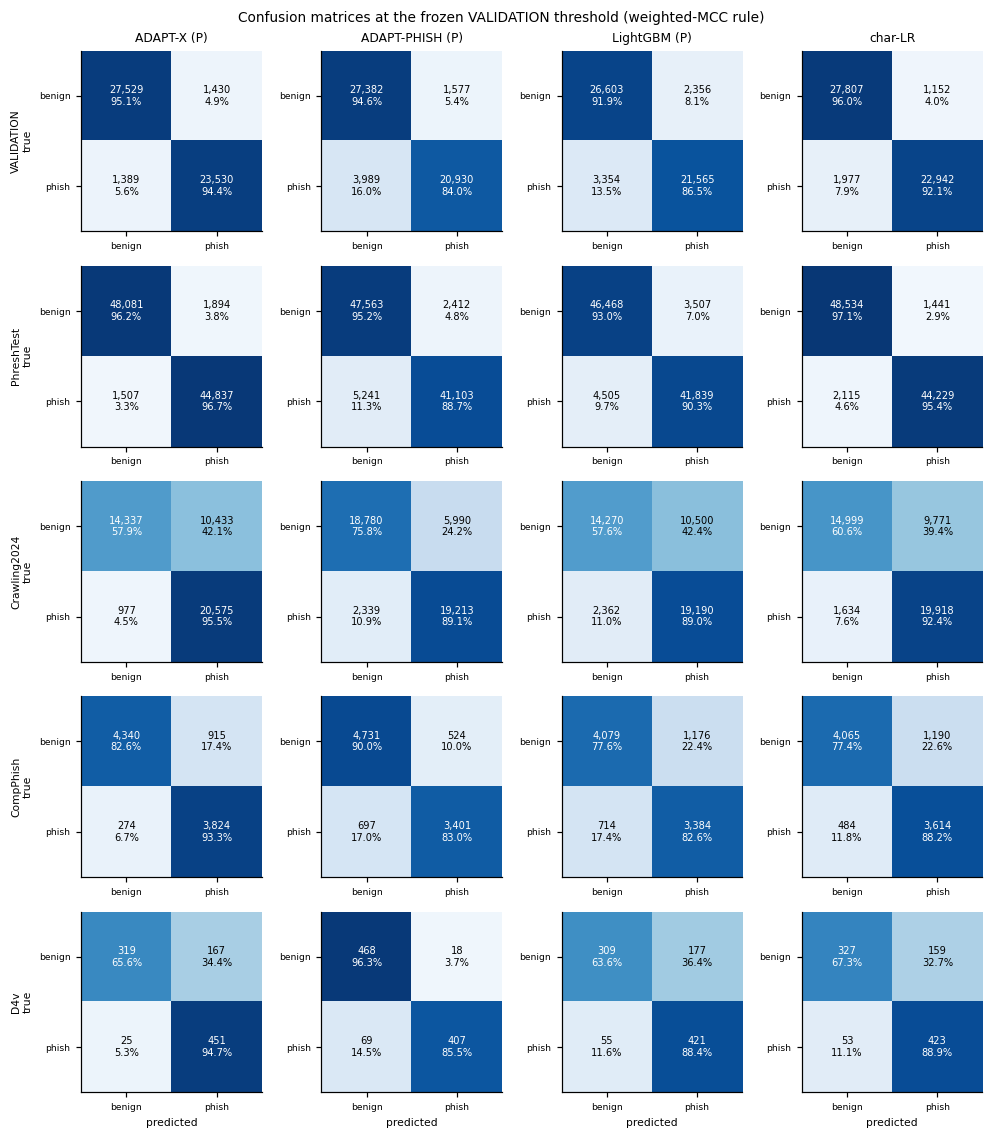

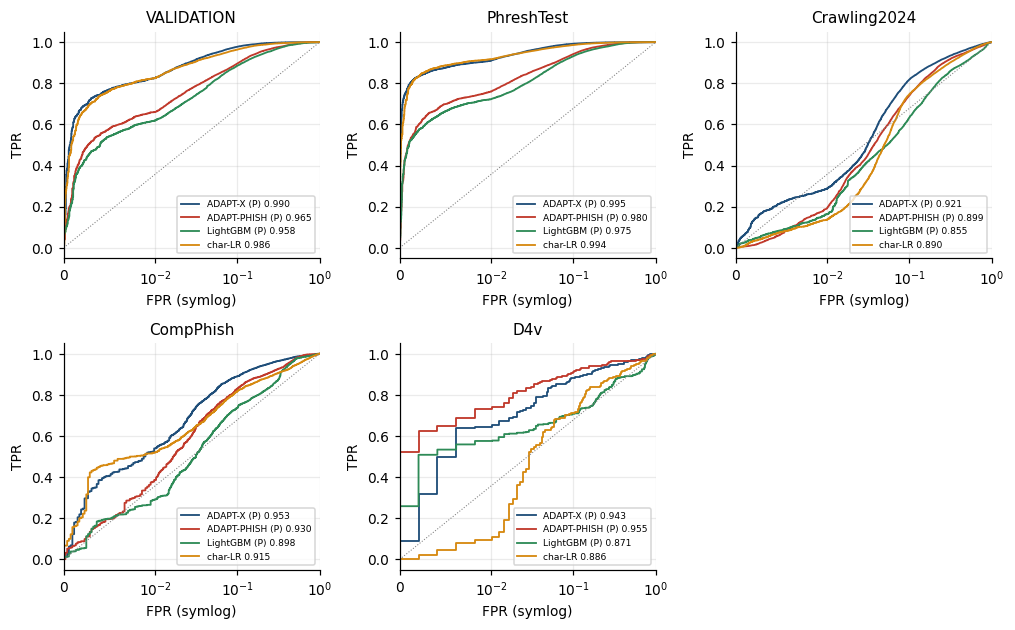

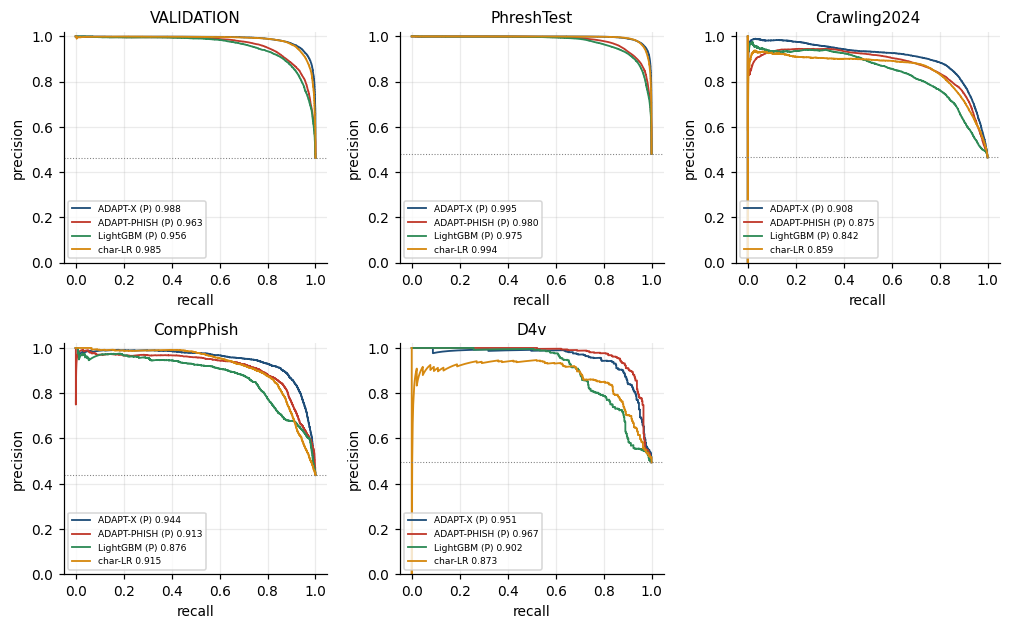

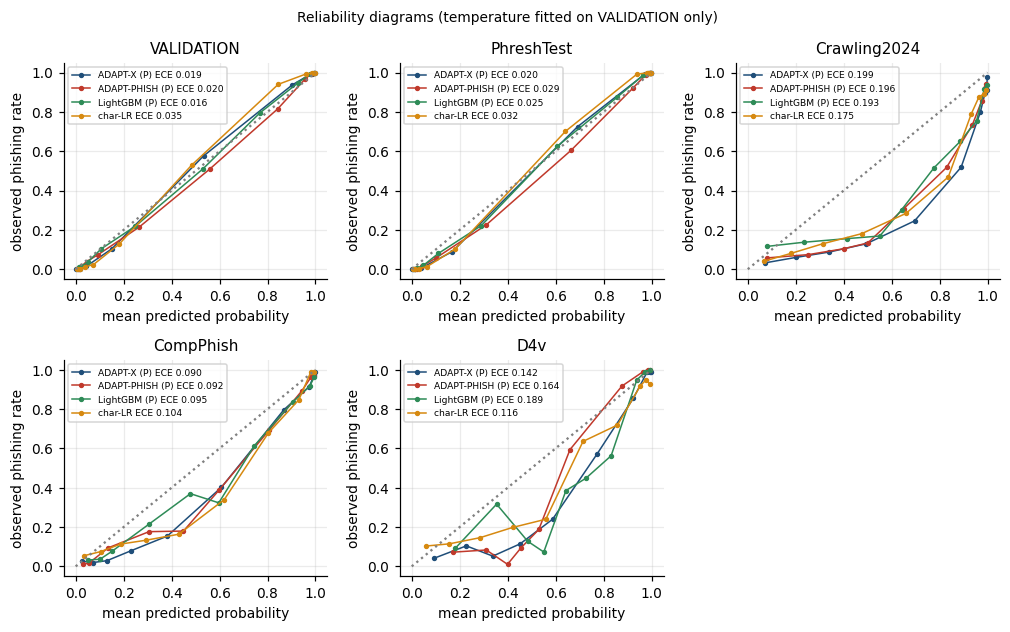

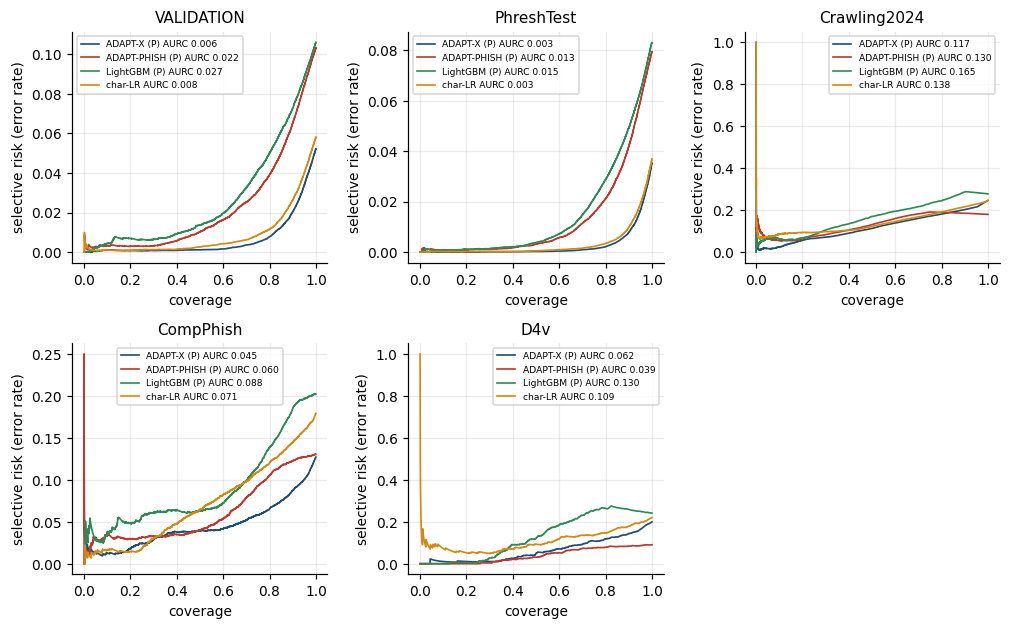

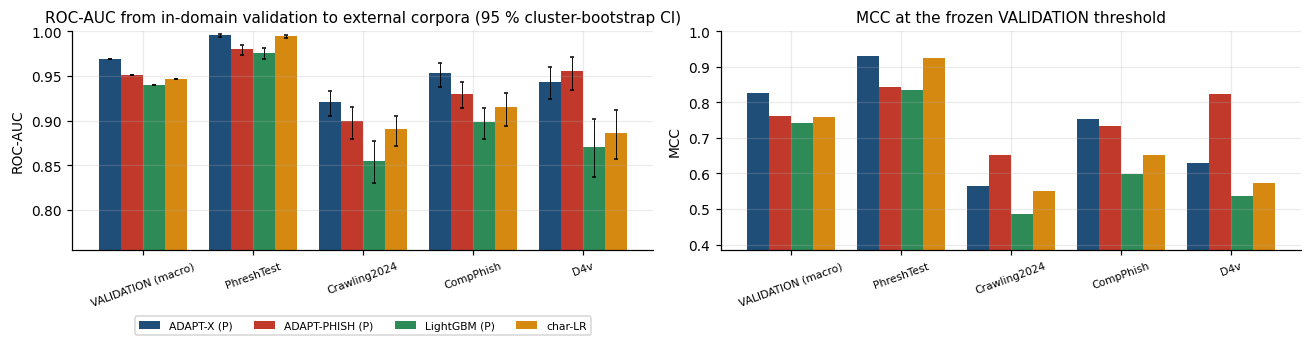

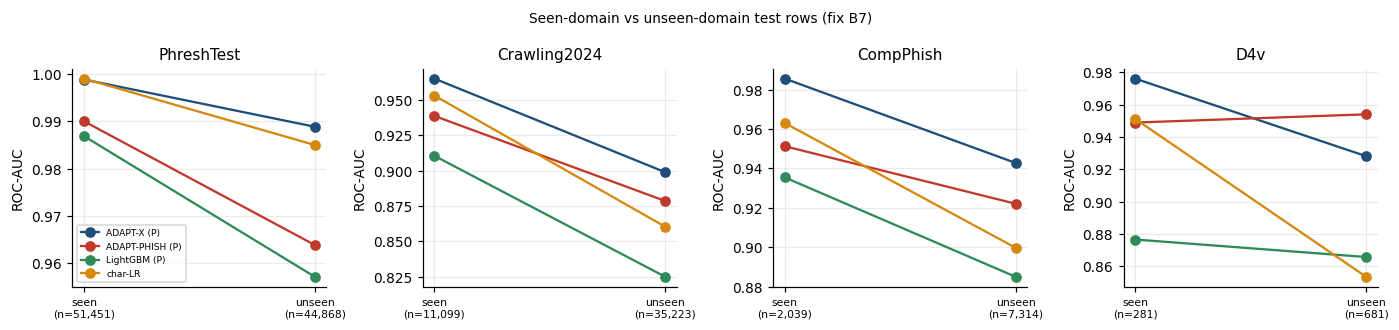

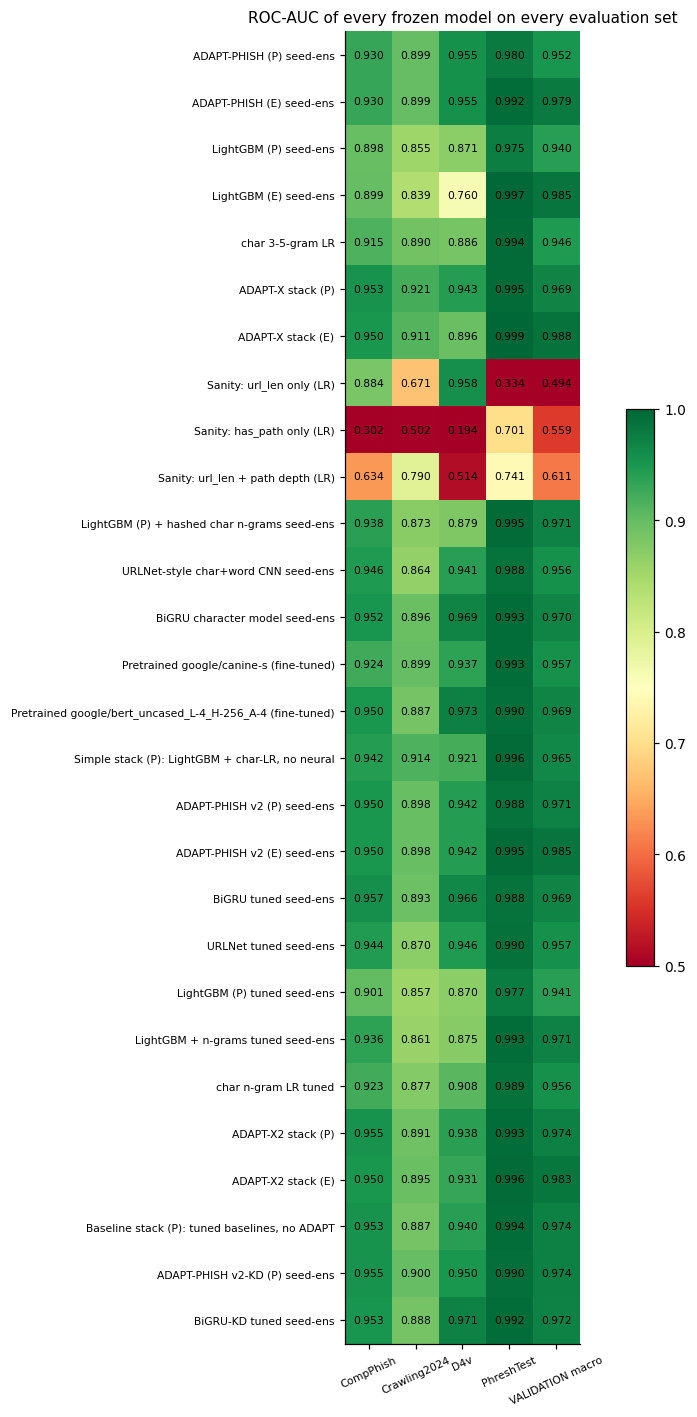

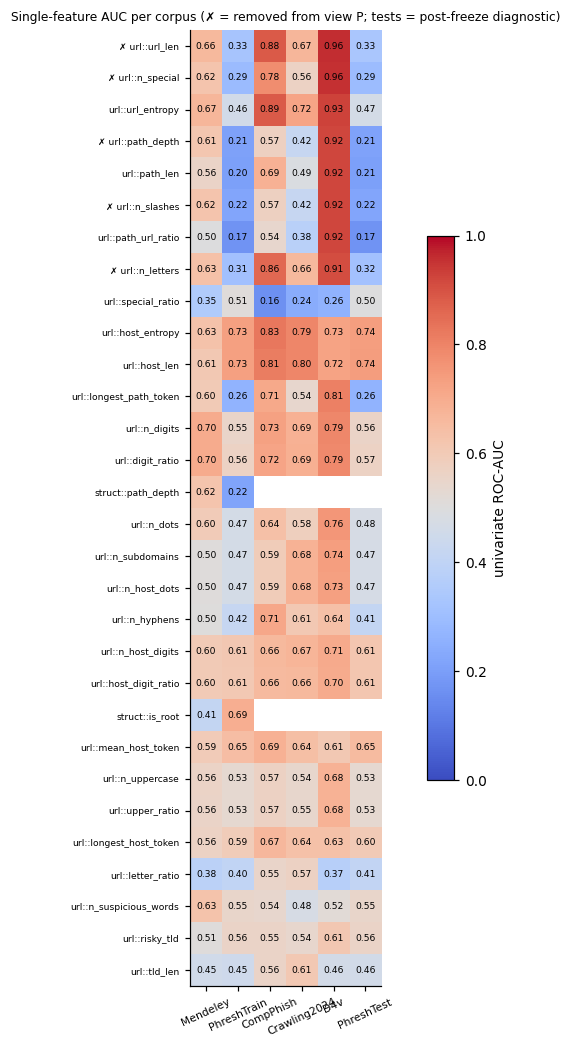

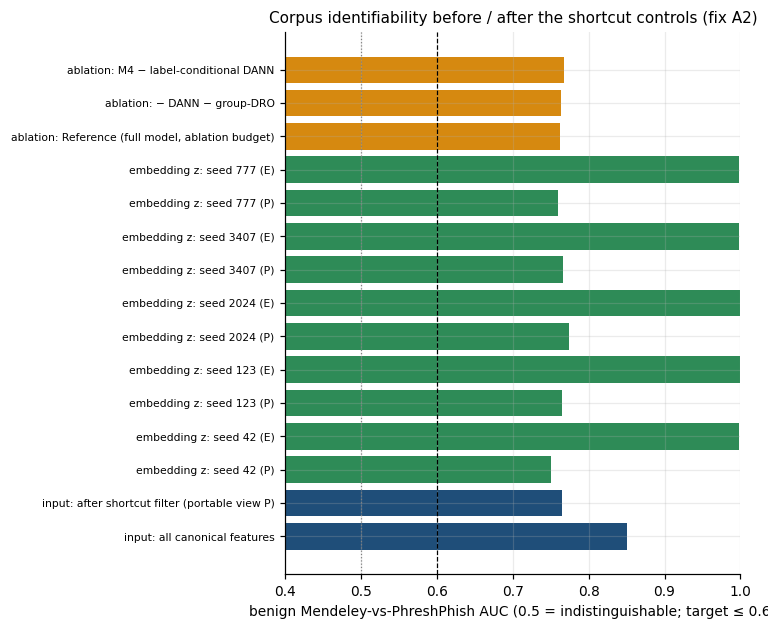

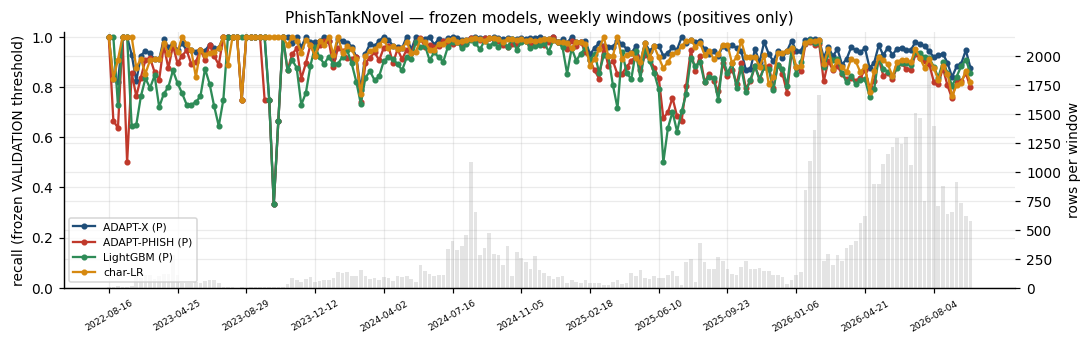

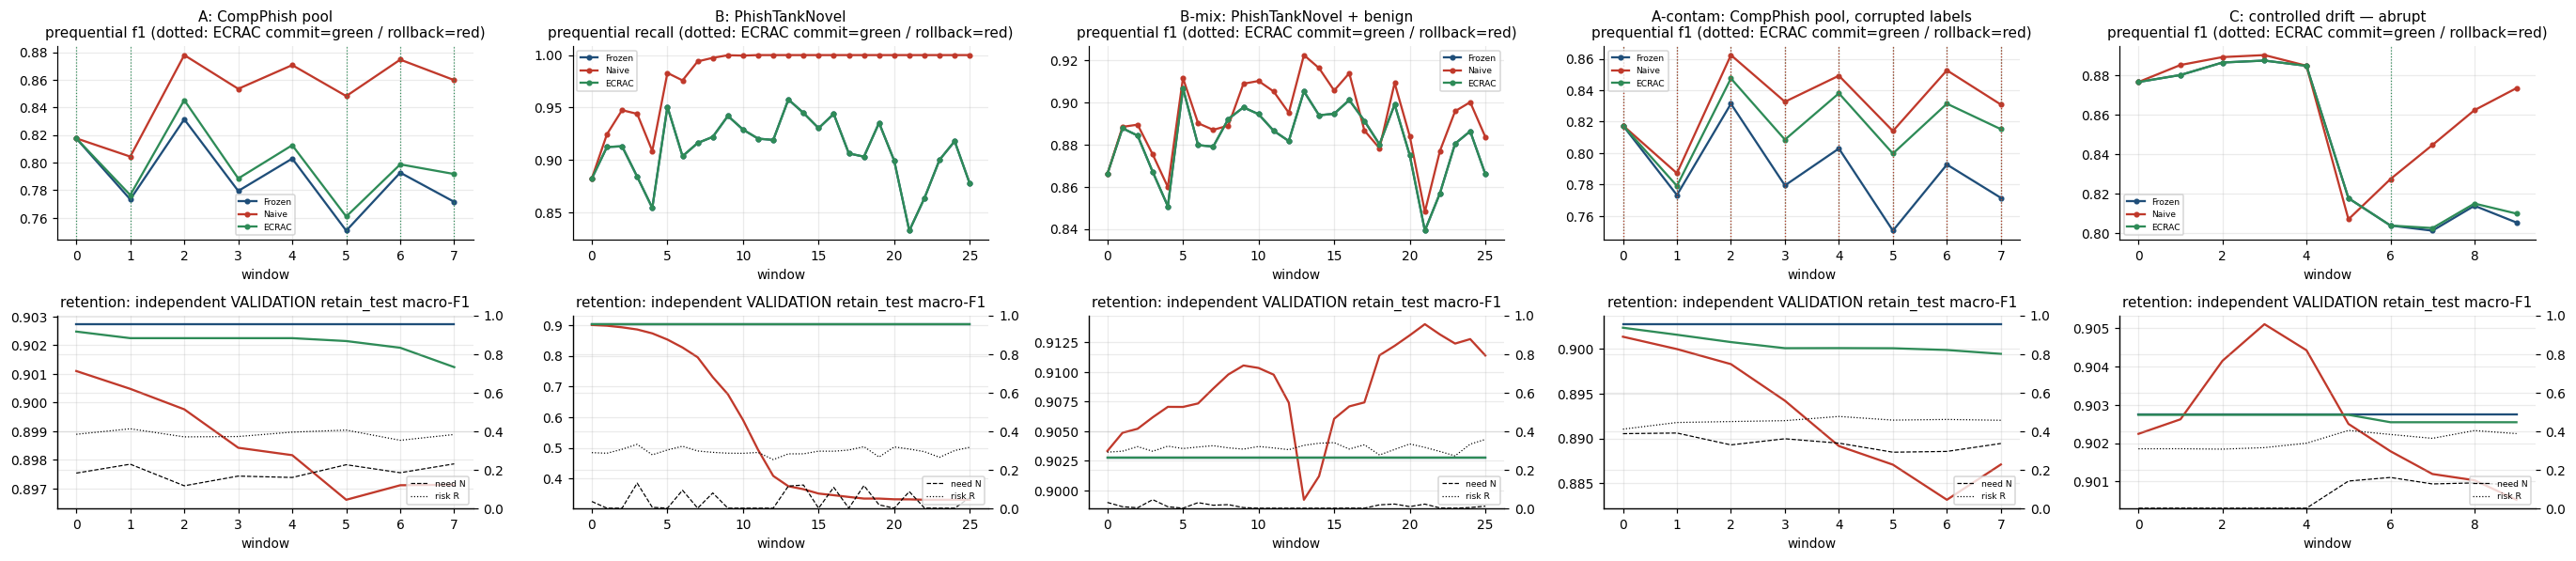

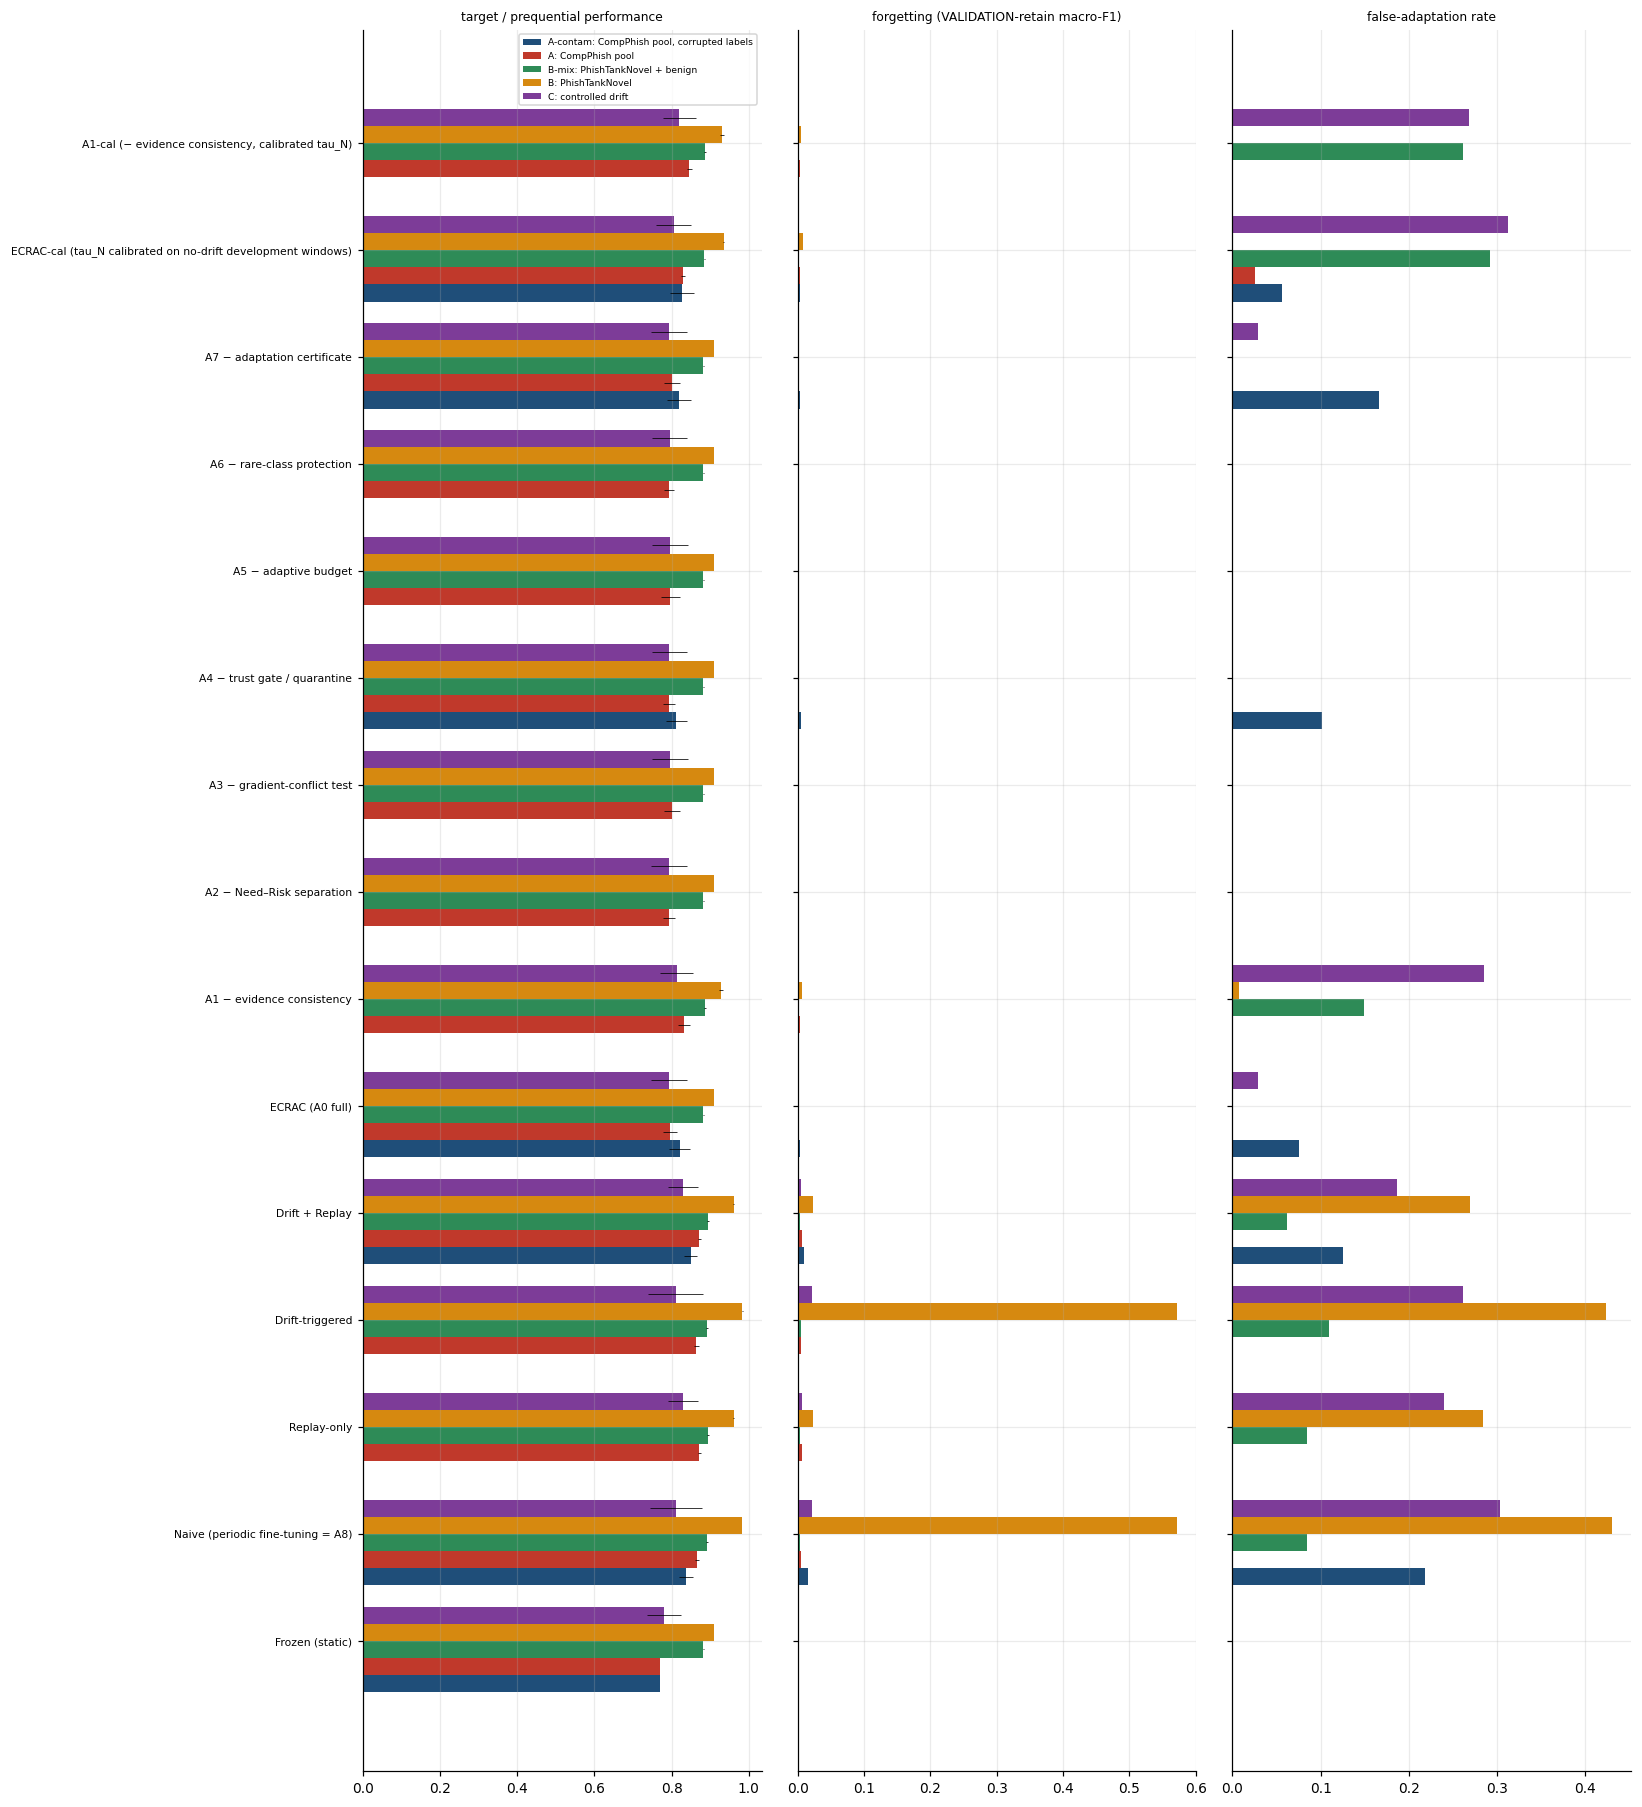

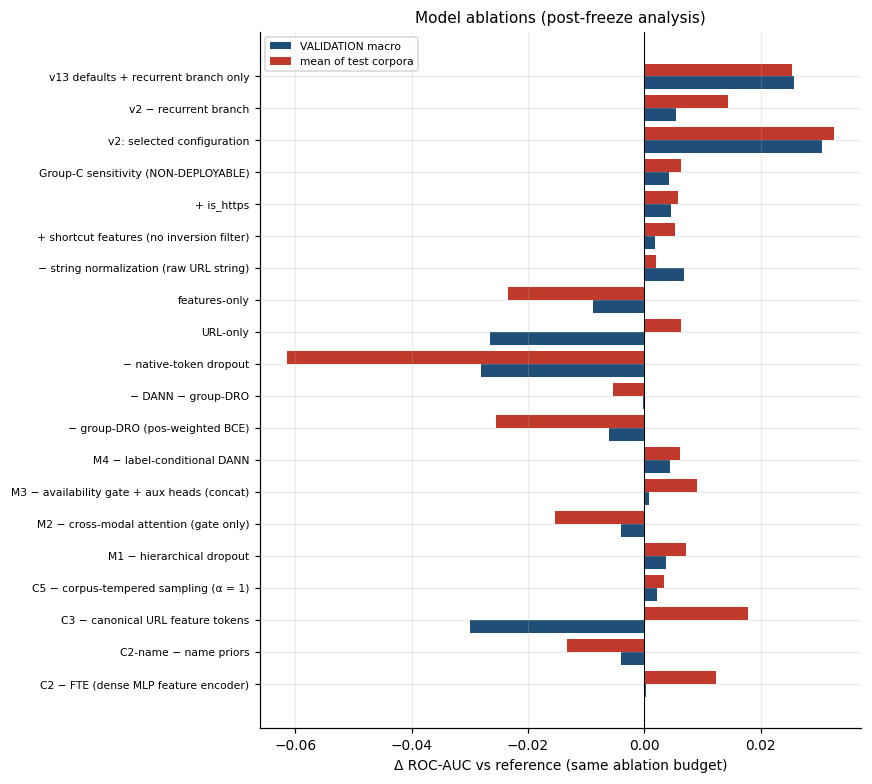

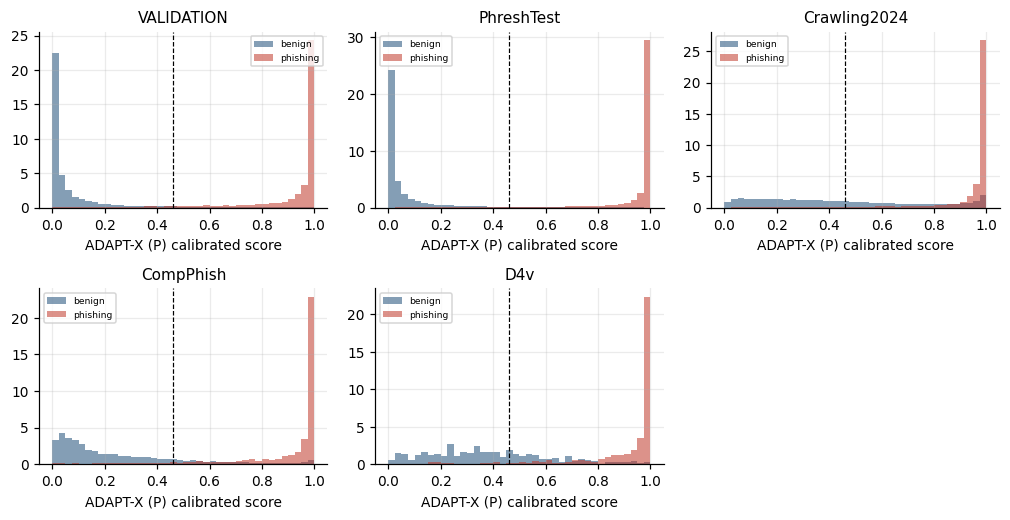

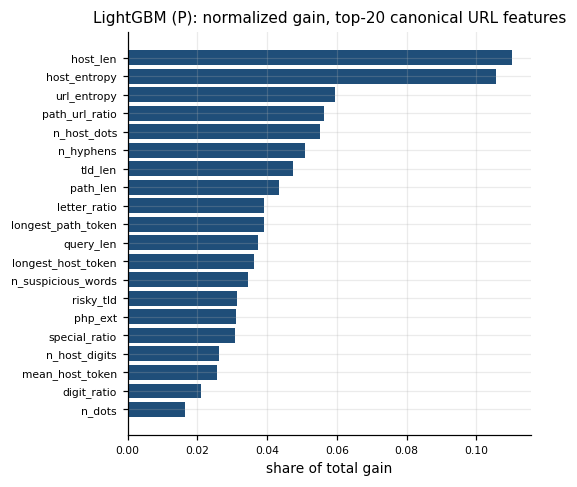

,figure,status
0,confusion_matrices,COMPLETED
1,roc_curves,COMPLETED
2,pr_curves,COMPLETED
3,calibration_curves,COMPLETED
4,risk_coverage,COMPLETED
5,domain_shift,COMPLETED
6,seen_vs_unseen_domains,COMPLETED
7,results_matrix,COMPLETED
8,shortcut_heatmap,COMPLETED
9,corpus_identifiability,COMPLETED


{"phase": "G7_FIGURES", "status": "COMPLETED", "completed": 17, "failed": []}


In [27]:
# CELL 25 — FIGURES (G7b): publication-quality PNG (300 dpi) + vector PDF in figures/
# A figure that cannot be drawn is recorded as FAILED with its error in reports/figure_status.csv (never silently skipped).
from sklearn.calibration import calibration_curve
FIG_STATUS = []
def figure(name):
    def deco(fn):
        try:
            st = fn(); FIG_STATUS.append({"figure": name, "status": st or "COMPLETED"})
        except Exception as ex:                                     # recorded, printed, never hidden
            plt.close("all"); FIG_STATUS.append({"figure": name, "status": "FAILED", "error": repr(ex)[:300]}); print(f"[figure {name}] FAILED: {ex!r}")
        return fn
    return deco
FIG_MODELS = [m for m in ["ADAPT-X stack (P)", "ADAPT-PHISH (P) seed-ens", "LightGBM (P) seed-ens", "char 3-5-gram LR"] if m in MODEL_REG]
SHORT = {"ADAPT-X stack (P)": "ADAPT-X (P)", "ADAPT-PHISH (P) seed-ens": "ADAPT-PHISH (P)", "LightGBM (P) seed-ens": "LightGBM (P)",
         "char 3-5-gram LR": "char-LR", "ADAPT-X stack (E)": "ADAPT-X (E)", "ADAPT-PHISH (E) seed-ens": "ADAPT-PHISH (E)", "LightGBM (E) seed-ens": "LightGBM (E)"}
COL = {m: PALETTE[i] for i, m in enumerate(FIG_MODELS + ["ADAPT-X stack (E)", "ADAPT-PHISH (E) seed-ens", "LightGBM (E) seed-ens"])}
PANELS = {"VALIDATION": pd.DataFrame({"y": yv, **{m: prob(m, "val") for m in FIG_MODELS}})}
PANELS.update({k: v for k, v in PRED_STORE.items() if k != "PhishTank"})
def grid(n, w=3.1, h=2.9):
    c = min(3, n); r = math.ceil(n / c); fig, ax = plt.subplots(r, c, figsize=(w * c, h * r), squeeze=False); return fig, ax.ravel()

@figure("confusion_matrices")
def _():
    names = list(PANELS); fig, ax = plt.subplots(len(names), len(FIG_MODELS), figsize=(2.3 * len(FIG_MODELS), 2.1 * len(names)), squeeze=False)
    for i, dn in enumerate(names):
        PS = PANELS[dn]; y = PS.y.values.astype(int)
        for j, m in enumerate(FIG_MODELS):
            cm = confusion_matrix(y, (PS[m].values >= MODEL_REG[m]["thresholds"]["val_mcc"]).astype(int), labels=[0, 1])
            cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1); a = ax[i, j]
            a.imshow(cmn, cmap="Blues", vmin=0, vmax=1); a.grid(False)
            for (r_, c_), v in np.ndenumerate(cm):
                a.text(c_, r_, f"{v:,}\n{cmn[r_, c_]:.1%}", ha="center", va="center", fontsize=6.5, color="white" if cmn[r_, c_] > .55 else "black")
            a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xticklabels(["benign", "phish"], fontsize=6); a.set_yticklabels(["benign", "phish"], fontsize=6)
            if i == 0: a.set_title(SHORT.get(m, m), fontsize=8)
            if j == 0: a.set_ylabel(f"{dn}\ntrue", fontsize=7)
            if i == len(names) - 1: a.set_xlabel("predicted", fontsize=7)
    fig.suptitle("Confusion matrices at the frozen VALIDATION threshold (weighted-MCC rule)", fontsize=9); fig.tight_layout()
    savefig(fig, "confusion_matrices")

@figure("roc_curves")
def _():
    fig, ax = grid(len(PANELS))
    for a, (dn, PS) in zip(ax, PANELS.items()):
        y = PS.y.values.astype(int)
        if len(np.unique(y)) < 2: a.set_title(f"{dn}: one class"); continue
        for m in FIG_MODELS:
            f_, t_, _ = roc_curve(y, PS[m]); a.plot(f_, t_, c=COL[m], lw=1.2, label=f"{SHORT[m]} {roc_auc_score(y, PS[m]):.3f}")
        a.plot([0, 1], [0, 1], ":", c="grey", lw=.7); a.set_xscale("symlog", linthresh=1e-2); a.set_xlim(0, 1)
        a.set(title=dn, xlabel="FPR (symlog)", ylabel="TPR"); a.legend(fontsize=6, loc="lower right")
    for a in ax[len(PANELS):]: a.axis("off")
    fig.tight_layout(); savefig(fig, "roc_curves")

@figure("pr_curves")
def _():
    fig, ax = grid(len(PANELS))
    for a, (dn, PS) in zip(ax, PANELS.items()):
        y = PS.y.values.astype(int)
        if len(np.unique(y)) < 2: continue
        for m in FIG_MODELS:
            p_, r_, _ = precision_recall_curve(y, PS[m]); a.plot(r_, p_, c=COL[m], lw=1.2, label=f"{SHORT[m]} {average_precision_score(y, PS[m]):.3f}")
        a.axhline(y.mean(), ls=":", c="grey", lw=.7); a.set(title=dn, xlabel="recall", ylabel="precision", ylim=(0, 1.02)); a.legend(fontsize=6, loc="lower left")
    for a in ax[len(PANELS):]: a.axis("off")
    fig.tight_layout(); savefig(fig, "pr_curves")

@figure("calibration_curves")
def _():
    fig, ax = grid(len(PANELS))
    for a, (dn, PS) in zip(ax, PANELS.items()):
        y = PS.y.values.astype(int)
        if len(np.unique(y)) < 2: continue
        for m in FIG_MODELS:
            fp, mp = calibration_curve(y, PS[m], n_bins=10, strategy="quantile"); a.plot(mp, fp, "-o", ms=2.5, c=COL[m], lw=1, label=f"{SHORT[m]} ECE {ece_score(y, PS[m].values):.3f}")
        a.plot([0, 1], [0, 1], ":", c="grey"); a.set(title=dn, xlabel="mean predicted probability", ylabel="observed phishing rate"); a.legend(fontsize=6)
    for a in ax[len(PANELS):]: a.axis("off")
    fig.suptitle("Reliability diagrams (temperature fitted on VALIDATION only)", fontsize=9); fig.tight_layout(); savefig(fig, "calibration_curves")

@figure("risk_coverage")
def _():
    fig, ax = grid(len(PANELS))
    for a, (dn, PS) in zip(ax, PANELS.items()):
        y = PS.y.values.astype(int)
        for m in FIG_MODELS:
            p = PS[m].values; conf = np.abs(p - 0.5); o = np.argsort(-conf); err = ((p >= MODEL_REG[m]["thresholds"]["val_mcc"]).astype(int) != y)[o]
            cov = np.arange(1, len(o) + 1) / len(o); risk = np.cumsum(err) / np.arange(1, len(o) + 1)
            a.plot(cov, risk, c=COL[m], lw=1.1, label=f"{SHORT[m]} AURC {np.trapezoid(risk, cov) if hasattr(np, 'trapezoid') else np.trapz(risk, cov):.3f}")
        a.set(title=dn, xlabel="coverage", ylabel="selective risk (error rate)"); a.legend(fontsize=6)
    for a in ax[len(PANELS):]: a.axis("off")
    fig.tight_layout(); savefig(fig, "risk_coverage")

@figure("domain_shift")
def _():
    TR = pd.DataFrame(TEST_ROWS); TR = TR[(TR.threshold_rule == "val_mcc") & TR.model.isin(FIG_MODELS) & (TR.subset == "ALL")]
    vm = G2_TABLE[(G2_TABLE.corpus == "MACRO (mean of corpora)") & G2_TABLE.model.isin(FIG_MODELS)].assign(dataset="VALIDATION (macro)")
    T2 = pd.concat([vm[["dataset", "model", "roc_auc", "mcc"]], TR[["dataset", "model", "roc_auc", "mcc"]]])
    dsn = list(dict.fromkeys(T2.dataset)); x = np.arange(len(dsn)); w = 0.8 / len(FIG_MODELS)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
    for k, met in enumerate(["roc_auc", "mcc"]):
        for i, m in enumerate(FIG_MODELS):
            v = T2[T2.model == m].set_index("dataset")[met].reindex(dsn).values
            err = None
            if met == "roc_auc" and len(BOOT):
                b_ = BOOT[(BOOT.model == m) & (BOOT.metric == "roc_auc") & (BOOT.subset == "ALL")].set_index("dataset").reindex(dsn)
                err = np.vstack([np.clip(v - b_.ci95_low.values, 0, None), np.clip(b_.ci95_high.values - v, 0, None)])
                err = np.nan_to_num(err)
            ax[k].bar(x + i * w - 0.4 + w / 2, v, w, color=COL[m], label=SHORT[m], yerr=err, capsize=1.5, error_kw={"lw": .6})
        ax[k].set_xticks(x); ax[k].set_xticklabels(dsn, rotation=20, fontsize=7); ax[k].set_ylabel(met.upper().replace("_", "-"))
        ax[k].set_ylim(max(0, np.nanmin(T2[met]) - 0.1), 1.0)
    ax[0].set_title("ROC-AUC from in-domain validation to external corpora (95 % cluster-bootstrap CI)"); ax[1].set_title("MCC at the frozen VALIDATION threshold")
    ax[0].legend(fontsize=7, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.28)); fig.tight_layout(); savefig(fig, "domain_shift")

@figure("seen_vs_unseen_domains")
def _():
    TR = pd.DataFrame(TEST_ROWS); TR = TR[(TR.threshold_rule == "val_mcc") & TR.model.isin(FIG_MODELS)]
    TR = TR[TR.subset.str.startswith(("seen_domain", "unseen_domain")) & ~TR.subset.str.contains("ROOT")]
    TR["domain"] = np.where(TR.subset.str.startswith("seen"), "seen in TRAIN", "unseen (domain-disjoint)")
    dsn = list(dict.fromkeys(TR.dataset)); fig, ax = plt.subplots(1, len(dsn), figsize=(3.2 * len(dsn), 3), squeeze=False); ax = ax.ravel()
    for a, dn in zip(ax, dsn):
        g = TR[TR.dataset == dn]
        for i, m in enumerate(FIG_MODELS):
            v = g[g.model == m].set_index("domain").roc_auc.reindex(["seen in TRAIN", "unseen (domain-disjoint)"]).values
            a.plot([0, 1], v, "-o", c=COL[m], label=SHORT[m])
        n_ = g.drop_duplicates("domain").set_index("domain").n_subset
        a.set_xticks([0, 1]); a.set_xticklabels([f"seen\n(n={n_.get('seen in TRAIN', 0):,})", f"unseen\n(n={n_.get('unseen (domain-disjoint)', 0):,})"], fontsize=7)
        a.set(title=dn, ylabel="ROC-AUC")
    ax[0].legend(fontsize=6); fig.suptitle("Seen-domain vs unseen-domain test rows (fix B7)", fontsize=9); fig.tight_layout(); savefig(fig, "seen_vs_unseen_domains")

@figure("results_matrix")
def _():
    TR = pd.DataFrame(TEST_ROWS); TR = TR[(TR.threshold_rule == "val_mcc") & (TR.subset == "ALL") & TR.family.notna()]
    mods = [m for m in MODEL_REG if not re.search(r" s\d+$", m)]
    vm = G2_TABLE[(G2_TABLE.corpus == "MACRO (mean of corpora)")].assign(dataset="VALIDATION macro")
    T2 = pd.concat([vm[["dataset", "model", "roc_auc"]], TR[["dataset", "model", "roc_auc"]]])
    H = T2[T2.model.isin(mods)].pivot_table(index="model", columns="dataset", values="roc_auc").reindex(mods)
    fig, a = plt.subplots(figsize=(1.3 * H.shape[1] + 2.5, 0.42 * H.shape[0] + 1.2))
    im = a.imshow(H.values, cmap="RdYlGn", vmin=max(0.5, np.nanmin(H.values) - .02), vmax=1); a.grid(False)
    for (i, j), v in np.ndenumerate(H.values):
        if np.isfinite(v): a.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=7)
    a.set_xticks(range(H.shape[1])); a.set_xticklabels(H.columns, rotation=25, fontsize=7); a.set_yticks(range(H.shape[0])); a.set_yticklabels(H.index, fontsize=7)
    plt.colorbar(im, ax=a, fraction=0.03); a.set_title("ROC-AUC of every frozen model on every evaluation set"); fig.tight_layout(); savefig(fig, "results_matrix")

@figure("shortcut_heatmap")
def _():
    S = pd.read_csv(D["reports"] / "shortcut_audit_all_corpora.csv", index_col=0)
    S = S.drop(columns=["removed_by_filter"]).loc[(S.drop(columns=["removed_by_filter"]) - .5).abs().max(1).sort_values(ascending=False).index[:30]]
    fig, a = plt.subplots(figsize=(1.0 * S.shape[1] + 3, 0.28 * S.shape[0] + 1.2))
    im = a.imshow(S.values, cmap="coolwarm", vmin=0, vmax=1); a.grid(False)
    for (i, j), v in np.ndenumerate(S.values):
        if np.isfinite(v): a.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6)
    a.set_xticks(range(S.shape[1])); a.set_xticklabels(S.columns, rotation=25, fontsize=7); a.set_yticks(range(S.shape[0]))
    a.set_yticklabels([("✗ " if "feat::" + f in SHORTCUT_DROP else "") + f for f in S.index], fontsize=6)
    plt.colorbar(im, ax=a, fraction=0.03, label="univariate ROC-AUC"); a.set_title("Single-feature AUC per corpus (✗ = removed from view P; tests = post-freeze diagnostic)", fontsize=8)
    fig.tight_layout(); savefig(fig, "shortcut_heatmap")

@figure("corpus_identifiability")
def _():
    ci_ = pd.read_csv(D["reports"] / "corpus_identifiability.csv"); inp = ci_[ci_.corpus.str.startswith("Mendeley vs")]
    bars = [(f"input: {r.features}", r.one_vs_rest_AUC) for r in inp.itertuples()]
    bars += [(f"embedding z: seed {r.model.split()[-1]} ({r.view})", r[3]) for r in IDF_TABLE.itertuples()]
    if len(ABL) and "benign corpus identifiability (z, VALIDATION, P view)" in ABL:
        for an in ["Reference (full model, ablation budget)", "− DANN − group-DRO", "M4 − label-conditional DANN"]:
            v = ABL[ABL.ablation == an]["benign corpus identifiability (z, VALIDATION, P view)"]
            if len(v): bars.append((f"ablation: {an}", float(v.iloc[0])))
    fig, a = plt.subplots(figsize=(7, 0.32 * len(bars) + 1))
    a.barh(range(len(bars)), [b[1] for b in bars], color=[PALETTE[0] if b[0].startswith("input") else PALETTE[2] if b[0].startswith("emb") else PALETTE[3] for b in bars])
    a.set_yticks(range(len(bars))); a.set_yticklabels([b[0] for b in bars], fontsize=7); a.axvline(0.6, ls="--", c="k", lw=.8); a.axvline(0.5, ls=":", c="grey", lw=.8)
    a.set_xlim(0.4, 1.0); a.set_xlabel("benign Mendeley-vs-PhreshPhish AUC (0.5 = indistinguishable; target ≤ 0.6)")
    a.set_title("Corpus identifiability before / after the shortcut controls (fix A2)"); fig.tight_layout(); savefig(fig, "corpus_identifiability")

@figure("threshold_transfer")
def _():
    TR = pd.DataFrame(TEST_ROWS); TR = TR[TR.threshold_rule.isin(["val_fpr@1%", "val_fpr@0.1%"]) & TR.model.isin(FIG_MODELS) & (TR.subset == "ALL") & TR.fpr.notna()]
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    for k, rule in enumerate(["val_fpr@1%", "val_fpr@0.1%"]):
        g = TR[TR.threshold_rule == rule]; dsn = list(dict.fromkeys(g.dataset)); x = np.arange(len(dsn)); w = 0.8 / len(FIG_MODELS)
        for i, m in enumerate(FIG_MODELS):
            gg = g[g.model == m].set_index("dataset").reindex(dsn)
            ax[k].bar(x + i * w - .4 + w / 2, gg.fpr.values, w, color=COL[m], label=SHORT[m])
            for xi, (fp, tp) in enumerate(zip(gg.fpr.values, gg.recall.values)):
                if np.isfinite(tp): ax[k].text(xi + i * w - .4 + w / 2, fp, f"{tp:.2f}", ha="center", va="bottom", fontsize=5, rotation=90)
        tgt = 0.01 if "1%" in rule else 0.001; ax[k].axhline(tgt, ls="--", c="k", lw=.8)
        ax[k].set_yscale("log"); ax[k].set_xticks(x); ax[k].set_xticklabels(dsn, rotation=15, fontsize=7)
        ax[k].set(title=f"threshold fixed on VALIDATION for macro FPR ≤ {tgt:.1%}: achieved test FPR (label = TPR)", ylabel="test FPR (log)")
    ax[0].legend(fontsize=6); fig.tight_layout(); savefig(fig, "threshold_transfer")

@figure("phishtank_timeline")
def _():
    W = PTK_WIN[(PTK_WIN.threshold_rule == "val_mcc") & (PTK_WIN.subset == "PhishTankNovel (primary)")]
    fig, a = plt.subplots(figsize=(10, 3.2)); a2 = a.twinx()
    wins = sorted(W.window.unique()); x = np.arange(len(wins))
    n_ = W.drop_duplicates("window").set_index("window").n.reindex(wins); a2.bar(x, n_.values, color="lightgrey", alpha=.6, zorder=0); a2.set_ylabel("rows per window")
    for m in [m for m in FIG_MODELS if m in W.model.unique()]:
        a.plot(x, W[W.model == m].set_index("window").recall.reindex(wins).values, "-o", ms=3, c=COL[m], label=SHORT[m], zorder=3)
    a.set_zorder(a2.get_zorder() + 1); a.patch.set_visible(False)
    a.set_xticks(x[:: max(1, len(x) // 12)]); a.set_xticklabels([str(w)[:10] for w in wins][:: max(1, len(x) // 12)], rotation=30, fontsize=6)
    a.set(ylabel="recall (frozen VALIDATION threshold)", title=f"PhishTankNovel — frozen models, {WINDOW_FREQ} windows (positives only)", ylim=(0, 1.02)); a.legend(fontsize=7)
    fig.tight_layout(); savefig(fig, "phishtank_timeline")

@figure("adaptation_timeline")
def _():
    vs = ["Frozen (static)", "Naive (periodic fine-tuning = A8)", "ECRAC (A0 full)"]; tracks = [t for t in ECRAC_LOG.track.unique() if not t.startswith("C")]
    tracks += [("C: controlled drift", "abrupt")] if (ECRAC_LOG.scenario == "abrupt").any() else []
    fig, ax = plt.subplots(2, len(tracks), figsize=(5 * len(tracks), 5.5), squeeze=False)
    for j, tr in enumerate(tracks):
        L = ECRAC_LOG[(ECRAC_LOG.track == tr[0]) & (ECRAC_LOG.scenario == tr[1])] if isinstance(tr, tuple) else ECRAC_LOG[ECRAC_LOG.track == tr]
        key = "preq_recall" if str(tr).startswith("B:") else "preq_f1"
        for i, v in enumerate(vs):
            rcol = "retain_test_macro_f1" if "retain_test_macro_f1" in L else "retain_macro_f1"      # v13: independent retention set
            g = L[L.variant == v].groupby("window")[[key, rcol]].mean()
            ax[0, j].plot(g.index, g[key], "-o", ms=3, c=PALETTE[i], label=v.split(" (")[0]); ax[1, j].plot(g.index, g[rcol], "-", c=PALETTE[i])
        ev = L[(L.variant == "ECRAC (A0 full)") & L.decision.isin(["COMMIT", "ROLLBACK"])]
        for _, e_ in ev.drop_duplicates(["window", "decision"]).iterrows():
            ax[0, j].axvline(e_.window, c=PALETTE[2] if e_.decision == "COMMIT" else PALETTE[1], ls=":", lw=.8)
        e2 = L[L.variant == "ECRAC (A0 full)"].groupby("window")[["N", "R"]].mean(); a3 = ax[1, j].twinx()
        a3.plot(e2.index, e2.N, "--", c="k", lw=.8, label="need N"); a3.plot(e2.index, e2.R, ":", c="k", lw=.8, label="risk R"); a3.set_ylim(0, 1); a3.legend(fontsize=6, loc="lower right")
        ttl = tr if isinstance(tr, str) else f"{tr[0]} — {tr[1]}"
        ax[0, j].set(title=f"{ttl}\nprequential {key.replace('preq_', '')} (dotted: ECRAC commit=green / rollback=red)", xlabel="window")
        ax[1, j].set(title="retention: independent VALIDATION retain_test macro-F1", xlabel="window")
        ax[0, j].legend(fontsize=6)
    fig.tight_layout(); savefig(fig, "adaptation_timeline")

@figure("ecrac_comparison")
def _():
    S = ECRAC_SUM.copy(); S["score"] = S.get("final_target_f1", pd.Series(np.nan, index=S.index)).fillna(S.get("prequential_mean_recall", pd.Series(np.nan, index=S.index))).fillna(S.get("prequential_mean_f1"))
    g = S.groupby(["track", "variant"]).agg(score=("score", "mean"), sd=("score", "std"), forg=("forgetting (max_k retain − final)", "mean"),
                                            far=("false_adaptation_rate", "mean"), upd=("update_count (commits)", "mean")).reset_index()
    order = list(VARIANTS); tracks = list(g.track.unique()); fig, ax = plt.subplots(1, 3, figsize=(15, 0.28 * len(order) * len(tracks) / 1.5 + 2.5))
    for k, (met, ttl) in enumerate([("score", "target / prequential performance"), ("forg", "forgetting (VALIDATION-retain macro-F1)"), ("far", "false-adaptation rate")]):
        for i, tr in enumerate(tracks):
            gg = g[g.track == tr].set_index("variant").reindex(order)
            ax[k].barh(np.arange(len(order)) + i * 0.8 / len(tracks), gg[met].values, 0.8 / len(tracks), color=PALETTE[i], label=tr,
                       xerr=gg["sd"].values if met == "score" else None, error_kw={"lw": .5})
        ax[k].set_yticks(np.arange(len(order)) + 0.4); ax[k].set_yticklabels(order if k == 0 else [], fontsize=7); ax[k].set_title(ttl, fontsize=8)
    ax[0].legend(fontsize=6); fig.tight_layout(); savefig(fig, "ecrac_comparison")

@figure("ablation_bars")
def _():
    if not len(ABL): return "NOT_RUN (model ablations skipped)"
    A_ = ABL[(ABL.view == "P")]; ext = [d for d in A_.dataset.unique() if d not in ("VALIDATION (macro of corpora)", "PhishTankNovel (recall only)")]
    val = A_[A_.dataset == "VALIDATION (macro of corpora)"].set_index("ablation")["Δroc_auc vs reference"]
    exm = A_[A_.dataset.isin(ext)].groupby("ablation")["Δroc_auc vs reference"].mean()
    order = [a for a in MODEL_ABLATIONS if a in val.index and not a.startswith("Reference")]
    fig, a = plt.subplots(figsize=(8, 0.3 * len(order) + 1.2)); y_ = np.arange(len(order))
    a.barh(y_ - .2, val.reindex(order).values, .4, color=PALETTE[0], label="VALIDATION macro"); a.barh(y_ + .2, exm.reindex(order).values, .4, color=PALETTE[1], label="mean of test corpora")
    a.axvline(0, c="k", lw=.7); a.set_yticks(y_); a.set_yticklabels(order, fontsize=7); a.set_xlabel("Δ ROC-AUC vs reference (same ablation budget)")
    a.set_title("Model ablations (post-freeze analysis)"); a.legend(fontsize=7); fig.tight_layout(); savefig(fig, "ablation_bars")

@figure("score_distributions")
def _():
    m = FIG_MODELS[0]; fig, ax = grid(len(PANELS), 3.1, 2.4)
    for a, (dn, PS) in zip(ax, PANELS.items()):
        for lab_, c_ in [(0, PALETTE[0]), (1, PALETTE[1])]:
            v = PS[m].values[PS.y.values == lab_]
            if len(v): a.hist(v, bins=40, range=(0, 1), density=True, alpha=.55, color=c_, label=["benign", "phishing"][lab_])
        a.axvline(MODEL_REG[m]["thresholds"]["val_mcc"], c="k", ls="--", lw=.8); a.set(title=dn, xlabel=f"{SHORT[m]} calibrated score"); a.legend(fontsize=6)
    for a in ax[len(PANELS):]: a.axis("off")
    fig.tight_layout(); savefig(fig, "score_distributions")

@figure("lightgbm_importance")
def _():
    g_ = MODEL_REG[f"LightGBM (P) s{MODEL_SEEDS[0]}"]["obj"]; imp = pd.Series(g_.booster_.feature_importance("gain"), index=[c.replace("feat::url::", "") for c in P_COLS])
    imp = (imp / imp.sum()).sort_values()[-20:]; fig, a = plt.subplots(figsize=(5, 4.5)); a.barh(imp.index, imp.values, color=PALETTE[0])
    a.set(title="LightGBM (P): normalized gain, top-20 canonical URL features", xlabel="share of total gain"); a.tick_params(labelsize=7)
    fig.tight_layout(); savefig(fig, "lightgbm_importance")

pd.DataFrame(FIG_STATUS).to_csv(D["reports"] / "figure_status.csv", index=False); display(pd.DataFrame(FIG_STATUS))
phase_status("G7_FIGURES", "COMPLETED" if all(f["status"] != "FAILED" for f in FIG_STATUS) else "PARTIALLY_COMPLETED",
             completed=sum(f["status"] == "COMPLETED" for f in FIG_STATUS), failed=[f["figure"] for f in FIG_STATUS if f["status"] == "FAILED"])


## 26 — Tables and reproducibility record

In [28]:
# CELL 26 — TABLES + LaTeX + XLSX + reproducibility.json (G7c)
import platform as _pf
TR = pd.DataFrame(TEST_ROWS)
def ci_str(ds, sub_, m, met):
    if not len(BOOT): return ""
    r = BOOT[(BOOT.dataset == ds) & (BOOT.subset == sub_) & (BOOT.model == m) & (BOOT.metric == met)]
    return f"[{r.ci95_low.iloc[0]:.3f}, {r.ci95_high.iloc[0]:.3f}]" if len(r) else ""
# ---- final metrics (headline models, ALL rows, frozen VALIDATION threshold) ----
FM = TR[(TR.threshold_rule == "val_mcc") & TR.model.isin(HEADLINE) & (TR.subset == "ALL")].copy()
FM["roc_auc_ci95"] = [ci_str(r.dataset, "ALL", r.model, "roc_auc") for r in FM.itertuples()]
FM["f1_ci95"] = [ci_str(r.dataset, "ALL", r.model, "f1") for r in FM.itertuples()]
ext_ds = [d for d in ["Crawling2024", "CompPhish", "D4v"] if d in FM.dataset.unique()]
mac = FM[FM.dataset.isin(ext_ds)].groupby("model")[["roc_auc", "pr_auc", "f1", "macro_f1", "mcc", "recall", "fpr", "ece"]].mean().reset_index()
mac["dataset"] = f"MACRO external ({', '.join(ext_ds)})"
FINAL = pd.concat([FM, mac], ignore_index=True)
cols_f = ["dataset", "model", "n", "roc_auc", "roc_auc_ci95", "pr_auc", "f1", "f1_ci95", "macro_f1", "mcc", "recall", "fpr", "ece", "brier",
          "precision@prev=0.01", "oracle_tpr@fpr=1%"]
FINAL = FINAL[[c for c in cols_f if c in FINAL]]
FINAL.to_csv(D["tables"] / "final_metrics.csv", index=False); display(FINAL.round(4))
lat = FINAL[FINAL.model.isin(["ADAPT-X stack (P)", "ADAPT-PHISH (P) seed-ens", "LightGBM (P) seed-ens", "char 3-5-gram LR"])].copy()
lat["model"] = lat.model.map(lambda m: SHORT.get(m, m))
write_latex(lat[[c for c in ["dataset", "model", "roc_auc", "roc_auc_ci95", "pr_auc", "f1", "mcc", "fpr", "ece"] if c in lat]], "final_metrics",
            "Frozen models on every evaluation set (threshold fixed on VALIDATION; 95 % CI: registrable-domain cluster bootstrap).", "tab:final")
DEP = TR[TR.threshold_rule.str.startswith("val_fpr") & TR.model.isin(HEADLINE) & (TR.subset == "ALL")][["dataset", "model", "threshold_rule", "threshold", "recall", "fpr", "precision@prev=0.01"]]
DEP.to_csv(D["tables"] / "deployment_operating_points.csv", index=False)
write_latex(DEP.assign(model=DEP.model.map(lambda m: SHORT.get(m, m))), "deployment", "TPR and achieved FPR on each test set at thresholds fixed on VALIDATION for macro FPR ≤ 1 % / 0.1 %.", "tab:deploy")
SEEN = TR[(TR.threshold_rule == "val_mcc") & TR.model.isin(HEADLINE) & TR.subset.str.startswith(("seen_domain", "unseen_domain"))]
SEEN[["dataset", "subset", "n_subset", "model", "roc_auc", "pr_auc", "f1", "mcc", "recall", "fpr"]].to_csv(D["tables"] / "seen_vs_unseen_domain.csv", index=False)
# ---- baselines (VALIDATION macro, every non-per-seed model) ----
BL = G2_TABLE[(G2_TABLE.corpus == "MACRO (mean of corpora)") & ~G2_TABLE.model.str.contains(r" s\d+$")][["model", "roc_auc", "pr_auc", "f1", "mcc", "recall", "fpr", "ece"]]
write_latex(BL, "baselines", "VALIDATION, macro over development corpora (same split, same threshold rule, temperature on VALIDATION for all models).", "tab:baselines")
if "PSEUDO" in globals():
    write_latex(PSEUDO[PSEUDO.threshold_rule.str.startswith("val_mcc")].drop(columns=["threshold_rule"]), "loco_check",
                "Leave-one-development-corpus-out check (train on one corpus, evaluate on the other's VALIDATION rows; source thresholds).", "tab:loco")
if len(ABL): write_latex(ABL_SUMMARY.reset_index(), "ablations", "Model ablations: ROC-AUC (P view) at an identical ablation budget; post-freeze analysis.", "tab:ablations")
if len(STATS):
    st = STATS.copy()
    for c in st.columns:
        if st[c].map(lambda v: isinstance(v, tuple)).any(): st[c] = st[c].map(lambda v: f"[{v[0]:.4f}, {v[1]:.4f}]" if isinstance(v, tuple) else v)
    STATS_FLAT = st; write_latex(st[[c for c in ["test", "dataset", "A", "B", "delta_roc_auc (A−B)", "delta_roc_auc_ci95", "p_bootstrap(Δauc ≤ 0)", "mcnemar_p", "wilcoxon_p", "n_pairs (seeds)"] if c in st]].head(40),
                                 "statistics", "Paired statistical tests (cluster bootstrap by domain, McNemar, Wilcoxon across seeds).", "tab:stats")
if len(ECRAC_SUM):
    cols_e = [c for c in ["track", "variant", "final_target_f1", "final_target_pr_auc", "final_target_fpr", "final_target_ece", "prequential_mean_f1",
                          "prequential_mean_recall", "forgetting (max_k retain − final)", "update_count (commits)", "rollback_rate", "quarantine_rate",
                          "false_adaptation_rate", "update_latency_s (mean)"] if c in ECRAC_TABLE]
    write_latex(ECRAC_TABLE[ECRAC_TABLE.variant.isin(["Frozen (static)", "Naive (periodic fine-tuning = A8)", "Replay-only", "Drift + Replay", "ECRAC (A0 full)"])][cols_e],
                "ecrac", "Continual adaptation: Frozen vs Naive vs ECRAC (mean over seeds and scenarios).", "tab:ecrac")
    write_latex(CTRL_ABL, "controller_ablations", "ECRAC controller ablations A0–A8 (separate from model ablations).", "tab:ctrl")

# ---- reproducibility.json ----
import sklearn as _sk
try:
    import lightgbm as _lgbv; _lgb_v = _lgbv.__version__
except ImportError:
    _lgb_v = "NOT_AVAILABLE"
REPRO = {"started": RUN_CONTEXT["started"], "finished": datetime.datetime.now().isoformat(timespec="seconds"), "python": sys.version.split()[0],
         "platform": _pf.platform(), "torch": torch.__version__, "pandas": pd.__version__, "numpy": np.__version__, "sklearn": _sk.__version__,
         "lightgbm": _lgb_v, "device": str(DEVICE), "cpu_threads": torch.get_num_threads(), "run_level": RUN_LEVEL, "seeds": MODEL_SEEDS,
         "split_seed": SPLIT_SEED_USED, "bootstrap_B": BOOTSTRAP_B, "training_profile": RUN_CONTEXT.get("training_profile"),
         "dataset_sha256": {m["name"]: m.get("sha256") for m in DATASET_MANIFEST}, "frozen_manifest": RUN_CONTEXT["frozen_manifest"],
         "external_opens": EXTERNAL_LOG, "env_overrides": {k: v for k, v in os.environ.items() if k.startswith("ADAPT_PHISH_")},
         "ecrac_config": CFG_E if "CFG_E" in globals() else "NOT_RUN"}
(D["reports"] / "reproducibility.json").write_text(json.dumps(REPRO, indent=2, default=str))

# ---- XLSX ----
def _flat(df):
    df = df.copy()
    for c in df.columns:
        if df[c].map(lambda v: isinstance(v, (tuple, list, dict, set))).any(): df[c] = df[c].map(lambda v: json.dumps(v, default=str) if isinstance(v, (tuple, list, dict, set)) else v)
    return df
def _rd(p, **kw):
    p = Path(p); return pd.read_csv(p, **kw) if p.exists() else pd.DataFrame({"status": ["NOT_AVAILABLE"]})
SHEETS = {
    "Dataset_Manifest": pd.DataFrame(DATASET_MANIFEST), "Data_Audit": _rd(D["reports"] / "data_audit.csv"),
    "Leakage_Audit": _rd(D["reports"] / "leakage_audit.csv"), "Integrity_Checks": _rd(D["reports"] / "integrity_checks.csv"),
    "Dropped_Rows": _rd(D["reports"] / "dropped_rows.csv"), "Train_Validation": _rd(D["tables"] / "train_validation_split.csv"),
    "Shortcut_Audit": _rd(D["reports"] / "shortcut_audit_all_corpora.csv"), "Corpus_Identifiability": pd.concat([_rd(D["reports"] / "corpus_identifiability.csv"), IDF_TABLE]),
    "Feature_Bridges": _rd(D["reports"] / "feature_bridges_manual.csv"), "Training_History": HIST,
    "Validation_Metrics": G2_TABLE, "Calibration": CAL_TABLE, "Threshold": THR_TABLE,
    "IID_Test": TR[(TR.dataset == "PhreshTest") & (TR.subset == "ALL")], "Domain_Disjoint_Test": TR[TR.subset.astype(str).str.startswith("unseen_domain")],
    "Seen_Domain_Test": TR[TR.subset.astype(str).str.startswith("seen_domain")],
    "Crawling2024": TR[TR.dataset == "Crawling2024"], "CompPhish": TR[TR.dataset == "CompPhish"], "D4v": TR[TR.dataset == "D4v"],
    "PhishTank": TR[TR.dataset == "PhishTank"], "PhishTank_Windows": PTK_WIN if "PTK_WIN" in globals() else pd.DataFrame({"status": ["NOT_RUN"]}),
    "Final_Metrics": FINAL, "Deployment_Points": DEP, "Baselines": _rd(D["reports"] / "baselines.csv"),
    "LOCO_Check": PSEUDO if "PSEUDO" in globals() else pd.DataFrame({"status": ["NOT_RUN"]}),
    "Bootstrap_CI": BOOT, "Statistics": STATS, "Seed_Results": SEEDS_T, "Ablations": ABL if len(ABL) else pd.DataFrame({"status": ["NOT_RUN"]}),
    "ECRAC": ECRAC_SUM if len(ECRAC_SUM) else pd.DataFrame({"status": ["NOT_RUN"]}),
    "Controller_Ablations": CTRL_ABL if len(ECRAC_SUM) else pd.DataFrame({"status": ["NOT_RUN"]}),
    "Adaptation_Events": ADAPT_EVENTS if len(ADAPT_EVENTS) else pd.DataFrame({"status": ["no adaptation event"]}),
    "Reproducibility": pd.DataFrame([{"key": k, "value": json.dumps(v, default=str)[:30000]} for k, v in REPRO.items()]),
    "Phase_Status": pd.DataFrame(PHASES).astype(str),
}
XLSX = RESULTS / "ADAPT_PHISH_FINAL_RESULTS.xlsx"
with pd.ExcelWriter(XLSX, engine="openpyxl") as xw:
    for sn, df in SHEETS.items():
        _flat(df).to_excel(xw, sheet_name=sn[:31], index=False)
print(f"XLSX: {XLSX} ({len(SHEETS)} sheets) | LaTeX: {sorted(p.name for p in D['paper_results'].glob('*.tex'))}")
phase_status("G7_TABLES", "COMPLETED", sheets=len(SHEETS), latex=len(list(D["paper_results"].glob("*.tex"))))


,dataset,model,n,roc_auc,roc_auc_ci95,pr_auc,f1,f1_ci95,macro_f1,mcc,recall,fpr,ece,brier,precision@prev=0.01,oracle_tpr@fpr=1%
0,PhreshTest,ADAPT-PHISH (P) seed-ens,96319.0,0.9798,"[0.974, 0.985]",0.9796,0.9148,"[0.892, 0.933]",0.9202,0.8420,0.8869,0.0483,0.0288,0.0561,0.1566,0.7595
1,PhreshTest,ADAPT-PHISH (E) seed-ens,96319.0,0.9922,"[0.990, 0.994]",0.9922,0.9573,"[0.946, 0.966]",0.9592,0.9187,0.9466,0.0288,0.0146,0.0311,0.2491,0.8907
2,PhreshTest,LightGBM (P) seed-ens,96319.0,0.9752,"[0.969, 0.981]",0.9751,0.9126,"[0.891, 0.931]",0.9166,0.8334,0.9028,0.0702,0.0251,0.0617,0.1150,0.7224
3,PhreshTest,LightGBM (E) seed-ens,96319.0,0.9968,"[0.996, 0.998]",0.9969,0.9752,"[0.969, 0.981]",0.9763,0.9527,0.9667,0.0148,0.0187,0.0189,0.3974,0.9540
4,PhreshTest,char 3-5-gram LR,96319.0,0.9942,"[0.993, 0.996]",0.9942,0.9614,"[0.951, 0.970]",0.9630,0.9261,0.9544,0.0288,0.0321,0.0293,0.2506,0.9169
5,PhreshTest,ADAPT-X stack (P),96319.0,0.9954,"[0.994, 0.996]",0.9953,0.9635,"[0.954, 0.971]",0.9647,0.9293,0.9675,0.0379,0.0202,0.0264,0.2050,0.9108
6,PhreshTest,ADAPT-X stack (E),96319.0,0.9987,"[0.998, 0.999]",0.9987,0.9833,"[0.979, 0.987]",0.9839,0.9678,0.9859,0.0179,0.0140,0.0123,0.3568,0.9785
7,Crawling2024,ADAPT-PHISH (P) seed-ens,46322.0,0.8992,"[0.879, 0.915]",0.8754,0.8219,"[0.781, 0.854]",0.8202,0.6506,0.8915,0.2418,0.1959,0.1758,0.0359,0.1919
8,Crawling2024,ADAPT-PHISH (E) seed-ens,46322.0,0.8992,"[0.879, 0.915]",0.8754,0.7874,"[0.743, 0.824]",0.7628,0.5738,0.9343,0.3816,0.1983,0.1777,0.0241,0.1919
9,Crawling2024,LightGBM (P) seed-ens,46322.0,0.8552,"[0.830, 0.877]",0.8424,0.7490,"[0.698, 0.792]",0.7192,0.4850,0.8904,0.4239,0.1934,0.2004,0.0208,0.1631


XLSX: D:\KHAYATI 2026\adapt_phish_v15_gpu_results\ADAPT_PHISH_FINAL_RESULTS.xlsx (34 sheets) | LaTeX: ['ablations.tex', 'baselines.tex', 'controller_ablations.tex', 'deployment.tex', 'ecrac.tex', 'final_metrics.tex', 'loco_check.tex', 'statistics.tex']
{"phase": "G7_TABLES", "status": "COMPLETED", "sheets": 34, "latex": 8}


## 27 — Final experiment report

In [29]:
# CELL 27 — FINAL EXPERIMENT REPORT (every number below is read from the tables produced by this run; nothing is typed by hand)
def _v(x, nd=4):
    return "NOT_AVAILABLE" if x is None or (isinstance(x, float) and not np.isfinite(x)) else (f"{x:.{nd}f}" if isinstance(x, (float, np.floating)) else str(x))
def _get(df, **kw):
    r = df
    for k, v in kw.items(): r = r[r[k] == v]
    return r
def md_table(df, nd=4):
    if df is None or not len(df): return "_NOT_AVAILABLE_\n"
    df = _flat(df); cols = list(df.columns)
    out = "| " + " | ".join(map(str, cols)) + " |\n|" + "---|" * len(cols) + "\n"
    for row in df.itertuples(index=False):
        out += "| " + " | ".join(_v(v, nd) if isinstance(v, (float, np.floating)) else str(v) for v in row) + " |\n"
    return out
INT = pd.read_csv(D["reports"] / "integrity_checks.csv")
leak_ptk = _get(LEAK, A="TRAIN", B="PhishTank")
fixes = [
    ("A1 PhishTank purge", f"TRAIN↔PhishTank normalized_url_shared = {int(leak_ptk.normalized_url_shared.iloc[0]) if len(leak_ptk) else 'NOT_AVAILABLE'}; "
                           f"rows purged: {sum(r['count'] for r in DROPPED_ROWS if r['dataset'] == 'PhishTank' and 'leakage purge' in r['reason'])}"),
    ("A2 inverted shortcut", f"removed from view P: {SHORTCUT_DROP}; benign identifiability input-level "
                             f"{ {k: round(v, 4) for k, v in RUN_CONTEXT['shortcut']['identifiability_input_level'].items()} }; "
                             f"embedding-level (seed {MODEL_SEEDS[0]}, P) {_v(IDF_TABLE.iloc[0, 2])}; LOCO Phresh→Mendeley ADAPT-PHISH (P) AUC "
                             f"{_v(_get(PSEUDO, **{'trained on': 'PhreshPhish', 'model': 'ADAPT-PHISH', 'view': 'P'}).roc_auc.iloc[0]) if 'PSEUDO' in globals() else 'NOT_RUN'}"),
    ("A3 shortcut table", f"{int((SFA.flag != '').sum())} flagged features (strong univariate or sign inversion), see reports/shortcut_audit.csv"),
    ("B4 same LOCO for all models", "reports/pseudo_external_check.csv (ADAPT-PHISH, LightGBM P/E, char-LR, ADAPT-X)"),
    ("B5 LightGBM on view E", f"{len(E_COLS)} features; rows 'LightGBM (E) …' in every table"),
    ("B6 macro metrics + macro-AUC selection", "MACRO rows in validation_results.csv; best epoch = max macro-corpus ROC-AUC"),
    ("B7 seen vs unseen domains", "tables/seen_vs_unseen_domain.csv, figures/seen_vs_unseen_domains.png"),
    ("B8 deployment thresholds", "tables/deployment_operating_points.csv (VALIDATION macro FPR ≤ 1 % / 0.1 %, applied unchanged)"),
    ("C9 seeds + cluster bootstrap", f"seeds {MODEL_SEEDS}; B = {BOOTSTRAP_B} registrable-domain clusters"),
    ("C10 calibration", "temperature fitted on VALIDATION for every model; reports/calibration_validation.csv"),
    ("C11 manual bridges", f"{len(BRIDGE_OF)} verified bridges, excluded pairs: {sorted(EXCLUDED_BRIDGES)}"),
    ("D integrity", f"{int(INT.passed.sum())}/{len(INT)} integrity checks passed (reports/integrity_checks.csv); URL truncation keeps head + tail ({URL_TAIL} bytes)"),
]
rep = [f"# ADAPT-PHISH 2.0 + ECRAC — FINAL EXPERIMENT REPORT (v11)\n",
       f"Run: {REPRO['started']} → {REPRO['finished']} | device {REPRO['device']} | profile {RUN_CONTEXT['training_profile']['profile']} | "
       f"run level {RUN_LEVEL} | seeds {MODEL_SEEDS} | split seed {SPLIT_SEED_USED} | bootstrap B {BOOTSTRAP_B}\n",
       "All numbers are produced by this execution. `NOT_AVAILABLE` / `NOT_RUN` mark what was not measured.\n",
       "## 1. Data roles\n", md_table(pd.DataFrame([{"dataset": k, "role": v} for k, v in DATASET_ROLES.items()])),
       "\n## 2. Fixes requested after v10 (A–D) and the evidence for each\n", md_table(pd.DataFrame(fixes, columns=["fix", "evidence (this run)"])),
       "\n## 3. Split and test sizes\n", md_table(split_tab),
       "\n## 4. VALIDATION (macro over development corpora)\n", md_table(BL),
       "\n## 5. Frozen models on the test sets (threshold fixed on VALIDATION)\n", md_table(FINAL[[c for c in ["dataset", "model", "n", "roc_auc", "roc_auc_ci95", "pr_auc", "f1", "mcc", "fpr", "ece"] if c in FINAL]]),
       "\n## 6. Seen-domain vs unseen-domain rows\n", md_table(SEEN[SEEN.model.isin(FIG_MODELS)][["dataset", "subset", "n_subset", "model", "roc_auc", "f1", "recall", "fpr"]]),
       "\n## 7. Deployment operating points (VALIDATION macro-FPR thresholds)\n", md_table(DEP[DEP.model.isin(FIG_MODELS)]),
       "\n## 8. Leave-one-development-corpus-out check (same conditions for every model)\n",
       md_table(PSEUDO[PSEUDO.threshold_rule.str.startswith("val_mcc")] if "PSEUDO" in globals() else None),
       "\n## 9. PhishTank (frozen, positives only: recall)\n", md_table(PTK_REC[PTK_REC.threshold_rule == "val_mcc"][["subset", "n_subset", "model", "recall"]] if "PTK_REC" in globals() else None),
       "\n## 10. ECRAC — Frozen vs Naive vs ECRAC (mean over seeds / scenarios)\n",
       md_table(ECRAC_TABLE[ECRAC_TABLE.variant.isin(["Frozen (static)", "Naive (periodic fine-tuning = A8)", "ECRAC (A0 full)"])][cols_show] if len(ECRAC_SUM) else None),
       "\n### Controller ablations A0–A8\n", md_table(CTRL_ABL[show_c] if len(ECRAC_SUM) else None),
       f"\nScenarios NOT_RUN: {SCENARIOS_NOT_RUN}\n",
       "\n## 11. Model ablations (identical ablation budget, P view ROC-AUC)\n", md_table(ABL_SUMMARY.reset_index() if len(ABL) else None),
       "\n## 12. Statistics\n", md_table(STATS_FLAT.head(30) if len(STATS) else None),
       "\n## 13. Interpretation rules and limitations\n",
       "* ADAPT-X is a stacked fusion fitted on VALIDATION (out-of-fold); its VALIDATION numbers are out-of-fold, its test numbers are untouched.\n"
       "* PhishTank has no negatives: precision, FPR and AUC are NOT_AVAILABLE on it; recall is reported at frozen thresholds.\n"
       "* Wilcoxon across seeds is underpowered with fewer than 6 seeds (minimum attainable p reported in statistical_tests.csv).\n"
       "* ECRAC constants are fixed a priori (configs/ecrac_config.json); ECRAC adapts only the fusion stage of a frozen copy.\n"
       "* Model ablations are trained after the freeze and never replace the frozen model.\n"
       "* The CompPhish external test is used twice by design (frozen evaluation + ECRAC Track-A target), both logged in reports/external_access_log.csv.\n",
       "\n## 14. Phase statuses\n", md_table(pd.DataFrame(PHASES)[["phase", "status"]]),
       "\n## 15. Figures\n", "\n".join(f"* figures/{p.name}" for p in sorted(D["figures"].glob("*.png"))), "\n"]
(RESULTS / "FINAL_EXPERIMENT_REPORT.md").write_text("\n".join(rep), encoding="utf-8")
expected = ["reports/dataset_manifest.json", "reports/data_audit.csv", "reports/leakage_audit.csv", "reports/leakage_audit.json", "reports/label_conflicts.csv",
            "reports/dropped_rows.csv", "reports/dropped_columns.csv", "reports/sentinel_audit.csv", "reports/shortcut_audit.csv", "reports/corpus_identifiability.csv",
            "reports/validation_results.csv", "reports/baselines.csv", "reports/bootstrap_results.csv", "reports/statistical_tests.csv",
            "reports/adaptation_events.csv", "reports/continual_learning_results.csv", "reports/ablation_results.csv", "reports/reproducibility.json",
            "figures/training_curves.png", "figures/validation_curves.png", "figures/confusion_matrices.png", "figures/roc_curves.png", "figures/pr_curves.png",
            "figures/calibration_curves.png", "figures/risk_coverage.png", "figures/domain_shift.png", "figures/adaptation_timeline.png",
            "tables/dataset_summary.csv", "tables/final_metrics.csv", "tables/seed_results.csv", "tables/ablation_summary.csv",
            "paper_results/final_metrics.tex", "paper_results/baselines.tex", "paper_results/ablations.tex", "paper_results/statistics.tex",
            "artifacts/frozen_model/model.pt", "artifacts/frozen_model/preprocessor.pkl", "artifacts/frozen_model/feature_schema.json",
            "artifacts/frozen_model/threshold.json", "artifacts/frozen_model/temperature.json", "artifacts/frozen_model/config.yaml",
            "artifacts/frozen_model/metadata.json", "artifacts/frozen_model/frozen_manifest.json", "FINAL_EXPERIMENT_REPORT.md", "ADAPT_PHISH_FINAL_RESULTS.xlsx"]
missing = [p for p in expected if not (RESULTS / p).exists()]
print(f"Report: {RESULTS / 'FINAL_EXPERIMENT_REPORT.md'} | expected outputs present: {len(expected) - len(missing)}/{len(expected)}" + (f" | missing: {missing}" if missing else ""))
verify_frozen()
phase_status("G7_FINAL_REPORT", "COMPLETED" if not missing else "PARTIALLY_COMPLETED", missing=missing, external_opens=RUN_CONTEXT["external_open_counter"])


Report: D:\KHAYATI 2026\adapt_phish_v15_gpu_results\FINAL_EXPERIMENT_REPORT.md | expected outputs present: 45/45
{"phase": "G7_FINAL_REPORT", "status": "COMPLETED", "missing": [], "external_opens": 8}


## R0 — Revision analyses: setup

In [30]:
# ============================================================
# CELLS R0–R14 — v13 REVISION ANALYSES (IEEE Access, manuscript Access-2026-52395)
# Every analysis below reads the FROZEN models and the predictions already stored by cells 17–24; none of them changes a
# model, a temperature, a threshold or a reported v12 number. Each cell writes its tables to revision/ (CSV), a LaTeX
# version to paper_results/rev_*.tex and a sheet of revision/ADAPT_PHISH_REVISION_RESULTS.xlsx (cell R14).
# A failing analysis is recorded as FAILED (phase_statuses.json + revision/errors.txt) and the run continues;
# ADAPT_PHISH_REV_STRICT=1 re-raises instead (debugging).
# ============================================================
import traceback, contextlib, shutil, zipfile
from scipy.stats import beta as _beta, norm as _norm
REVD = RESULTS / "revision"; REVD.mkdir(parents=True, exist_ok=True)
(REVD / "errors.txt").unlink(missing_ok=True)                 # errors of THIS run only
REV_TABLES, REV_STATUS = {}, {}
REV_STRICT = os.environ.get("ADAPT_PHISH_REV_STRICT") == "1"

@contextlib.contextmanager
def rev_phase(name):
    t0 = time.perf_counter()
    try:
        yield
        REV_STATUS[name] = "COMPLETED"; phase_status(name, "COMPLETED", seconds=round(time.perf_counter() - t0, 1))
    except SessionDeadline:
        raise
    except Exception as ex:
        tb = traceback.format_exc(); REV_STATUS[name] = f"FAILED: {ex!r}"[:300]
        with open(REVD / "errors.txt", "a", encoding="utf-8") as f: f.write(f"\n===== {name} =====\n{tb}\n")
        phase_status(name, "FAILED", error=repr(ex)[:300]); print(tb)
        if REV_STRICT: raise

def rev_save(df, name, caption=None, cols=None, nd="{:.4f}"):
    df = df.reset_index(drop=True) if isinstance(df, pd.DataFrame) else pd.DataFrame(df)
    df = df.map(lambda v: tuple(round(float(x), 6) for x in v) if isinstance(v, tuple) else v)      # CIs as plain (low, high)
    df.to_csv(REVD / f"{name}.csv", index=False); REV_TABLES[name] = df
    if caption is not None and len(df):
        write_latex(df[[c for c in (cols or df.columns) if c in df]], f"rev_{name}", caption, f"tab:rev_{name}", float_fmt=nd)
    return df

def clopper_pearson(k, n, a=0.05):
    if n == 0: return (np.nan, np.nan)
    lo = 0.0 if k == 0 else float(_beta.ppf(a / 2, k, n - k + 1)); hi = 1.0 if k == n else float(_beta.ppf(1 - a / 2, k + 1, n - k))
    return lo, hi
def wilson(k, n, a=0.05):
    if n == 0: return (np.nan, np.nan)
    z = _norm.ppf(1 - a / 2); p = k / n; den = 1 + z * z / n; c = (p + z * z / (2 * n)) / den; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return max(0.0, c - h), min(1.0, c + h)
def sha256_str(s): return hashlib.sha256(str(s).encode("utf-8")).hexdigest()

TEST_NAMES = [d for d in ["PhreshTest", "Crawling2024", "CompPhish", "D4v"] if d in PRED_STORE]
EXT3 = [d for d in ["Crawling2024", "CompPhish", "D4v"] if d in PRED_STORE]
EXT2 = [d for d in ["CompPhish", "D4v"] if d in PRED_STORE]
REV_HEADLINE = [m for m in globals().get("REV_HEADLINE", []) if m in MODEL_REG]
MODELS_R = [m for m in ["ADAPT-X stack (P)", "ADAPT-PHISH (P) seed-ens", "LightGBM (P) seed-ens", "char 3-5-gram LR",
                        "ADAPT-X stack (E)", "ADAPT-PHISH (E) seed-ens", "LightGBM (E) seed-ens"] if m in MODEL_REG] + REV_HEADLINE
V14_HEADLINE = [m for m in globals().get("V14_HEADLINE", []) if m in MODEL_REG]
MODELS_R = list(dict.fromkeys(MODELS_R + V14_HEADLINE))                       # v14: every analysis below also covers the v14 models
SHORT_R = {**SHORT, **{m: m.replace(" seed-ens", "") for m in REV_HEADLINE + V14_HEADLINE}}
B_REV = int(os.environ.get("ADAPT_PHISH_REV_BOOTSTRAP_B", min(BOOTSTRAP_B, 1000)))
print(f"revision analyses -> {REVD} | models: {len(MODELS_R)} | tests: {TEST_NAMES} | bootstrap B = {B_REV}")

revision analyses -> D:\KHAYATI 2026\adapt_phish_v15_gpu_results\revision | models: 28 | tests: ['PhreshTest', 'Crawling2024', 'CompPhish', 'D4v'] | bootstrap B = 1000


## R1 — Crawling2024 provenance

In [31]:
with rev_phase("R1_CRAWLING2024_PROVENANCE"):
    man = {m["name"]: m for m in DATASET_MANIFEST}
    mc, mp = man.get("Crawling2024", {}), man.get("PhreshTrain", {})
    cols_c = set(mc.get("column_names", [])); cols_p = set(mp.get("column_names", []))
    shared = sorted(cols_c & cols_p)
    lp = RUN_CONTEXT["leakage_pairs"]
    pair = lambda a, b: lp[((lp.A == a) & (lp.B == b)) | ((lp.A == b) & (lp.B == a))]
    pc = pair("PhreshTrain", "Crawling2024"); pt = pair("PhreshTest", "Crawling2024")
    nat_tokens = int((DS_FEAT_COLS.get("Crawling2024", np.zeros(N_FEAT_IN, bool)) & IS_NATIVE).sum())
    t_c = TEST.get("Crawling2024")
    prov_rows = [
        ("source", DATASET_PROVENANCE["Crawling2024"]["url"]), ("uploader", DATASET_PROVENANCE["Crawling2024"]["uploader"]),
        ("title on the page", DATASET_PROVENANCE["Crawling2024"]["title"]), ("description on the page", DATASET_PROVENANCE["Crawling2024"]["page_description"]),
        ("version", DATASET_PROVENANCE["Crawling2024"]["version"]), ("license", DATASET_PROVENANCE["Crawling2024"]["license"]),
        ("accessed", DATASET_PROVENANCE["Crawling2024"]["accessed"]), ("file", mc.get("file")), ("SHA-256 of the file used", mc.get("sha256")),
        ("rows in file", mc.get("rows")), ("columns in file", mc.get("columns")), ("label column / mapping", mc.get("label_definition")),
        ("label counts after loading", json.dumps(mc.get("label_counts", {}))),
        ("rows after dedup / conflicts", len(RAW["Crawling2024"]) if "Crawling2024" in RAW else "NOT_AVAILABLE"),
        ("rows after the development purge (test set)", len(t_c) if t_c is not None else "NOT_AVAILABLE"),
        ("unseen-domain rows", int(t_c.domain_disjoint.sum()) if t_c is not None else "NOT_AVAILABLE"),
        ("column names shared with phreshphish_features.csv", f"{len(shared)} of {len(cols_c)} ({', '.join(shared[:25])}{' …' if len(shared) > 25 else ''})"),
        ("Jaccard of column-name sets (Crawling2024 vs PhreshPhish)", round(len(shared) / max(1, len(cols_c | cols_p)), 4)),
        ("normalized URLs shared with PhreshTrain BEFORE purge", int(pc.normalized_url_shared.iloc[0]) if len(pc) else "NOT_AVAILABLE"),
        ("normalized URLs shared with PhreshTest BEFORE purge", int(pt.normalized_url_shared.iloc[0]) if len(pt) else "NOT_AVAILABLE"),
        ("model inputs shared with PhreshTrain BEFORE purge", int(pc.encoder_key_shared.iloc[0]) if len(pc) else "NOT_AVAILABLE"),
        ("native feature tokens of Crawling2024 used by any model", f"{nat_tokens} (0 => its own numeric columns are never a model input; views E and P receive identical inputs)"),
    ]
    R1_PROV = rev_save(pd.DataFrame(prov_rows, columns=["item", "value"]).astype(str), "R1_crawling2024_provenance",
                       "Crawling2024: provenance, integrity and schema checks.")
    display(R1_PROV)
    # ---- label audit sheet: false positives of the main detector at the frozen 1 % rule + a random benign control sample ----
    if "Crawling2024" in PRED_STORE:
        PS = PRED_STORE["Crawling2024"]; d_ = SPLITS["Crawling2024"]; m_ = "ADAPT-X stack (P)" if "ADAPT-X stack (P)" in PS else MODELS_R[0]
        thr = MODEL_REG[m_]["thresholds"]["val_fpr@1%"]; y_ = PS.y.values.astype(int); p_ = PS[m_].values
        r_a = np.random.default_rng(SEED + 101)
        fp_idx = np.where((y_ == 0) & (p_ >= thr))[0]; tn_idx = np.where((y_ == 0) & (p_ < thr))[0]
        pick_fp = np.sort(r_a.choice(fp_idx, min(REV["fp_audit_n"], len(fp_idx)), replace=False)) if len(fp_idx) else np.array([], int)
        pick_ctl = np.sort(r_a.choice(tn_idx, min(REV["fp_audit_n"] // 2, len(tn_idx)), replace=False)) if len(tn_idx) else np.array([], int)
        aud = pd.concat([pd.DataFrame({"sample": "false positive (label 0, score ≥ frozen 1 % threshold)", "row": pick_fp}),
                         pd.DataFrame({"sample": "control (label 0, below threshold)", "row": pick_ctl})], ignore_index=True)
        aud = aud.sample(frac=1.0, random_state=SEED).reset_index(drop=True)      # blind order: the annotator does not see the sample type
        aud["audit_id"] = [f"C24-{i:04d}" for i in range(len(aud))]
        aud["src_row"] = d_.src_row.values[aud.row.values] if "src_row" in d_ else -1
        aud["original_url"] = d_.original_url.values[aud.row.values]; aud["dataset_label"] = y_[aud.row.values]
        aud["score"] = p_[aud.row.values].round(4)
        for c in ["manual_label (phishing / legitimate / unsure / unreachable)", "evidence (screenshot, archive.org, VirusTotal, …)", "annotator", "date"]:
            aud[c] = ""
        blind = aud.drop(columns=["sample", "row", "score"])
        blind.to_csv(REVD / "crawling2024_label_audit_TO_FILL.csv", index=False)
        aud.drop(columns=["original_url"]).to_csv(REVD / "crawling2024_label_audit_key.csv", index=False)     # unblinding key
        print(f"label-audit sheet: {len(aud)} URLs ({len(pick_fp)} FP + {len(pick_ctl)} controls) -> revision/crawling2024_label_audit_TO_FILL.csv")
        # ---- if the filled sheet is present next to the data, score it ----
        filled = DATA_ROOT / "crawling2024_label_audit.csv"
        if filled.exists():
            fa = pd.read_csv(filled).merge(aud[["audit_id", "sample"]], on="audit_id", how="left")
            lab_col = [c for c in fa.columns if c.startswith("manual_label")][0]
            fa["_ml"] = fa[lab_col].astype(str).str.strip().str.lower()
            rows_a = []
            for smp, g in fa.groupby("sample"):
                dec = g[g._ml.isin(["phishing", "legitimate"])]; k = int((dec._ml == "phishing").sum()); n = len(dec)
                rows_a.append({"sample": smp, "annotated": len(g), "decidable": n, "manually phishing (dataset says legitimate)": k,
                               "label-error rate": k / n if n else np.nan, "wilson95": wilson(k, n), "unsure/unreachable": len(g) - n})
            R1_AUDIT = pd.DataFrame(rows_a)
            fp_row = R1_AUDIT[R1_AUDIT["sample"].str.startswith("false positive")]
            if len(fp_row):
                e_fp = float(fp_row["label-error rate"].iloc[0]); fpr_obs = float(np.mean(p_[y_ == 0] >= thr))
                R1_AUDIT["note"] = (f"observed FPR at the frozen 1 % rule {fpr_obs:.4f}; FPR after removing audited label errors ≈ "
                                    f"{fpr_obs * (1 - e_fp):.4f} (assumes the audited FPs are representative)")
            rev_save(R1_AUDIT, "R1_crawling2024_label_audit_result", "Crawling2024 manual label audit (blind; Wilson 95 % CI).")
            display(R1_AUDIT)
        else:
            print(f"(fill the sheet and save it as {filled} — re-running cell R1 then reports the label-error rate)")

,item,value
0,source,https://www.kaggle.com/datasets/haozhang1579/c...
1,uploader,Kaggle user 'haozhang1579' (hao zhang)
2,title on the page,Crawling2024 (Phishing URL Detection Dataset)
3,description on the page,Phishing website detection dataset containing ...
4,version,1 (2024-07-04)
5,license,Open Database License (ODbL) / Database Conten...
6,accessed,NOT_STATED_BY_SOURCE
7,file,Crawling2024.csv
8,SHA-256 of the file used,c83267a14828074724ae187a5ae634b5f4b206d0539eff...
9,rows in file,50000


label-audit sheet: 300 URLs (200 FP + 100 controls) -> revision/crawling2024_label_audit_TO_FILL.csv
(fill the sheet and save it as D:\KHAYATI 2026\Datasets\crawling2024_label_audit.csv — re-running cell R1 then reports the label-error rate)
{"phase": "R1_CRAWLING2024_PROVENANCE", "status": "COMPLETED", "seconds": 0.1}


## R2 — Portable and enriched views

In [32]:
with rev_phase("R2_TABLE8_VERIFICATION"):
    rows = []
    for ds in TEST_NAMES:
        y_ = PRE[ds]["label"].astype(int); has_nat = bool(any(DS_FEAT_COLS[c][IS_NATIVE].any() for c in pd.unique(PRE[ds]["dataset"])))
        for s in MODEL_SEEDS:
            mo = MODEL_REG[f"ADAPT-PHISH (P) s{s}"]["obj"]
            lp_ = predict(mo, ds, view="P")["logit"]; le_ = predict(mo, ds, view="E")["logit"]      # two real forward passes, no shortcut
            rows.append({"dataset": ds, "native tokens in corpus": has_nat, "comparison": f"ADAPT-PHISH seed {s}: forward pass E vs P",
                         "max |logit_E − logit_P|": float(np.max(np.abs(le_ - lp_))), "ROC-AUC P": roc_auc_score(y_, lp_), "ROC-AUC E": roc_auc_score(y_, le_),
                         "T_P": MODEL_REG[f"ADAPT-PHISH (P) s{s}"]["T"], "T_E": MODEL_REG[f"ADAPT-PHISH (E) s{s}"]["T"]})
        lP, lE = raw_logit("ADAPT-PHISH (P) seed-ens", ds), raw_logit("ADAPT-PHISH (E) seed-ens", ds)
        rows.append({"dataset": ds, "native tokens in corpus": has_nat, "comparison": "v13 seed ensemble (mean RAW logit, one temperature)",
                     "max |logit_E − logit_P|": float(np.max(np.abs(lE - lP))), "ROC-AUC P": roc_auc_score(y_, lP), "ROC-AUC E": roc_auc_score(y_, lE),
                     "T_P": MODEL_REG["ADAPT-PHISH (P) seed-ens"]["T"], "T_E": MODEL_REG["ADAPT-PHISH (E) seed-ens"]["T"]})
        lPo = np.mean([raw_logit(f"ADAPT-PHISH (P) s{s}", ds) / MODEL_REG[f"ADAPT-PHISH (P) s{s}"]["T"] for s in MODEL_SEEDS], 0)
        lEo = np.mean([raw_logit(f"ADAPT-PHISH (E) s{s}", ds) / MODEL_REG[f"ADAPT-PHISH (E) s{s}"]["T"] for s in MODEL_SEEDS], 0)
        rows.append({"dataset": ds, "native tokens in corpus": has_nat,
                     "comparison": "v12 seed ensemble (each member / its own view-specific T, then mean) — source of the published discrepancy",
                     "max |logit_E − logit_P|": float(np.max(np.abs(lEo - lPo))), "ROC-AUC P": roc_auc_score(y_, lPo), "ROC-AUC E": roc_auc_score(y_, lEo)})
        if "LightGBM (P) seed-ens" in MODEL_REG and "LightGBM (E) seed-ens" in MODEL_REG:
            cE = MODEL_REG[f"LightGBM (E) s{MODEL_SEEDS[0]}"]["cols"]; Xe = SPLITS[ds].reindex(columns=cE)
            nat_cols = [c for c in cE if not c.startswith("feat::url::")]
            rows.append({"dataset": ds, "native tokens in corpus": has_nat,
                         "comparison": f"LightGBM: two DIFFERENT models (P: {len(P_COLS)} canonical features; E: {len(cE)} features, of which "
                                       f"{len(nat_cols)} native; {int(Xe[nat_cols].isna().all().sum()) if nat_cols else 0} native columns entirely missing here)",
                         "ROC-AUC P": roc_auc_score(y_, prob("LightGBM (P) seed-ens", ds)), "ROC-AUC E": roc_auc_score(y_, prob("LightGBM (E) seed-ens", ds))})
        for v_ in ["P", "E"]:
            nm = f"ADAPT-X stack ({v_})"
            if nm in MODEL_REG:
                rows.append({"dataset": ds, "native tokens in corpus": has_nat, "comparison": f"{nm}: bases {MODEL_REG[nm]['bases']} weights {MODEL_REG[nm]['meta_weights']}",
                             f"ROC-AUC {v_}": roc_auc_score(y_, prob(nm, ds))})
    R2 = rev_save(pd.DataFrame(rows), "R2_table8_prediction_level_verification",
                  "Prediction-level verification of the portable (P) and enriched (E) views.",
                  ["dataset", "comparison", "max |logit_E − logit_P|", "ROC-AUC P", "ROC-AUC E"], nd="{:.6f}")
    display(R2.round(6))
    ok_seed = R2[R2.comparison.str.contains("forward pass") & ~R2["native tokens in corpus"]]["max |logit_E − logit_P|"].max()
    integrity("v13 R2: per-seed forward passes E and P are identical on corpora without native tokens", bool(np.nan_to_num(ok_seed) < 1e-5),
              f"max |Δlogit| = {ok_seed}", fatal=False)
    # ---- mechanism of the LightGBM (E) degradation (reviewer 7, M9 #3): natives set to missing on VALIDATION rows ----
    if "LightGBM (E) seed-ens" in MODEL_REG:
        mrows = []
        for s in MODEL_SEEDS:
            g_ = MODEL_REG[f"LightGBM (E) s{s}"]["obj"]; cE = MODEL_REG[f"LightGBM (E) s{s}"]["cols"]
            X = SPLITS["val"][cE].to_numpy(np.float32); Xn = X.copy(); nat = np.array([not c.startswith("feat::url::") for c in cE]); Xn[:, nat] = np.nan
            gP = MODEL_REG[f"LightGBM (P) s{s}"]["obj"]; XP = SPLITS["val"][P_COLS].to_numpy(np.float32)
            for c_ in np.unique(ds_val_names):
                mk = ds_val_names == c_
                mrows.append({"seed": s, "VALIDATION corpus": c_, "LightGBM (E), natives present": roc_auc_score(yv[mk], g_.predict(X[mk], raw_score=True)),
                              "LightGBM (E), natives set to missing (as on external corpora)": roc_auc_score(yv[mk], g_.predict(Xn[mk], raw_score=True)),
                              "LightGBM (P) (never sees natives)": roc_auc_score(yv[mk], gP.predict(XP[mk], raw_score=True))})
        R2M = pd.DataFrame(mrows); R2M = R2M.groupby("VALIDATION corpus").agg(["mean", "std"]).drop(columns="seed")
        R2M.columns = [f"{a} ({b})" for a, b in R2M.columns]; R2M = R2M.reset_index()
        rev_save(R2M, "R2_lightgbmE_missing_native_test", "LightGBM (E) when native columns are missing (VALIDATION rows, mean over seeds).")
        display(R2M.round(4))
    # ---- hashes of every stored prediction file ----
    rev_save(pd.DataFrame([{"file": p.name, "sha256": sha256_file(p), "bytes": p.stat().st_size} for p in sorted(D["predictions"].glob("*.csv.gz"))]),
             "R2_prediction_file_hashes")

predict PhreshTest:   0%|          | 0/95 [00:00<?, ?it/s]

predict PhreshTest:   0%|          | 0/95 [00:00<?, ?it/s]

predict PhreshTest:   0%|          | 0/95 [00:00<?, ?it/s]

predict PhreshTest:   0%|          | 0/95 [00:00<?, ?it/s]

predict PhreshTest:   0%|          | 0/95 [00:00<?, ?it/s]

predict PhreshTest:   0%|          | 0/95 [00:00<?, ?it/s]

... (34 outputs left out)

,dataset,native tokens in corpus,comparison,max |logit_E − logit_P|,ROC-AUC P,ROC-AUC E,T_P,T_E
0,PhreshTest,True,ADAPT-PHISH seed 42: forward pass E vs P,8.156250,0.973225,0.987192,1.415050,1.304857
1,PhreshTest,True,ADAPT-PHISH seed 123: forward pass E vs P,7.625000,0.975330,0.990424,1.607477,1.366533
2,PhreshTest,True,ADAPT-PHISH seed 2024: forward pass E vs P,7.093750,0.964378,0.988231,1.261935,1.038723
3,PhreshTest,True,ADAPT-PHISH seed 3407: forward pass E vs P,9.734375,0.977502,0.990735,1.821685,1.710004
4,PhreshTest,True,ADAPT-PHISH seed 777: forward pass E vs P,9.671875,0.976145,0.990953,1.500002,1.357393
5,PhreshTest,True,"v13 seed ensemble (mean RAW logit, one tempera...",8.193750,0.979847,0.992237,1.333172,1.208703
6,PhreshTest,True,v12 seed ensemble (each member / its own view-...,5.799774,0.979577,0.992149,NaN,NaN
7,PhreshTest,True,LightGBM: two DIFFERENT models (P: 38 canonica...,NaN,0.975165,0.996794,NaN,NaN
8,PhreshTest,True,ADAPT-X stack (P): bases ['ADAPT-PHISH (P) see...,NaN,0.995395,NaN,NaN,NaN
9,PhreshTest,True,ADAPT-X stack (E): bases ['ADAPT-PHISH (E) see...,NaN,NaN,0.998702,NaN,NaN


  [PASS] v13 R2: per-seed forward passes E and P are identical on corpora without native tokens max |Δlogit| = 0.0


,VALIDATION corpus,"LightGBM (E), natives present (mean)","LightGBM (E), natives present (std)","LightGBM (E), natives set to missing (as on external corpora) (mean)","LightGBM (E), natives set to missing (as on external corpora) (std)",LightGBM (P) (never sees natives) (mean),LightGBM (P) (never sees natives) (std)
0,Mendeley,0.9787,0.0003,0.8863,0.0047,0.9187,0.0018
1,PhreshPhish,0.9913,0.0003,0.9357,0.0024,0.9594,0.0009


{"phase": "R2_TABLE8_VERIFICATION", "status": "COMPLETED", "seconds": 626.4}


## R3 — Results with and without Crawling2024

In [33]:
with rev_phase("R3_WITH_WITHOUT_CRAWLING2024"):
    TRa = pd.DataFrame(TEST_ROWS); TRa = TRa[(TRa.subset == "ALL") & TRa.model.isin(MODELS_R)]
    rows = []
    for rule in RULES:
        for m in MODELS_R:
            r = TRa[(TRa.model == m) & (TRa.threshold_rule == rule)].set_index("dataset")
            row = {"model": SHORT_R.get(m, m), "threshold rule": rule}
            for tag, dsl in [("3 ext.", EXT3), ("2 ext. (no Crawling2024)", EXT2)]:
                dsl = [d for d in dsl if d in r.index]
                for k in ["roc_auc", "pr_auc", "mcc", "recall", "fpr", "ece"]:
                    row[f"{k} | {tag}"] = float(r.loc[dsl, k].mean()) if dsl else np.nan
            if rule.startswith("val_fpr"):
                tgt = FPR_TARGETS[rule]
                for d in EXT3:
                    if d in r.index: row[f"FPR / target | {d}"] = float(r.loc[d, "fpr"]) / tgt
            rows.append(row)
    R3 = rev_save(pd.DataFrame(rows), "R3_external_macro_with_without_crawling2024",
                  "Macro external results with three corpora and without Crawling2024 (CompPhish + D4v).",
                  ["model", "threshold rule", "roc_auc | 3 ext.", "roc_auc | 2 ext. (no Crawling2024)", "mcc | 3 ext.", "mcc | 2 ext. (no Crawling2024)",
                   "fpr | 3 ext.", "fpr | 2 ext. (no Crawling2024)"])
    display(R3[R3["threshold rule"] == "val_mcc"].round(4))
    # ---- macro ROC-AUC with a domain-cluster bootstrap CI and paired Δ vs ADAPT-X (P), with and without Crawling2024 ----
    ref_m = "ADAPT-X stack (P)" if "ADAPT-X stack (P)" in MODELS_R else MODELS_R[0]
    boots = {}
    for d in EXT3:
        PS = PRED_STORE[d]; y_ = PS.y.values.astype(float); invs = {m: np.unique(PS[m].values, return_inverse=True)[1] for m in MODELS_R if m in PS}
        acc = {m: [] for m in invs}
        for W in _boot_weights(PS.registrable_domain.values, B_REV, SEED + 3):
            for m, inv in invs.items(): acc[m].append(_w_auc(y_, inv, W))
        boots[d] = {m: np.concatenate(v) for m, v in acc.items()}
    rows = []
    for tag, dsl in [("3 ext.", EXT3), ("2 ext. (no Crawling2024)", EXT2)]:
        for m in MODELS_R:
            if not all(m in boots[d] for d in dsl) or not dsl: continue
            mac = np.mean([boots[d][m] for d in dsl], 0); point = np.mean([roc_auc_score(PRED_STORE[d].y, PRED_STORE[d][m]) for d in dsl])
            row = {"set": tag, "model": SHORT_R.get(m, m), "macro ROC-AUC": point, "ci95": (np.percentile(mac, 2.5), np.percentile(mac, 97.5))}
            if m != ref_m:
                dlt = np.mean([boots[d][ref_m] for d in dsl], 0) - mac
                row.update({f"Δ vs {SHORT_R.get(ref_m)}": float(np.mean([roc_auc_score(PRED_STORE[d].y, PRED_STORE[d][ref_m]) for d in dsl])) - point,
                            "Δ ci95": (np.percentile(dlt, 2.5), np.percentile(dlt, 97.5)), "p (two-sided)": float(min(1.0, 2 * min(np.mean(dlt <= 0), np.mean(dlt >= 0))))})
            rows.append(row)
    R3B = rev_save(pd.DataFrame(rows), "R3_macro_auc_bootstrap_with_without_crawling2024",
                   "Macro external ROC-AUC with registrable-domain cluster-bootstrap 95 % CIs and paired differences, with and without Crawling2024.")
    display(R3B.round(4))

,model,threshold rule,roc_auc | 3 ext.,pr_auc | 3 ext.,mcc | 3 ext.,recall | 3 ext.,fpr | 3 ext.,ece | 3 ext.,roc_auc | 2 ext. (no Crawling2024),pr_auc | 2 ext. (no Crawling2024),mcc | 2 ext. (no Crawling2024),recall | 2 ext. (no Crawling2024),fpr | 2 ext. (no Crawling2024),ece | 2 ext. (no Crawling2024),FPR / target | Crawling2024,FPR / target | CompPhish,FPR / target | D4v
0,ADAPT-X (P),val_mcc,0.9390,0.9345,0.6496,0.9451,0.3130,0.1438,0.9482,0.9477,0.6916,0.9403,0.2589,0.1160,NaN,NaN,NaN
1,ADAPT-PHISH (P),val_mcc,0.9281,0.9186,0.7361,0.8588,0.1262,0.1507,0.9426,0.9402,0.7788,0.8425,0.0684,0.1282,NaN,NaN,NaN
2,LightGBM (P),val_mcc,0.8746,0.8735,0.5396,0.8669,0.3373,0.1590,0.8844,0.8890,0.5669,0.8551,0.2940,0.1418,NaN,NaN,NaN
3,char-LR,val_mcc,0.8970,0.8823,0.5919,0.8982,0.3160,0.1316,0.9004,0.8942,0.6125,0.8853,0.2768,0.1098,NaN,NaN,NaN
4,ADAPT-X (E),val_mcc,0.9188,0.9185,0.6248,0.9154,0.3051,0.1198,0.9226,0.9284,0.6303,0.9076,0.2923,0.1060,NaN,NaN,NaN
5,ADAPT-PHISH (E),val_mcc,0.9281,0.9186,0.6652,0.9218,0.2648,0.1481,0.9426,0.9402,0.7108,0.9156,0.2064,0.1230,NaN,NaN,NaN
6,LightGBM (E),val_mcc,0.8327,0.8565,0.6030,0.7148,0.1263,0.1278,0.8298,0.8678,0.6233,0.6943,0.0923,0.1435,NaN,NaN,NaN
7,Sanity: url_len only (LR),val_mcc,0.8373,0.7851,0.0373,0.0220,0.0114,0.2452,0.9206,0.8926,0.0300,0.0081,0.0022,0.2986,NaN,NaN,NaN
8,Sanity: has_path only (LR),val_mcc,0.3329,0.4158,-0.3638,0.4612,0.7955,0.2529,0.2482,0.3906,-0.5479,0.4353,0.9389,0.3452,NaN,NaN,NaN
9,Sanity: url_len + path depth (LR),val_mcc,0.6460,0.7033,0.3924,0.3176,0.0280,0.2095,0.5739,0.6730,0.3881,0.2954,0.0196,0.2186,NaN,NaN,NaN


,set,model,macro ROC-AUC,ci95,Δ vs ADAPT-X (P),Δ ci95,p (two-sided)
0,3 ext.,ADAPT-X (P),0.9390,"(0.929865, 0.946993)",NaN,NaN,NaN
1,3 ext.,ADAPT-PHISH (P),0.9281,"(0.917505, 0.936801)",0.0109,"(0.003852, 0.018899)",0.004
2,3 ext.,LightGBM (P),0.8746,"(0.859585, 0.887342)",0.0643,"(0.055233, 0.074464)",0.000
3,3 ext.,char-LR,0.8970,"(0.884231, 0.908593)",0.0420,"(0.036081, 0.048187)",0.000
4,3 ext.,ADAPT-X (E),0.9188,"(0.905886, 0.930211)",0.0201,"(0.014844, 0.026148)",0.000
5,3 ext.,ADAPT-PHISH (E),0.9281,"(0.917505, 0.936801)",0.0109,"(0.003852, 0.018899)",0.004
6,3 ext.,LightGBM (E),0.8327,"(0.812269, 0.853083)",0.1063,"(0.089271, 0.124334)",0.000
7,3 ext.,Sanity: url_len only (LR),0.8373,"(0.820208, 0.851754)",0.1017,"(0.08638, 0.11834)",0.000
8,3 ext.,Sanity: has_path only (LR),0.3329,"(0.307428, 0.359452)",0.6061,"(0.579374, 0.63058)",0.000
9,3 ext.,Sanity: url_len + path depth (LR),0.6460,"(0.610966, 0.679004)",0.2930,"(0.261372, 0.325302)",0.000


{"phase": "R3_WITH_WITHOUT_CRAWLING2024", "status": "COMPLETED", "seconds": 114.2}


## R4 — Operating-point uncertainty

In [34]:
with rev_phase("R4_OPERATING_POINT_CIS"):
    rows = []
    for ds in TEST_NAMES:
        PS = PRED_STORE[ds]; y_ = PS.y.values.astype(float); n_neg, n_pos = int((y_ == 0).sum()), int((y_ == 1).sum())
        preds = {(m, rule): (PS[m].values >= MODEL_REG[m]["thresholds"][rule]).astype(float) for m in MODELS_R if m in PS for rule in RULES}
        acc = {k: {"recall": [], "fpr": []} for k in preds}
        for W in _boot_weights(PS.registrable_domain.values, B_REV, SEED + 4):
            for k, pr in preds.items():
                c = _w_counts(y_, pr, W); acc[k]["recall"].append(c["recall"]); acc[k]["fpr"].append(c["fpr"])
        for (m, rule), pr in preds.items():
            tp = int(((pr == 1) & (y_ == 1)).sum()); fp = int(((pr == 1) & (y_ == 0)).sum())
            tpr, fpr_ = tp / max(1, n_pos), fp / max(1, n_neg)
            rb, fb = np.concatenate(acc[(m, rule)]["recall"]), np.concatenate(acc[(m, rule)]["fpr"])
            row = {"dataset": ds, "model": SHORT_R.get(m, m), "threshold rule": rule, "threshold": MODEL_REG[m]["thresholds"][rule],
                   "n_pos": n_pos, "n_neg": n_neg, "TPR": tpr, "TPR exact95": clopper_pearson(tp, n_pos), "TPR cluster95": (np.percentile(rb, 2.5), np.percentile(rb, 97.5)),
                   "FPR": fpr_, "FP count": fp, "FPR exact95": clopper_pearson(fp, n_neg), "FPR cluster95": (np.percentile(fb, 2.5), np.percentile(fb, 97.5)),
                   "FPR resolution (1/n_neg)": 1 / max(1, n_neg)}
            if rule in FPR_TARGETS: row["achieved FPR / target"] = fpr_ / FPR_TARGETS[rule]
            for pi in (0.001, 0.01, 0.05):        # assumption: test-set TPR and FPR transfer unchanged to a stream with prevalence pi
                row[f"precision @ prevalence {pi:g}"] = pi * tpr / max(1e-12, pi * tpr + (1 - pi) * fpr_) if (tpr + fpr_) > 0 else np.nan
            rows.append(row)
    R4 = rev_save(pd.DataFrame(rows), "R4_operating_points_with_CIs",
                  "TPR and FPR at the frozen VALIDATION thresholds with exact (Clopper–Pearson) and registrable-domain cluster-bootstrap 95 % CIs.",
                  ["dataset", "model", "threshold rule", "n_neg", "TPR", "TPR exact95", "FPR", "FP count", "FPR exact95", "FPR cluster95"])
    display(R4[R4["threshold rule"] != "val_mcc"].round(4).head(40))
    print("Precision at prevalence pi assumes that the TPR and FPR measured on the (near-balanced) test set transfer unchanged.")

,dataset,model,threshold rule,threshold,n_pos,n_neg,TPR,TPR exact95,TPR cluster95,FPR,FP count,FPR exact95,FPR cluster95,FPR resolution (1/n_neg),precision @ prevalence 0.001,precision @ prevalence 0.01,precision @ prevalence 0.05,achieved FPR / target
1,PhreshTest,ADAPT-X (P),val_fpr@1%,0.9487,46344,49975,0.8016,"(0.79791, 0.805194)","(0.756162, 0.844468)",0.0012,60,"(0.000916, 0.001545)","(0.000885, 0.001565)",0.0,0.4006,0.8709,0.9723,0.1201
2,PhreshTest,ADAPT-X (P),val_fpr@0.1%,0.9985,46344,49975,0.2206,"(0.2168, 0.224371)","(0.123443, 0.308532)",0.0000,0,"(0.0, 7.4e-05)","(0.0, 0.0)",0.0,1.0000,1.0000,1.0000,0.0000
3,PhreshTest,ADAPT-X (P),val_minimax_mcc,0.4700,46344,49975,0.9663,"(0.964612, 0.96792)","(0.95788, 0.973854)",0.0360,1800,"(0.034401, 0.037689)","(0.032088, 0.039964)",0.0,0.0262,0.2132,0.5854,NaN
4,PhreshTest,ADAPT-X (P),val_maxfpr@1%,0.9840,46344,49975,0.6817,"(0.677487, 0.68599)","(0.611109, 0.748616)",0.0003,14,"(0.000153, 0.00047)","(0.000141, 0.000449)",0.0,0.7090,0.9609,0.9923,NaN
6,PhreshTest,ADAPT-PHISH (P),val_fpr@1%,0.9405,46344,49975,0.6992,"(0.695051, 0.703422)","(0.634703, 0.76026)",0.0050,252,"(0.00444, 0.005703)","(0.004303, 0.0059)",0.0,0.1219,0.5835,0.8795,0.5043
7,PhreshTest,ADAPT-PHISH (P),val_fpr@0.1%,0.9897,46344,49975,0.2642,"(0.26021, 0.26826)","(0.193544, 0.347842)",0.0002,12,"(0.000124, 0.000419)","(9.6e-05, 0.000425)",0.0,0.5241,0.9175,0.9830,0.2401
8,PhreshTest,ADAPT-PHISH (P),val_minimax_mcc,0.6600,46344,49975,0.8869,"(0.883992, 0.889781)","(0.860931, 0.911894)",0.0483,2412,"(0.046401, 0.05018)","(0.043529, 0.053499)",0.0,0.0181,0.1566,0.4917,NaN
9,PhreshTest,ADAPT-PHISH (P),val_maxfpr@1%,0.9643,46344,49975,0.6233,"(0.618887, 0.627731)","(0.546726, 0.695443)",0.0025,123,"(0.002046, 0.002936)","(0.00198, 0.002996)",0.0,0.2022,0.7190,0.9302,NaN
11,PhreshTest,LightGBM (P),val_fpr@1%,0.9532,46344,49975,0.5701,"(0.565584, 0.57462)","(0.480331, 0.648194)",0.0020,102,"(0.001665, 0.002477)","(0.001599, 0.002535)",0.0,0.2185,0.7383,0.9363,0.2041
12,PhreshTest,LightGBM (P),val_fpr@0.1%,0.9943,46344,49975,0.1165,"(0.113591, 0.119454)","(0.068105, 0.193612)",0.0001,4,"(2.2e-05, 0.000205)","(0.0, 0.000223)",0.0,0.5930,0.9363,0.9871,0.0800


Precision at prevalence pi assumes that the TPR and FPR measured on the (near-balanced) test set transfer unchanged.
{"phase": "R4_OPERATING_POINT_CIS", "status": "COMPLETED", "seconds": 87.6}


## R5 — Overlap audit and near duplicates

In [35]:
with rev_phase("R5_OVERLAP_AND_NEAR_DUPLICATES"):
    def _bytes_keys(ids, lens):
        return np.array([hashlib.blake2b(ids[i, :int(lens[i])].tobytes(), digest_size=12).hexdigest() for i in range(len(lens))])
    def _feat_keys(k):
        Xp = np.ascontiguousarray(np.round(PRE[k]["features"][:, [FEATURE_COLS.index(c) for c in P_COLS]].astype(np.float32), 3))
        return np.array([hashlib.blake2b(r.tobytes(), digest_size=12).hexdigest() for r in Xp])
    FRAMES_O = {"TRAIN": "train", "VALIDATION": "val", **{t: t for t in TEST_NAMES}, **({"TrackA_pool": "trackA_pool"} if "trackA_pool" in PRE else {}),
                **({"PhishTank": "phishtank"} if "phishtank" in PRE else {})}
    KEYS_O = {}
    for nm, sp in FRAMES_O.items():
        d_ = SPLITS[sp]
        KEYS_O[nm] = {"normalized URL": d_.normalized_url.values, "model-input string (encoder key)": d_.encoder_key.values,
                      "model-input bytes after truncation": _bytes_keys(PRE[sp]["url_ids"], PRE[sp]["url_len"]),
                      "registrable domain": d_.registrable_domain.values, "canonical feature vector (P view, rounded)": _feat_keys(sp)}
    dev_raw = pd.concat([RAW["Mendeley"], RAW["PhreshTrain"]], ignore_index=True)          # every development row, incl. rows dropped as conflicts
    _ids, _ln, _ = encode_urls(dev_raw.clean_encoder_url.values)
    KEYS_O["development (all rows)"] = {"normalized URL": dev_raw.normalized_url.values, "model-input string (encoder key)": dev_raw.encoder_key.values,
                                        "model-input bytes after truncation": _bytes_keys(_ids, _ln), "registrable domain": dev_raw.registrable_domain.values}
    pairs_o = [("TRAIN", "VALIDATION")] + [(a, t) for t in TEST_NAMES for a in ("TRAIN", "VALIDATION", "development (all rows)")]
    pairs_o += [(a, b) for i, a in enumerate(TEST_NAMES) for b in TEST_NAMES[i + 1:]]
    if "TrackA_pool" in KEYS_O: pairs_o += [("TRAIN", "TrackA_pool"), ("VALIDATION", "TrackA_pool"), ("TrackA_pool", "CompPhish")]
    if "PhishTank" in KEYS_O: pairs_o += [(a, "PhishTank") for a in ("TRAIN", "VALIDATION", "development (all rows)")] + [(t, "PhishTank") for t in TEST_NAMES]
    rows = []
    for a, b in pairs_o:
        row = {"A (reference)": a, "B (evaluated)": b, "rows B": len(KEYS_O[b]["normalized URL"])}
        for k in KEYS_O[b]:
            if k not in KEYS_O[a]: continue
            hit = pd.Series(KEYS_O[b][k]).isin(set(KEYS_O[a][k]) - {""}).values
            row[f"{k}: rows of B found in A"] = int(hit.sum())
            if k == "model-input bytes after truncation":
                other = pd.Series(KEYS_O[b]["model-input string (encoder key)"]).isin(set(KEYS_O[a]["model-input string (encoder key)"])).values
                row["truncation-only collisions (bytes equal, strings differ)"] = int((hit & ~other).sum())
        rows.append(row)
    R5 = rev_save(pd.DataFrame(rows), "R5_overlap_by_key_all_pairs",
                  "Overlap between every reference and evaluated set, per key, after all purges (counts of rows of B whose key occurs in A).",
                  ["A (reference)", "B (evaluated)", "rows B", "normalized URL: rows of B found in A", "model-input string (encoder key): rows of B found in A",
                   "model-input bytes after truncation: rows of B found in A", "truncation-only collisions (bytes equal, strings differ)"], nd="{:.0f}")
    display(R5)
    bad = R5[R5["A (reference)"].isin(["TRAIN", "VALIDATION", "development (all rows)"]) & (R5["B (evaluated)"] != "VALIDATION")]
    integrity("v13 R5: no training-side ↔ evaluation overlap on normalized URL, model-input string or truncated model-input bytes",
              bool((bad[[c for c in bad.columns if c.split(":")[0] in ("normalized URL", "model-input string (encoder key)", "model-input bytes after truncation")]].fillna(0).values == 0).all()),
              "see revision/R5_overlap_by_key_all_pairs.csv", fatal=False)
    # ---- near duplicates: MinHash (64 hashes) over character 5-gram shingles of the model-input string, LSH 16 bands × 4 ----
    if REV["near_dup"]:
        from sklearn.feature_extraction.text import HashingVectorizer as _HVd
        _hv5 = _HVd(analyzer="char", ngram_range=(5, 5), n_features=2 ** 24, alternate_sign=False, binary=True, norm=None, lowercase=True)
        K_MH, BANDS = 64, 16; R_B = K_MH // BANDS
        _rmh = np.random.default_rng(SEED + 5); A_ = _rmh.integers(1, 2 ** 63 - 1, K_MH, dtype=np.uint64) | np.uint64(1); B_ = _rmh.integers(0, 2 ** 63 - 1, K_MH, dtype=np.uint64)
        def minhash(strings):
            X = _hv5.transform(strings).tocsr(); X.sort_indices(); n = X.shape[0]; sig = np.full((n, K_MH), np.iinfo(np.uint32).max, np.uint32)
            nz = np.diff(X.indptr) > 0; starts = X.indptr[:-1][nz]; cols = X.indices.astype(np.uint64)
            if len(cols):
                for j in range(K_MH):
                    h = ((A_[j] * cols + B_[j]) >> np.uint64(32)).astype(np.uint32)
                    sig[nz, j] = np.minimum.reduceat(h, starts)
            return sig, nz
        ref_keys = KEYS_O["development (all rows)"]["model-input string (encoder key)"]
        sig_ref, nz_ref = minhash(ref_keys)
        buckets = [dict() for _ in range(BANDS)]
        for bnd in range(BANDS):
            bk = np.ascontiguousarray(sig_ref[:, bnd * R_B:(bnd + 1) * R_B]).view(np.dtype((np.void, 4 * R_B))).ravel()
            dct = buckets[bnd]
            for i in np.where(nz_ref)[0]:
                lst = dct.setdefault(bk[i].tobytes(), [])
                if len(lst) < 50: lst.append(i)
        dev_path = set(p for p in _path(dev_raw) if len(p) >= 12)
        train_doms_ = set(TRAIN.registrable_domain) - {""}
        nd_rows, NEAR = [], {}
        for t in [x for x in TEST_NAMES + (["PhishTank"] if "PhishTank" in KEYS_O else [])]:
            sp = FRAMES_O[t]; d_ = SPLITS[sp]; sig_t, nz_t = minhash(d_.encoder_key.values); best = np.zeros(len(d_))
            bks = [np.ascontiguousarray(sig_t[:, b * R_B:(b + 1) * R_B]).view(np.dtype((np.void, 4 * R_B))).ravel() for b in range(BANDS)]
            for i in np.where(nz_t)[0]:
                cand = set()
                for b in range(BANDS): cand.update(buckets[b].get(bks[b][i].tobytes(), ()))
                if cand:
                    c_ = np.fromiter(cand, int); best[i] = float((sig_ref[c_] == sig_t[i]).mean(1).max())
            near = best >= 0.8; tmpl = pd.Series(_path(d_)).map(lambda p: len(p) >= 12 and p in dev_path).values
            NEAR[t] = {"near_duplicate": near, "same_path_template": tmpl, "est_max_jaccard": best}
            nd_rows.append({"evaluated set": t, "rows": len(d_), "rows with a near duplicate in development (est. Jaccard ≥ 0.8)": int(near.sum()),
                            "share": float(near.mean()), "same path+query template (≥ 12 chars) as a development URL": int(tmpl.sum()),
                            "… of which on a registrable domain unseen in TRAIN": int((tmpl & ~d_.registrable_domain.isin(train_doms_).values).sum()),
                            "rows with neither": int((~near & ~tmpl).sum())})
        R5N = rev_save(pd.DataFrame(nd_rows), "R5_near_duplicates",
                       "Near-duplicate audit: MinHash (64 hashes, 16×4 LSH) on character 5-gram shingles of the model input, and shared path templates.", nd="{:.4f}")
        display(R5N)
        rows = []
        for t in TEST_NAMES:
            PS = PRED_STORE[t]; y_ = PS.y.values.astype(int); nn_ = ~NEAR[t]["near_duplicate"] & ~NEAR[t]["same_path_template"]
            subsets = {"ALL": np.ones(len(PS), bool), "no near-duplicate & no shared template": nn_,
                       "… ∩ unseen domain": nn_ & SPLITS[t].domain_disjoint.values}
            for sname, mk in subsets.items():
                if mk.sum() < 20 or len(np.unique(y_[mk])) < 2: continue
                for m in MODELS_R:
                    if m not in PS: continue
                    mm = metrics(y_[mk], PS[m].values[mk], MODEL_REG[m]["thresholds"]["val_mcc"])
                    rows.append({"dataset": t, "subset": sname, "n": int(mk.sum()), "model": SHORT_R.get(m, m), "roc_auc": mm["roc_auc"], "mcc": mm["mcc"], "fpr": mm["fpr"]})
        rev_save(pd.DataFrame(rows), "R5_metrics_without_near_duplicates",
                 "Frozen models on the evaluation rows that have no near duplicate and no shared path template in the development data.")

,A (reference),B (evaluated),rows B,normalized URL: rows of B found in A,model-input string (encoder key): rows of B found in A,model-input bytes after truncation: rows of B found in A,"truncation-only collisions (bytes equal, strings differ)",registrable domain: rows of B found in A,"canonical feature vector (P view, rounded): rows of B found in A"
0,TRAIN,VALIDATION,53878,0,0,0,0,0,4588.0
1,TRAIN,PhreshTest,96319,0,0,5,5,51451,14252.0
2,VALIDATION,PhreshTest,96319,0,0,0,0,9517,4343.0
3,development (all rows),PhreshTest,96319,0,0,5,5,60968,NaN
4,TRAIN,Crawling2024,46322,0,0,0,0,11099,9751.0
5,VALIDATION,Crawling2024,46322,0,0,0,0,3839,4516.0
6,development (all rows),Crawling2024,46322,0,0,0,0,14938,NaN
7,TRAIN,CompPhish,9353,0,0,0,0,2039,2975.0
8,VALIDATION,CompPhish,9353,0,0,0,0,601,1693.0
9,development (all rows),CompPhish,9353,0,0,0,0,2640,NaN


  [FAIL] v13 R5: no training-side ↔ evaluation overlap on normalized URL, model-input string or truncated model-input bytes see revision/R5_overlap_by_key_all_pairs.csv


,evaluated set,rows,rows with a near duplicate in development (est. Jaccard ≥ 0.8),share,same path+query template (≥ 12 chars) as a development URL,… of which on a registrable domain unseen in TRAIN,rows with neither
0,PhreshTest,96319,4719,0.048993,3459,2029,88800
1,Crawling2024,46322,140,0.003022,741,644,45480
2,CompPhish,9353,54,0.005774,240,217,9064
3,D4v,962,4,0.004158,7,6,951
4,PhishTank,63822,304,0.004763,782,630,62749


{"phase": "R5_OVERLAP_AND_NEAR_DUPLICATES", "status": "COMPLETED", "seconds": 183.5}


## R6 — Target-domain recalibration

In [36]:
with rev_phase("R6_TARGET_RECALIBRATION"):
    KS = [50, 100, 200, 500, 1000, 2000]; ALPHAS = [0.01, 0.001]; rows = []
    rec_models = [m for m in ["ADAPT-X stack (P)", "ADAPT-PHISH (P) seed-ens", "LightGBM (P) seed-ens", "char 3-5-gram LR",
                              "ADAPT-X2 stack (P)", "ADAPT-PHISH v2 (P) seed-ens", "BiGRU tuned seed-ens", "URLNet tuned seed-ens",
                              "Baseline stack (P): tuned baselines, no ADAPT", "ADAPT-PHISH v2-KD (P) seed-ens"] if m in MODEL_REG]
    for ds in EXT3:
        PS = PRED_STORE[ds]; y_ = PS.y.values.astype(int); dom = PS.registrable_domain.astype(str).values
        neg_dom = pd.Series(dom[y_ == 0]).value_counts()
        for k in [k for k in KS if k <= 0.5 * (y_ == 0).sum()]:
            for rep in range(REV["recal_reps"]):
                r_ = np.random.default_rng(SEED + 1000 * k + rep); ud = neg_dom.index.values.copy(); r_.shuffle(ud)
                cum = np.cumsum(neg_dom.reindex(ud).values); cal_d = set(ud[: int(np.searchsorted(cum, k)) + 1])
                in_cal = pd.Series(dom).isin(cal_d).values
                cal_idx = np.where(in_cal & (y_ == 0))[0]; cal_idx = r_.choice(cal_idx, min(k, len(cal_idx)), replace=False); ev = ~in_cal
                for m in rec_models:
                    p_ = PS[m].values; s_ = np.sort(p_[cal_idx]); n_c = len(s_)
                    for a in ALPHAS:
                        j = int(math.ceil((n_c + 1) * (1 - a))) - 1          # split-conformal order statistic: P(FPR ≤ a) ≥ 1 − 1/(n+1) in expectation
                        thr_c = np.nextafter(s_[j], 1.0) if j < n_c else np.inf
                        thr_v = MODEL_REG[m]["thresholds"]["val_fpr@1%" if a == 0.01 else "val_fpr@0.1%"]
                        for how, th in [("frozen VALIDATION threshold", thr_v), (f"recalibrated on k target benign URLs", thr_c)]:
                            pr = p_[ev] >= th
                            rows.append({"dataset": ds, "model": SHORT_R.get(m, m), "target FPR": a, "k": k, "rep": rep, "threshold": how,
                                         "feasible": bool(j < n_c), "achieved FPR": float(pr[y_[ev] == 0].mean()), "TPR": float(pr[y_[ev] == 1].mean())})
    R6R = pd.DataFrame(rows); R6R.to_csv(REVD / "R6_recalibration_all_reps.csv.gz", index=False, compression="gzip")
    R6 = (R6R.groupby(["dataset", "model", "target FPR", "k", "threshold"])
             .agg(reps=("rep", "nunique"), feasible=("feasible", "mean"), FPR_mean=("achieved FPR", "mean"), FPR_p2_5=("achieved FPR", lambda v: np.percentile(v, 2.5)),
                  FPR_p97_5=("achieved FPR", lambda v: np.percentile(v, 97.5)), TPR_mean=("TPR", "mean"))
             .reset_index())
    R6["share of reps with FPR ≤ target"] = (R6R.assign(ok=R6R["achieved FPR"] <= R6R["target FPR"])
                                             .groupby(["dataset", "model", "target FPR", "k", "threshold"]).ok.mean().values)
    R6 = rev_save(R6, "R6_target_domain_recalibration",
                  "Operating point re-selected on k labelled legitimate URLs of the target corpus (split-conformal quantile; domain-disjoint evaluation rows).",
                  ["dataset", "model", "target FPR", "k", "threshold", "FPR_mean", "FPR_p97_5", "TPR_mean", "share of reps with FPR ≤ target"])
    display(R6[(R6["target FPR"] == 0.01) & (R6.model == SHORT_R.get(rec_models[0]))].round(4))
    # ---- temperature re-fitted on k labelled target rows (balanced) -> ECE on the remaining rows ----
    rows = []
    for ds in EXT3:
        PS = PRED_STORE[ds]; y_ = PS.y.values.astype(int)
        for k in [k for k in [100, 500, 2000] if k <= 0.3 * len(y_)]:
            for rep in range(min(20, REV["recal_reps"])):
                r_ = np.random.default_rng(SEED + 7 * k + rep)
                ci_ = np.concatenate([r_.choice(np.where(y_ == c)[0], k // 2, replace=False) for c in (0, 1)]); ev = np.setdiff1d(np.arange(len(y_)), ci_)
                for m in rec_models:
                    lg = np.log(np.clip(PS[m].values, 1e-7, 1 - 1e-7) / np.clip(1 - PS[m].values, 1e-7, 1))
                    T2 = fit_temperature_weighted(lg[ci_], y_[ci_].astype(float), np.ones(len(ci_)))
                    rows.append({"dataset": ds, "model": SHORT_R.get(m, m), "k": k, "rep": rep, "ECE frozen": ece_score(y_[ev], PS[m].values[ev]),
                                 "ECE re-fitted T": ece_score(y_[ev], sigmoid(lg[ev] / T2)), "T'": T2})
    rev_save(pd.DataFrame(rows).groupby(["dataset", "model", "k"]).mean(numeric_only=True).drop(columns="rep").reset_index(),
             "R6_target_temperature_refit", "ECE after re-fitting the temperature on k labelled target rows (mean over repetitions).")

,dataset,model,target FPR,k,threshold,reps,feasible,FPR_mean,FPR_p2_5,FPR_p97_5,TPR_mean,share of reps with FPR ≤ target
84,CompPhish,ADAPT-X (P),0.01,50,frozen VALIDATION threshold,50,0.0,0.0227,0.0216,0.0229,0.6598,0.00
85,CompPhish,ADAPT-X (P),0.01,50,recalibrated on k target benign URLs,50,0.0,0.0000,0.0000,0.0000,0.0000,1.00
86,CompPhish,ADAPT-X (P),0.01,100,frozen VALIDATION threshold,50,1.0,0.0226,0.0216,0.0231,0.6598,0.00
87,CompPhish,ADAPT-X (P),0.01,100,recalibrated on k target benign URLs,50,1.0,0.0108,0.0002,0.0406,0.4165,0.62
88,CompPhish,ADAPT-X (P),0.01,200,frozen VALIDATION threshold,50,1.0,0.0226,0.0214,0.0233,0.6599,0.00
89,CompPhish,ADAPT-X (P),0.01,200,recalibrated on k target benign URLs,50,1.0,0.0108,0.0002,0.0317,0.4631,0.52
90,CompPhish,ADAPT-X (P),0.01,500,frozen VALIDATION threshold,50,1.0,0.0225,0.0206,0.0240,0.6612,0.00
91,CompPhish,ADAPT-X (P),0.01,500,recalibrated on k target benign URLs,50,1.0,0.0104,0.0016,0.0229,0.5006,0.52
92,CompPhish,ADAPT-X (P),0.01,1000,frozen VALIDATION threshold,50,1.0,0.0225,0.0204,0.0247,0.6621,0.00
93,CompPhish,ADAPT-X (P),0.01,1000,recalibrated on k target benign URLs,50,1.0,0.0095,0.0037,0.0178,0.5054,0.58


{"phase": "R6_TARGET_RECALIBRATION", "status": "COMPLETED", "seconds": 80.2}


## R7 — False-positive analysis

In [37]:
with rev_phase("R7_FALSE_POSITIVE_ANALYSIS"):
    _TLD_PUB = tldextract.TLDExtract(suffix_list_urls=(), include_psl_private_domains=False)
    def _public_rd(h):
        if not h or re.match(r"^\d{1,3}(\.\d{1,3}){3}$", h): return h
        e = _TLD_PUB(h); return f"{e.domain}.{e.suffix}" if e.suffix and e.domain else h
    q_len = np.quantile(SPLITS["train"]["feat::url::url_len"].dropna(), [1 / 3, 2 / 3])
    def strata(d):
        hosted = (d.registrable_domain.values != d.hostname.map(_public_rd).values)
        ln = d["feat::url::url_len"].values
        return {"root URL (no path)": d.is_root.values.astype(bool), "URL with a path": ~d.is_root.values.astype(bool),
                "IP host": d["feat::url::ip_host"].values == 1, "hosted on a platform (private public suffix)": hosted,
                "≥ 3 subdomains": d["feat::url::n_subdomains"].values >= 3, "has a query string": d["feat::url::query_len"].values > 0,
                "contains a suspicious keyword": d["feat::url::n_suspicious_words"].values > 0, "risky TLD": d["feat::url::risky_tld"].values == 1,
                "shortener host": d["feat::url::shortener"].values == 1, "punycode host": d["feat::url::punycode"].values == 1,
                "short URL (TRAIN tercile 1)": ln <= q_len[0], "medium URL (tercile 2)": (ln > q_len[0]) & (ln <= q_len[1]), "long URL (tercile 3)": ln > q_len[1],
                "registrable domain unseen in TRAIN": d.domain_disjoint.values.astype(bool)}
    def anon_structure(u):
        s = re.sub(r"^[a-z][a-z0-9+.\-]*://", "", str(u).strip().lower()); host, sep, rest = s.partition("/")
        labs = host.split("."); tld = labs[-1] if len(labs) > 1 else ""
        mask = lambda x: re.sub(r"a{4,}", lambda m_: f"a{{{len(m_.group())}}}", re.sub(r"[a-z]", "a", re.sub(r"\d", "9", x)))
        return ".".join(mask(l) for l in labs[:-1]) + (("." + tld) if tld else "") + (("/" + mask(rest)) if sep else "")
    rows, cat_rows, ex_rows = [], [], []
    for ds in EXT3 + (["PhreshTest"] if "PhreshTest" in PRED_STORE else []):
        PS = PRED_STORE[ds]; d_ = SPLITS[ds]; y_ = PS.y.values.astype(int); S_ = strata(d_)
        for m in MODELS_R:
            if m not in PS: continue
            for rule in ["val_mcc", "val_fpr@1%"]:
                pr = PS[m].values >= MODEL_REG[m]["thresholds"][rule]
                for sn, mk in S_.items():
                    nn_, npos = int((mk & (y_ == 0)).sum()), int((mk & (y_ == 1)).sum()); k_ = int((mk & (y_ == 0) & pr).sum()); kt = int((mk & (y_ == 1) & pr).sum())
                    rows.append({"dataset": ds, "model": SHORT_R.get(m, m), "threshold rule": rule, "stratum": sn, "n benign": nn_, "FPR": k_ / nn_ if nn_ else np.nan,
                                 "FPR wilson95": wilson(k_, nn_), "n phishing": npos, "TPR": kt / npos if npos else np.nan})
                if m == "ADAPT-X stack (P)" and rule == "val_fpr@1%":
                    fp = (y_ == 0) & pr
                    for sn, mk in S_.items():
                        cat_rows.append({"dataset": ds, "category": sn, "share of false positives": float(mk[fp].mean()) if fp.any() else np.nan,
                                         "share of all benign rows": float(mk[y_ == 0].mean()), "false positives": int(fp.sum())})
                    r_e = np.random.default_rng(SEED + 9)
                    for sn in ["root URL (no path)", "URL with a path", "hosted on a platform (private public suffix)", "≥ 3 subdomains"]:
                        ii = np.where(fp & S_[sn])[0]
                        for i in r_e.choice(ii, min(5, len(ii)), replace=False) if len(ii) else []:
                            ex_rows.append({"dataset": ds, "category": sn, "anonymized structure": anon_structure(d_.original_url.values[i]), "score": round(float(PS[m].values[i]), 3)})
    R7 = rev_save(pd.DataFrame(rows), "R7_fpr_tpr_by_url_stratum",
                  "FPR and TPR by URL stratum at the frozen thresholds (Wilson 95 % CI for FPR).",
                  ["dataset", "model", "threshold rule", "stratum", "n benign", "FPR", "FPR wilson95", "n phishing", "TPR"])
    rev_save(pd.DataFrame(cat_rows), "R7_false_positive_categories", "Categories of the false positives of ADAPT-X (P) at the frozen 1 % rule vs their share among benign rows.")
    rev_save(pd.DataFrame(ex_rows), "R7_false_positive_examples_anonymized")
    display(R7[(R7.model == "ADAPT-X (P)") & R7.stratum.str.startswith(("root", "URL with")) & (R7["threshold rule"] == "val_mcc")].round(4))

,dataset,model,threshold rule,stratum,n benign,FPR,FPR wilson95,n phishing,TPR
0,Crawling2024,ADAPT-X (P),val_mcc,root URL (no path),12598,0.3263,"(0.318188, 0.334561)",11057,0.9514
1,Crawling2024,ADAPT-X (P),val_mcc,URL with a path,12172,0.5194,"(0.510508, 0.528257)",10495,0.9581
784,CompPhish,ADAPT-X (P),val_mcc,root URL (no path),4613,0.1669,"(0.156437, 0.177957)",1975,0.9696
785,CompPhish,ADAPT-X (P),val_mcc,URL with a path,642,0.2259,"(0.195197, 0.259777)",2123,0.8992
1568,D4v,ADAPT-X (P),val_mcc,root URL (no path),486,0.3436,"(0.302773, 0.386923)",185,0.9568
1569,D4v,ADAPT-X (P),val_mcc,URL with a path,0,NaN,"(nan, nan)",291,0.9416
2352,PhreshTest,ADAPT-X (P),val_mcc,root URL (no path),3548,0.1590,"(0.147301, 0.171362)",21900,0.9636
2353,PhreshTest,ADAPT-X (P),val_mcc,URL with a path,46427,0.0286,"(0.027168, 0.030204)",24444,0.9710


{"phase": "R7_FALSE_POSITIVE_ANALYSIS", "status": "COMPLETED", "seconds": 5.6}


## R8 — Representation probes and shortcut sensitivity

In [38]:
with rev_phase("R8_PROBES_AND_SHORTCUT_SENSITIVITY"):
    from sklearn.linear_model import RidgeCV
    from sklearn.model_selection import cross_val_score, KFold
    from sklearn.feature_extraction.text import TfidfVectorizer as _Tfidf
    # ---- (a) does the frozen byte encoder recover the removed length / depth information? ----
    r8 = np.random.default_rng(SEED + 8); pr_rows = np.sort(r8.choice(len(yv), min(20000, len(yv)), replace=False))
    @torch.inference_mode()
    def url_embedding(model, rows):
        out = []
        for b in FastLoader("val", rows, BATCH_SIZE * 2):
            Z, _ = model.encode(b, view="P"); out.append(Z[:, MODS.index("url")].float().cpu())
        return torch.cat(out).numpy()
    m_main = MODEL_REG[f"ADAPT-PHISH (P) s{MODEL_SEEDS[0]}"]["obj"]; seed_everything(0); m_rand = build_model(BASE_CFG).eval()
    dvv = SPLITS["val"].iloc[pr_rows]
    targets = {"url_len": np.log1p(dvv["feat::url::url_len"].fillna(0).values), "path depth": dvv.path_depth.values.astype(float),
               "n_slashes": dvv["feat::url::n_slashes"].fillna(0).values, "path_url_ratio": dvv["feat::url::path_url_ratio"].fillna(0).values}
    rows = []
    for tag, mo in [("trained ADAPT-PHISH URL encoder (frozen)", m_main), ("same architecture, random initialization (control)", m_rand)]:
        Zu = url_embedding(mo, pr_rows)
        for tn, tv in targets.items():
            r2 = cross_val_score(make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 12))), Zu, tv, cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2")
            rows.append({"encoder": tag, "target (removed or structural feature)": tn, "5-fold R² mean": float(r2.mean()), "sd": float(r2.std())})
        yr = dvv.is_root.values.astype(int)
        if len(np.unique(yr)) > 1:
            pp = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), Zu, yr, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
            rows.append({"encoder": tag, "target (removed or structural feature)": "is_root (AUC)", "5-fold R² mean": float(roc_auc_score(yr, pp)), "sd": np.nan})
    rev_save(pd.DataFrame(rows), "R8_probe_url_embedding", "Linear probes of the frozen URL embedding (VALIDATION rows): recovery of features removed by the shortcut filter.")
    # ---- (b) corpus identifiability probe on the RAW string the encoder sees (character n-grams) ----
    rows = []
    trn = SPLITS["train"]; ben = trn[trn.label == 0]
    sub_b = pd.concat([g.sample(min(len(g), 30000), random_state=SEED) for _, g in ben.groupby("dataset")])
    yb = (sub_b.dataset == "Mendeley").astype(int).values
    if len(np.unique(yb)) > 1:
        pp = cross_val_predict(make_pipeline(_Tfidf(analyzer="char", ngram_range=(3, 5), min_df=2, max_features=200000, sublinear_tf=True), LogisticRegression(max_iter=3000, C=4.0, solver="liblinear")),
                               np.asarray(sub_b.url, dtype=object), yb, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
        rows.append({"probe": "char 3–5-gram LR on the model-input string, benign TRAIN rows", "task": "Mendeley vs PhreshPhish", "5-fold AUC": float(roc_auc_score(yb, pp)),
                     "reference": f"engineered features before/after filter: {RUN_CONTEXT['shortcut']['identifiability_input_level']}"})
    fr = {"Mendeley": trn[trn.dataset == "Mendeley"], "PhreshPhish": trn[trn.dataset == "PhreshTrain"], **{k: SPLITS[k] for k in ["Crawling2024", "CompPhish"] if k in SPLITS}}
    bc = pd.concat([f[f.label == 0].assign(_c=k).sample(min(int((f.label == 0).sum()), 20000), random_state=SEED) for k, f in fr.items()])
    if bc._c.nunique() > 2:
        pp = cross_val_predict(make_pipeline(_Tfidf(analyzer="char", ngram_range=(3, 5), min_df=2, max_features=200000, sublinear_tf=True), LogisticRegression(max_iter=3000, C=4.0)),
                               np.asarray(bc.url, dtype=object), np.asarray(bc._c, dtype=object), cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")
        rows.append({"probe": "char 3–5-gram LR on the model-input string, benign rows (diagnostic; external labels select benign rows only)",
                     "task": f"{bc._c.nunique()}-corpus one-vs-rest macro", "5-fold AUC": float(roc_auc_score(np.asarray(bc._c, dtype=object), pp, multi_class="ovr")), "reference": ""})
    rev_save(pd.DataFrame(rows), "R8_string_level_identifiability", "Corpus identifiability of benign URLs from the raw model-input string (character n-grams).")
    # ---- (c) sensitivity of the inversion filter to its thresholds + domain-cluster bootstrap stability of each flag ----
    grid_rows = []
    for st_ in [0.20, 0.25, 0.30, 0.35]:
        for hi_, lo_ in [(0.55, 0.45), (0.60, 0.40), (0.65, 0.35), (0.70, 0.30)]:
            sfa = SFA[DEV].copy(); inv = (sfa.max(1) > hi_) & (sfa.min(1) < lo_); strong = (sfa - .5).abs().max(1) > st_
            grid_rows.append({"strong |AUC−0.5| >": st_, "inversion hi / lo": f"{hi_:.2f} / {lo_:.2f}", "sign inversions": ", ".join(sorted(sfa.index[inv & sfa.index.str.startswith("url::")])),
                              "strong univariate (not inverted)": int((strong & ~inv).sum()), "is the a-priori setting": st_ == SC_STRONG and hi_ == SC_INV_HI})
    rev_save(pd.DataFrame(grid_rows), "R8_shortcut_threshold_sensitivity", "Features flagged by the inversion filter for a grid of thresholds (TRAIN rows).")
    cand_f = [f for f in SFA.index if f.startswith("url::")]
    st_rows = []; per_c = {}
    for ds_, g in TRAIN.groupby("dataset"):
        g = g.sample(min(len(g), 20000), random_state=SEED); per_c[ds_] = g
    accs = {f: {c: [] for c in per_c} for f in cand_f}
    for c, g in per_c.items():
        y_ = g.label.values.astype(float)
        W_all = np.concatenate(list(_boot_weights(g.registrable_domain.values, 200, SEED + 6)))
        for f in cand_f:
            x = g["feat::" + f].values.astype(float); ok = np.isfinite(x)
            if ok.sum() < 50 or len(np.unique(x[ok])) < 2: continue
            inv_ = np.unique(x[ok], return_inverse=True)[1]; accs[f][c] = _w_auc(y_[ok], inv_, W_all[:, ok])
    for f in cand_f:
        if not all(len(accs[f][c]) for c in per_c): continue
        A = np.column_stack([accs[f][c] for c in per_c])
        flag = (A.max(1) > SC_INV_HI) & (A.min(1) < SC_INV_LO)
        st_rows.append({"feature": f, **{f"AUC {c} (point)": SFA.loc[f, c] for c in per_c}, **{f"AUC {c} ci95": (np.percentile(A[:, i], 2.5), np.percentile(A[:, i], 97.5)) for i, c in enumerate(per_c)},
                        "P(sign inversion) over 200 domain-cluster resamples": float(flag.mean()), "decision": SFA.loc[f, "action"],
                        "reason": ("forced a priori (structural diagnosis)" if "feat::" + f in FORCED_SHORTCUT_DROP else "sign inversion" if SFA.loc[f, "SIGN_INVERSION"]
                                   else "strong univariate, no inversion -> kept" if SFA.loc[f, "STRONG_UNIVARIATE"] else "")})
    R8S = rev_save(pd.DataFrame(st_rows).sort_values("P(sign inversion) over 200 domain-cluster resamples", ascending=False), "R8_shortcut_flag_stability",
                   "Univariate AUC of each canonical URL feature in each development corpus with domain-cluster bootstrap CIs, and the stability of the inversion flag.")
    display(R8S.head(15).round(3))
    # ---- (d) one row per feature: the decision of the filter (fixes the double listing of path_depth, reviewer 7) ----
    rev_save(pd.DataFrame([{"feature": f, "flag": SFA.loc[f, "flag"], "decision": SFA.loc[f, "action"],
                            "rule": ("forced (a priori)" if "feat::" + f in FORCED_SHORTCUT_DROP else "data-driven inversion" if SFA.loc[f, "SIGN_INVERSION"] else "")}
                           for f in SFA.index if SFA.loc[f, "flag"] != "" or "feat::" + f in SHORTCUT_DROP]),
             "R8_shortcut_decisions_one_row_per_feature", "Decision of the shortcut filter, one row per feature.")

,feature,AUC Mendeley (point),AUC PhreshTrain (point),AUC Mendeley ci95,AUC PhreshTrain ci95,P(sign inversion) over 200 domain-cluster resamples,decision,reason
0,url::url_len,0.661,0.327,"(0.615914, 0.708695)","(0.268162, 0.422753)",0.940,REMOVED from portable view P (and from E canon...,sign inversion
1,url::n_slashes,0.621,0.219,"(0.592335, 0.649188)","(0.157828, 0.322121)",0.925,REMOVED from portable view P (and from E canon...,sign inversion
2,url::n_letters,0.635,0.310,"(0.586466, 0.68448)","(0.250266, 0.399946)",0.895,REMOVED from portable view P (and from E canon...,sign inversion
3,url::path_depth,0.615,0.210,"(0.584794, 0.643908)","(0.149494, 0.315517)",0.850,REMOVED from portable view P (and from E canon...,forced a priori (structural diagnosis)
4,url::n_special,0.623,0.293,"(0.581246, 0.673111)","(0.239832, 0.360303)",0.810,REMOVED from portable view P (and from E canon...,sign inversion
5,url::longest_path_token,0.600,0.263,"(0.548423, 0.654655)","(0.188394, 0.389229)",0.440,kept,
6,url::url_entropy,0.669,0.458,"(0.627652, 0.71175)","(0.370696, 0.55303)",0.065,kept,
7,url::path_url_ratio,0.499,0.170,"(0.471623, 0.528271)","(0.112572, 0.271414)",0.000,kept,"strong univariate, no inversion -> kept"
8,url::path_len,0.557,0.205,"(0.532085, 0.582997)","(0.138917, 0.313756)",0.000,kept,
9,url::host_len,0.607,0.731,"(0.55089, 0.662836)","(0.644135, 0.793742)",0.000,kept,


{"phase": "R8_PROBES_AND_SHORTCUT_SENSITIVITY", "status": "COMPLETED", "seconds": 418.2}


## R10 — Computational cost

In [39]:
with rev_phase("R10_COMPUTATIONAL_COST"):
    def _n_params(m):
        M = MODEL_REG[m]; k = M["kind"]
        if k in ("adapt", "rev_nn", "rev_hf"): return int(sum(p.numel() for p in M["obj"].parameters()))
        if k == "ens": return int(sum(_n_params(b) or 0 for b in M["members"]))
        if k == "stack": return int(sum(_n_params(b) or 0 for b in M["bases"]) + M["obj"].coef_.size + 1)
        if k == "lr": return int(M["obj"].coef_.size + 1)
        if k == "rev_triv": return int(M["obj"][-1].coef_.size + 1)
        return None
    def _trees(m):
        M = MODEL_REG[m]; k = M["kind"]
        if k in ("lgbm", "rev_hlgbm"): return int(M["obj"].booster_.num_trees())
        if k == "ens": return int(sum(_trees(b) or 0 for b in M["members"])) or None
        if k == "stack": return int(sum(_trees(b) or 0 for b in M["bases"])) or None
        return None
    rows = []; lat_rows = np.random.default_rng(SEED).choice(len(yv), min(2000, len(yv)), replace=False)
    for m in MODELS_R:
        t0 = time.perf_counter(); _ = prob(m, "val", rows=lat_rows); tb = (time.perf_counter() - t0) / len(lat_rows) * 1e3
        singles = []
        for i in lat_rows[:50]:
            t0 = time.perf_counter(); _ = prob(m, "val", rows=np.array([i])); singles.append((time.perf_counter() - t0) * 1e3)
        rows.append({"model": SHORT_R.get(m, m), "parameters (neural + linear)": _n_params(m), "trees": _trees(m),
                     f"batch latency (ms/URL, {len(lat_rows)} URLs)": tb, "single-URL latency median (ms)": float(np.median(singles)),
                     "single-URL latency p95 (ms)": float(np.percentile(singles, 95))})
    u2k = SPLITS["val"].original_url.values[lat_rows]
    t0 = time.perf_counter(); canonical_url_features(u2k); t_feat = (time.perf_counter() - t0) / len(u2k) * 1e3
    t0 = time.perf_counter(); encode_urls(SPLITS["val"].url.values[lat_rows]); t_enc = (time.perf_counter() - t0) / len(u2k) * 1e3
    R10 = rev_save(pd.DataFrame(rows), "R10_computational_cost",
                   f"Model size and inference latency on {DEVICE} ({torch.get_num_threads()} threads); feature extraction {t_feat:.3f} ms/URL, byte encoding {t_enc:.3f} ms/URL (not included).")
    tr_time = [{"model": f"ADAPT-PHISH (P) s{s}", "train seconds": ADAPT[s][1]["train_seconds"], "epochs": ADAPT[s][1]["epochs_run"]} for s in MODEL_SEEDS]
    tr_time += [{"model": n, "train seconds": REV_INFO[n].get("train_seconds"), "epochs": REV_INFO[n].get("epochs_run")} for n in globals().get("REV_INFO", {})]
    tr_time += [{"model": n, "train seconds": V14_INFO[n].get("train_seconds"), "epochs": V14_INFO[n].get("epochs_run")} for n in globals().get("V14_INFO", {})]
    rev_save(pd.DataFrame(tr_time), "R10_training_time")
    display(R10.round(3))

predict val:   0%|          | 0/2 [00:00<?, ?it/s]

predict val:   0%|          | 0/2 [00:00<?, ?it/s]

predict val:   0%|          | 0/2 [00:00<?, ?it/s]

predict val:   0%|          | 0/2 [00:00<?, ?it/s]

predict val:   0%|          | 0/2 [00:00<?, ?it/s]

predict val:   0%|          | 0/1 [00:00<?, ?it/s]

... (2,287 outputs left out)

predict val:   0%|          | 0/1 [00:00<?, ?it/s]

predict val:   0%|          | 0/1 [00:00<?, ?it/s]

,model,parameters (neural + linear),trees,"batch latency (ms/URL, 2000 URLs)",single-URL latency median (ms),single-URL latency p95 (ms)
0,ADAPT-X (P),7559050,887.0,3.481,322.492,422.818
1,ADAPT-PHISH (P),7259045,NaN,2.819,258.584,278.612
2,LightGBM (P),0,887.0,0.093,50.646,81.457
3,char-LR,300001,NaN,0.229,1.300,2.017
4,ADAPT-X (E),7559050,1977.0,3.232,465.475,537.667
5,ADAPT-PHISH (E),7259045,NaN,4.136,289.513,315.226
6,LightGBM (E),0,1977.0,0.243,167.378,236.987
7,Sanity: url_len only (LR),2,NaN,0.113,2.709,3.403
8,Sanity: has_path only (LR),2,NaN,0.002,3.050,3.367
9,Sanity: url_len + path depth (LR),3,NaN,0.003,4.798,6.722


{"phase": "R10_COMPUTATIONAL_COST", "status": "COMPLETED", "seconds": 274.5}


## R11 — Statistics: multiplicity and seeds

In [40]:
with rev_phase("R11_STATISTICS"):
    S_ = STATS[STATS.test.eq("paired cluster bootstrap + McNemar")].copy() if len(STATS) else pd.DataFrame()
    if len(S_):
        p1 = S_["p_bootstrap(Δauc ≤ 0)"].astype(float).values; S_["p two-sided (bootstrap)"] = np.minimum(1.0, 2 * np.minimum(p1, 1 - p1))
        def holm(p):
            p = np.asarray(p, float); o = np.argsort(p); m_ = len(p); adj = np.empty(m_); run = 0.0
            for r, i in enumerate(o): run = max(run, min(1.0, (m_ - r) * p[i])); adj[i] = run
            return adj
        def bh(p):
            p = np.asarray(p, float); o = np.argsort(p)[::-1]; m_ = len(p); adj = np.empty(m_); run = 1.0
            for r, i in enumerate(o): run = min(run, p[i] * m_ / (m_ - r)); adj[i] = run
            return adj
        S_["p Holm"] = holm(S_["p two-sided (bootstrap)"]); S_["p BH (FDR)"] = bh(S_["p two-sided (bootstrap)"])
        S_["McNemar p Holm"] = holm(S_["mcnemar_p"].astype(float))
        S_["Δ ROC-AUC (6 decimals)"] = S_["delta_roc_auc (A−B)"].map(lambda v: f"{v:+.6f}")
        S_["McNemar table (A right/B wrong, A wrong/B right)"] = [f"{a} / {b}" for a, b in zip(S_.mcnemar_A_right_B_wrong, S_.mcnemar_A_wrong_B_right)]
        R11 = rev_save(S_[["dataset", "subset", "A", "B", "Δ ROC-AUC (6 decimals)", "delta_roc_auc_ci95", "p two-sided (bootstrap)", "p Holm", "p BH (FDR)",
                           "McNemar table (A right/B wrong, A wrong/B right)", "mcnemar_p", "McNemar p Holm"]], "R11_paired_tests_holm",
                       f"Paired comparisons with Holm and Benjamini–Hochberg adjustment over {len(S_)} comparisons (two-sided cluster-bootstrap p).", nd="{:.4f}")
        display(R11)
        dup = S_.assign(r=S_["delta_roc_auc (A−B)"].round(4)).groupby(["dataset", "subset", "r"]).B.apply(list)
        dup = dup[dup.map(len) > 1]
        print("Table 13 check — comparisons sharing the same Δ at 4 decimals:", dict(dup) if len(dup) else "none",
              "| exact values:", S_.set_index(["dataset", "subset", "B"])["Δ ROC-AUC (6 decimals)"].to_dict() if len(dup) else "")
    # ---- every seed of every seed-level model (reviewer 7, M9 #6) ----
    fams = [("ADAPT-PHISH (P)", "ADAPT-PHISH (P) s{}"), ("ADAPT-PHISH (E)", "ADAPT-PHISH (E) s{}"), ("LightGBM (P)", "LightGBM (P) s{}"), ("LightGBM (E)", "LightGBM (E) s{}"),
            ("URLNet-style CNN", "URLNet-style char+word CNN s{}"), ("BiGRU", "BiGRU character model s{}"), ("LightGBM + n-grams", "LightGBM (P) + hashed char n-grams s{}"),
            ("ADAPT-PHISH v2 (P)", "ADAPT-PHISH v2 (P) s{}"), ("BiGRU tuned", "BiGRU tuned s{}"), ("URLNet tuned", "URLNet tuned s{}"),
            ("LightGBM (P) tuned", "LightGBM (P) tuned s{}"), ("LightGBM + n-grams tuned", "LightGBM + n-grams tuned s{}")]
    rows = []
    for ds in TEST_NAMES:
        PS = PRED_STORE[ds]; y_ = PS.y.values.astype(int)
        for fam, pat in fams:
            for s in MODEL_SEEDS:
                m = pat.format(s)
                if m not in PS: continue
                mm = metrics(y_, PS[m].values, MODEL_REG[m]["thresholds"]["val_mcc"]); m1 = metrics(y_, PS[m].values, MODEL_REG[m]["thresholds"]["val_fpr@1%"])
                rows.append({"dataset": ds, "model": fam, "seed": s, "roc_auc": mm["roc_auc"], "pr_auc": mm["pr_auc"], "mcc": mm["mcc"], "fpr (val_mcc)": mm["fpr"],
                             "fpr (val_fpr@1%)": m1["fpr"], "recall (val_fpr@1%)": m1["recall"]})
    SEEDALL = pd.DataFrame(rows); rev_save(SEEDALL, "R11_every_seed", "Every seed of every seed-level model on every test set.")
    if len(SEEDALL):
        agg = SEEDALL.groupby(["dataset", "model"]).agg(n_seeds=("seed", "nunique"), **{f"{k} mean": (k, "mean") for k in ["roc_auc", "mcc", "fpr (val_fpr@1%)"]},
                                                         **{f"{k} sd": (k, "std") for k in ["roc_auc", "mcc", "fpr (val_fpr@1%)"]},
                                                         **{f"{k} min": (k, "min") for k in ["roc_auc"]}, **{f"{k} max": (k, "max") for k in ["roc_auc"]}).reset_index()
        rev_save(agg, "R11_seed_summary", "Mean, standard deviation and range over seeds.")
        display(agg.round(4))

,dataset,subset,A,B,Δ ROC-AUC (6 decimals),delta_roc_auc_ci95,p two-sided (bootstrap),p Holm,p BH (FDR),"McNemar table (A right/B wrong, A wrong/B right)",mcnemar_p,McNemar p Holm
0,PhreshTest,ALL,ADAPT-X stack (P),ADAPT-PHISH (P) seed-ens,+0.015548,"(0.011914, 0.020081)",0.000,0.000,0.000000,5035.0 / 783.0,0.000000e+00,0.000000e+00
1,PhreshTest,ALL,ADAPT-X stack (P),LightGBM (P) seed-ens,+0.020230,"(0.015637, 0.025467)",0.000,0.000,0.000000,5660.0 / 1049.0,0.000000e+00,0.000000e+00
2,PhreshTest,ALL,ADAPT-X stack (P),char 3-5-gram LR,+0.001176,"(0.000781, 0.001686)",0.000,0.000,0.000000,1550.0 / 1395.0,4.542909e-03,4.997200e-02
3,PhreshTest,ALL,ADAPT-X stack (P),LightGBM (E) seed-ens,-0.001399,"(-0.002097, -0.000736)",0.000,0.000,0.000000,1465.0 / 2584.0,4.193210e-69,1.006370e-67
4,PhreshTest,unseen_domain (domain-disjoint),ADAPT-X stack (P),ADAPT-PHISH (P) seed-ens,+0.025022,"(0.022383, 0.028234)",0.000,0.000,0.000000,3237.0 / 607.0,0.000000e+00,0.000000e+00
5,PhreshTest,unseen_domain (domain-disjoint),ADAPT-X stack (P),LightGBM (P) seed-ens,+0.031746,"(0.028649, 0.035395)",0.000,0.000,0.000000,3434.0 / 841.0,0.000000e+00,0.000000e+00
6,PhreshTest,unseen_domain (domain-disjoint),ADAPT-X stack (P),char 3-5-gram LR,+0.003867,"(0.002951, 0.004701)",0.000,0.000,0.000000,1216.0 / 902.0,1.037985e-11,1.349380e-10
7,PhreshTest,unseen_domain (domain-disjoint),ADAPT-X stack (P),LightGBM (E) seed-ens,-0.004114,"(-0.005506, -0.002511)",0.000,0.000,0.000000,1052.0 / 1958.0,3.953122e-61,9.092181e-60
8,Crawling2024,ALL,ADAPT-X stack (P),ADAPT-PHISH (P) seed-ens,+0.021353,"(0.014757, 0.02992)",0.000,0.000,0.000000,2073.0 / 5154.0,2.031723e-287,5.485652e-286
9,Crawling2024,ALL,ADAPT-X stack (P),LightGBM (P) seed-ens,+0.065347,"(0.055057, 0.077057)",0.000,0.000,0.000000,5217.0 / 3765.0,6.536182e-53,1.372598e-51


Table 13 check — comparisons sharing the same Δ at 4 decimals: none | exact values: 


,dataset,model,n_seeds,roc_auc mean,mcc mean,fpr (val_fpr@1%) mean,roc_auc sd,mcc sd,fpr (val_fpr@1%) sd,roc_auc min,roc_auc max
0,CompPhish,ADAPT-PHISH (E),5,0.9187,0.6689,0.0212,0.0089,0.0649,0.0052,0.9079,0.9322
1,CompPhish,ADAPT-PHISH (P),5,0.9187,0.6527,0.0198,0.0089,0.0674,0.0046,0.9079,0.9322
2,CompPhish,ADAPT-PHISH v2 (P),5,0.9437,0.6912,0.0191,0.0033,0.0471,0.0040,0.9398,0.9475
3,CompPhish,BiGRU,5,0.9395,0.7577,0.0195,0.0075,0.0324,0.0040,0.9322,0.9495
4,CompPhish,BiGRU tuned,5,0.9467,0.7917,0.0195,0.0075,0.0187,0.0033,0.9351,0.9536
5,CompPhish,LightGBM (E),5,0.8975,0.6695,0.0133,0.0105,0.0113,0.0021,0.8844,0.9103
6,CompPhish,LightGBM (P),5,0.8973,0.5751,0.0230,0.0007,0.0058,0.0014,0.8963,0.8982
7,CompPhish,LightGBM (P) tuned,5,0.9007,0.5788,0.0229,0.0031,0.0139,0.0007,0.8979,0.9059
8,CompPhish,LightGBM + n-grams,5,0.9373,0.6834,0.0255,0.0007,0.0391,0.0011,0.9362,0.9380
9,CompPhish,LightGBM + n-grams tuned,5,0.9353,0.6779,0.0231,0.0011,0.0169,0.0022,0.9340,0.9368


{"phase": "R11_STATISTICS", "status": "COMPLETED", "seconds": 62.1}


## R12 — ECRAC update accounting

,track,variant,runs,windows,attempted,committed,rejected,blocked::frozen variant,blocked::need<tau_N,blocked::rejected by certificate,rejected_because::new,blocked::no drift signal (drift trigger),rejected_because::old,rejected_because::conflict,rejected_because::rare,blocked::need<tau_N and risk>=tau_R (quarantine),tau_N,forgetting_independent,forgetting_ctrl,forgetting_ext
3,"A-contam: CompPhish pool, corrupted labels",ECRAC (A0 full),20,160,111,88,23,0.0,44.0,23.0,15.0,0.0,0.0,11.0,0.0,5.0,0.25,0.0035,0.0056,0.0093
4,"A-contam: CompPhish pool, corrupted labels",ECRAC-cal (tau_N calibrated on no-drift develo...,20,160,160,133,27,0.0,0.0,27.0,20.0,0.0,0.0,9.0,0.0,0.0,0.00,0.0036,0.0065,0.0108
5,"A-contam: CompPhish pool, corrupted labels",Frozen (static),20,160,0,0,0,160.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.25,0.0000,0.0000,0.0000
6,"A-contam: CompPhish pool, corrupted labels",Naive (periodic fine-tuning = A8),20,160,160,160,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.25,0.0157,0.0338,0.0278
7,A: CompPhish pool,A1 − evidence consistency,5,40,19,16,3,0.0,21.0,3.0,3.0,0.0,0.0,0.0,0.0,0.0,0.25,0.0030,0.0034,0.0069
8,A: CompPhish pool,"A1-cal (− evidence consistency, calibrated tau_N)",5,40,40,38,2,0.0,0.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0037,0.0057,0.0110
17,A: CompPhish pool,ECRAC (A0 full),5,40,6,6,0,0.0,34.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.25,0.0015,0.0008,0.0025
18,A: CompPhish pool,ECRAC-cal (tau_N calibrated on no-drift develo...,5,40,40,37,3,0.0,0.0,3.0,3.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0036,0.0029,0.0086
19,A: CompPhish pool,Frozen (static),5,40,0,0,0,40.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.25,0.0000,0.0000,0.0000
20,A: CompPhish pool,Naive (periodic fine-tuning = A8),5,40,40,40,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.25,0.0059,0.0102,0.0223


,track,variant,runs,windows,N_mean,N_q95,N_max,share_N_ge_tau,share_N_ge_tau_cal,share_R_ge_tau_R,share_L_pos
0,"A-contam: CompPhish pool, corrupted labels",ECRAC (A0 full),5,160,0.3416,0.5953,0.6708,0.6938,1.0000,0.1750,0.9812
1,"A-contam: CompPhish pool, corrupted labels",ECRAC-cal (tau_N calibrated on no-drift develo...,5,160,0.3391,0.5947,0.7380,0.6812,1.0000,0.1750,0.9500
2,A: CompPhish pool,ECRAC (A0 full),5,40,0.1880,0.3798,0.3925,0.1500,1.0000,0.0000,0.8250
3,A: CompPhish pool,ECRAC-cal (tau_N calibrated on no-drift develo...,5,40,0.1545,0.3234,0.3865,0.1750,1.0000,0.0000,0.6000
4,B-mix: PhishTankNovel + benign,ECRAC (A0 full),5,130,0.0112,0.0420,0.0917,0.0000,1.0000,0.0000,0.1077
5,B-mix: PhishTankNovel + benign,ECRAC-cal (tau_N calibrated on no-drift develo...,5,130,0.0204,0.0564,0.1990,0.0000,1.0000,0.0000,0.1077
6,B: PhishTankNovel,ECRAC (A0 full),5,130,0.0388,0.1219,0.1318,0.0000,1.0000,0.0000,0.0385
7,B: PhishTankNovel,ECRAC-cal (tau_N calibrated on no-drift develo...,5,130,0.0957,0.1791,0.1826,0.0000,1.0000,0.0000,0.0077
8,C: controlled drift,ECRAC (A0 full),5,350,0.0715,0.2755,0.5403,0.0686,0.9600,0.0029,0.2743
9,C: controlled drift,ECRAC-cal (tau_N calibrated on no-drift develo...,5,350,0.0561,0.2276,0.5403,0.0429,0.9686,0.0057,0.2314


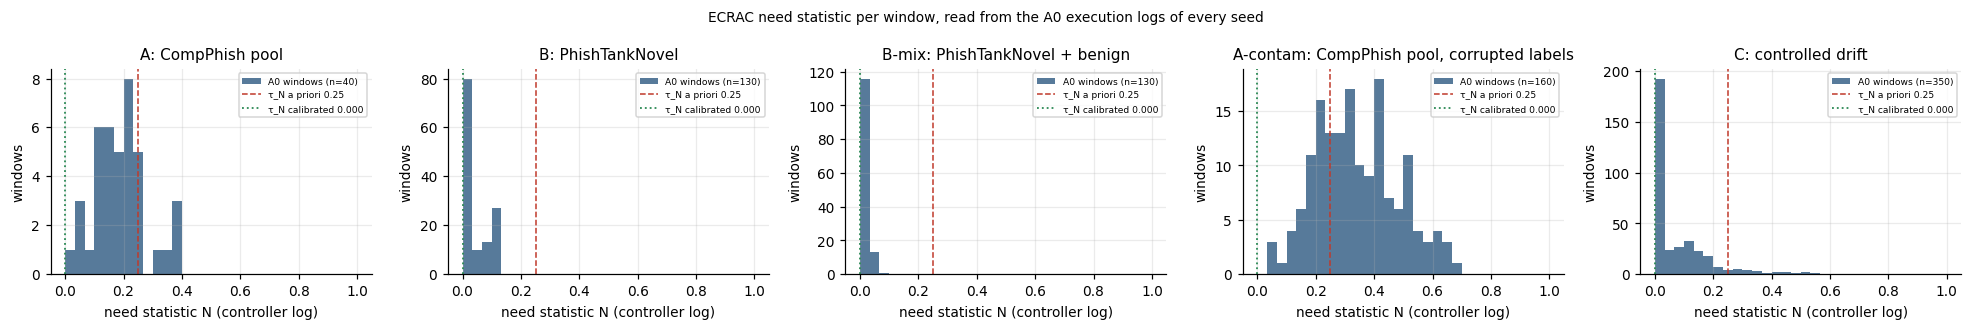

{"phase": "R12_ECRAC_ACCOUNTING", "status": "COMPLETED", "seconds": 4.9}


In [41]:
with rev_phase("R12_ECRAC_ACCOUNTING"):
    if len(ECRAC_SUM):
        bcols = [c for c in ECRAC_SUM.columns if c.startswith(("blocked::", "rejected_because::"))]
        E_ = ECRAC_SUM.copy(); E_[bcols] = E_[bcols].fillna(0)
        acc = E_.groupby(["track", "variant"]).agg(runs=("seed", "size"), windows=("windows", "sum"), attempted=("attempted_updates", "sum"),
                                                     committed=("update_count (commits)", "sum"), rejected=("rejected_updates", "sum"),
                                                     **{c: (c, "sum") for c in bcols}, tau_N=("tau_N_used", "first"),
                                                     forgetting_independent=("forgetting (max_k retain − final)", "mean"),
                                                     forgetting_ctrl=("forgetting_ctrl (retain partition read by the controller)", "mean"),
                                                     forgetting_ext=("forgetting_ext (PhreshTest external retention)", "mean")).reset_index()
        R12A = rev_save(acc, "R12_ecrac_update_accounting",
                        "ECRAC update accounting summed over runs: windows, attempted, committed and rejected updates, and why each window did not commit.",
                        ["track", "variant", "runs", "windows", "attempted", "committed", "rejected", "forgetting_independent"])
        display(R12A[R12A.variant.str.contains("ECRAC|A1|Naive|Frozen")].round(4))
        # ---- per-run listing (reviewer 3: which runs contribute to the score; FAR with and without zero-candidate runs) ----
        E_["score"] = E_.get("final_target_f1", pd.Series(np.nan, index=E_.index)).fillna(E_.get("prequential_mean_recall", pd.Series(np.nan, index=E_.index))).fillna(E_.get("prequential_mean_f1"))
        E_["score_source"] = np.where(E_.get("final_target_f1", pd.Series(np.nan, index=E_.index)).notna(), "final target F1 (CompPhish external test)",
                                      np.where(E_.get("prequential_mean_recall", pd.Series(np.nan, index=E_.index)).notna(), "prequential recall", "prequential F1"))
        runs = E_[["track", "scenario", "seed", "variant", "windows", "attempted_updates", "update_count (commits)", "rejected_updates", "false_adaptation_rate",
                   "score", "score_source", "forgetting (max_k retain − final)"]]
        rev_save(runs, "R12_ecrac_every_run")
        far = (E_.groupby(["track", "variant"]).apply(lambda g: pd.Series({"FAR (mean over all runs, 0 if no candidate)": g.false_adaptation_rate.mean(),
                                                                            "FAR (runs with ≥ 1 candidate only)": g[g.attempted_updates > 0].false_adaptation_rate.mean(),
                                                                            "runs with ≥ 1 candidate": int((g.attempted_updates > 0).sum()), "runs": len(g)})).reset_index())
        rev_save(far, "R12_ecrac_far_definitions", "False-adaptation rate with and without runs in which no update was attempted.")
        # ---- need statistic N, risk R and label-error excess L from the ACTUAL A0 / ECRAC-cal window logs (replaces the proxy of Fig. 9) ----
        LG = ECRAC_LOG[ECRAC_LOG.variant.isin(["ECRAC (A0 full)", "ECRAC-cal (tau_N calibrated on no-drift development windows)"])]
        need = LG.groupby(["track", "variant"]).agg(runs=("seed", "nunique"), windows=("window", "size"), N_mean=("N", "mean"), N_q95=("N", lambda v: np.quantile(v, .95)),
                                                     N_max=("N", "max"), share_N_ge_tau=("N", lambda v: float(np.mean(v >= CFG_E["tau_N"]))),
                                                     share_N_ge_tau_cal=("N", lambda v: float(np.mean(v >= TAU_N_CAL))),
                                                     share_R_ge_tau_R=("R", lambda v: float(np.mean(v >= CFG_E["tau_R"]))), share_L_pos=("L", lambda v: float(np.mean(v > 0)))).reset_index()
        rev_save(need, "R12_ecrac_need_statistic_from_logs",
                 f"Need statistic N from the controller's own per-window logs (tau_N a priori {CFG_E['tau_N']}, calibrated {TAU_N_CAL:.4f}).")
        display(need.round(4))
        tracks_ = list(LG.track.unique()); fig, ax = plt.subplots(1, len(tracks_), figsize=(3.6 * len(tracks_), 3.0), squeeze=False)
        for j, tr in enumerate(tracks_):
            a = ax[0, j]; g = LG[(LG.track == tr) & (LG.variant == "ECRAC (A0 full)")]
            a.hist(g.N.values, bins=30, range=(0, 1), color=PALETTE[0], alpha=.75, label=f"A0 windows (n={len(g)})")
            a.axvline(CFG_E["tau_N"], c=PALETTE[1], ls="--", lw=1, label=f"τ_N a priori {CFG_E['tau_N']}")
            a.axvline(TAU_N_CAL, c=PALETTE[2], ls=":", lw=1.2, label=f"τ_N calibrated {TAU_N_CAL:.3f}")
            a.set(title=tr, xlabel="need statistic N (controller log)", ylabel="windows"); a.legend(fontsize=6)
        fig.suptitle("ECRAC need statistic per window, read from the A0 execution logs of every seed", fontsize=9); fig.tight_layout(); savefig(fig, "rev_ecrac_need_from_A0_logs")
        # ---- window bookkeeping (reviewer 7: 31 / 156 / 282 did not reconcile) ----
        wb = ECRAC_LOG.groupby(["track", "variant"]).agg(runs=("seed", lambda v: len(set(zip(v, ECRAC_LOG.loc[v.index, "scenario"])))),
                                                          windows_logged=("window", "size")).reset_index()
        wb["windows per run"] = wb.windows_logged / wb.runs
        rev_save(wb, "R12_ecrac_window_bookkeeping", "Number of runs and logged windows per track and variant.")
        # ---- label budgets actually used ----
        rev_save(E_.groupby(["track", "variant"]).agg(labels_used_mean=("labels_used", "mean"), windows=("windows", "mean")).reset_index(),
                 "R12_ecrac_label_budgets", "Labels used per run (budget = fixed 20 % of the window; adaptive budget in [10 %, 30 %] driven by max(N_pre, M)).")

## R13 — Leave-one-corpus-out

In [42]:
with rev_phase("R13_LOCO_ALL_CORPORA"):
    from sklearn.feature_extraction.text import TfidfVectorizer as _Tfidf
    if REV["loco_all"]:
        CN = lambda f: f.dataset.map({"PhreshTrain": "PhreshPhish", "PhreshTest": "PhreshPhish"}).fillna(f.dataset)
        pool = [TRAIN, VAL] + [TEST[t] for t in TEST if t in TEST] + ([TRACK_A_TARGET] if TRACK_A_TARGET is not None else [])
        ALL_L = pd.concat([f.assign(source=CN(f).values) for f in pool], ignore_index=True)
        rows = []
        for held in sorted(ALL_L.source.unique()):
            tr_ = ALL_L[ALL_L.source != held].reset_index(drop=True); te = ALL_L[ALL_L.source == held]
            te = te[~te.normalized_url.isin(set(tr_.normalized_url)) & ~te.encoder_key.isin(set(tr_.encoder_key))].reset_index(drop=True)
            grp = tr_.registrable_domain.where(tr_.registrable_domain.ne(""), tr_.normalized_url)
            fit_i, val_i = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(tr_, tr_.source + "_" + tr_.label.astype(str), grp))
            F_, V_ = tr_.iloc[fit_i], tr_.iloc[val_i]; dsv = pd.factorize(V_.source)[0]; wf = cell_weights(pd.factorize(F_.source)[0], F_.label.values)
            scores = {}
            if lgb is not None:
                g_ = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.05, num_leaves=63, min_child_samples=40, subsample=0.8, subsample_freq=1,
                                        colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbose=-1)
                g_.fit(F_[P_COLS].to_numpy(np.float32), F_.label.values, sample_weight=wf, eval_set=[(V_[P_COLS].to_numpy(np.float32), V_.label.values)],
                       callbacks=[lgb.early_stopping(100, verbose=False)])
                scores["LightGBM (P)"] = (g_.predict(V_[P_COLS].to_numpy(np.float32), raw_score=True), g_.predict(te[P_COLS].to_numpy(np.float32), raw_score=True))
            vec = _Tfidf(analyzer="char", ngram_range=(3, 5), min_df=2, max_features=300000, sublinear_tf=True, dtype=np.float32)
            lr_ = LogisticRegression(max_iter=3000, C=4.0, solver="liblinear").fit(vec.fit_transform(F_.clean_encoder_url.values), F_.label.values, sample_weight=wf)
            scores["char 3-5-gram LR"] = (lr_.decision_function(vec.transform(V_.clean_encoder_url.values)), lr_.decision_function(vec.transform(te.clean_encoder_url.values)))
            ul = lambda f: np.log1p(f["feat::url::url_len"].fillna(0).values)[:, None]
            lu = LogisticRegression(max_iter=1000).fit(ul(F_), F_.label.values, sample_weight=wf)
            scores["Sanity: url_len only (LR)"] = (lu.decision_function(ul(V_)), lu.decision_function(ul(te)))
            for mname, (lv_, lt_) in scores.items():
                T_ = fit_temperature_weighted(lv_, V_.label.values.astype(float), cell_weights(dsv, V_.label.values))
                th = thresholds_from_val(V_.label.values, sigmoid(lv_ / T_), dsv); pt_ = sigmoid(lt_ / T_)
                for rule in ["val_mcc", "val_fpr@1%"]:
                    mm = metrics(te.label.values, pt_, th[rule])
                    rows.append({"held-out corpus": held, "trained on": ", ".join(sorted(tr_.source.unique())), "rows held out (after purge)": len(te), "model": mname,
                                 "threshold rule": rule, **{k: mm[k] for k in ["roc_auc", "pr_auc", "mcc", "recall", "fpr", "ece"]}})
            print(f"  LOCO held-out {held}: {len(te)} rows", flush=True)
        R13 = rev_save(pd.DataFrame(rows), "R13_loco_all_labelled_corpora",
                       "Leave-one-corpus-out over all labelled corpora (post-freeze analysis; test corpora rotated into development; light baselines only).",
                       ["held-out corpus", "model", "threshold rule", "roc_auc", "mcc", "recall", "fpr"])
        display(R13[R13["threshold rule"] == "val_fpr@1%"].round(4))

  LOCO held-out CompPhish: 13046 rows
  LOCO held-out Crawling2024: 44533 rows
  LOCO held-out D4v: 760 rows
  LOCO held-out Mendeley: 11190 rows
  LOCO held-out PhreshPhish: 395238 rows


,held-out corpus,trained on,rows held out (after purge),model,threshold rule,roc_auc,pr_auc,mcc,recall,fpr,ece
1,CompPhish,"Crawling2024, D4v, Mendeley, PhreshPhish",13046,LightGBM (P),val_fpr@1%,0.9279,0.9287,0.5562,0.4917,0.0140,0.0450
3,CompPhish,"Crawling2024, D4v, Mendeley, PhreshPhish",13046,char 3-5-gram LR,val_fpr@1%,0.9573,0.9625,0.7415,0.7267,0.0156,0.0160
5,CompPhish,"Crawling2024, D4v, Mendeley, PhreshPhish",13046,Sanity: url_len only (LR),val_fpr@1%,0.8631,0.8236,0.0670,0.0196,0.0050,0.2535
7,Crawling2024,"CompPhish, D4v, Mendeley, PhreshPhish",44533,LightGBM (P),val_fpr@1%,0.9006,0.8906,0.5929,0.6199,0.0637,0.0918
9,Crawling2024,"CompPhish, D4v, Mendeley, PhreshPhish",44533,char 3-5-gram LR,val_fpr@1%,0.9056,0.8912,0.6731,0.7369,0.0797,0.1004
11,Crawling2024,"CompPhish, D4v, Mendeley, PhreshPhish",44533,Sanity: url_len only (LR),val_fpr@1%,0.6584,0.5638,0.0327,0.0553,0.0413,0.1472
13,D4v,"CompPhish, Crawling2024, Mendeley, PhreshPhish",760,LightGBM (P),val_fpr@1%,0.8486,0.9230,0.5868,0.5841,0.0068,0.1681
15,D4v,"CompPhish, Crawling2024, Mendeley, PhreshPhish",760,char 3-5-gram LR,val_fpr@1%,0.9412,0.9441,0.6593,0.7134,0.0405,0.0374
17,D4v,"CompPhish, Crawling2024, Mendeley, PhreshPhish",760,Sanity: url_len only (LR),val_fpr@1%,0.9481,0.9639,0.0000,0.0000,0.0000,0.3321
19,Mendeley,"CompPhish, Crawling2024, D4v, PhreshPhish",11190,LightGBM (P),val_fpr@1%,0.8501,0.8182,0.3134,0.2630,0.0397,0.0882


{"phase": "R13_LOCO_ALL_CORPORA", "status": "COMPLETED", "seconds": 1487.0}


## R15–R18 — Post hoc comparison, robustness, LOCO, forward in time

In [43]:
# ============================================================
# v14 helpers for R16 / R17: build model inputs for a NEW frame with the frozen preprocessing (TRAIN-fitted normalization,
# fixed token schemas, same byte encoding) and temporarily swap the TRAIN / VALIDATION partitions (leave-one-corpus-out).
# ============================================================
def v14_register_frame(name, t):
    """SPLITS / PRE / STORE / WORDS entries for frame t (columns as in the cell 05–08 frames)."""
    t = model_frame(t.reset_index(drop=True)); SPLITS[name] = t
    Z = normalize_frame(t); ui, ul, mu = encode_urls(t.url.values); ri, rl, _ = encode_urls(t.original_url.values)
    ti, tv, tm, tn = feature_tokens(Z, t.corpus.values)
    PRE[name] = dict(url_ids=ui, url_len=ul, url_ids_raw=ri, url_len_raw=rl, m_url=mu, features=np.clip(np.nan_to_num(Z), -8, 8).astype(np.float16),
                     m_feat=np.isfinite(Z).any(1).astype(np.float32), ftok_idx=ti, ftok_val=tv, ftok_miss=tm, ftok_n=tn,
                     label=t.label.values.astype(np.float32), dataset=t.corpus.values, ds_id=t.corpus.map(DS2ID).values.astype(np.int64),
                     domain=t.registrable_domain.values)
    STORE[name] = {k: torch.from_numpy(np.ascontiguousarray(PRE[name][k])).to(STORE_DEVICE) for k in _TENSOR_KEYS}
    if "WORDS" in globals(): WORDS[name] = torch.from_numpy(_word_ids(t.url.values))
    globals().get("_HX", {}).pop(name, None)

def v14_add_split(name, base, rows, new_orig):
    """Rewritten URLs of `base` re-processed by the same pipeline (natives untouched -> portable models only)."""
    t = SPLITS[base].iloc[rows].copy().reset_index(drop=True); t["original_url"] = list(new_orig)
    t["normalized_url"] = t.original_url.map(canonicalize_url); t["hostname"] = t.normalized_url.map(hostname_of)
    t["registrable_domain"] = t.hostname.map(registrable_domain); t["clean_encoder_url"] = t.original_url.map(encoder_url)
    t["encoder_key"] = t.clean_encoder_url.str.lower(); t["path_depth"] = t.normalized_url.map(path_depth); t["is_root"] = t.path_depth.eq(0)
    cf = canonical_url_features(t.original_url.map(strip_monitoring).values); cf.index = t.index
    for c in cf.columns: t[c] = cf[c].values
    v14_register_frame(name, t)

def v14_drop_split(name):
    for dct in (SPLITS, PRE, STORE, globals().get("WORDS", {}), globals().get("_HX", {})): dct.pop(name, None)
    for k in [k for k in SCORES if k[1] == name]: SCORES.pop(k)

@contextlib.contextmanager
def v14_swap(fit_name, val_name):
    """TRAIN := fit_name and VALIDATION := val_name for the training functions (train_run, train_rev_nn); always restored."""
    g = globals(); keep = {k: g[k] for k in ["ytr_all", "wtr_all", "yv", "dv", "wv"]}
    parts = {k: tuple(dct.get(k) for dct in (SPLITS, PRE, STORE, WORDS)) for k in ["train", "val"]}
    try:
        for k, src in [("train", fit_name), ("val", val_name)]:
            SPLITS[k], PRE[k], STORE[k], WORDS[k] = SPLITS[src], PRE[src], STORE[src], WORDS[src]
        g["ytr_all"] = PRE["train"]["label"].astype(int); g["wtr_all"] = cell_weights(PRE["train"]["ds_id"], g["ytr_all"])
        g["yv"] = PRE["val"]["label"].astype(int); g["dv"] = PRE["val"]["ds_id"]; g["wv"] = cell_weights(g["dv"], g["yv"])
        yield
    finally:
        for k, (a, b, c, d) in parts.items(): SPLITS[k], PRE[k], STORE[k], WORDS[k] = a, b, c, d
        g.update(keep)
print("v14 helpers ready")


v14 helpers ready


### R15 — Post hoc comparison

In [44]:
with rev_phase("R15_V14_COMPARISON"):
    # v14: tuned models vs every baseline on every test set; paired domain-cluster bootstrap (Holm over the whole family);
    # "dimension" counts = (test set × metric) cells where A is better / worse; threshold rules compared (VALIDATION only).
    V14H = [m for m in globals().get("V14_HEADLINE", []) if m in MODEL_REG]
    if not V14H:
        raise RuntimeError("no v14 model registered (ADAPT_PHISH_V14=0?)")
    BASE_ALL = [m for m in dict.fromkeys(V14H + ["ADAPT-X stack (P)", "ADAPT-PHISH (P) seed-ens", "LightGBM (P) seed-ens", "char 3-5-gram LR"] + REV_HEADLINE)
                if m in MODEL_REG and not m.startswith("Sanity")]
    TR15 = pd.DataFrame(TEST_ROWS); TR15 = TR15[(TR15.subset == "ALL") & TR15.model.isin(BASE_ALL)]
    KEYS15 = ["roc_auc", "pr_auc", "mcc", "f1", "recall", "fpr", "precision@prev=0.01", "ece", "brier", "threshold"]
    R15M = rev_save(TR15[["dataset", "model", "family", "threshold_rule"] + KEYS15].assign(model=TR15.model.map(lambda m: SHORT_R.get(m, m))),
                    "R15_v14_test_metrics", None)
    # ---- 1. paired cluster bootstrap: ADAPT-X2 (P) vs every comparator, ADAPT-PHISH v2 vs the neural baselines ----
    A1, A2 = "ADAPT-X2 stack (P)", "ADAPT-PHISH v2 (P) seed-ens"
    PAIRS = [(A1, b) for b in BASE_ALL if b not in (A1, "ADAPT-X2 stack (E)", "ADAPT-PHISH v2 (E) seed-ens")]
    PAIRS += [(A2, b) for b in ["BiGRU tuned seed-ens", "URLNet tuned seed-ens", "BiGRU character model seed-ens", "URLNet-style char+word CNN seed-ens",
                                "ADAPT-PHISH (P) seed-ens", "LightGBM + n-grams tuned seed-ens", "char n-gram LR tuned"]
               + list(globals().get("PRETRAINED_NAMES", [])) if b in MODEL_REG]
    A3 = "ADAPT-PHISH v2-KD (P) seed-ens"
    if A3 in MODEL_REG:
        PAIRS += [(A3, b) for b in ["BiGRU-KD tuned seed-ens", "BiGRU tuned seed-ens", "URLNet tuned seed-ens", "LightGBM + n-grams tuned seed-ens",
                                    "char n-gram LR tuned", "ADAPT-PHISH v2 (P) seed-ens"] + list(globals().get("PRETRAINED_NAMES", [])) if b in MODEL_REG]
    rows = []
    for ds in TEST_NAMES:
        PS = PRED_STORE[ds]; y_ = PS.y.values.astype(float); g_ = PS.registrable_domain.values
        for a, b in PAIRS:
            if a not in PS or b not in PS: continue
            ci = cluster_bootstrap(y_, PS[a].values, g_, MODEL_REG[a]["thresholds"]["val_mcc"], B=B_REV, p_other=PS[b].values)
            for k in ["roc_auc", "pr_auc"]:
                f = roc_auc_score if k == "roc_auc" else average_precision_score
                d_ = f(y_, PS[a].values) - f(y_, PS[b].values); p1 = ci[f"p_delta_{k}<=0"]
                rows.append({"dataset": ds, "A": SHORT_R.get(a, a), "B": SHORT_R.get(b, b), "metric": k, "delta (A−B)": d_, "ci95": ci[f"delta_{k}"],
                             "p two-sided (bootstrap)": 1.0 if (d_ == 0 and tuple(ci[f"delta_{k}"]) == (0.0, 0.0))     # identical scores (v14.3 fix)
                                                        else float(min(1.0, 2 * min(p1, 1 - p1)))})
        print(f"  paired bootstrap {ds}: done", flush=True)
    P15 = pd.DataFrame(rows)
    if len(P15):
        p = P15["p two-sided (bootstrap)"].values; o = np.argsort(p); m_ = len(p); adj = np.empty(m_); run = 0.0
        for r, i in enumerate(o): run = max(run, min(1.0, (m_ - r) * p[i])); adj[i] = run
        P15["p Holm (whole family)"] = adj
        P15["verdict (Holm 0.05)"] = np.where(adj >= 0.05, "n.s.", np.where(P15["delta (A−B)"] > 0, "A better", "A worse"))
    P15 = rev_save(P15, "R15_v14_paired_tests", f"v14 paired domain-cluster bootstrap (B = {B_REV}); Holm over {len(P15)} comparisons.")
    # ---- 2. dimension counts: (test set × metric) cells, point estimates; AUC cells also with the Holm verdict ----
    DIMS = [("roc_auc", "val_mcc", +1), ("pr_auc", "val_mcc", +1), ("mcc", "val_mcc", +1), ("mcc", "val_minimax_mcc", +1),
            ("fpr", "val_fpr@1%", -1), ("recall", "val_fpr@1%", +1), ("fpr", "val_maxfpr@1%", -1), ("recall", "val_maxfpr@1%", +1),
            ("ece", "val_mcc", -1), ("brier", "val_mcc", -1)]
    TRp = pd.DataFrame(TEST_ROWS); TRp = TRp[TRp.model.isin(BASE_ALL)]
    def _val(m, ds, k, rule, subset="ALL"):
        r_ = TRp[(TRp.model == m) & (TRp.dataset == ds) & (TRp.subset == subset) & (TRp.threshold_rule == rule)]
        return float(r_[k].iloc[0]) if len(r_) and pd.notna(r_[k].iloc[0]) else np.nan
    win_rows = []
    for a, b in PAIRS:
        w = l = t = 0; sig_w = sig_l = 0; cells = []
        for ds in TEST_NAMES:
            for k, rule, sgn in DIMS:
                va, vb = _val(a, ds, k, rule), _val(b, ds, k, rule)
                if not (np.isfinite(va) and np.isfinite(vb)): continue
                dlt = sgn * (va - vb); res = "win" if dlt > 1e-4 else ("loss" if dlt < -1e-4 else "tie")
                w += res == "win"; l += res == "loss"; t += res == "tie"; cells.append(f"{ds}:{k}@{rule}={res}")
        if "PhishTank" in PRED_STORE and a in PRED_STORE["PhishTank"] and b in PRED_STORE["PhishTank"]:
            for rule in ["val_fpr@1%", "val_maxfpr@1%"]:
                va, vb = _val(a, "PhishTank", "recall", rule, "PhishTankNovel (primary)"), _val(b, "PhishTank", "recall", rule, "PhishTankNovel (primary)")
                if np.isfinite(va) and np.isfinite(vb):
                    res = "win" if va - vb > 1e-4 else ("loss" if va - vb < -1e-4 else "tie"); w += res == "win"; l += res == "loss"; t += res == "tie"
                    cells.append(f"PhishTankNovel:recall@{rule}={res}")
        sub15 = P15[(P15.A == SHORT_R.get(a, a)) & (P15.B == SHORT_R.get(b, b))] if len(P15) else pd.DataFrame()
        if len(sub15): sig_w = int((sub15["verdict (Holm 0.05)"] == "A better").sum()); sig_l = int((sub15["verdict (Holm 0.05)"] == "A worse").sum())
        win_rows.append({"A": SHORT_R.get(a, a), "B": SHORT_R.get(b, b), "dimensions": w + l + t, "A better": w, "A worse": l, "tie": t,
                         "share A better": w / max(1, w + l + t), "AUC cells significantly better (Holm)": sig_w,
                         "AUC cells significantly worse (Holm)": sig_l, "AUC cells tested": len(sub15), "cells": "; ".join(cells)})
    R15W = rev_save(pd.DataFrame(win_rows), "R15_v14_dimension_counts",
                    "Number of (test set × metric × threshold rule) cells in which A is better than B (point estimates) and AUC cells significant after Holm.",
                    ["A", "B", "dimensions", "A better", "A worse", "tie", "AUC cells significantly better (Holm)", "AUC cells significantly worse (Holm)"])
    display(R15W.drop(columns="cells").round(3))
    # ---- 3. threshold rules (VALIDATION-only): v13 macro rules vs v14 worst-corpus rules, external corpora ----
    rr = []
    for m in BASE_ALL:
        for ds in EXT3:
            for r1, r2 in [("val_mcc", "val_minimax_mcc"), ("val_fpr@1%", "val_maxfpr@1%")]:
                rr.append({"model": SHORT_R.get(m, m), "dataset": ds, "v13 rule": r1, "v14 rule": r2,
                           "FPR v13 rule": _val(m, ds, "fpr", r1), "FPR v14 rule": _val(m, ds, "fpr", r2),
                           "recall v13 rule": _val(m, ds, "recall", r1), "recall v14 rule": _val(m, ds, "recall", r2),
                           "MCC v13 rule": _val(m, ds, "mcc", r1), "MCC v14 rule": _val(m, ds, "mcc", r2)})
    rev_save(pd.DataFrame(rr), "R15_v14_threshold_rules", "External FPR / recall / MCC under the v13 (macro) and v14 (worst-corpus) VALIDATION rules.")
    # ---- 4. tuning record (every trial of every family, selected configurations) ----
    if len(globals().get("V14_TRIALS", [])):
        rev_save(pd.DataFrame(V14_TRIALS).drop(columns=[c for c in ["is_v13_default"] if c not in pd.DataFrame(V14_TRIALS)]), "R15_v14_tuning_trials",
                 None)
        rev_save(pd.DataFrame([{"family": f, "selected trial": v["trial"], "selected configuration": json.dumps(v["config"], default=str),
                                "VALIDATION worst-corpus ROC-AUC (short budget)": v["worst_corpus_roc_auc"], "score of the v13 default (trial 0)": v["default_score"],
                                "selected score": v["score"]} for f, v in V14_BEST.items()]), "R15_v14_selected_configs",
                 "Selected configuration of every family (equal number of trials; trial 0 = v13 default).")
    # ---- 5. stack weights ----
    rev_save(pd.DataFrame([{"stack": n, "C": MODEL_REG[n].get("meta_C"), **{SHORT_R.get(k, k): v for k, v in MODEL_REG[n]["meta_weights"].items()}}
                           for n in V14H if MODEL_REG[n]["kind"] == "stack"]), "R15_v14_stack_weights", None)


  paired bootstrap PhreshTest: done
  paired bootstrap Crawling2024: done
  paired bootstrap CompPhish: done
  paired bootstrap D4v: done


,A,B,dimensions,A better,A worse,tie,share A better,AUC cells significantly better (Holm),AUC cells significantly worse (Holm),AUC cells tested
0,ADAPT-X2 stack (P),ADAPT-PHISH v2 (P),42,25,16,1,0.595,2,2,8
1,ADAPT-X2 stack (P),BiGRU tuned,42,15,25,2,0.357,2,2,8
2,ADAPT-X2 stack (P),URLNet tuned,42,27,13,2,0.643,4,0,8
3,ADAPT-X2 stack (P),LightGBM (P) tuned,42,38,4,0,0.905,7,0,8
4,ADAPT-X2 stack (P),LightGBM + n-grams tuned,42,30,12,0,0.714,8,0,8
5,ADAPT-X2 stack (P),char n-gram LR tuned,42,31,11,0,0.738,6,0,8
6,ADAPT-X2 stack (P),"Baseline stack (P): tuned baselines, no ADAPT",42,14,23,5,0.333,2,2,8
7,ADAPT-X2 stack (P),ADAPT-PHISH v2-KD (P),42,18,22,2,0.429,2,2,8
8,ADAPT-X2 stack (P),BiGRU-KD tuned,42,20,19,3,0.476,2,2,8
9,ADAPT-X2 stack (P),ADAPT-X (P),42,16,26,0,0.381,0,4,8


{"phase": "R15_V14_COMPARISON", "status": "COMPLETED", "seconds": 1468.2}


### R16 — URL-rewrite robustness

In [45]:
with rev_phase("R16_OBFUSCATION_AND_IDN_ROBUSTNESS"):
    # v14 (reviewers asking for robustness to obfuscation / IDN): frozen portable models, frozen VALIDATION thresholds, test URLs
    # rewritten by deterministic perturbations and re-processed by the SAME pipeline (normalization, canonical features, byte
    # encoding). "none (pipeline re-run)" re-processes the unchanged URLs and must reproduce the stored scores (checked).
    if not V14["robustness"]:
        raise RuntimeError("disabled (ADAPT_PHISH_V14_ROBUSTNESS=0)")
    import unicodedata as _ud
    _HOMO = {"a": "а", "e": "е", "o": "о", "p": "р", "c": "с", "x": "х", "y": "у", "i": "і"}
    _rx = re.compile(r"^(?P<scheme>[a-zA-Z][a-zA-Z0-9+.\-]*://)?(?P<net>[^/?#]*)(?P<rest>.*)$", re.S)
    def _parts(u):
        m = _rx.match(u or ""); return (m.group("scheme") or ""), m.group("net"), m.group("rest")
    def p_idn(u, r_):
        s, net, rest = _parts(u); host = net.split("@")[-1].split(":")[0]; labels = host.split(".")
        if len(labels) < 2: return u
        j = len(labels) - 2; lab = labels[j]; pos = [k for k, ch in enumerate(lab) if ch.lower() in _HOMO]
        if not pos: return u
        lab2 = list(lab)
        for k in r_.choice(pos, min(2, len(pos)), replace=False): lab2[k] = _HOMO[lab2[k].lower()]
        try:
            labels[j] = "".join(lab2).encode("idna").decode("ascii")
        except Exception:
            return u
        return s + net.replace(host, ".".join(labels)) + rest
    def p_pct(u, r_):
        s, net, rest = _parts(u)
        out = "".join(f"%{ord(ch):02X}" if (ch.isalnum() and ch.isascii() and r_.random() < 0.3) else ch for ch in rest)
        return s + net + out
    def p_query(u, r_):
        s, net, rest = _parts(u); sep = "&" if "?" in rest else ("?" if rest else "/?")
        return s + net + rest + sep + "ref=home&lang=en&page=1"
    def p_case(u, r_):
        s, net, rest = _parts(u)
        return s + net + "".join(ch.upper() if (ch.isalpha() and r_.random() < 0.5) else ch for ch in rest)
    def p_userinfo(u, r_):
        s, net, rest = _parts(u); return s + "accounts.google.com@" + net + rest
    def p_hostonly(u, r_):
        s, net, rest = _parts(u); return s + net
    PERTURB = {"none (pipeline re-run)": lambda u, r_: u, "IDN homoglyph host (punycode)": p_idn, "percent-encoded path characters": p_pct,
               "extra query parameters": p_query, "random case in path": p_case, "userinfo prefix (@ trick)": p_userinfo,
               "host only (path removed)": p_hostonly}

    ROB_MODELS = [m for m in dict.fromkeys(V14_HEADLINE + ["ADAPT-X stack (P)", "ADAPT-PHISH (P) seed-ens", "LightGBM (P) seed-ens", "char 3-5-gram LR"]
                                          + REV_HEADLINE) if m in MODEL_REG and MODEL_REG[m].get("view", "P") == "P" and not m.startswith("Sanity")]
    N_ROB = int(os.environ.get("ADAPT_PHISH_V14_ROBUST_N", 8000)); rows = []; PSTORE = {}
    ADAPTIVE_SET = ["IDN homoglyph host (punycode)", "percent-encoded path characters", "extra query parameters", "random case in path",
                    "userinfo prefix (@ trick)"]          # page-preserving rewrites (host-only removal changes the page and is excluded)
    for ds in [d for d in ["PhreshTest", "CompPhish", "Crawling2024"] if d in SPLITS]:
        yb = SPLITS[ds].label.values.astype(int); r0 = np.random.default_rng(SEED)
        pick = np.sort(np.concatenate([r0.choice(np.where(yb == c)[0], min(N_ROB // 2, int((yb == c).sum())), replace=False) for c in (0, 1)]))
        base_urls = SPLITS[ds].original_url.values[pick]
        for pname, fn in PERTURB.items():
            r_ = np.random.default_rng(SEED + 7); new = [fn(str(u), r_) for u in base_urls]
            changed = float(np.mean([a != b for a, b in zip(new, base_urls)]))
            sp = f"rob::{ds}::{pname}"; v14_add_split(sp, ds, pick, new); y_ = PRE[sp]["label"].astype(int)
            for m in ROB_MODELS:
                p_ = prob(m, sp); PSTORE[(ds, m, pname)] = p_
                if pname.startswith("none"):
                    ref = PRED_STORE[ds][m].values[pick]
                    integrity(f"R16 pipeline re-run reproduces the stored scores ({ds}, {SHORT_R.get(m, m)})", float(np.max(np.abs(p_ - ref))) < 1e-4,
                              f"max |Δp| = {float(np.max(np.abs(p_ - ref))):.2e}", fatal=False)
                for rule in ["val_mcc", "val_fpr@1%", "val_maxfpr@1%"]:
                    mm = metrics(y_, p_, MODEL_REG[m]["thresholds"][rule])
                    rows.append({"dataset": ds, "perturbation": pname, "share of URLs changed": changed, "model": SHORT_R.get(m, m), "threshold rule": rule,
                                 "n": len(y_), **{k: mm[k] for k in ["roc_auc", "recall", "fpr", "mcc"]}})
            v14_drop_split(sp); gc.collect()
            print(f"  R16 {ds} | {pname}: {changed:.1%} of URLs changed", flush=True)
        # adaptive black-box attacker (v14): for EVERY phishing URL and EACH model separately, the attacker queries the model on the
        # page-preserving rewrites and keeps the one with the lowest score (worst case over 5 queries + the original URL)
        for m in ROB_MODELS:
            P0 = PSTORE[(ds, m, "none (pipeline re-run)")]; cand = np.column_stack([P0] + [PSTORE[(ds, m, q)] for q in ADAPTIVE_SET])
            p_adv = np.where(y_ == 1, cand.min(1), P0)              # legitimate URLs are left unchanged
            for rule in ["val_mcc", "val_fpr@1%", "val_maxfpr@1%"]:
                mm = metrics(y_, p_adv, MODEL_REG[m]["thresholds"][rule])
                rows.append({"dataset": ds, "perturbation": "ADAPTIVE: per-model worst of 5 page-preserving rewrites (phishing only)",
                             "share of URLs changed": float(np.mean(cand[y_ == 1].argmin(1) > 0)), "model": SHORT_R.get(m, m), "threshold rule": rule,
                             "n": len(y_), **{k: mm[k] for k in ["roc_auc", "recall", "fpr", "mcc"]}})
        PSTORE = {k: v for k, v in PSTORE.items() if k[0] != ds}
    R16 = pd.DataFrame(rows)
    ref16 = R16[R16.perturbation.str.startswith("none")].set_index(["dataset", "model", "threshold rule"])
    for k in ["roc_auc", "recall", "fpr"]:
        R16[f"Δ{k} vs unperturbed"] = [r[k] - ref16[k].get((r["dataset"], r["model"], r["threshold rule"]), np.nan) for _, r in R16.iterrows()]
    R16 = rev_save(R16, "R16_obfuscation_idn_robustness",
                   "Frozen portable models on rewritten test URLs (same pipeline, VALIDATION thresholds); Δ against the unperturbed URLs.",
                   ["dataset", "perturbation", "model", "threshold rule", "roc_auc", "recall", "fpr", "Δrecall vs unperturbed", "Δfpr vs unperturbed"])
    display(R16[R16["threshold rule"] == "val_fpr@1%"].pivot_table(index=["dataset", "model"], columns="perturbation", values="Δrecall vs unperturbed").round(3))


predict rob::PhreshTest::none (pipeline re-run):   0%|          | 0/8 [00:00<?, ?it/s]

predict rob::PhreshTest::none (pipeline re-run):   0%|          | 0/8 [00:00<?, ?it/s]

predict rob::PhreshTest::none (pipeline re-run):   0%|          | 0/8 [00:00<?, ?it/s]

predict rob::PhreshTest::none (pipeline re-run):   0%|          | 0/8 [00:00<?, ?it/s]

predict rob::PhreshTest::none (pipeline re-run):   0%|          | 0/8 [00:00<?, ?it/s]

  [PASS] R16 pipeline re-run reproduces the stored scores (PhreshTest, ADAPT-X2 stack (P)) max |Δp| = 2.17e-08
  [PASS] R16 pipeline re-run reproduces the stored scores (PhreshTest, ADAPT-PHISH v2 (P)) max |Δp| = 0.00e+00
  [PASS] R16 pipeline re-run reproduces the stored scores (PhreshTest, BiGRU tuned) max |Δp| = 8.32e-08
  [PASS] R16 pipeline re-run reproduces the stored scores (PhreshTest, URLNet tuned) max |Δp| = 7.19e-08
  [PASS] R16 pipeline re-run reproduces the stored scores (PhreshTest, LightGBM (P) tuned) max |Δp| = 0.00e+00
  [PASS] R16 pipeline re-run reproduces the stored scores (PhreshTest, LightGBM + n-grams tuned) max |Δp| = 0.00e+00
  [PASS] R16 pipeline re-run reproduces the stored scores (PhreshTest, char n-gram LR tuned) max |Δp| = 0.00e+00
  [PASS] R16 pipeline re-run reproduces the stored scores (PhreshTest, Baseline stack (P): tuned baselines, no ADAPT) max |Δp| = 3.50e-08


... (334 outputs left out)

predict rob::Crawling2024::host only (path removed):   0%|          | 0/8 [00:00<?, ?it/s]

  R16 Crawling2024 | host only (path removed): 95.9% of URLs changed


perturbation                                                     ADAPTIVE: per-model worst of 5 page-preserving rewrites (phishing only)  \
dataset      model                                                                                                                         
CompPhish    ADAPT-PHISH (P)                                                                                -0.112                         
             ADAPT-PHISH v2 (P)                                                                             -0.096                         
             ADAPT-PHISH v2-KD (P)                                                                          -0.094                         
             ADAPT-X (P)                                                                                    -0.094                         
             ADAPT-X2 stack (P)                                                                             -0.080                         
             Baseline stack (P): tuned baselines, no ADAPT                                                  -0.093                         
             BiGRU character model                                                                          -0.134                         
             BiGRU tuned                                                                                    -0.135                         
             BiGRU-KD tuned                                                                                 -0.092                         
             LightGBM (P)                                                                                   -0.081                         
             LightGBM (P) + hashed char n-grams                                                             -0.109                         
             LightGBM (P) tuned                                                                             -0.088                         
             LightGBM + n-grams tuned                                                                       -0.104                         
             Pretrained google/bert_uncased_L-4_H-256_A-4 (f...                                             -0.442                         
             Pretrained google/canine-s (fine-tuned)                                                        -0.396                         
             Simple stack (P): LightGBM + char-LR, no neural                                                -0.100                         
             URLNet tuned                                                                                   -0.397                         
             URLNet-style char+word CNN                                                                     -0.402                         
             char n-gram LR tuned                                                                           -0.133                         
             char-LR                                                                                        -0.313                         
Crawling2024 ADAPT-PHISH (P)                                                                                -0.174                         
             ADAPT-PHISH v2 (P)                                                                             -0.112                         
             ADAPT-PHISH v2-KD (P)                                                                          -0.130                         
             ADAPT-X (P)                                                                                    -0.171                         
             ADAPT-X2 stack (P)                                                                             -0.098                         
             Baseline stack (P): tuned baselines, no ADAPT                                                  -0.104                         
             BiGRU character model                                              

{"phase": "R16_OBFUSCATION_AND_IDN_ROBUSTNESS", "status": "COMPLETED", "seconds": 1945.9}


### R17 — LOCO with neural models

In [46]:
with rev_phase("R17_LOCO_ALL_CORPORA_NEURAL"):
    # v14: leave-one-corpus-out over every labelled corpus WITH the neural models (reviewer 7). Identical pools, purge and
    # fit / validation partition as R13 (StratifiedGroupKFold by registrable domain, seed 42), so the rows are directly
    # comparable with the R13 light baselines. One seed, the leave-one-out budget of cell 13 (PSEUDO_EPOCHS x PSEUDO_EPOCH_SAMPLES)
    # for every neural model, the v14-selected configurations, VALIDATION-only temperature and thresholds.
    if not (V14["loco_neural"] and REV["loco_all"]):
        raise RuntimeError("disabled (ADAPT_PHISH_V14_LOCO_NEURAL=0 or ADAPT_PHISH_REV_LOCO_ALL=0)")
    from sklearn.model_selection import StratifiedGroupKFold
    CN = lambda f: f.dataset.map({"PhreshTrain": "PhreshPhish", "PhreshTest": "PhreshPhish"}).fillna(f.dataset)
    pool = [TRAIN, VAL] + [TEST[t] for t in TEST] + ([TRACK_A_TARGET] if TRACK_A_TARGET is not None else [])
    ALL_L = pd.concat([f.assign(source=CN(f).values) for f in pool], ignore_index=True)
    LOCO_B = {"epochs": PSEUDO_EPOCHS, "epoch_samples": PSEUDO_EPOCH_SAMPLES, "patience": PSEUDO_EPOCHS}
    s0 = MODEL_SEEDS[0]; rows = []
    for held in sorted(ALL_L.source.unique()):
        tr_ = ALL_L[ALL_L.source != held].reset_index(drop=True); te = ALL_L[ALL_L.source == held]
        te = te[~te.normalized_url.isin(set(tr_.normalized_url)) & ~te.encoder_key.isin(set(tr_.encoder_key))].reset_index(drop=True)
        grp = tr_.registrable_domain.where(tr_.registrable_domain.ne(""), tr_.normalized_url)
        fit_i, val_i = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(tr_, tr_.source + "_" + tr_.label.astype(str), grp))
        v14_register_frame("loco_fit", tr_.iloc[fit_i]); v14_register_frame("loco_val", tr_.iloc[val_i]); v14_register_frame("loco_test", te)
        yV, dV = PRE["loco_val"]["label"].astype(int), PRE["loco_val"]["ds_id"]; wV = cell_weights(dV, yV); yT = PRE["loco_test"]["label"].astype(int)
        lg = {}
        with v14_swap("loco_fit", "loco_val"):
            tag = re.sub(r"[^A-Za-z0-9]+", "_", held)
            m_, i_ = train_run(f"v14loco_adapt_v2_{tag}", {**V2_CFG, **LOCO_B}, s0, verbose=False)
            lg["ADAPT-PHISH v2 (P)"] = (predict(m_, "loco_val", view="P", cfg=i_["cfg"])["logit"], predict(m_, "loco_test", view="P", cfg=i_["cfg"])["logit"]); del m_
            m_, i_ = train_run(f"v14loco_adapt_v13_{tag}", dict(LOCO_B), s0, verbose=False)
            lg["ADAPT-PHISH v13 config (P)"] = (predict(m_, "loco_val", view="P", cfg=i_["cfg"])["logit"], predict(m_, "loco_test", view="P", cfg=i_["cfg"])["logit"]); del m_
            for kind, cfg_ in [("BiGRU", BIGRU_CFG), ("URLNet", URLNET_CFG)]:
                m_, i_ = train_rev_nn(f"v14loco {kind} {tag}", _ctor(kind, cfg_), s0, lr=cfg_["lr"], alpha=cfg_["alpha"], wd=cfg_["wd"], ema=cfg_.get("ema", 0.0),
                                      epochs=LOCO_B["epochs"], epoch_samples=LOCO_B["epoch_samples"], patience=LOCO_B["patience"])
                lg[f"{kind} tuned"] = (_nn_predict(m_, "loco_val"), _nn_predict(m_, "loco_test")); del m_
        for mname, (lv_, lt_) in lg.items():
            T_ = fit_temperature_weighted(lv_, yV.astype(float), wV); th = thresholds_from_val(yV, sigmoid(lv_ / T_), dV); pt_ = sigmoid(lt_ / T_)
            for rule in ["val_mcc", "val_fpr@1%", "val_minimax_mcc", "val_maxfpr@1%"]:
                mm = metrics(yT, pt_, th[rule])
                rows.append({"held-out corpus": held, "trained on": ", ".join(sorted(tr_.source.unique())), "rows held out (after purge)": len(te),
                             "model": mname, "threshold rule": rule, **{k: mm[k] for k in ["roc_auc", "pr_auc", "mcc", "recall", "fpr", "ece"]}})
        # the stack of the neural members (meta-learner fitted on the LOCO validation part only)
        Xv = np.column_stack([lg[k][0] for k in lg if k != "ADAPT-PHISH v13 config (P)"]); Xt = np.column_stack([lg[k][1] for k in lg if k != "ADAPT-PHISH v13 config (P)"])
        meta = LogisticRegression(C=1.0, max_iter=2000).fit(Xv, yV, sample_weight=wV); lv_, lt_ = meta.decision_function(Xv), meta.decision_function(Xt)
        T_ = fit_temperature_weighted(lv_, yV.astype(float), wV); th = thresholds_from_val(yV, sigmoid(lv_ / T_), dV)
        for rule in ["val_mcc", "val_fpr@1%", "val_minimax_mcc", "val_maxfpr@1%"]:
            mm = metrics(yT, sigmoid(lt_ / T_), th[rule])
            rows.append({"held-out corpus": held, "trained on": ", ".join(sorted(tr_.source.unique())), "rows held out (after purge)": len(te),
                         "model": "neural stack (ADAPT v2 + BiGRU + URLNet)", "threshold rule": rule, **{k: mm[k] for k in ["roc_auc", "pr_auc", "mcc", "recall", "fpr", "ece"]}})
        for nm in ["loco_fit", "loco_val", "loco_test"]: v14_drop_split(nm)
        gc.collect(); print(f"  R17 held-out {held}: {len(te)} rows", flush=True)
    R17 = pd.DataFrame(rows)
    if "R13_loco_all_labelled_corpora" in REV_TABLES:
        R17 = pd.concat([REV_TABLES["R13_loco_all_labelled_corpora"], R17], ignore_index=True)
    R17 = rev_save(R17, "R17_loco_all_corpora_with_neural",
                   "Leave-one-corpus-out over all labelled corpora: R13 light baselines + neural models (one seed, leave-one-out budget).",
                   ["held-out corpus", "model", "threshold rule", "roc_auc", "mcc", "recall", "fpr"])
    display(R17[R17["threshold rule"] == "val_fpr@1%"].pivot_table(index="model", columns="held-out corpus", values="roc_auc").round(4))


v14loco_adapt_v2_CompPhish s42 ep1:   0%|          | 0/702 [00:00<?, ?it/s]

[v14loco_adapt_v2_CompPhish s42 ep1] first batch 0.8s -> epoch ETA ~9.4 min (702 batches)


val:   0%|          | 0/94 [00:00<?, ?it/s]

v14loco_adapt_v2_CompPhish s42 ep2:   0%|          | 0/702 [00:00<?, ?it/s]

[v14loco_adapt_v2_CompPhish s42 ep2] first batch 0.8s -> epoch ETA ~9.4 min (702 batches)


val:   0%|          | 0/94 [00:00<?, ?it/s]

... (777 outputs left out)

predict loco_test:   0%|          | 0/386 [00:00<?, ?it/s]

[v14loco BiGRU PhreshPhish s42] ep 01 | loss 0.2974 | val macro-corpus AUC 0.8626 ★
[v14loco BiGRU PhreshPhish s42] ep 02 | loss 0.1338 | val macro-corpus AUC 0.8833 ★
[v14loco BiGRU PhreshPhish s42] ep 03 | loss 0.0937 | val macro-corpus AUC 0.9054 ★
[v14loco BiGRU PhreshPhish s42] ep 04 | loss 0.0865 | val macro-corpus AUC 0.9282 ★
[v14loco BiGRU PhreshPhish s42] ep 05 | loss 0.0690 | val macro-corpus AUC 0.9469 ★
[v14loco BiGRU PhreshPhish s42] ep 06 | loss 0.0641 | val macro-corpus AUC 0.9592 ★
[v14loco BiGRU PhreshPhish s42] ep 07 | loss 0.0491 | val macro-corpus AUC 0.9667 ★
[v14loco BiGRU PhreshPhish s42] ep 08 | loss 0.0415 | val macro-corpus AUC 0.9716 ★
[v14loco BiGRU PhreshPhish s42] ep 09 | loss 0.0340 | val macro-corpus AUC 0.9744 ★
[v14loco BiGRU PhreshPhish s42] ep 10 | loss 0.0308 | val macro-corpus AUC 0.9758 ★
[v14loco BiGRU PhreshPhish s42] ep 11 | loss 0.0256 | val macro-corpus AUC 0.9765 ★
[v14loco BiGRU PhreshPhish s42] ep 12 | loss 0.0227 | val macro-corpus AUC 0

held-out corpus,CompPhish,Crawling2024,D4v,Mendeley,PhreshPhish
model,,,,,
ADAPT-PHISH v13 config (P),0.9498,0.9279,0.9458,0.8818,0.9125
ADAPT-PHISH v2 (P),0.9665,0.9159,0.9226,0.9190,0.9298
BiGRU tuned,0.9674,0.9076,0.9754,0.9101,0.9259
LightGBM (P),0.9279,0.9006,0.8486,0.8501,0.9205
Sanity: url_len only (LR),0.8631,0.6584,0.9481,0.6613,0.3283
URLNet tuned,0.9582,0.8717,0.9642,0.8684,0.9073
char 3-5-gram LR,0.9573,0.9056,0.9412,0.8967,0.9179
neural stack (ADAPT v2 + BiGRU + URLNet),0.9762,0.9173,0.9715,0.9277,0.9367


{"phase": "R17_LOCO_ALL_CORPORA_NEURAL", "status": "COMPLETED", "seconds": 140483.6}


### R18 — Forward in time

In [47]:
with rev_phase("R18_FORWARD_IN_TIME_PHRESHPHISH"):
    # v14 (R1 1.5, R2 2.3, R6 6.7, R8 8.5, M8: forward-in-time evaluation WITH contemporaneous legitimate traffic).
    # The official PhreshPhish release dates every row of BOTH classes (column `date`). Our PhreshTest rows are joined on the URL
    # to those dates (url/date columns only, read over HTTP from the pinned release commit; cached in cache/phreshphish_dates.csv,
    # or supplied with ADAPT_PHISH_PHRESH_DATES=<csv url,date>). Part 1: frozen models per calendar week (both classes, so FPR and
    # recall per window). Part 2: ECRAC Track D on the same time-ordered windows (rows of the independent retention set excluded).
    _dates_f = Path(os.environ.get("ADAPT_PHISH_PHRESH_DATES", D["cache"] / "phreshphish_dates.csv"))
    if not _dates_f.exists():
        import pyarrow.parquet as _pq
        from huggingface_hub import HfApi as _HfApi, HfFileSystem as _HfFS
        _REPO, _REVP = "phreshphish/phreshphish", "eca603e0ecd4f698f8d4d226c088659e72681239"
        _fs = _HfFS(); _parts = []
        for f in sorted(f for f in _HfApi().list_repo_files(_REPO, repo_type="dataset", revision=_REVP) if f.endswith(".parquet") and "/test-" not in f):
            with _fs.open(f"datasets/{_REPO}@{_REVP}/{f}", "rb", block_size=2 ** 22) as fh:
                _parts.append(_pq.ParquetFile(fh).read(columns=["url", "date"]).to_pandas())
        pd.concat(_parts, ignore_index=True).drop_duplicates("url").to_csv(_dates_f, index=False)
    DT = pd.read_csv(_dates_f).drop_duplicates("url").set_index("url")["date"]
    pt = SPLITS["PhreshTest"]; ts_t = pd.to_datetime(pt.original_url.map(DT), errors="coerce", utc=True)
    tr_ph = SPLITS["train"][SPLITS["train"].dataset == "PhreshTrain"]; ts_tr = pd.to_datetime(tr_ph.original_url.map(DT), errors="coerce", utc=True)
    span = pd.DataFrame([{"set": n, "rows": len(x), "dated": int(x.notna().sum()), "first": x.min(), "last": x.max(), "median": x.median(),
                          "share later than the last TRAIN date": float((x > ts_tr.max()).mean()) if n != "PhreshTrain (TRAIN)" else np.nan}
                         for n, x in [("PhreshTrain (TRAIN)", ts_tr), ("PhreshTest", ts_t)]])
    rev_save(span.astype({"first": str, "last": str, "median": str}), "R18_phreshphish_date_ranges", "Dates of the PhreshPhish rows (official release, both classes).")
    display(span)
    wk = ts_t.dt.to_period("W-MON").astype(str).where(ts_t.notna()); cnt = wk.value_counts()
    valid = sorted(cnt[cnt >= int(os.environ.get("ADAPT_PHISH_R18_MIN_WINDOW", 200))].index)
    MODELS_T = [m for m in dict.fromkeys(V14_HEADLINE + ["ADAPT-X stack (P)", "ADAPT-PHISH (P) seed-ens", "LightGBM (P) seed-ens", "char 3-5-gram LR"] + REV_HEADLINE)
                if m in PRED_STORE["PhreshTest"] and not m.startswith("Sanity")]
    yT = pt.label.values.astype(int); rows = []
    for w_ in valid:
        idx = np.where(wk.values == w_)[0]; yw = yT[idx]
        for m in MODELS_T:
            pw = PRED_STORE["PhreshTest"][m].values[idx]
            for rule in ["val_mcc", "val_fpr@1%", "val_maxfpr@1%"]:
                pr = pw >= MODEL_REG[m]["thresholds"][rule]
                rows.append({"window (week)": w_, "n": len(idx), "phishing": int(yw.sum()), "model": SHORT_R.get(m, m), "threshold rule": rule,
                             "recall": float(pr[yw == 1].mean()) if (yw == 1).any() else np.nan, "fpr": float(pr[yw == 0].mean()) if (yw == 0).any() else np.nan,
                             "roc_auc": roc_auc_score(yw, pw) if len(np.unique(yw)) > 1 else np.nan})
    R18W = rev_save(pd.DataFrame(rows), "R18_forward_in_time_frozen_per_week",
                    "Frozen models on PhreshTest ordered by date (weekly windows, both classes, VALIDATION thresholds).",
                    ["window (week)", "n", "model", "threshold rule", "recall", "fpr", "roc_auc"])
    if len(R18W):
        R18W["t"] = R18W.groupby(["model", "threshold rule"])["window (week)"].rank(method="dense")
        slope = R18W.groupby(["model", "threshold rule"]).apply(lambda g: pd.Series({
            "weeks": int(g.t.nunique()), "recall slope / week": float(np.polyfit(g.t, g.recall, 1)[0]) if g.recall.notna().sum() > 2 else np.nan,
            "fpr slope / week": float(np.polyfit(g.t, g.fpr, 1)[0]) if g.fpr.notna().sum() > 2 else np.nan,
            "recall first→last": f"{g.recall.iloc[0]:.3f}→{g.recall.iloc[-1]:.3f}", "fpr first→last": f"{g.fpr.iloc[0]:.3f}→{g.fpr.iloc[-1]:.3f}"}), include_groups=False).reset_index()
        rev_save(slope, "R18_forward_in_time_trend", "Linear trend of recall / FPR over the weekly windows (frozen models).")
    # ---- Part 2: ECRAC Track D (time-ordered, both classes); independent retention rows (_rb) never enter the stream ----
    if len(valid) >= 3 and "base_model" in globals():
        excl = set(globals().get("_rb", np.array([], int)).tolist()); cap = int(os.environ.get("ADAPT_PHISH_R18_WINDOW_CAP", 1000)); WD = []
        for j, w_ in enumerate(valid):
            idx = np.array([i for i in np.where(wk.values == w_)[0] if i not in excl])
            if len(idx) < 50: continue
            idx = np.sort(np.random.default_rng(SEED + j).choice(idx, min(cap, len(idx)), replace=False)); WD.append(encode_rows("PhreshTest", idx))
        D_VARIANTS = [v for v in ["Frozen (static)", "Naive (periodic fine-tuning = A8)", "Drift + Replay", "ECRAC (A0 full)",
                                  "ECRAC-cal (tau_N calibrated on no-drift development windows)"] if v in VARIANTS]
        DS_, DL_ = [], []
        for s in ECRAC_SEEDS[:3]:
            for v in D_VARIANTS:
                L_, S_, _ = run_stream(WD, v, s, "D: PhreshTest forward-in-time (both classes)", "weekly windows (official release dates)")
                DS_.append(S_); DL_.append(L_)
        DSUM = pd.DataFrame(DS_); pd.concat(DL_, ignore_index=True).to_csv(REVD / "R18_trackD_window_log.csv.gz", index=False, compression="gzip")
        keep = [c for c in DSUM.columns if c in ("variant", "seed", "windows") or c.startswith(("prequential", "forward_transfer", "update_count", "false_adaptation",
                                                                                                    "retain", "final_", "rollback", "quarantine"))]
        rev_save(DSUM[keep], "R18_trackD_ecrac_forward_in_time", "ECRAC Track D: PhreshTest rows in date order, weekly windows, both classes.")
        display(DSUM[keep].groupby("variant").mean(numeric_only=True).round(4))


,set,rows,dated,first,last,median,share later than the last TRAIN date
0,PhreshTrain (TRAIN),248233,248232,2024-07-02 00:00:00+00:00,2025-09-08 00:00:00+00:00,2024-09-28 00:00:00+00:00,NaN
1,PhreshTest,96319,96319,2024-07-02 00:00:00+00:00,2025-09-08 00:00:00+00:00,2024-09-28 00:00:00+00:00,0.0


,seed,windows,prequential_mean_f1,forward_transfer (preq − static),final_retain_macro_f1,final_retain_test_macro_f1,update_count (commits),rollback_rate,false_adaptation_rate,quarantine_rate
variant,,,,,,,,,,
Drift + Replay,729.6667,52.0,0.9145,0.0147,0.8948,0.9155,52.0000,0.000,0.1474,0.0
ECRAC (A0 full),729.6667,52.0,0.8999,0.0000,0.8837,0.9027,0.0000,1.000,0.0000,0.0
ECRAC-cal (tau_N calibrated on no-drift development windows),729.6667,52.0,0.9054,0.0055,0.8835,0.9011,44.6667,0.141,0.2179,0.0
Frozen (static),729.6667,52.0,0.8999,0.0000,0.8837,0.9027,0.0000,0.000,0.0000,0.0
Naive (periodic fine-tuning = A8),729.6667,52.0,0.8938,-0.0061,0.8952,0.9091,52.0000,0.000,0.4808,0.0


{"phase": "R18_FORWARD_IN_TIME_PHRESHPHISH", "status": "COMPLETED", "seconds": 412.3}


## R16b–R21 — Additional analyses

### R16b — Extended rewrite search

In [48]:
with rev_phase("R16b_ADAPTIVE_REWRITE_ATTACK"):
    # Complement run (reviewers 5, 8): adaptive black-box evasion. For EVERY phishing URL and EACH frozen model separately, the attacker
    # queries the model on the five page-preserving rewrites of R16 (IDN homoglyph, percent-encoding, extra query, random case, userinfo
    # prefix) and keeps the rewrite with the LOWEST score (worst case over 5 queries + the original). Legitimate URLs are unchanged.
    # Same rows (seed), same frozen thresholds as R16.
    ADAPTIVE_SET = ["IDN homoglyph host (punycode)", "percent-encoded path characters", "extra query parameters", "random case in path",
                    "userinfo prefix (@ trick)"]
    N_ROB = int(os.environ.get("ADAPT_PHISH_V14_ROBUST_N", 8000)); rows = []
    for ds in [d for d in ["PhreshTest", "CompPhish", "Crawling2024"] if d in SPLITS]:
        yb = SPLITS[ds].label.values.astype(int); r0 = np.random.default_rng(SEED)
        pick = np.sort(np.concatenate([r0.choice(np.where(yb == c)[0], min(N_ROB // 2, int((yb == c).sum())), replace=False) for c in (0, 1)]))
        base_urls = SPLITS[ds].original_url.values[pick]; y_ = yb[pick]; PS = {}
        for pname in ADAPTIVE_SET:
            r_ = np.random.default_rng(SEED + 7); new = [PERTURB[pname](str(u), r_) for u in base_urls]
            sp = f"adv::{ds}::{pname}"; v14_add_split(sp, ds, pick, new)
            for m in ROB_MODELS: PS[(m, pname)] = prob(m, sp)
            v14_drop_split(sp); gc.collect()
        for m in ROB_MODELS:
            P0 = PRED_STORE[ds][m].values[pick]
            cand = np.column_stack([P0] + [PS[(m, q)] for q in ADAPTIVE_SET])
            p_adv = np.where(y_ == 1, cand.min(1), P0); best = cand.argmin(1)
            for rule in ["val_mcc", "val_fpr@1%", "val_maxfpr@1%"]:
                thr = MODEL_REG[m]["thresholds"][rule]; m0 = metrics(y_, P0, thr); m1 = metrics(y_, p_adv, thr)
                rows.append({"dataset": ds, "model": SHORT_R.get(m, m), "threshold rule": rule, "n": len(y_),
                             "recall before": m0["recall"], "recall after attack": m1["recall"], "Δrecall": m1["recall"] - m0["recall"],
                             "roc_auc before": m0["roc_auc"], "roc_auc after attack": m1["roc_auc"], "Δroc_auc": m1["roc_auc"] - m0["roc_auc"],
                             "share of phishing URLs whose best rewrite changed the score": float(np.mean(best[y_ == 1] > 0)),
                             "evaded (detected before, missed after)": float(np.mean((P0 >= thr)[y_ == 1] & (p_adv < thr)[y_ == 1]))})
        print(f"  R16b {ds}: done", flush=True)
    R16B = rev_save(pd.DataFrame(rows), "R16b_adaptive_rewrite_attack",
                    "Adaptive black-box attacker: per model, worst of five page-preserving rewrites for each phishing URL (frozen thresholds).",
                    ["dataset", "model", "threshold rule", "recall before", "recall after attack", "Δroc_auc", "evaded (detected before, missed after)"])
    display(R16B[R16B["threshold rule"] == "val_fpr@1%"].round(3))


{"phase": "R16b_ADAPTIVE_REWRITE_ATTACK", "status": "FAILED", "error": "TypeError(\"'list' object is not callable\")"}
Traceback (most recent call last):
  File "C:\Users\MES\AppData\Local\Temp\ipykernel_2464\3885140682.py", line 20, in rev_phase
    yield
  File "C:\Users\MES\AppData\Local\Temp\ipykernel_2464\2232765511.py", line 14, in <module>
    r_ = np.random.default_rng(SEED + 7); new = [PERTURB[pname](str(u), r_) for u in base_urls]
  File "C:\Users\MES\AppData\Local\Temp\ipykernel_2464\2232765511.py", line 14, in <listcomp>
    r_ = np.random.default_rng(SEED + 7); new = [PERTURB[pname](str(u), r_) for u in base_urls]
  File "C:\Users\MES\AppData\Local\Temp\ipykernel_2464\1723782169.py", line 13, in p_idn
    s, net, rest = _parts(u); host = net.split("@")[-1].split(":")[0]; labels = host.split(".")
TypeError: 'list' object is not callable



### R18b — Date-based re-split

In [49]:
with rev_phase("R18b_TEMPORAL_SPLIT_PHRESHPHISH"):
    # Complement run (R1 1.5, R2 2.3, R6 6.7, R8 8.5, M8): a FORWARD-IN-TIME evaluation with contemporaneous legitimate traffic.
    # The official PhreshPhish release dates every row of both classes; our PhreshPhish rows (TRAIN, VALIDATION, PhreshTest) span
    # 2024-07 to 2025-09 in every partition, so the main split is not temporal. Here the PhreshPhish rows are re-split by date: models are
    # trained on rows dated before the 70% date quantile (domain-grouped internal validation split for epochs, temperature and thresholds)
    # and tested on the later rows (both classes), after purging every later row whose normalized URL or model input occurs earlier.
    # Reference: the same models tested on a random, domain-disjoint held-out part of the EARLY period (same size), so the
    # difference measures temporal decay. One seed; leave-one-out budget for the neural models; v14-selected configurations.
    from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
    from sklearn.feature_extraction.text import TfidfVectorizer as _Tf
    DTf = Path(os.environ.get("ADAPT_PHISH_PHRESH_DATES", D["cache"] / "phreshphish_dates.csv"))
    if not DTf.exists(): raise RuntimeError("dates not available: run R18 first (it caches the official dates)")
    DT = pd.read_csv(DTf).drop_duplicates("url").set_index("url")["date"]
    PH = pd.concat([f[f.dataset.isin(["PhreshTrain", "PhreshTest"])] for f in [TRAIN, VAL, TEST["PhreshTest"]]], ignore_index=True)
    PH["date"] = pd.to_datetime(PH.original_url.map(DT), errors="coerce", utc=True); PH = PH[PH.date.notna()].reset_index(drop=True)
    cut = PH.date.quantile(0.70)
    early, late = PH[PH.date < cut].reset_index(drop=True), PH[PH.date >= cut].reset_index(drop=True)
    late = late[~late.normalized_url.isin(set(early.normalized_url)) & ~late.encoder_key.isin(set(early.encoder_key))].reset_index(drop=True)
    late["domain_seen_early"] = late.registrable_domain.isin(set(early.registrable_domain))
    grp = early.registrable_domain.where(early.registrable_domain.ne(""), early.normalized_url)
    tr_i, ho_i = next(GroupShuffleSplit(1, test_size=min(0.2, len(late) / len(early)), random_state=SEED).split(early, groups=grp))
    E_tr, E_ho = early.iloc[tr_i].reset_index(drop=True), early.iloc[ho_i].reset_index(drop=True)
    g2 = E_tr.registrable_domain.where(E_tr.registrable_domain.ne(""), E_tr.normalized_url)
    fit_i, val_i = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(E_tr, E_tr.label.astype(str), g2))
    F_, V_ = E_tr.iloc[fit_i], E_tr.iloc[val_i]
    for nm, fr in [("tmp_fit", F_), ("tmp_val", V_), ("tmp_hold", E_ho), ("tmp_late", late)]: v14_register_frame(nm, fr)
    yV, dV = PRE["tmp_val"]["label"].astype(int), PRE["tmp_val"]["ds_id"]; wV = cell_weights(dV, yV)
    LB = {"epochs": PSEUDO_EPOCHS, "epoch_samples": PSEUDO_EPOCH_SAMPLES, "patience": PSEUDO_EPOCHS}; s0 = MODEL_SEEDS[0]; lg = {}
    with v14_swap("tmp_fit", "tmp_val"):
        m_, i_ = train_run("r18b_adapt", {**V2_CFG, **LB}, s0, verbose=False)
        lg["ADAPT-Net (P)"] = {k: predict(m_, sp, view="P", cfg=i_["cfg"])["logit"] for k, sp in [("val", "tmp_val"), ("hold", "tmp_hold"), ("late", "tmp_late")]}; del m_
        for kind, cfg_ in [("BiGRU", BIGRU_CFG), ("URLNet", URLNET_CFG)]:
            m_, i_ = train_rev_nn(f"r18b {kind}", _ctor(kind, cfg_), s0, lr=cfg_["lr"], alpha=cfg_["alpha"], wd=cfg_["wd"],
                                  epochs=LB["epochs"], epoch_samples=LB["epoch_samples"], patience=LB["patience"])
            lg[f"{kind}, tuned"] = {k: _nn_predict(m_, sp) for k, sp in [("val", "tmp_val"), ("hold", "tmp_hold"), ("late", "tmp_late")]}; del m_
    Xf = lambda f: f.reindex(columns=P_COLS).to_numpy(np.float32)
    if lgb is not None:
        g_ = lgb.LGBMClassifier(n_estimators=3000, subsample_freq=1, random_state=s0, n_jobs=-1, verbose=-1, **LGBP_CFG)
        g_.fit(Xf(F_), F_.label.values, eval_set=[(Xf(V_), V_.label.values)], callbacks=[lgb.early_stopping(100, verbose=False)])
        lg["LightGBM (P), tuned"] = {k: g_.predict(Xf(f), raw_score=True) for k, f in [("val", V_), ("hold", E_ho), ("late", late)]}
    vec = _Tf(analyzer="char", ngram_range=tuple(LR_CFG["ngram"]), min_df=LR_CFG["min_df"], max_features=LR_CFG["max_features"], sublinear_tf=True, dtype=np.float32)
    lr_ = LogisticRegression(max_iter=3000, C=LR_CFG["C"], solver="liblinear").fit(vec.fit_transform(F_.clean_encoder_url.values), F_.label.values)
    lg["Char-LR, tuned"] = {k: lr_.decision_function(vec.transform(f.clean_encoder_url.values)) for k, f in [("val", V_), ("hold", E_ho), ("late", late)]}
    nn_keys = [k for k in ["ADAPT-Net (P)", "BiGRU, tuned", "URLNet, tuned"] if k in lg]
    meta = LogisticRegression(C=1.0, max_iter=2000).fit(np.column_stack([lg[k]["val"] for k in lg]), yV)
    lg["Stack of all models"] = {k: meta.decision_function(np.column_stack([lg[m][k] for m in [x for x in lg if x != "Stack of all models"]])) for k in ["val", "hold", "late"]}
    rows = []
    sub_late = {"later period, all rows": np.ones(len(late), bool), "later period, domains unseen before": ~late.domain_seen_early.values}
    for mname, L in lg.items():
        T_ = fit_temperature_weighted(L["val"], yV.astype(float), wV); th = thresholds_from_val(yV, sigmoid(L["val"] / T_), dV)
        for setn, yS, pS, masks in [("early period, held-out domains (random)", E_ho.label.values.astype(int), sigmoid(L["hold"] / T_), {"all": np.ones(len(E_ho), bool)}),
                                    ("later period", late.label.values.astype(int), sigmoid(L["late"] / T_), sub_late)]:
            for sn, mk in masks.items():
                for rule in ["val_mcc", "val_fpr@1%"]:
                    mm = metrics(yS[mk], pS[mk], th[rule])
                    rows.append({"test set": setn if sn == "all" else sn, "rows": int(mk.sum()), "model": mname, "threshold rule": rule,
                                 **{k: mm[k] for k in ["roc_auc", "pr_auc", "mcc", "recall", "fpr", "ece"]}})
    R18B = pd.DataFrame(rows)
    meta_rows = [{"test set": "period boundary", "rows": len(early), "model": f"train/early before {cut.date()}, later from {cut.date()} to {late.date.max().date()}",
                  "threshold rule": f"later rows after purge {len(late)} (phishing {int(late.label.sum())}); unseen-domain {int((~late.domain_seen_early).sum())}"}]
    R18B = rev_save(pd.concat([pd.DataFrame(meta_rows), R18B], ignore_index=True), "R18b_temporal_split_phreshphish",
                    "Forward-in-time evaluation: PhreshPhish re-split by the official dates (train on the earlier 70%, test on the later rows, both classes).",
                    ["test set", "rows", "model", "threshold rule", "roc_auc", "recall", "fpr"])
    display(R18B.round(4))
    for nm in ["tmp_fit", "tmp_val", "tmp_hold", "tmp_late"]: v14_drop_split(nm)
    gc.collect()


r18b_adapt s42 ep1:   0%|          | 0/330 [00:00<?, ?it/s]

[r18b_adapt s42 ep1] first batch 0.9s -> epoch ETA ~5.0 min (330 batches)


val:   0%|          | 0/49 [00:00<?, ?it/s]

r18b_adapt s42 ep2:   0%|          | 0/330 [00:00<?, ?it/s]

[r18b_adapt s42 ep2] first batch 0.5s -> epoch ETA ~3.0 min (330 batches)


val:   0%|          | 0/49 [00:00<?, ?it/s]

... (72 outputs left out)

predict tmp_late:   0%|          | 0/118 [00:00<?, ?it/s]

[r18b BiGRU s42] ep 01 | loss 0.1817 | val macro-corpus AUC 0.9879 ★
[r18b BiGRU s42] ep 02 | loss 0.0966 | val macro-corpus AUC 0.9913 ★
[r18b BiGRU s42] ep 03 | loss 0.0781 | val macro-corpus AUC 0.9913
[r18b BiGRU s42] ep 04 | loss 0.0652 | val macro-corpus AUC 0.9884
[r18b BiGRU s42] ep 05 | loss 0.0578 | val macro-corpus AUC 0.9905
[r18b BiGRU s42] ep 06 | loss 0.0497 | val macro-corpus AUC 0.9890
[r18b BiGRU s42] ep 07 | loss 0.0436 | val macro-corpus AUC 0.9738
[r18b BiGRU s42] ep 08 | loss 0.0374 | val macro-corpus AUC 0.9718
[r18b BiGRU s42] ep 09 | loss 0.0346 | val macro-corpus AUC 0.9779
[r18b BiGRU s42] ep 10 | loss 0.0294 | val macro-corpus AUC 0.9807
[r18b BiGRU s42] ep 11 | loss 0.0268 | val macro-corpus AUC 0.9864
[r18b BiGRU s42] ep 12 | loss 0.0255 | val macro-corpus AUC 0.9861
[r18b BiGRU s42] ep 13 | loss 0.0245 | val macro-corpus AUC 0.9902
[r18b BiGRU s42] ep 14 | loss 0.0219 | val macro-corpus AUC 0.9876
[r18b BiGRU s42] ep 15 | loss 0.0187 | val macro-corpus AU

,test set,rows,model,threshold rule,roc_auc,pr_auc,mcc,recall,fpr,ece
0,period boundary,275784,"train/early before 2025-02-02, later from 2025...",later rows after purge 120338 (phishing 47019)...,NaN,NaN,NaN,NaN,NaN,NaN
1,"early period, held-out domains (random)",57244,ADAPT-Net (P),val_mcc,0.9650,0.9738,0.7351,0.7593,0.0250,0.0968
2,"early period, held-out domains (random)",57244,ADAPT-Net (P),val_fpr@1%,0.9650,0.9738,0.6931,0.6893,0.0085,0.0968
3,"later period, all rows",120338,ADAPT-Net (P),val_mcc,0.9367,0.9377,0.7836,0.7680,0.0227,0.0579
4,"later period, all rows",120338,ADAPT-Net (P),val_fpr@1%,0.9367,0.9377,0.7526,0.6985,0.0078,0.0579
5,"later period, domains unseen before",62739,ADAPT-Net (P),val_mcc,0.9138,0.9561,0.6906,0.7583,0.0469,0.1042
6,"later period, domains unseen before",62739,ADAPT-Net (P),val_fpr@1%,0.9138,0.9561,0.6540,0.6823,0.0151,0.1042
7,"early period, held-out domains (random)",57244,"BiGRU, tuned",val_mcc,0.9509,0.9628,0.7020,0.7453,0.0441,0.1243
8,"early period, held-out domains (random)",57244,"BiGRU, tuned",val_fpr@1%,0.9509,0.9628,0.6892,0.6887,0.0114,0.1243
9,"later period, all rows",120338,"BiGRU, tuned",val_mcc,0.9303,0.9328,0.7815,0.7879,0.0351,0.0620


{"phase": "R18b_TEMPORAL_SPLIT_PHRESHPHISH", "status": "COMPLETED", "seconds": 9135.5}


### R19 — URLTran-style BERT-mini

In [50]:
with rev_phase("R19_URLTRAN_STYLE_BERT"):
    # Complement run (reviewers 1, 4, 7: pretrained URL language models). URLTran (Maneriker et al., 2021) fine-tunes a BERT model on URL
    # strings; on CPU we fine-tune the 4-layer, 256-dim BERT of Turc et al. (google/bert_uncased_L-4_H-256_A-4, ~11 M parameters) with its
    # WordPiece tokenizer. Same TRAIN rows, cell weights, corpus-tempered sampling, epoch selection on VALIDATION (macro-corpus ROC-AUC),
    # temperature and the three threshold rules from VALIDATION (register). Trained AFTER the freeze, so it is a post hoc model: the test sets
    # never influence it (no selection on them), and it is reported separately. Resumable per epoch.
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    PNAME = os.environ.get("ADAPT_PHISH_URLTRAN_NAME", "google/bert_uncased_L-4_H-256_A-4")
    EPOCHS_U, ROWS_U, MAXLEN_U, LR_U = int(os.environ.get("ADAPT_PHISH_URLTRAN_EPOCHS", 3)), int(os.environ.get("ADAPT_PHISH_URLTRAN_ROWS", len(SPLITS["train"]) if DEVICE.type == "cuda" else 60000)), 128, 5e-5
    BS_U = 128 if DEVICE.type == "cuda" else 32
    tokU = AutoTokenizer.from_pretrained(PNAME); s = MODEL_SEEDS[0]; seed_everything(s)
    mU = AutoModelForSequenceClassification.from_pretrained(PNAME, num_labels=1).to(DEVICE)
    def _u_pred(model, split, rows=None, bs=256):
        model.eval(); u = SPLITS[split].url.values; u = u if rows is None else u[np.asarray(rows)]; out = []
        with torch.inference_mode():
            for b0 in range(0, len(u), bs):
                enc = tokU(list(u[b0:b0 + bs]), truncation=True, max_length=MAXLEN_U, padding=True, return_tensors="pt").to(DEVICE)
                out.append(mU(**enc).logits[:, 0].float().cpu())
        return torch.cat(out).numpy() if out else np.zeros(0)
    ck = D["checkpoints"] / "r19_urltran_style" / f"seed_{s}"; ck.mkdir(parents=True, exist_ok=True)
    st = json.loads((ck / "info.json").read_text()) if (ck / "info.json").exists() else {}
    ep0, best = int(st.get("epochs_done", 0)), float(st.get("best", -1)); best_state = None
    if ep0 and (ck / "last.pt").exists():
        mU.load_state_dict(torch.load(ck / "last.pt", map_location=DEVICE)); best_state = torch.load(ck / "best.pt", map_location="cpu")
    U_tr = SPLITS["train"].url.values; p_pick = tempered_weights(PRE["train"]["dataset"], SAMPLING_ALPHA); sel = _selection_rows(s)
    yT_ = PRE["train"]["label"].astype(int); wT_ = cell_weights(PRE["train"]["ds_id"], yT_)
    opt = torch.optim.AdamW(mU.parameters(), lr=LR_U, weight_decay=0.01); t0 = time.perf_counter()
    for ep in range(ep0, EPOCHS_U):
        mU.train(); order = np.random.default_rng(s * 1000 + ep).choice(len(U_tr), ROWS_U, replace=True, p=p_pick)
        for b0 in range(0, ROWS_U, BS_U):
            idx = order[b0:b0 + BS_U]
            enc = tokU(list(U_tr[idx]), truncation=True, max_length=MAXLEN_U, padding=True, return_tensors="pt").to(DEVICE)
            y_ = torch.as_tensor(yT_[idx], dtype=torch.float32, device=DEVICE); w_ = torch.as_tensor(wT_[idx], dtype=torch.float32, device=DEVICE)
            loss = (F.binary_cross_entropy_with_logits(mU(**enc).logits[:, 0], y_, reduction="none") * w_).sum() / w_.sum()
            opt.zero_grad(set_to_none=True); loss.backward(); torch.nn.utils.clip_grad_norm_(mU.parameters(), 1.0); opt.step()
        sc = macro_corpus_roc_auc(yv[sel], sigmoid(_u_pred(mU, "val", sel)), dv[sel]); print(f"[{PNAME}] epoch {ep + 1}: val macro-corpus AUC {sc:.4f}", flush=True)
        if sc > best: best, best_state = sc, {k: v.detach().cpu().clone() for k, v in mU.state_dict().items()}
        torch.save(best_state, ck / "best.pt"); torch.save(mU.state_dict(), ck / "last.pt")
        (ck / "info.json").write_text(json.dumps({"epochs_done": ep + 1, "best": best, "train_seconds": float(st.get("train_seconds", 0)) + time.perf_counter() - t0}))
    mU.load_state_dict(best_state); mU.eval()
    NM_U = "URLTran-style BERT-mini (fine-tuned, post hoc)"
    register(NM_U, "rev_hf", _u_pred(mU, "val"), "pretrained", True, obj=mU, tok=tokU, view="P", seed=s)
    _hf_predict_prev = globals().get("_hf_predict")
    def _hf_predict(model, tok, split, rows=None, bs=256):          # dispatch: the URLTran-style model uses its own tokenizer settings
        if model is mU: return _u_pred(model, split, rows, bs)
        return _hf_predict_prev(model, tok, split, rows) if _hf_predict_prev else None
    rows = []
    CMP = [NM_U, "BiGRU tuned seed-ens", "Pretrained google/canine-s (fine-tuned)", "ADAPT-PHISH v2 (P) seed-ens", "ADAPT-X2 stack (P)"]
    for ds in [d for d in ["PhreshTest", "Crawling2024", "CompPhish", "D4v"] if d in SPLITS]:
        y_ = SPLITS[ds].label.values.astype(int); pU = prob(NM_U, ds)
        for m in CMP:
            if m not in MODEL_REG: continue
            p_ = pU if m == NM_U else PRED_STORE[ds][m].values
            for rule in ["val_mcc", "val_fpr@1%"]:
                mm = metrics(y_, p_, MODEL_REG[m]["thresholds"][rule])
                rows.append({"dataset": ds, "model": SHORT_R.get(m, m), "threshold rule": rule, **{k: mm[k] for k in ["roc_auc", "pr_auc", "mcc", "recall", "fpr", "ece"]}})
        ci = cluster_bootstrap(y_.astype(float), pU, SPLITS[ds].registrable_domain.values, MODEL_REG[NM_U]["thresholds"]["val_mcc"], B=B_REV,
                               p_other=PRED_STORE[ds]["BiGRU tuned seed-ens"].values)
        rows.append({"dataset": ds, "model": "Δ ROC-AUC URLTran-style − BiGRU tuned (95% domain-cluster CI)", "threshold rule": "--",
                     "roc_auc": float(roc_auc_score(y_, pU) - roc_auc_score(y_, PRED_STORE[ds]["BiGRU tuned seed-ens"].values)), "pr_auc": np.nan, "mcc": np.nan, "recall": np.nan, "fpr": np.nan, "ece": np.nan,
                     "ci95": ci["delta_roc_auc"]})
    if "phishtank" in SPLITS:
        nov = SPLITS["phishtank"].novel.values; pU = prob(NM_U, "phishtank")
        for rule in ["val_mcc", "val_fpr@1%"]:
            rows.append({"dataset": "PhishTankNovel", "model": SHORT_R.get(NM_U, NM_U), "threshold rule": rule,
                         "recall": float((pU[nov] >= MODEL_REG[NM_U]["thresholds"][rule]).mean())})
    info = json.loads((ck / "info.json").read_text())
    rows.append({"dataset": "training", "model": NM_U, "threshold rule": f"{EPOCHS_U} epochs x {ROWS_U} rows, max length {MAXLEN_U}, lr {LR_U}, seed {s}",
                 "roc_auc": info["best"], "fpr": info["train_seconds"] / 60, "mcc": float(sum(p.numel() for p in mU.parameters()))})
    R19 = rev_save(pd.DataFrame(rows), "R19_urltran_style_bert", "URLTran-style fine-tuned BERT-mini (post hoc) against the strongest models.",
                   ["dataset", "model", "threshold rule", "roc_auc", "pr_auc", "mcc", "recall", "fpr"])
    display(R19.round(4))


Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/bert_uncased_L-4_H-256_A-4
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	thos

[google/bert_uncased_L-4_H-256_A-4] epoch 1: val macro-corpus AUC 0.9709
[google/bert_uncased_L-4_H-256_A-4] epoch 2: val macro-corpus AUC 0.9645
[google/bert_uncased_L-4_H-256_A-4] epoch 3: val macro-corpus AUC 0.9657


,dataset,model,threshold rule,roc_auc,pr_auc,mcc,recall,fpr,ece,ci95
0,PhreshTest,"URLTran-style BERT-mini (fine-tuned, post hoc)",val_mcc,0.9843,0.9839,8.684000e-01,0.9227,0.0550,0.0341,NaN
1,PhreshTest,"URLTran-style BERT-mini (fine-tuned, post hoc)",val_fpr@1%,0.9843,0.9839,7.951000e-01,0.7791,0.0072,0.0341,NaN
2,PhreshTest,BiGRU tuned,val_mcc,0.9878,0.9873,8.856000e-01,0.9303,0.0456,0.0167,NaN
3,PhreshTest,BiGRU tuned,val_fpr@1%,0.9878,0.9873,7.800000e-01,0.7567,0.0045,0.0167,NaN
4,PhreshTest,Pretrained google/canine-s (fine-tuned),val_mcc,0.9930,0.9931,9.243000e-01,0.9577,0.0336,0.0410,NaN
5,PhreshTest,Pretrained google/canine-s (fine-tuned),val_fpr@1%,0.9930,0.9931,8.383000e-01,0.8239,0.0027,0.0410,NaN
6,PhreshTest,ADAPT-PHISH v2 (P),val_mcc,0.9878,0.9875,8.813000e-01,0.9456,0.0639,0.0149,NaN
7,PhreshTest,ADAPT-PHISH v2 (P),val_fpr@1%,0.9878,0.9875,7.752000e-01,0.7500,0.0040,0.0149,NaN
8,PhreshTest,ADAPT-X2 stack (P),val_mcc,0.9932,0.9929,9.117000e-01,0.9633,0.0511,0.0128,NaN
9,PhreshTest,ADAPT-X2 stack (P),val_fpr@1%,0.9932,0.9929,8.036000e-01,0.7813,0.0019,0.0128,NaN


{"phase": "R19_URLTRAN_STYLE_BERT", "status": "COMPLETED", "seconds": 859.6}


### R20 — ECRAC re-tuned on development streams

In [51]:
with rev_phase("R20_ECRAC_RETUNED_ON_DEVELOPMENT_STREAMS"):
    # Complement run (reviewer 7, M8: "re-tune ECRAC on separate streams"). The controller's trigger (tau_N) and the evidence-consistency
    # switch (A0 vs A1) are selected on DEVELOPMENT streams only, built from the VALIDATION calibration partition (retain_cal), which no
    # evaluation track uses: no drift, an abrupt and a gradual corpus shift (Mendeley -> PhreshPhish rows) and a class-prior shift, ten
    # windows of 400 rows, three seeds. Criterion (fixed before the search): mean forward transfer (prequential F1 − frozen) minus
    # forgetting on the controller's retention partition. The selected configuration is then run once on Tracks A, B-mix, B and C with the
    # five stream seeds and compared with the frozen, naive, A0 and ECRAC-cal policies of Table 15.
    Ec = EMB["retain_cal"]; corp = np.asarray(PRE["val"]["dataset"])[Ec["rows"]]
    def dev_windows(kind, seed, K=10, n=400):
        r = np.random.default_rng(seed); iM, iP = np.where(corp == "Mendeley")[0], np.where(corp != "Mendeley")[0]; allr = np.arange(len(Ec["y"]))
        def take(pool, m, share=None):
            if share is None: return r.choice(pool, m, replace=len(pool) < m)
            pos, neg = pool[Ec["y"][pool] == 1], pool[Ec["y"][pool] == 0]; k1 = int(round(m * share))
            return np.concatenate([r.choice(pos, k1, replace=len(pos) < k1), r.choice(neg, m - k1, replace=len(neg) < m - k1)])
        W = []
        for t in range(K):
            if kind == "no_drift": idx = take(allr, n)
            elif kind == "abrupt_corpus": idx = take(iM if t < K // 2 else iP, n)
            elif kind == "gradual_corpus": a = t / (K - 1); k = int(round(a * n)); idx = np.concatenate([take(iM, n - k), take(iP, k)]) if 0 < k < n else take(iM if k == 0 else iP, n)
            else: idx = take(allr, n, share=[0.5, 0.4, 0.3, 0.2, 0.1, 0.1, 0.2, 0.3, 0.4, 0.5][t])
            W.append(sub(Ec, np.sort(idx)))
        return W
    DEV = ["no_drift", "abrupt_corpus", "gradual_corpus", "class_prior"]; DSEEDS = [11, 12, 13]
    Nq = TAU_CAL_LOG.N.values
    GRID_T = sorted({round(float(x), 6) for x in [TAU_N_CAL, np.quantile(Nq, 0.90) + 1e-9, np.quantile(Nq, 0.99) + 1e-9, 0.05, 0.10, CFG_E["tau_N"]]})
    BASES = {"A0": "ECRAC (A0 full)", "A1": "A1 − evidence consistency"}
    rows = []
    for bname, base in BASES.items():
        for tn in GRID_T:
            vname = f"DEV-SEARCH {bname} tau_N={tn:.4f}"; VARIANTS[vname] = {**VARIANTS[base], "tau_N_value": tn}
            J = []
            for kind in DEV:
                for s in DSEEDS:
                    _, S_, _ = run_stream(dev_windows(kind, s), vname, s, "DEV: retune", kind)
                    J.append(S_["forward_transfer (preq − static)"] - (S_.get("forgetting_ctrl (retain partition read by the controller)") or 0.0))
                    rows.append({"base": bname, "tau_N": tn, "scenario": kind, "seed": s, "forward_transfer": S_["forward_transfer (preq − static)"],
                                 "forgetting_ctrl": S_.get("forgetting_ctrl (retain partition read by the controller)"), "commits": S_["update_count (commits)"]})
            del VARIANTS[vname]
            print(f"  dev search {bname} tau_N={tn:.4f}: J = {np.mean(J):+.4f}", flush=True)
    DEVR = pd.DataFrame(rows); DEVR["J"] = DEVR.forward_transfer - DEVR.forgetting_ctrl.fillna(0)
    SEL = DEVR.groupby(["base", "tau_N"]).J.mean().idxmax(); print("selected on development streams:", SEL)
    VT = f"ECRAC-dev (tuned on development streams: {SEL[0]}, tau_N={SEL[1]:.4f})"; VARIANTS[VT] = {**VARIANTS[BASES[SEL[0]]], "tau_N_value": SEL[1]}
    out = []
    for s in ECRAC_SEEDS:
        if "trackA_pool" in EMB and "CompPhish" in EMB:
            _, S_, _ = run_stream(windows_by_domain(EMB["trackA_pool"], CFG_E["n_windows_A"], s), VT, s, "A: CompPhish pool", "real (domain-grouped windows)", target_E=EMB["CompPhish"]); out.append(S_)
        if "wins" in globals() and len(wins) >= 3:
            _, S_, _ = run_stream([sub(EMB["phishtank"], w) for w in wins], VT, s, "B: PhishTankNovel", "prequential", positive_only=True); out.append(S_)
            if "benign_pool_B" in EMB:
                r_b = np.random.default_rng(s + 500); pool = np.arange(len(EMB["benign_pool_B"]["y"])); r_b.shuffle(pool); pos_ = 0; WBM2 = []
                for w in wins:
                    w = np.sort(r_b.choice(w, min(len(w), CFG_E["bmix_max_phish"]), replace=False)); k = int(round(len(w) * CFG_E["bmix_neg_ratio"]))
                    take = pool[pos_: pos_ + k]; pos_ += k; WBM2.append(cat(sub(EMB["phishtank"], w), sub(EMB["benign_pool_B"], take)))
                _, S_, _ = run_stream(WBM2, VT, s, "B-mix: PhishTankNovel + benign", "prequential"); out.append(S_)
        for sc in SCENARIOS_RUN:
            _, S_, _ = run_stream(scenario_windows(sc, s), VT, s, "C: controlled drift", sc, target_E=EMB.get("CompPhish") if sc not in ("no_drift", "class_prior") else None); out.append(S_)
    OUT = pd.concat([ECRAC_SUM[ECRAC_SUM.variant.isin(["Frozen (static)", "Naive (periodic fine-tuning = A8)", "ECRAC (A0 full)",
                                                       "ECRAC-cal (tau_N calibrated on no-drift development windows)"])], pd.DataFrame(out)], ignore_index=True)
    keep = [c for c in ["final_target_f1", "prequential_mean_f1", "prequential_mean_recall", "forgetting (max_k retain − final)", "update_count (commits)",
                        "attempted_updates", "false_adaptation_rate"] if c in OUT]
    SUMT = OUT[OUT.track.str.match(r"^(A|B|B-mix|C): ")].groupby(["track", "variant"])[keep].mean().reset_index()
    rev_save(DEVR, "R20_ecrac_development_search", None)
    R20 = rev_save(SUMT, "R20_ecrac_retuned_on_development_streams",
                   f"ECRAC with tau_N and evidence switch selected on development streams only ({VT}); tracks as in Table 15, five stream seeds.",
                   ["track", "variant"] + keep)
    display(R20.round(4))


  dev search A0 tau_N=0.0000: J = +0.0001
  dev search A0 tau_N=0.0029: J = -0.0009
  dev search A0 tau_N=0.0500: J = -0.0012
  dev search A0 tau_N=0.1000: J = -0.0003
  dev search A0 tau_N=0.2500: J = +0.0002
  dev search A1 tau_N=0.0000: J = +0.0000
  dev search A1 tau_N=0.0029: J = -0.0009
  dev search A1 tau_N=0.0500: J = -0.0006
  dev search A1 tau_N=0.1000: J = -0.0016
  dev search A1 tau_N=0.2500: J = +0.0000
selected on development streams: ('A0', np.float64(0.25))


,track,variant,final_target_f1,prequential_mean_f1,prequential_mean_recall,forgetting (max_k retain − final),update_count (commits),attempted_updates,false_adaptation_rate
0,A: CompPhish pool,ECRAC (A0 full),0.7959,0.7990,NaN,0.0015,1.2000,1.2000,0.0000
1,A: CompPhish pool,ECRAC-cal (tau_N calibrated on no-drift develo...,0.8294,0.8184,NaN,0.0036,7.4000,8.0000,0.0250
2,A: CompPhish pool,"ECRAC-dev (tuned on development streams: A0, t...",0.7934,0.7991,NaN,0.0014,1.0000,1.0000,0.0000
3,A: CompPhish pool,Frozen (static),0.7699,0.7900,NaN,0.0000,0.0000,0.0000,0.0000
4,A: CompPhish pool,Naive (periodic fine-tuning = A8),0.8654,0.8508,NaN,0.0059,8.0000,8.0000,0.0000
5,B-mix: PhishTankNovel + benign,ECRAC (A0 full),NaN,0.8825,NaN,0.0000,0.0000,0.0000,0.0000
6,B-mix: PhishTankNovel + benign,ECRAC-cal (tau_N calibrated on no-drift develo...,NaN,0.8846,NaN,0.0002,23.2000,26.0000,0.2923
7,B-mix: PhishTankNovel + benign,"ECRAC-dev (tuned on development streams: A0, t...",NaN,0.8938,NaN,0.0000,0.0000,0.0000,0.0000
8,B-mix: PhishTankNovel + benign,Frozen (static),NaN,0.8825,NaN,0.0000,0.0000,0.0000,0.0000
9,B-mix: PhishTankNovel + benign,Naive (periodic fine-tuning = A8),NaN,0.8923,NaN,0.0040,26.0000,26.0000,0.0846


{"phase": "R20_ECRAC_RETUNED_ON_DEVELOPMENT_STREAMS", "status": "COMPLETED", "seconds": 692.0}


### R20b — Label poisoning

In [52]:
with rev_phase("R20b_CONSISTENT_AND_ADAPTIVE_LABEL_POISONING"):
    # Complement run (reviewer 5, 5.7: "an adaptive attacker who chooses the labels"). Two stronger poisoners than the random/targeted
    # flips of Table 15, both on Track A (CompPhish pool, domain-grouped windows), five stream seeds, TRUE labels for every metric:
    #   campaign  - the attacker controls a fixed 30 % of registrable domains (hash, independent of the data) and reports EVERY phishing
    #               URL of those domains as benign in every window, so the certificate's held-out labels are poisoned consistently;
    #   adaptive  - the attacker sees the deployed model's scores and reports as benign the 30 % of revealed phishing labels the model is
    #               LEAST sure of (the flips that move the decision boundary most).
    # The ECRAC configuration selected on development streams in R20 (VT) is included when available.
    POIS = [("campaign: all phishing labels of 30% of domains -> benign", dict(mode="campaign", rate=1.0)),
            ("adaptive: 30% least-confident phishing labels -> benign", dict(mode="adaptive", rate=0.30)),
            ("targeted: 30% of phishing labels -> benign (Table 15 reference)", dict(mode="targeted", rate=0.30))]
    PV = list(dict.fromkeys(CONTAM_VARIANTS + ([VT] if "VT" in globals() and VT in VARIANTS else [])))
    out = []
    if "trackA_pool" in EMB and "CompPhish" in EMB:
        for s in ECRAC_SEEDS:
            WA = windows_by_domain(EMB["trackA_pool"], CFG_E["n_windows_A"], s)
            for cname, cfg_n in POIS:
                for v in PV:
                    _, S_, _ = run_stream(WA, v, s, "A-poison: CompPhish pool", cname, target_E=EMB["CompPhish"], label_noise=cfg_n); out.append(S_)
            print(f"  R20b seed {s}: done", flush=True)
    PO = pd.DataFrame(out)
    keep = [c for c in ["final_target_f1", "final_target_recall", "final_target_fpr", "final_target_campaign_recall", "frozen_target_campaign_recall",
                        "prequential_mean_f1", "update_count (commits)", "attempted_updates", "false_adaptation_rate"] if c in PO]
    R20B = rev_save(PO.groupby(["scenario", "variant"])[keep].mean().reset_index() if len(PO) else PO, "R20b_consistent_and_adaptive_poisoning",
                    "Label poisoning by a consistent (campaign) and an adaptive (score-aware) attacker, Track A, five stream seeds; metrics use the true labels.",
                    ["scenario", "variant"] + keep)
    display(R20B.round(4))


  R20b seed 42: done
  R20b seed 123: done
  R20b seed 2024: done
  R20b seed 3407: done
  R20b seed 777: done


,scenario,variant,final_target_f1,final_target_recall,final_target_fpr,final_target_campaign_recall,frozen_target_campaign_recall,prequential_mean_f1,update_count (commits),attempted_updates,false_adaptation_rate
0,adaptive: 30% least-confident phishing labels ...,A4 − trust gate / quarantine,0.8078,0.8584,0.2083,NaN,NaN,0.8126,1.8,1.8,0.00
1,adaptive: 30% least-confident phishing labels ...,A7 − adaptation certificate,0.8131,0.8563,0.1953,NaN,NaN,0.8151,2.0,2.0,0.00
2,adaptive: 30% least-confident phishing labels ...,Drift + Replay,0.8162,0.7311,0.0469,NaN,NaN,0.8312,8.0,8.0,0.35
3,adaptive: 30% least-confident phishing labels ...,ECRAC (A0 full),0.8165,0.8490,0.1808,NaN,NaN,0.8153,2.4,2.4,0.00
4,adaptive: 30% least-confident phishing labels ...,ECRAC-cal (tau_N calibrated on no-drift develo...,0.8326,0.8286,0.1262,NaN,NaN,0.8264,8.0,8.0,0.00
5,adaptive: 30% least-confident phishing labels ...,"ECRAC-dev (tuned on development streams: A0, t...",0.8139,0.8531,0.1905,NaN,NaN,0.8136,2.2,2.2,0.00
6,adaptive: 30% least-confident phishing labels ...,Frozen (static),0.7699,0.8897,0.3286,NaN,NaN,0.7900,0.0,0.0,0.00
7,adaptive: 30% least-confident phishing labels ...,Naive (periodic fine-tuning = A8),0.7822,0.6719,0.0353,NaN,NaN,0.8213,8.0,8.0,0.50
8,campaign: all phishing labels of 30% of domain...,A4 − trust gate / quarantine,0.8342,0.8470,0.1436,0.8357,0.8773,0.8256,4.4,5.6,0.00
9,campaign: all phishing labels of 30% of domain...,A7 − adaptation certificate,0.8433,0.8478,0.1272,0.8331,0.8773,0.8318,5.2,5.2,0.00


{"phase": "R20b_CONSISTENT_AND_ADAPTIVE_LABEL_POISONING", "status": "COMPLETED", "seconds": 529.0}


## R22 — Official PhreshPhish test split

In [53]:
with rev_phase("R22_OFFICIAL_PHRESHPHISH_TEST_SPLIT"):
    # v15 (R1 1.5, R2 2.3, R3 3.1, R6 6.7, R8 8.5, M1, M8): provenance of the PhreshPhish files and evaluation on the OFFICIAL test split.
    # Check made before this run against the pinned release (commit eca603e): every URL of phreshphish_features.csv (300,000) AND of
    # phreshphish_test_features.csv (PhreshTest, 100,000) belongs to the official TRAIN split (dated 2024-07-02 -> 2025-09-08); none belongs to the
    # official TEST split (168,060 URLs, dated 2025-09-08 -> 2025-12-16). PhreshTest is therefore a held-out part of the official training period,
    # not the official test split. This cell (1) re-measures that provenance inside the run and (2) evaluates every frozen view-P model on the
    # official test split (URL + label only: view P is computed from the URL, the HTML columns are not needed), after purging every row whose
    # normalized URL or encoder input occurs in TRAIN, VALIDATION or any evaluation corpus. Thresholds and temperatures are the frozen VALIDATION ones.
    import pyarrow.parquet as _pq
    from huggingface_hub import HfApi as _HfApi, HfFileSystem as _HfFS
    _REPO, _REVP = "phreshphish/phreshphish", "eca603e0ecd4f698f8d4d226c088659e72681239"
    _of = Path(os.environ.get("ADAPT_PHISH_PHRESH_OFFICIAL_TEST", D["cache"] / "phreshphish_official_test.csv"))
    if not _of.exists():
        _fs = _HfFS(); _parts = []
        for f in sorted(f for f in _HfApi().list_repo_files(_REPO, repo_type="dataset", revision=_REVP) if f.endswith(".parquet") and "/test-" in f):
            with _fs.open(f"datasets/{_REPO}@{_REVP}/{f}", "rb", block_size=2 ** 22) as fh:
                _parts.append(_pq.ParquetFile(fh).read(columns=["url", "label", "date"]).to_pandas())
        pd.concat(_parts, ignore_index=True).drop_duplicates("url").to_csv(_of, index=False)
    OT = pd.read_csv(_of).drop_duplicates("url")
    OT["y"] = OT.label.astype(str).str.lower().map({"phish": 1, "phishing": 1, "1": 1, "benign": 0, "legitimate": 0, "0": 0})
    integrity("R22 official test labels parsed", OT.y.notna().all(), f"{int(OT.y.isna().sum())} unparsed labels", fatal=False)
    OT = OT[OT.y.notna()].reset_index(drop=True)
    # ---- (1) provenance of the local PhreshPhish partitions ----
    _dates_f = Path(os.environ.get("ADAPT_PHISH_PHRESH_DATES", D["cache"] / "phreshphish_dates.csv"))
    OTR = set(pd.read_csv(_dates_f).url) if _dates_f.exists() else set(); OTE = set(OT.url)
    prov = []
    for nm, fr in [("TRAIN (PhreshTrain rows)", SPLITS["train"][SPLITS["train"].dataset == "PhreshTrain"]),
                   ("VALIDATION (PhreshTrain rows)", SPLITS["val"][SPLITS["val"].dataset == "PhreshTrain"]), ("PhreshTest", SPLITS["PhreshTest"])]:
        u = set(fr.original_url)
        prov.append({"local partition": nm, "rows": len(fr), "in official TRAIN split": len(u & OTR) if OTR else np.nan,
                     "in official TEST split": len(u & OTE), "in neither": len(u - OTR - OTE) if OTR else np.nan})
    prov.append({"local partition": "official TEST split (this cell)", "rows": len(OT), "in official TRAIN split": np.nan, "in official TEST split": len(OT),
                 "in neither": np.nan})
    PROV = rev_save(pd.DataFrame(prov), "R22_phreshphish_split_provenance",
                    f"Which official PhreshPhish split (release commit {_REVP[:7]}) the local partitions come from (URL match).")
    display(PROV)
    # ---- (2) official test split, purged, scored by the frozen models ----
    seen_n, seen_k = set(), set()
    for k_, fr in SPLITS.items():
        if k_ in ("train", "val") or k_ in TEST:
            seen_n |= set(fr.normalized_url); seen_k |= set(fr.encoder_key)
    def _r22_frame(urls, labels):
        """New frame from raw URLs with the frozen pipeline (same constructor for the control below and for the official test)."""
        f_ = SPLITS["PhreshTest"].iloc[np.zeros(len(urls), int)].copy().reset_index(drop=True)
        f_["original_url"] = list(urls); f_["label"] = np.asarray(labels).astype(int)
        f_["normalized_url"] = f_.original_url.map(canonicalize_url); f_["hostname"] = f_.normalized_url.map(hostname_of)
        f_["registrable_domain"] = f_.hostname.map(registrable_domain); f_["clean_encoder_url"] = f_.original_url.map(encoder_url)
        f_["encoder_key"] = f_.clean_encoder_url.str.lower(); f_["path_depth"] = f_.normalized_url.map(path_depth); f_["is_root"] = f_.path_depth.eq(0)
        cf_ = canonical_url_features(f_.original_url.map(strip_monitoring).values); cf_.index = f_.index
        for c in cf_.columns: f_[c] = cf_[c].values
        for c in [c for c in f_.columns if c.startswith("feat::") and not c.startswith("feat::url::")]: f_[c] = np.nan   # native/HTML: not used by view P
        return f_
    MODELS_O = [m for m in dict.fromkeys(V14_HEADLINE + ["ADAPT-X stack (P)", "ADAPT-PHISH (P) seed-ens", "LightGBM (P) seed-ens", "char 3-5-gram LR"] + REV_HEADLINE)
                if m in MODEL_REG and MODEL_REG[m].get("view", "P") == "P" and not m.startswith("Sanity") and m in PRED_STORE["PhreshTest"]]
    # control: the same constructor applied to PhreshTest URLs must reproduce the stored PhreshTest scores of every model
    _pt = SPLITS["PhreshTest"]; _ci = np.sort(np.random.default_rng(SEED).choice(len(_pt), min(1000, len(_pt)), replace=False))
    v14_register_frame("R22_control", _r22_frame(_pt.original_url.values[_ci], _pt.label.values[_ci])); ctl = []
    for m in MODELS_O:
        dp = float(np.max(np.abs(prob(m, "R22_control") - PRED_STORE["PhreshTest"][m].values[_ci]))); ctl.append({"model": SHORT_R.get(m, m), "max |Δp| vs stored PhreshTest scores": dp})
        integrity(f"R22 constructor reproduces the stored PhreshTest scores ({SHORT_R.get(m, m)})", dp < 1e-4, f"max |Δp| = {dp:.2e}", fatal=False)
    v14_drop_split("R22_control")
    rev_save(pd.DataFrame(ctl), "R22_constructor_control", "Control: the R22 frame constructor on 1,000 PhreshTest URLs reproduces the stored scores.")
    t = _r22_frame(OT.url.values, OT.y.values); t["date"] = OT.date.values
    n0 = len(t); t = t[~t.normalized_url.isin(seen_n) & ~t.encoder_key.isin(seen_k)].drop_duplicates("normalized_url").reset_index(drop=True)
    cap = int(os.environ.get("ADAPT_PHISH_R22_N", 0 if DEVICE.type == "cuda" else 40000))
    if cap and len(t) > cap:                         # CPU budget: stratified random subset (stated in the table)
        r_ = np.random.default_rng(SEED); keep = np.sort(np.concatenate([r_.choice(np.where(t.label.values == c)[0], min(int((t.label == c).sum()), int(round(cap * (t.label == c).mean()))), replace=False) for c in (0, 1)]))
        t = t.iloc[keep].reset_index(drop=True)
    t["domain_seen_in_train"] = t.registrable_domain.isin(set(SPLITS["train"].registrable_domain))
    sp = "R22_official_test"; v14_register_frame(sp, t); yO = t.label.values.astype(int); dom = t.registrable_domain.where(t.registrable_domain.ne(""), t.normalized_url).values
    yP = SPLITS["PhreshTest"].label.values.astype(int); rows = []
    for m in MODELS_O:
        pO = prob(m, sp); pP = PRED_STORE["PhreshTest"][m].values
        for rule in ["val_mcc", "val_fpr@1%", "val_maxfpr@1%"]:
            th = MODEL_REG[m]["thresholds"][rule]; mP = metrics(yP, pP, th)
            for sn, mk in [("official TEST split, all rows", np.ones(len(yO), bool)), ("official TEST split, domains unseen in TRAIN", ~t.domain_seen_in_train.values)]:
                if mk.sum() < 20 or len(np.unique(yO[mk])) < 2: continue
                mO = metrics(yO[mk], pO[mk], th)
                ci = cluster_bootstrap(yO[mk], pO[mk], dom[mk], th) if rule == "val_fpr@1%" else {}
                rows.append({"test set": sn, "rows": int(mk.sum()), "phishing": int(yO[mk].sum()), "model": SHORT_R.get(m, m), "threshold rule": rule,
                             **{k: mO[k] for k in ["roc_auc", "pr_auc", "recall", "fpr", "mcc", "ece"]},
                             "roc_auc ci95": ci.get("roc_auc", np.nan), "recall ci95": ci.get("recall", np.nan), "fpr ci95": ci.get("fpr", np.nan),
                             "PhreshTest roc_auc": mP["roc_auc"], "PhreshTest recall": mP["recall"], "PhreshTest fpr": mP["fpr"],
                             "Δroc_auc vs PhreshTest": mO["roc_auc"] - mP["roc_auc"], "Δrecall vs PhreshTest": mO["recall"] - mP["recall"], "Δfpr vs PhreshTest": mO["fpr"] - mP["fpr"]})
    meta = {"test set": "official TEST split (2025-09-08 -> 2025-12-16)", "rows": len(t), "phishing": int(yO.sum()), "model": f"before purge {n0}; after purge {len(t)}" + (f" (stratified CPU cap {cap})" if cap else ""),
            "threshold rule": f"unseen-domain rows {int((~t.domain_seen_in_train).sum())}"}
    R22 = rev_save(pd.concat([pd.DataFrame([meta]), pd.DataFrame(rows)], ignore_index=True), "R22_official_phreshphish_test_split",
                   "Frozen view-P models on the official PhreshPhish TEST split (later than every training row), purged; VALIDATION thresholds; Δ against PhreshTest.",
                   ["test set", "rows", "model", "threshold rule", "roc_auc", "recall", "fpr", "Δroc_auc vs PhreshTest", "Δrecall vs PhreshTest"])
    display(R22[R22["threshold rule"].isin(["val_fpr@1%"]) | R22.roc_auc.isna()].round(4))
    v14_drop_split(sp); gc.collect()


  [PASS] R22 official test labels parsed 0 unparsed labels


,local partition,rows,in official TRAIN split,in official TEST split,in neither
0,TRAIN (PhreshTrain rows),248233,248232.0,0,1.0
1,VALIDATION (PhreshTrain rows),51618,51618.0,0,0.0
2,PhreshTest,96319,96319.0,0,0.0
3,official TEST split (this cell),168060,NaN,168060,NaN


predict R22_control:   0%|          | 0/1 [00:00<?, ?it/s]

predict R22_control:   0%|          | 0/1 [00:00<?, ?it/s]

predict R22_control:   0%|          | 0/1 [00:00<?, ?it/s]

predict R22_control:   0%|          | 0/1 [00:00<?, ?it/s]

... (27 outputs left out)

predict R22_official_test:   0%|          | 0/164 [00:00<?, ?it/s]

predict R22_official_test:   0%|          | 0/164 [00:00<?, ?it/s]

,test set,rows,phishing,model,threshold rule,roc_auc,pr_auc,recall,fpr,mcc,ece,roc_auc ci95,recall ci95,fpr ci95,PhreshTest roc_auc,PhreshTest recall,PhreshTest fpr,Δroc_auc vs PhreshTest,Δrecall vs PhreshTest,Δfpr vs PhreshTest
0,official TEST split (2025-09-08 -> 2025-12-16),167818,76704,before purge 168060; after purge 167818,unseen-domain rows 106030,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"official TEST split, all rows",167818,76704,ADAPT-X2 stack (P),val_fpr@1%,0.9845,0.9823,0.5862,0.0021,0.6561,0.0231,"(0.982503, 0.98652)","(0.573135, 0.599246)","(0.001659, 0.002539)",0.9932,0.7813,0.0019,-0.0087,-0.1952,0.0001
4,"official TEST split, domains unseen in TRAIN",106030,61644,ADAPT-X2 stack (P),val_fpr@1%,0.9761,0.9831,0.6008,0.0031,0.6179,0.0347,"(0.973947, 0.977941)","(0.586867, 0.614457)","(0.002641, 0.003675)",0.9932,0.7813,0.0019,-0.0171,-0.1806,0.0012
9,"official TEST split, all rows",167818,76704,ADAPT-PHISH v2 (P),val_fpr@1%,0.9764,0.9727,0.5881,0.0040,0.6546,0.0140,"(0.973556, 0.979302)","(0.57377, 0.602204)","(0.00333, 0.0047)",0.9878,0.7500,0.0040,-0.0114,-0.1619,0.0000
10,"official TEST split, domains unseen in TRAIN",106030,61644,ADAPT-PHISH v2 (P),val_fpr@1%,0.9650,0.9745,0.5698,0.0059,0.5899,0.0316,"(0.962401, 0.967355)","(0.555479, 0.583677)","(0.005174, 0.006773)",0.9878,0.7500,0.0040,-0.0228,-0.1802,0.0020
15,"official TEST split, all rows",167818,76704,BiGRU tuned,val_fpr@1%,0.9735,0.9701,0.6004,0.0040,0.6642,0.0331,"(0.970431, 0.976587)","(0.587346, 0.612955)","(0.003404, 0.004712)",0.9878,0.7567,0.0045,-0.0143,-0.1562,-0.0005
16,"official TEST split, domains unseen in TRAIN",106030,61644,BiGRU tuned,val_fpr@1%,0.9610,0.9723,0.5920,0.0062,0.6073,0.0579,"(0.958242, 0.963425)","(0.578549, 0.604852)","(0.005423, 0.006935)",0.9878,0.7567,0.0045,-0.0268,-0.1646,0.0017
21,"official TEST split, all rows",167818,76704,URLNet tuned,val_fpr@1%,0.9725,0.9690,0.4639,0.0017,0.5625,0.0440,"(0.969161, 0.975958)","(0.449929, 0.477816)","(0.001306, 0.002042)",0.9900,0.6988,0.0014,-0.0174,-0.2349,0.0002
22,"official TEST split, domains unseen in TRAIN",106030,61644,URLNet tuned,val_fpr@1%,0.9597,0.9715,0.4491,0.0026,0.5008,0.0616,"(0.956528, 0.962617)","(0.434873, 0.464605)","(0.002082, 0.003129)",0.9900,0.6988,0.0014,-0.0302,-0.2497,0.0012
27,"official TEST split, all rows",167818,76704,LightGBM (P) tuned,val_fpr@1%,0.9604,0.9554,0.4024,0.0029,0.5120,0.0234,"(0.954903, 0.965937)","(0.38335, 0.420598)","(0.002404, 0.003454)",0.9768,0.6097,0.0030,-0.0163,-0.2073,-0.0001


{"phase": "R22_OFFICIAL_PHRESHPHISH_TEST_SPLIT", "status": "COMPLETED", "seconds": 4073.7}


### R21 — Comment closure

In [54]:
with rev_phase("R21_REVIEWER_COMMENT_CLOSURE"):
    # Complement run: one row per reviewer comment that was still open after v14. Every number is READ from the tables written above by
    # this run (nothing typed by hand); the verdict is a fixed rule applied to those numbers, so it is the same whatever the outcome.
    T = REV_TABLES; C = []
    def _f(x):
        try: return float(x)
        except Exception: return np.nan
    def row(comment, reviewers, experiment, table, evidence, verdict):
        C.append({"comment": comment, "reviewers": reviewers, "experiment (this run)": experiment, "table": table, "evidence (numbers from the table)": evidence,
                  "verdict (fixed rule)": verdict})
    # 1. adaptive evasion
    if "R16b_adaptive_rewrite_attack" in T:
        t = T["R16b_adaptive_rewrite_attack"]; t = t[t["threshold rule"] == "val_fpr@1%"]
        g = t.groupby("model")["Δrecall"].mean().sort_values()
        ev = "; ".join(f"{m}: mean Δrecall {d:+.3f}" for m, d in g.items())
        worst = float(g.min()) if len(g) else np.nan
        row("Optimised / adaptive evasion (worst of 5 page-preserving rewrites per URL)", "R5, R8", "R16b", "R16b_adaptive_rewrite_attack", ev,
            "tested; " + ("robust (every model loses < 0.05 recall)" if worst > -0.05 else f"vulnerable: up to {worst:+.3f} recall at the frozen 1% FPR threshold (reported)"))
    # 2. forward in time
    if "R18b_temporal_split_phreshphish" in T:
        t = T["R18b_temporal_split_phreshphish"]; t = t[(t["threshold rule"] == "val_mcc") & t.roc_auc.notna()]
        e_ = t[t["test set"].str.startswith("early")].set_index("model").roc_auc; l_ = t[t["test set"].str.startswith("later period, all")].set_index("model").roc_auc
        u_ = t[t["test set"].str.contains("unseen")].set_index("model").roc_auc
        ev = "; ".join(f"{m}: early {e_.get(m, np.nan):.3f} -> later {l_.get(m, np.nan):.3f} (unseen domains {u_.get(m, np.nan):.3f})" for m in l_.index)
        drop = (e_ - l_).dropna(); best = l_.idxmax() if len(l_) else "--"
        row("Forward-in-time evaluation with contemporaneous legitimate traffic", "R1 1.5, R2 2.3, R6 6.7, R8 8.5, M8", "R18b (temporal re-split) + R18 (dated weekly stream, Track D)",
            "R18b_temporal_split_phreshphish; R18_forward_in_time_frozen_per_week; R18_trackD_ecrac_forward_in_time", ev,
            f"done; mean ROC-AUC change early -> later {-(drop.mean()):+.3f}; best on the later period: {best}")
    # 2b. official PhreshPhish test split (later period, never used for training or selection) + provenance
    if "R22_official_phreshphish_test_split" in T:
        t = T["R22_official_phreshphish_test_split"]; t = t[(t["threshold rule"] == "val_fpr@1%") & t.roc_auc.notna()]
        a_ = t[t["test set"].str.endswith("all rows")].set_index("model"); u_ = t[t["test set"].str.contains("unseen")].set_index("model")
        ev = "; ".join(f"{m}: ROC-AUC {a_.roc_auc[m]:.3f} (Δ vs PhreshTest {a_['Δroc_auc vs PhreshTest'][m]:+.3f}), recall {a_.recall[m]:.3f}, FPR {a_.fpr[m]:.3f}"
                       + (f", unseen domains ROC-AUC {u_.roc_auc[m]:.3f}" if m in u_.index else "") for m in a_.index)
        pv = T.get("R22_phreshphish_split_provenance"); pt_ = pv[pv["local partition"] == "PhreshTest"].iloc[0] if pv is not None and len(pv) else None
        prov_txt = (f"PhreshTest rows in official TEST split: {int(pt_['in official TEST split'])}/{int(pt_['rows'])}" if pt_ is not None else "provenance table missing")
        row("Official PhreshPhish test split (later than every training row) and provenance of PhreshTest", "R1 1.5, R2 2.3, R3 3.1, R6 6.7, R8 8.5, M1, M8", "R22",
            "R22_official_phreshphish_test_split; R22_phreshphish_split_provenance", prov_txt + " | " + ev,
            f"done; mean ROC-AUC change PhreshTest -> official test {a_['Δroc_auc vs PhreshTest'].mean():+.3f}; best on the official test: {a_.roc_auc.idxmax() if len(a_) else '--'}")
    # 3. URLTran-style pretrained
    if "R19_urltran_style_bert" in T:
        t = T["R19_urltran_style_bert"]; d_ = t[t.model.str.startswith("Δ ROC-AUC")]
        ev = "; ".join(f"{r.dataset}: Δ {_f(r.roc_auc):+.4f} CI {r.ci95}" for r in d_.itertuples())
        sig_b = sum(1 for r in d_.itertuples() if isinstance(r.ci95, tuple) and r.ci95[0] > 0); sig_w = sum(1 for r in d_.itertuples() if isinstance(r.ci95, tuple) and r.ci95[1] < 0)
        row("Pretrained URL transformer (URLTran-style BERT fine-tuned on URLs)", "R1 1.7, R4 4.4, M3", "R19", "R19_urltran_style_bert", ev,
            f"done ({DEVICE.type.upper()} budget, stated); vs tuned BiGRU: {sig_b} test sets better, {sig_w} worse (CI excludes 0)")
    # 4. ECRAC re-tuned on separate streams
    if "R20_ecrac_retuned_on_development_streams" in T:
        t = T["R20_ecrac_retuned_on_development_streams"]; ev = []; gains = []
        for tr in t.track.unique():
            x = t[t.track == tr].set_index("variant"); col = next((c for c in ["final_target_f1", "prequential_mean_f1", "prequential_mean_recall"] if c in x and x[c].notna().any()), "prequential_mean_f1")
            dv = [v for v in x.index if v.startswith("ECRAC-dev")]; fz = "Frozen (static)"
            if dv and fz in x.index:
                g_ = float(x.loc[dv[0], col] - x.loc[fz, col]); gains.append(g_); ev.append(f"{tr}: {col} ECRAC-dev − frozen {g_:+.4f}")
        row("Re-tune ECRAC on separate (development) streams", "M8", "R20", "R20_ecrac_retuned_on_development_streams; R20_ecrac_development_search", "; ".join(ev),
            "done; " + ("useful gain (> +0.01 on at least one track)" if gains and max(gains) > 0.01 else "no useful gain on clean streams: negative result confirmed"))
    # 5. adaptive / consistent poisoning
    if "R20b_consistent_and_adaptive_poisoning" in T:
        t = T["R20b_consistent_and_adaptive_poisoning"]; ev = []
        for sc in t.scenario.unique():
            x = t[t.scenario == sc].set_index("variant")
            if "Naive (periodic fine-tuning = A8)" in x.index and "ECRAC (A0 full)" in x.index:
                ev.append(f"{sc.split(':')[0]}: naive F1 {x.loc['Naive (periodic fine-tuning = A8)', 'final_target_f1']:.3f}, ECRAC {x.loc['ECRAC (A0 full)', 'final_target_f1']:.3f}, frozen {x.loc['Frozen (static)', 'final_target_f1']:.3f}")
        row("Label poisoning by an attacker who chooses the labels", "R5 5.7", "R20b", "R20b_consistent_and_adaptive_poisoning", "; ".join(ev), "tested (campaign + score-aware attacker)")
    # 6. full-capacity profile and identifiability target: read from the run, not decided here
    row("Full-capacity architecture profile (d = 128, 3 layers, all rows)", "R6 6.5, M2", f"training profile of the reloaded models: {TRAINING_PROFILE}", "--",
        f"device {DEVICE}; v14 tuning searched wider/deeper encoders (R15_v14_tuning_trials)",
        "done" if TRAINING_PROFILE == "full" else "not run (no CUDA GPU); stated as a limitation (x2 budget study and tuning found no better larger encoder)")
    if (D["reports"] / "corpus_identifiability.csv").exists():
        ci_ = pd.read_csv(D["reports"] / "corpus_identifiability.csv"); a_ = ci_["one_vs_rest_AUC"].astype(float)
        row("Corpus identifiability <= 0.6 (protocol target)", "M5", "G1 identifiability probe (benign rows)", "reports/corpus_identifiability.csv",
            "; ".join(f"{k}: one-vs-rest AUC {g_.min():.3f}-{g_.max():.3f}" for k, g_ in ci_.assign(a=a_).dropna(subset=["a"]).groupby("features").a),
            "target met" if a_.max() <= 0.6 else "target NOT met: reported as a negative result")
    CL = rev_save(pd.DataFrame(C), "R21_reviewer_comment_closure", "Closure of the comments still open after v14 (numbers read from this run's tables).",
                  ["comment", "reviewers", "experiment (this run)", "verdict (fixed rule)"])
    with pd.option_context("display.max_colwidth", 200): display(CL)


,comment,reviewers,experiment (this run),table,evidence (numbers from the table),verdict (fixed rule)
0,Forward-in-time evaluation with contemporaneous legitimate traffic,"R1 1.5, R2 2.3, R6 6.7, R8 8.5, M8","R18b (temporal re-split) + R18 (dated weekly stream, Track D)",R18b_temporal_split_phreshphish; R18_forward_in_time_frozen_per_week; R18_trackD_ecrac_forward_in_time,"ADAPT-Net (P): early 0.965 -> later 0.937 (unseen domains 0.914); BiGRU, tuned: early 0.951 -> later 0.930 (unseen domains 0.906); URLNet, tuned: early 0.973 -> later 0.925 (unseen domains 0.904);...",done; mean ROC-AUC change early -> later -0.029; best on the later period: Stack of all models
1,Official PhreshPhish test split (later than every training row) and provenance of PhreshTest,"R1 1.5, R2 2.3, R3 3.1, R6 6.7, R8 8.5, M1, M8",R22,R22_official_phreshphish_test_split; R22_phreshphish_split_provenance,"PhreshTest rows in official TEST split: 0/96319 | ADAPT-X2 stack (P): ROC-AUC 0.985 (Δ vs PhreshTest -0.009), recall 0.586, FPR 0.002, unseen domains ROC-AUC 0.976; ADAPT-PHISH v2 (P): ROC-AUC 0.9...","done; mean ROC-AUC change PhreshTest -> official test -0.013; best on the official test: Simple stack (P): LightGBM + char-LR, no neural"
2,Pretrained URL transformer (URLTran-style BERT fine-tuned on URLs),"R1 1.7, R4 4.4, M3",R19,R19_urltran_style_bert,"PhreshTest: Δ -0.0035 CI (-0.0047, -0.002622); Crawling2024: Δ -0.0158 CI (-0.030723, -0.004838); CompPhish: Δ +0.0049 CI (0.001176, 0.00904); D4v: Δ +0.0157 CI (0.00414, 0.030068)","done (CUDA budget, stated); vs tuned BiGRU: 2 test sets better, 2 worse (CI excludes 0)"
3,Re-tune ECRAC on separate (development) streams,M8,R20,R20_ecrac_retuned_on_development_streams; R20_ecrac_development_search,A: CompPhish pool: final_target_f1 ECRAC-dev − frozen +0.0235; B-mix: PhishTankNovel + benign: prequential_mean_f1 ECRAC-dev − frozen +0.0113; B: PhishTankNovel: prequential_mean_recall ECRAC-dev ...,done; useful gain (> +0.01 on at least one track)
4,Label poisoning by an attacker who chooses the labels,R5 5.7,R20b,R20b_consistent_and_adaptive_poisoning,"adaptive: naive F1 0.782, ECRAC 0.817, frozen 0.770; campaign: naive F1 0.830, ECRAC 0.841, frozen 0.770; targeted: naive F1 0.823, ECRAC 0.842, frozen 0.770",tested (campaign + score-aware attacker)
5,"Full-capacity architecture profile (d = 128, 3 layers, all rows)","R6 6.5, M2",training profile of the reloaded models: full,--,device cuda; v14 tuning searched wider/deeper encoders (R15_v14_tuning_trials),done
6,Corpus identifiability <= 0.6 (protocol target),M5,G1 identifiability probe (benign rows),reports/corpus_identifiability.csv,after shortcut filter: one-vs-rest AUC 0.752-0.914; after shortcut filter (portable view P): one-vs-rest AUC 0.765-0.765; all canonical features: one-vs-rest AUC 0.820-0.922,target NOT met: reported as a negative result


{"phase": "R21_REVIEWER_COMMENT_CLOSURE", "status": "COMPLETED", "seconds": 0.1}


## R14 — Release package

In [ ]:
with rev_phase("R14_RELEASE_AND_REPORT"):
    REL = RESULTS / "release"
    if REL.exists(): shutil.rmtree(REL)
    for sd in ["manifests", "results", "predictions", "ecrac", "configs", "frozen_model", "environment", "notebook"]: (REL / sd).mkdir(parents=True, exist_ok=True)
    # ---- split manifest: every row of every partition, linked to its source file row; URLs and domains as SHA-256 ----
    parts = [("TRAIN", TRAIN), ("VALIDATION", VAL)] + [(f"TEST", t) for t in TEST.values()]
    if TRACK_A_TARGET is not None: parts.append(("TRACK_A_POOL", TRACK_A_TARGET))
    if PTK is not None: parts.append(("PHISHTANK_STREAM", PTK))
    mf = []
    for part, f in parts:
        x = pd.DataFrame({"corpus": f.dataset.values, "part": part, "src_row": f.src_row.values if "src_row" in f else -1,
                          "normalized_url_sha256": f.normalized_url.map(sha256_str).values, "model_input_sha256": f.encoder_key.map(sha256_str).values,
                          "registrable_domain_sha256": f.registrable_domain.map(sha256_str).values, "label": f.label.values})
        for c in ["domain_seen_in_train", "novel"]:
            if c in f: x[c] = f[c].values
        mf.append(x)
    pd.concat(mf, ignore_index=True).to_csv(REL / "manifests" / "split_manifest.csv.gz", index=False, compression="gzip")
    # ---- purge lists: rows of each evaluation corpus removed because they occur in the development files ----
    pg = []
    for name in [n for n in ["PhreshTest", "Crawling2024", "CompPhish", "D4v", "PhishTank"] if n in RAW]:
        t = RAW[name]; m_url = t.normalized_url.isin(DEV_URLS); m_key = t.encoder_key.isin(DEV_KEYS) & ~m_url
        for mk, why in [(m_url, "same normalized URL as a development row"), (m_key, "same model input (scheme / www / monitoring removed) as a development row")]:
            if mk.any():
                pg.append(pd.DataFrame({"corpus": name, "src_row": t.src_row.values[mk.values] if "src_row" in t else -1,
                                        "normalized_url_sha256": t.normalized_url[mk].map(sha256_str).values, "reason": why}))
    (pd.concat(pg, ignore_index=True) if pg else pd.DataFrame(columns=["corpus", "src_row", "normalized_url_sha256", "reason"])).to_csv(
        REL / "manifests" / "purged_rows.csv.gz", index=False, compression="gzip")
    pd.DataFrame([{"corpus": n, "src_row": r} for n, f in RAW.items() if "src_row" in f for r in f.src_row.values]).to_csv(
        REL / "manifests" / "rows_kept_after_dedup.csv.gz", index=False, compression="gzip")
    # ---- predictions with source rows (every frozen model) ----
    for ds, PS in PRED_STORE.items():
        sp = "phishtank" if ds == "PhishTank" else ds
        out = PS.drop(columns=["registrable_domain"], errors="ignore").copy()
        out.insert(0, "src_row", SPLITS[sp].src_row.values if "src_row" in SPLITS[sp] else -1)
        out.insert(1, "normalized_url_sha256", SPLITS[sp].normalized_url.map(sha256_str).values)
        out.to_csv(REL / "predictions" / f"{ds}.csv.gz", index=False, compression="gzip")
    # ---- results, logs, configs, frozen artefacts ----
    for src, dst in [(D["tables"], "results"), (D["reports"], "results"), (REVD, "results"), (D["configs"], "configs"), (D["paper_results"], "results")]:
        for p in sorted(Path(src).glob("*")):
            if p.is_file() and p.suffix in (".csv", ".json", ".tex", ".md", ".gz", ".txt"):
                shutil.copy2(p, REL / dst / (f"{Path(src).name}__{p.name}" if dst == "results" else p.name))
    for p in ["ecrac_window_log.csv", "adaptation_events.csv", "continual_learning_results.csv", "ecrac_tauN_calibration_windows.csv"]:
        if (D["reports"] / p).exists(): shutil.copy2(D["reports"] / p, REL / "ecrac" / p)
    _big = []
    for p in sorted(FZ.iterdir()):
        if not p.is_file(): continue
        if p.stat().st_size > 95 * 2 ** 20:                  # v14: fine-tuned pretrained weights (> GitHub's 100 MB limit) are listed, not copied
            _big.append(f"{sha256_file(p)}  {p.name}  ({p.stat().st_size / 2 ** 20:.0f} MB, kept in artifacts/frozen_model/; deposit separately, e.g. Zenodo)")
        else:
            shutil.copy2(p, REL / "frozen_model" / p.name)
    if _big: (REL / "frozen_model" / "NOT_INCLUDED_large_weights.txt").write_text("\n".join(_big) + "\n", encoding="utf-8")
    import importlib.metadata as _im
    (REL / "environment" / "requirements_lock.txt").write_text("\n".join(sorted(f"{d.metadata['Name']}=={d.version}" for d in _im.distributions() if d.metadata["Name"])), encoding="utf-8")
    (REL / "environment" / "platform.json").write_text(json.dumps({"python": sys.version, "platform": platform.platform(), "torch": torch.__version__,
                                                                   "device": str(DEVICE), "cuda": torch.version.cuda, "threads": torch.get_num_threads()}, indent=2))
    nbs = sorted([p for p in PROJECT_ROOT.rglob("ADAPT_PHISH*v1[345]*.ipynb") if ".ipynb_checkpoints" not in p.parts], key=lambda p: p.stat().st_mtime)
    if nbs: shutil.copy2(nbs[-1], REL / "notebook" / nbs[-1].name)
    (REL / "configs" / "dataset_provenance.json").write_text(json.dumps(DATASET_PROVENANCE, indent=2))
    (REL / "configs" / "run_configuration.json").write_text(json.dumps({"revision": RUN_CONTEXT.get("revision"), "run_level": RUN_LEVEL, "seeds": MODEL_SEEDS,
                                                                        "training_profile": RUN_CONTEXT.get("training_profile"), "split_seed": SPLIT_SEED_USED,
                                                                        "bootstrap_B": BOOTSTRAP_B, "ecrac": CFG_E, "tau_N_calibrated": TAU_N_CAL,
                                                                        "env_overrides": {k: v for k, v in os.environ.items() if k.startswith("ADAPT_PHISH_")}}, indent=2, default=str))
    (REL / "README_RELEASE.md").write_text(f"""# ADAPT-PHISH — reproducibility package ({REVISION_TAG})

Generated automatically by the notebook on {datetime.datetime.now().isoformat(timespec='seconds')}.

* `notebook/` — the notebook that produced every number of the manuscript (run top to bottom; data paths in cell 01).
* `environment/` — exact package versions and platform.
* `configs/` — run configuration (seeds, training profile, ECRAC constants, calibrated tau_N), dataset provenance.
* `manifests/split_manifest.csv.gz` — every row of TRAIN / VALIDATION / TEST / Track-A pool / PhishTank stream: corpus, 0-based data-row
  number in the source file (`src_row`), SHA-256 of the normalized URL, of the model input and of the registrable domain, label.
* `manifests/purged_rows.csv.gz` — every evaluation row removed because it occurs in the development files, with the reason.
* `manifests/rows_kept_after_dedup.csv.gz` — rows of each source file that survived de-duplication and label-conflict removal.
* `predictions/` — calibrated scores of every frozen model on every evaluation set, linked to `src_row`.
* `ecrac/` — per-window ECRAC logs of every variant and seed (need N, risk R, decision, reason), adaptation events, tau_N calibration windows.
* `results/` — every table (CSV / LaTeX) and report of the run, including the revision analyses (prefix `revision__R*`).
* `frozen_model/` — frozen weights, temperatures, thresholds, preprocessing and their SHA-256 manifest.
* `SHA256SUMS.txt` — checksum of every file of this package.

The source corpora are not redistributed; download them from the URLs in `configs/dataset_provenance.json` and verify their SHA-256 against
`results/reports__dataset_manifest.json` before running the notebook. Deposit this folder (or `release.zip`) on Zenodo to obtain a DOI.
""", encoding="utf-8")
    sums = [f"{sha256_file(p)}  {p.relative_to(REL).as_posix()}" for p in sorted(REL.rglob("*")) if p.is_file()]
    (REL / "SHA256SUMS.txt").write_text("\n".join(sums) + "\n", encoding="utf-8")
    with zipfile.ZipFile(RESULTS / "release.zip", "w", zipfile.ZIP_DEFLATED) as z:
        for p in sorted(REL.rglob("*")):
            if p.is_file(): z.write(p, p.relative_to(REL).as_posix())
    print(f"release package: {REL} ({len(sums)} files) -> {RESULTS / 'release.zip'} ({(RESULTS / 'release.zip').stat().st_size / 2 ** 20:.1f} MB)")

    # ---- revision report: reviewer concern -> evidence produced by this run ----
    def _first(name, q=None, cols=None, n=12):
        df = REV_TABLES.get(name)
        if df is None or not len(df): return "_NOT_AVAILABLE_\n"
        df = df.query(q) if q else df; df = df[[c for c in (cols or df.columns) if c in df]].head(n)
        return md_table(df)
    rep = [f"# ADAPT-PHISH — REVISION REPORT ({REVISION_TAG})\n", f"Run {REPRO['started']} → {datetime.datetime.now().isoformat(timespec='seconds')} | seeds {MODEL_SEEDS} | "
           f"profile {RUN_CONTEXT['training_profile']['profile']} | device {DEVICE}\n",
           "## Status of the revision analyses\n", md_table(pd.DataFrame([{"analysis": k, "status": v} for k, v in REV_STATUS.items()])),
           "\n## 1. Crawling2024 provenance (R1-R2-R3-R5-R6-R7-R9)\n", _first("R1_crawling2024_provenance"),
           "\n## 2. Portable / enriched views, prediction level (Table 8; R1-R2-R3-R7)\n",
           _first("R2_table8_prediction_level_verification", cols=["dataset", "comparison", "max |logit_E − logit_P|", "ROC-AUC P", "ROC-AUC E"], n=40),
           "\n## 3. External results without Crawling2024\n", _first("R3_macro_auc_bootstrap_with_without_crawling2024", n=30),
           "\n## 4. Operating points with uncertainty\n", _first("R4_operating_points_with_CIs", "`threshold rule` != 'val_mcc'",
                                                               ["dataset", "model", "threshold rule", "n_neg", "FPR", "FPR exact95", "FPR cluster95", "TPR"], 30),
           "\n## 5. Overlap audit per key and near duplicates\n", _first("R5_overlap_by_key_all_pairs", n=40), _first("R5_near_duplicates"),
           "\n## 6. Target-domain recalibration\n", _first("R6_target_domain_recalibration", "`target FPR` == 0.01", n=40),
           "\n## 7. False positives under shift\n", _first("R7_false_positive_categories", n=40),
           "\n## 8. Probes and shortcut-filter sensitivity\n", _first("R8_probe_url_embedding"), _first("R8_string_level_identifiability"), _first("R8_shortcut_flag_stability", n=10),
           "\n## 9. New baselines (identical protocol)\n", _first("R3_external_macro_with_without_crawling2024", "`threshold rule` == 'val_mcc'",
                                                               ["model", "roc_auc | 3 ext.", "roc_auc | 2 ext. (no Crawling2024)", "mcc | 3 ext.", "mcc | 2 ext. (no Crawling2024)"], 40),
           "\n## 10. Computational cost\n", _first("R10_computational_cost", n=40),
           "\n## 11. Statistics (Holm) and seeds\n", _first("R11_paired_tests_holm", n=40), _first("R11_seed_summary", n=40),
           "\n## 12. ECRAC accounting\n", _first("R12_ecrac_update_accounting", n=60), _first("R12_ecrac_need_statistic_from_logs", n=20),
           "\n## 13. Leave-one-corpus-out over all labelled corpora\n", _first("R13_loco_all_labelled_corpora", "`threshold rule` == 'val_fpr@1%'", n=40),
           "\n## 14. Model ablations over seeds\n", md_table(ABL_MULTISEED[ABL_MULTISEED.n_seeds > 1].head(60)) if len(globals().get("ABL_MULTISEED", pd.DataFrame())) else "_NOT_RUN_\n",
           "\n## 15. v14: tuned models vs every baseline (dimension counts, Holm)\n", _first("R15_v14_selected_configs", n=10),
           _first("R15_v14_dimension_counts", cols=["A", "B", "dimensions", "A better", "A worse", "tie", "AUC cells significantly better (Holm)",
                                                     "AUC cells significantly worse (Holm)"], n=40),
           "\n## 16. v14: obfuscation / IDN robustness\n", _first("R16_obfuscation_idn_robustness", "`threshold rule` == 'val_fpr@1%'",
                                                                ["dataset", "perturbation", "model", "roc_auc", "recall", "fpr", "Δrecall vs unperturbed"], 60),
           "\n## 17. v14: leave-one-corpus-out with the neural models\n", _first("R17_loco_all_corpora_with_neural", "`threshold rule` == 'val_fpr@1%'", n=60),
           "\n## 18. v14: forward-in-time PhreshPhish stream (both classes)\n", _first("R18_phreshphish_date_ranges"), _first("R18_forward_in_time_trend", n=40),
           _first("R18_trackD_ecrac_forward_in_time", n=40),
           f"\nRelease package: `release/` and `release.zip` (SHA256SUMS.txt inside).\n"]
    (REVD / "REVISION_REPORT.md").write_text("\n".join(rep), encoding="utf-8")
    with pd.ExcelWriter(REVD / "ADAPT_PHISH_REVISION_RESULTS.xlsx", engine="openpyxl") as xw:
        for i, (sn, df) in enumerate(REV_TABLES.items()):
            _flat(df).to_excel(xw, sheet_name=f"{i:02d}_{re.sub(r'[^A-Za-z0-9]+', '_', sn)}"[:31], index=False)
    print(f"revision report: {REVD / 'REVISION_REPORT.md'} | xlsx: {REVD / 'ADAPT_PHISH_REVISION_RESULTS.xlsx'} ({len(REV_TABLES)} sheets)")
verify_frozen()
display(pd.DataFrame([{"analysis": k, "status": v} for k, v in REV_STATUS.items()]))
phase_status("V14_REVISION", "COMPLETED" if all(v == "COMPLETED" for v in REV_STATUS.values()) else "PARTIALLY_COMPLETED",
             failed=[k for k, v in REV_STATUS.items() if v != "COMPLETED"])